# Multimodal Fusion for Pig Behavior Recognition Using Accelerometer and Audio Data

This notebook documents the experimental workflow used to evaluate pig behavior classification from two complementary sensing modalities: triaxial accelerometry and audio. The accelerometer stream is processed as window-based time-series data, while the audio models use log-Mel representations computed from saved spectrograms or waveforms. The four target classes are lying, walking, drinking, and eating.

The workflow begins with dataset inspection, label harmonization, feature extraction, and verification of paired windows. Modality-specific experiments then evaluate the MDRF-CS Random Forest and the Log-Mel Audio Attention Network (LMAAN) using leave-one-animal-out (LOAO) validation. Reference experiments include an AD-BL-SMOTE plus MLP baseline, an embedded-oriented Random Forest variant, an audio CNN without SE blocks, and pretrained AST, EfficientAT MN40, and PANNs CNN14 models.

The final stages generate nested out-of-fold predictions and compare multimodal fusion strategies, including F1-weighted fusion, confidence-based weighting, stacking, and neural meta-classifiers. The notebook retains both fully nested fusion and shortcut audio-weight experiments; the accompanying descriptions identify these configurations separately. Pooled metrics summarize all evaluated windows, while animal-level metrics support paired comparisons.

All Markdown explanations are intended to make the computational pipeline understandable and easier to reproduce. The code cells themselves were kept unchanged, including their execution counts and outputs, so that the original experimental evidence remains preserved. Saved outputs reflect earlier executions; this documentation update does not rerun the experiments.


**Window Distribution by Animal and Original Behavior**

<small>Counts unique windows for each animal and original behavior label, then plots grouped bars to inspect class balance before merging the lying categories.</small>

atividade  comendo  andando  bebendo  deitadoac  dormindo
ID                                                       
1              265       89       44        175       306
2              271       84       35        176       299
3              429      118       67        157       268
4              412      107       59        159       248
5              251      128       55        213       352
6              329      115       74        246       235
7              394       65       57        249       372
8              326       77       67        203       316

Total por atividade:
atividade
comendo      2677
andando       783
bebendo       458
deitadoac    1578
dormindo     2396
dtype: int64


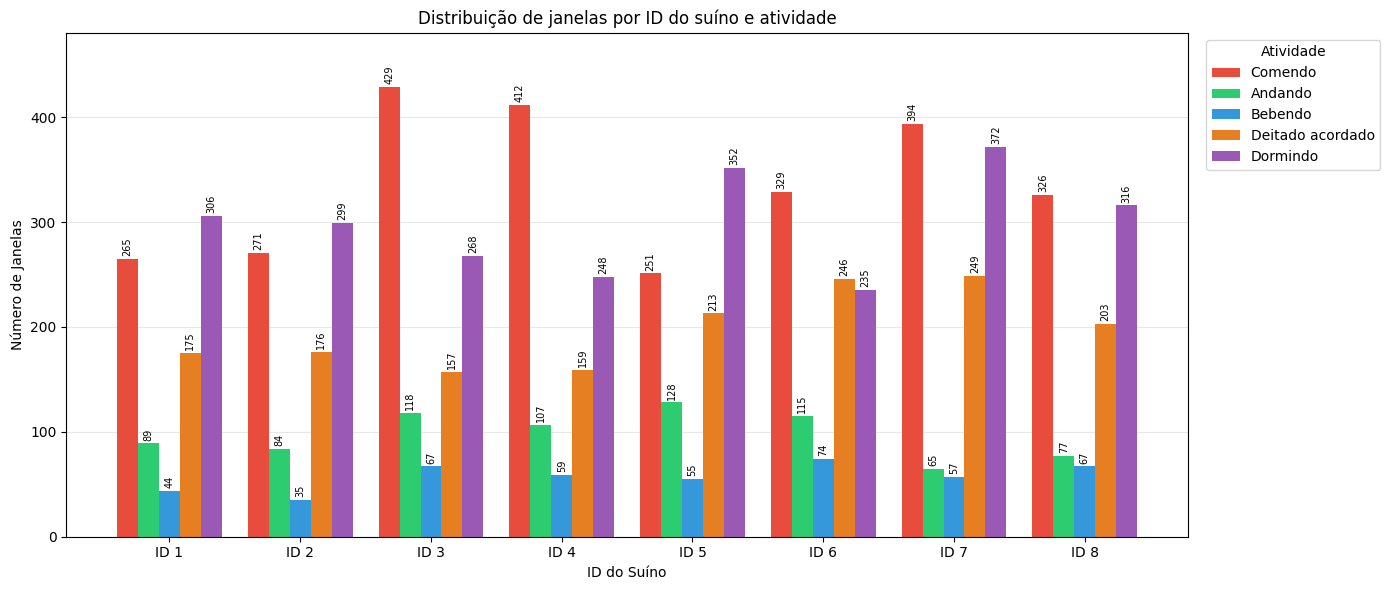

In [28]:
# =========================================================
# Distribuição de janelas por ID e atividade (barras agrupadas)
# =========================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = r"C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id"
CSV  = os.path.join(BASE, "dataset_treinamento_suinos.csv")

df = pd.read_csv(CSV)
if df.shape[1] == 1:
    df = pd.read_csv(CSV, sep=";", decimal=",")

df["atividade"] = df["atividade"].astype(str).str.lower().str.strip()

# --- uma linha por janela (rótulos originais, sem fundir deitado)
w = df.groupby("janela").agg(atividade=("atividade", "first"),
                             ID=("ID", "first")).reset_index()

ORDEM = ["comendo", "andando", "bebendo", "deitadoac", "dormindo"]
CORES = {"comendo": "#E74C3C", "andando": "#2ECC71", "bebendo": "#3498DB",
         "deitadoac": "#E67E22", "dormindo": "#9B59B6"}
ROTULO = {"comendo": "Comendo", "andando": "Andando", "bebendo": "Bebendo",
          "deitadoac": "Deitado acordado", "dormindo": "Dormindo"}

atividades = [a for a in ORDEM if a in w["atividade"].unique()]
outras = [a for a in w["atividade"].unique() if a not in ORDEM]
if outras:
    print(f"Fora do gráfico: {outras}")

tab = pd.crosstab(w["ID"], w["atividade"])[atividades]
print(tab)
print("\nTotal por atividade:")
print(tab.sum())

# ---------------------------------------------------------
# Gráfico
# ---------------------------------------------------------
ids   = tab.index.tolist()
x     = np.arange(len(ids))
n     = len(atividades)
larg  = 0.8 / n

fig, ax = plt.subplots(figsize=(14, 6))

for i, a in enumerate(atividades):
    pos = x - 0.4 + larg / 2 + i * larg
    barras = ax.bar(pos, tab[a].values, width=larg,
                    color=CORES.get(a, "#999999"), label=ROTULO.get(a, a))
    ax.bar_label(barras, fontsize=7, rotation=90, padding=2)

ax.set_xticks(x)
ax.set_xticklabels([f"ID {i}" for i in ids])
ax.set_xlabel("ID do Suíno")
ax.set_ylabel("Número de Janelas")
ax.set_title("Distribuição de janelas por ID do suíno e atividade")
ax.set_ylim(0, tab.values.max() * 1.12)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(title="Atividade", bbox_to_anchor=(1.01, 1), loc="upper left")

plt.tight_layout()
plt.savefig(os.path.join(BASE, "distribuicao_janelas_por_id.png"),
            dpi=300, bbox_inches="tight")
plt.show()

In [3]:
import sys
import subprocess

# Reproduz o erro usando o mesmo Python do notebook
teste = subprocess.run(
    [sys.executable, "-c", "import numpy; print(numpy.__version__)"],
    capture_output=True,
    text=True,
    errors="replace",
)

print("PYTHON:", sys.executable)
print("\nTESTE NUMPY:")
print(teste.stdout or teste.stderr)

# Consulta os eventos relacionados ao ambiente Python
comando = r"""
$eventos = Get-WinEvent -FilterHashtable @{
    LogName = 'Microsoft-Windows-CodeIntegrity/Operational'
    StartTime = (Get-Date).AddHours(-4)
} -ErrorAction SilentlyContinue |
Where-Object {
    $_.Message -match 'python|pig_ai|numpy|multiarray|openblas|mkl'
} |
Select-Object -First 15 TimeCreated, Id, Message

if ($eventos) {
    $eventos | Format-List | Out-String -Width 300
} else {
    'Nenhum evento relacionado ao Python encontrado nesse intervalo.'
}
"""

resultado = subprocess.run(
    ["powershell.exe", "-NoProfile", "-Command", comando],
    capture_output=True,
    text=True,
    errors="replace",
)

print("\nREGISTROS DO WINDOWS:")
print(resultado.stdout)
if resultado.stderr:
    print(resultado.stderr)

PYTHON: C:\Users\franc\.conda\envs\pig_ai\python.exe

TESTE NUMPY:
Traceback (most recent call last):
  File "C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\numpy\_core\__init__.py", line 24, in <module>
    from . import multiarray
  File "C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\numpy\_core\multiarray.py", line 11, in <module>
    from . import _multiarray_umath, overrides
ImportError: DLL load failed while importing _multiarray_umath: Uma política de Controle de Aplicativo bloqueou este arquivo.

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "<string>", line 1, in <module>
  File "C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\numpy\__init__.py", line 112, in <module>
    from numpy.__config__ import show_config
  File "C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\numpy\__config__.py", line 4, in <module>
    from numpy._core._multiarray_umath import (
  File "C:\Users\franc\.conda\envs\pig

**Window Distribution Across the Four Target Classes**

<small>Combines awake lying and sleeping into the lying class, plots the four behavioral classes by animal, and saves the stacked bar chart.</small>

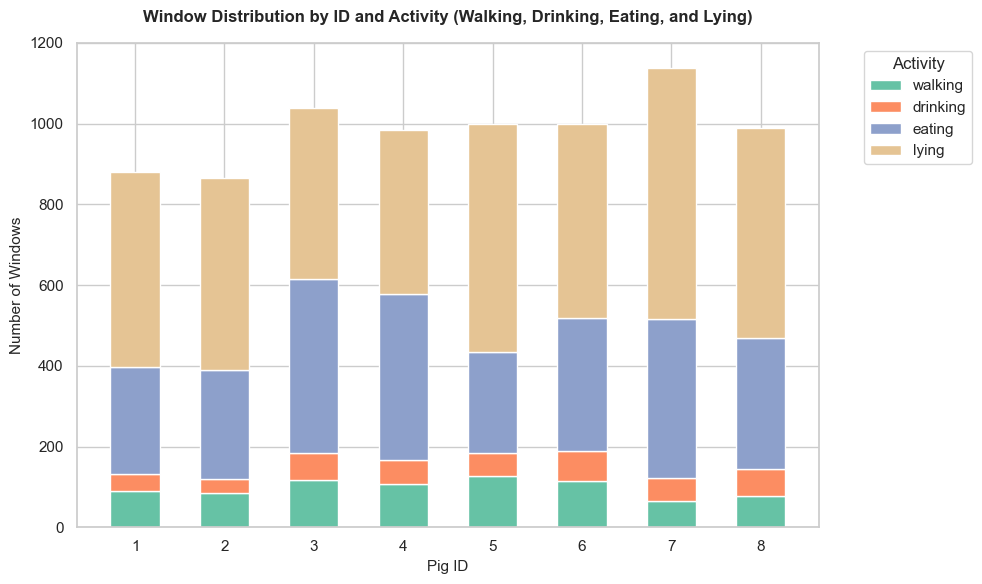

In [30]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Definir os caminhos do ficheiro
BASE = r"C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id"
CSV = os.path.join(BASE, "dataset_treinamento_suinos.csv")

# 2. Carregar o dataset
df = pd.read_csv(CSV)

# 3. Obter o número de janelas únicas por ID e Atividade
df_janelas = (
    df.groupby(["ID", "atividade"])["janela"].nunique().unstack(fill_value=0)
)

# 4. Agrupar 'deitadoac' e 'dormindo' na classe 'lying' e mapear para inglês
df_janelas_en = pd.DataFrame()
df_janelas_en["walking"] = df_janelas["andando"]
df_janelas_en["drinking"] = df_janelas["bebendo"]
df_janelas_en["eating"] = df_janelas["comendo"]
df_janelas_en["lying"] = df_janelas.get("deitadoac", 0) + df_janelas.get(
    "dormindo", 0
)

# Ordem de empilhamento das atividades
activities_order = ["walking", "drinking", "eating", "lying"]

# 5. Paleta de cores originais
colors = {
    "walking": "#66c2a5",  # Verde-água
    "drinking": "#fc8d62",  # Laranja
    "eating": "#8da0cb",  # Azul-acinzentado
    "lying": "#e5c494",  # Bege / Laranja claro
}

# 6. Configuração e geração do gráfico
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

bottom = pd.Series(0, index=df_janelas_en.index)

for activity in activities_order:
    values = df_janelas_en[activity]
    ax.bar(
        df_janelas_en.index,
        values,
        bottom=bottom,
        label=activity,
        color=colors[activity],
        width=0.55,
    )
    bottom += values

# 7. Títulos, rótulos e formatação em inglês
ax.set_title(
    "Window Distribution by ID and Activity (Walking, Drinking, Eating, and"
    " Lying)",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Pig ID", fontsize=11)
ax.set_ylabel("Number of Windows", fontsize=11)
ax.set_xticks(df_janelas_en.index)
ax.set_ylim(0, 1200)

ax.legend(
    title="Activity", bbox_to_anchor=(1.05, 1), loc="upper left", frameon=True
)

plt.tight_layout()

# 8. Guardar a imagem diretamente na pasta BASE
output_path = os.path.join(BASE, "grafico_4_atividades_ingles.png")
plt.savefig(output_path, dpi=300)
plt.show()

**Accelerometer Data Preparation and Feature Extraction**

<small>Harmonizes behavior labels, checks window consistency, and extracts accelerometer features from original windows and circularly shifted versions for subsequent animal-wise training.</small>

In [1]:
# =========================================================
# MDRF-CS — ETAPA 1: preparação do experimento de acelerometria
# Split por animal (ID). Sem treino nesta célula.
# =========================================================
import os
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks

BASE = r"C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id"
CSV = os.path.join(BASE, "dataset_treinamento_suinos.csv")

CLASSES = ["deitado", "andando", "bebendo", "comendo"]
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
FUNDIR = {"dormindo": "deitado", "deitadoac": "deitado", "inativo": "deitado"}
CLASSES_AUG = ["andando", "bebendo"]
SHIFTS = [1, 2, 3]

# ---------------------------------------------------------
# 1. Carga e normalização de rótulos
# ---------------------------------------------------------
df = pd.read_csv(CSV)
if df.shape[1] == 1:
    df = pd.read_csv(CSV, sep=";", decimal=",")

df["atividade"] = (
    df["atividade"]
    .astype(str)
    .str.lower()
    .str.strip()
    .replace(FUNDIR)
)

antes = df.groupby("janela")["atividade"].first().value_counts()
print("=== Classes antes do filtro (por janela) ===")
print(antes)

fora = [c for c in antes.index if c not in CLASSES]
if fora:
    print(f"\nDescartadas: {fora}  ({antes[fora].sum()} janelas)")

df = df[df["atividade"].isin(CLASSES)].copy()
df["janela"] = df["janela"].astype(int)

# ---------------------------------------------------------
# 2. Consistência
# ---------------------------------------------------------
w = (
    df.groupby("janela")
    .agg(
        atividade=("atividade", "first"),
        ID=("ID", "first"),
        n_amostras=("AX", "size"),
        n_ids=("ID", "nunique"),
    )
    .reset_index()
)

print(f"\nJanelas: {len(w)}   (artigo: 7892)")
print(f"Animais: {w['ID'].nunique()}   IDs: {sorted(w['ID'].unique())}")
print(f"Amostras/janela — min {w.n_amostras.min()} | max {w.n_amostras.max()}")

if (w.n_ids > 1).any():
    print(f"ATENÇÃO: {(w.n_ids > 1).sum()} janelas com mais de um ID.")

if (w.n_amostras < 8).any():
    print(
        f"ATENÇÃO: {(w.n_amostras < 8).sum()} "
        "janelas curtas demais para o circular shift."
    )

print("\n=== Janelas por classe ===")
print(w["atividade"].value_counts())

tab = pd.crosstab(w["ID"], w["atividade"])[CLASSES]
print("\n=== Janelas por animal x classe ===")
print(tab)
print("\nTotal por animal:")
print(tab.sum(axis=1))

vazias = [
    (i, c)
    for i in tab.index
    for c in CLASSES
    if tab.loc[i, c] == 0
]

if vazias:
    print("\nATENÇÃO — F1 indefinido no fold destes animais:")
    for i, c in vazias:
        print(f"  ID {i}: sem janelas de {c}")
else:
    print("\nTodos os animais têm janelas de todas as classes.")

# ---------------------------------------------------------
# 3. Extração de features — 46 atributos
# ---------------------------------------------------------
def extrair_features(g):
    ax = g["AX"].values.astype(float)
    ay = g["AY"].values.astype(float)
    az = g["AZ"].values.astype(float)

    vm = np.sqrt(ax**2 + ay**2 + az**2)
    n = len(vm)

    if n == 0:
        return pd.Series(dtype=float)

    peaks, _ = find_peaks(vm, height=np.mean(vm))
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals)
    N_fft = len(fft_vals)

    diff_vm = np.diff(vm) if n > 1 else np.array([0.0])
    hist, _ = np.histogram(vm, bins=10, density=True)
    hist = hist + 1e-6

    f = {
        "mean": np.mean(vm),
        "std": np.std(vm),
        "min": np.min(vm),
        "max": np.max(vm),
        "max_min_diff": np.max(vm) - np.min(vm),
        "median": np.median(vm),
        "peak_count": len(peaks),
        "skewness": skew(vm) if n > 2 else 0,
        "kurtosis": kurtosis(vm) if n > 3 else 0,
        "sma": np.sum(np.abs(vm)) / n,

        "AV": np.mean(fft_vals),
        "SD_f": np.std(fft_vals),
        "MAX_f": np.max(fft_vals),
        "RG_f": np.max(fft_vals) - np.mean(fft_vals),
        "FQ": sorted_f[int(N_fft / 4)] if N_fft > 4 else 0,
        "SQ": sorted_f[int(N_fft / 2)] if N_fft > 2 else 0,
        "RMS_f": np.sqrt(np.mean(fft_vals**2)),
        "Median_f": np.median(fft_vals),

        "max_corr_xy": np.max(np.correlate(ax, ay, mode="full")),
        "max_corr_xz": np.max(np.correlate(ax, az, mode="full")),
        "max_corr_yz": np.max(np.correlate(ay, az, mode="full")),

        "rms_diff": np.sqrt(np.mean(diff_vm**2)),
        "tempo_pico": np.argmax(vm) / n,
        "entropy": -np.sum(hist * np.log(hist)),
        "zero_crossings": np.sum(np.diff(np.sign(diff_vm)) != 0),
    }

    for nome, v in [("AX", ax), ("AY", ay), ("AZ", az)]:
        f[f"j_mean_{nome}"] = np.mean(v)
        f[f"j_std_{nome}"] = np.std(v)
        f[f"j_min_{nome}"] = np.min(v)
        f[f"j_max_{nome}"] = np.max(v)
        f[f"j_range_{nome}"] = np.max(v) - np.min(v)
        f[f"j_mean_abs_{nome}"] = np.mean(np.abs(v))
        f[f"j_rms_{nome}"] = np.sqrt(np.mean(v**2))

    return pd.Series(f)


def circular_shift(g, k):
    """[A,B,C,D] -> rotação de k partes."""
    g = g.reset_index(drop=True)
    n = len(g)

    if n < 8:
        return None

    c1, c2, c3 = n // 4, n // 2, (3 * n) // 4
    partes = [
        g.iloc[:c1],
        g.iloc[c1:c2],
        g.iloc[c2:c3],
        g.iloc[c3:],
    ]

    return pd.concat(partes[k:] + partes[:k], ignore_index=True)


print("\nExtraindo features das janelas originais...")

feat = df.groupby("janela").apply(extrair_features).reset_index()
feat = feat.merge(w[["janela", "atividade", "ID"]], on="janela")
feat = feat.replace([np.inf, -np.inf], np.nan).dropna()

feat["label"] = feat["atividade"].map(CLS2IDX).astype(int)
feat["janela_origem"] = feat["janela"]
feat["shift"] = 0

FEATURE_COLS = [
    c for c in feat.columns
    if c not in [
        "janela", "janela_origem", "shift",
        "ID", "atividade", "label",
    ]
]

print(f"Features: {len(FEATURE_COLS)}   (esperado: 46)")

# --- cópias aumentadas: determinísticas, extraídas uma vez só
print("Extraindo features das cópias aumentadas...")

jan_aug = w.loc[
    w["atividade"].isin(CLASSES_AUG), "janela"
].tolist()

linhas = []

for j in jan_aug:
    g = df[df["janela"] == j]

    for k in SHIFTS:
        gs = circular_shift(g, k)
        if gs is None:
            continue

        s = extrair_features(gs)
        s["janela"] = f"{j}_cs{k}"
        s["janela_origem"] = j
        s["shift"] = k
        linhas.append(s)

feat_aug = pd.DataFrame(linhas)
feat_aug = feat_aug.merge(
    w[["janela", "atividade", "ID"]].rename(
        columns={"janela": "janela_origem"}
    ),
    on="janela_origem",
)
feat_aug = feat_aug.replace([np.inf, -np.inf], np.nan).dropna()
feat_aug["label"] = feat_aug["atividade"].map(CLS2IDX).astype(int)

print(
    f"Cópias aumentadas: {len(feat_aug)}   "
    f"(esperado: {len(jan_aug) * len(SHIFTS)})"
)
print(feat_aug["atividade"].value_counts())

# ---------------------------------------------------------
# 4. Saída
# ---------------------------------------------------------
COLS = [
    "janela", "janela_origem", "shift",
    "ID", "atividade", "label",
] + FEATURE_COLS

feat[COLS].to_csv(
    os.path.join(BASE, "features_originais.csv"),
    index=False,
)
feat_aug[COLS].to_csv(
    os.path.join(BASE, "features_aumentadas.csv"),
    index=False,
)

print(f"\nSalvos em {BASE}:")
print(
    f"  features_originais.csv   "
    f"{len(feat)} linhas x {len(FEATURE_COLS)} features"
)
print(
    f"  features_aumentadas.csv  "
    f"{len(feat_aug)} linhas x {len(FEATURE_COLS)} features"
)

=== Classes antes do filtro (por janela) ===
atividade
deitado    3974
comendo    2677
andando     783
bebendo     458
Name: count, dtype: int64

Janelas: 7892   (artigo: 7892)
Animais: 8   IDs: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Amostras/janela — min 100 | max 100

=== Janelas por classe ===
atividade
deitado    3974
comendo    2677
andando     783
bebendo     458
Name: count, dtype: int64

=== Janelas por animal x classe ===
atividade  deitado  andando  bebendo  comendo
ID                                           
1              481       89       44      265
2              475       84       35      271
3              425      118       67      429
4              407      107       59      412
5              565      128       55      251
6              481      115       74      329
7              621       65       57      394
8              519       77       67      326

Total por animal:
ID
1     879
2     8

**MDRF-CS Evaluation with Leave-One-Animal-Out Validation**

<small>Trains a 500-tree Random Forest on seven animals and evaluates the held-out animal. Augmented windows are restricted to the training animals; predictions, metrics, and feature importances are saved.</small>

Originais: 7892 | Aumentadas: 3723 | Features: 47
Fold 1 | ID 1 | n= 879 | acc=0.9078 | macroF1=0.8029 | F1 beb=0.592
Fold 2 | ID 2 | n= 865 | acc=0.9306 | macroF1=0.8502 | F1 beb=0.676
Fold 3 | ID 3 | n=1039 | acc=0.9095 | macroF1=0.8471 | F1 beb=0.704
Fold 4 | ID 4 | n= 985 | acc=0.9096 | macroF1=0.8375 | F1 beb=0.652
Fold 5 | ID 5 | n= 999 | acc=0.9299 | macroF1=0.8710 | F1 beb=0.733
Fold 6 | ID 6 | n= 999 | acc=0.9169 | macroF1=0.8605 | F1 beb=0.736
Fold 7 | ID 7 | n=1137 | acc=0.9305 | macroF1=0.8275 | F1 beb=0.710
Fold 8 | ID 8 | n= 989 | acc=0.9252 | macroF1=0.8567 | F1 beb=0.767

=== POOLED (todas as janelas, cada uma predita sem seu animal no treino) ===
              precision    recall  f1-score   support

       Lying     0.9824    0.9524    0.9672      3974
     Walking     0.7443    0.8365    0.7877       783
    Drinking     0.6590    0.7511    0.7020       458
      Eating     0.9397    0.9257    0.9326      2677

    accuracy                         0.9202      7892
  

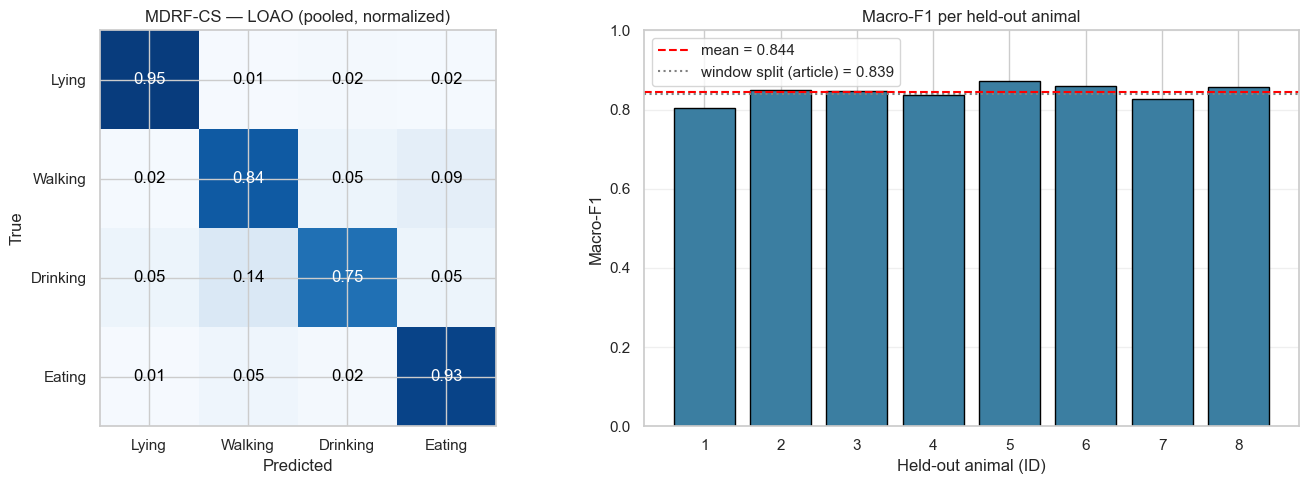


Top-10 features (importância média entre folds):
j_mean_AX      0.0754
j_min_AX       0.0513
entropy        0.0500
max_corr_xz    0.0468
j_max_AX       0.0436
rms_diff       0.0389
std_fim        0.0334
SD_f           0.0329
std            0.0322
SQ             0.0319
dtype: float64

Salvos em C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id


In [32]:
# =========================================================
# MDRF-CS — ETAPA 2: Leave-One-Animal-Out (8 folds)
# =========================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score)

BASE    = r"C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id"
CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES   = ["Lying", "Walking", "Drinking", "Eating"]
LABELS  = [0, 1, 2, 3]

orig = pd.read_csv(os.path.join(BASE, "features_originais.csv"))
aug  = pd.read_csv(os.path.join(BASE, "features_aumentadas.csv"))

META = ["janela", "janela_origem", "shift", "ID", "atividade", "label"]
FEAT = [c for c in orig.columns if c not in META]
print(f"Originais: {len(orig)} | Aumentadas: {len(aug)} | Features: {len(FEAT)}")

# ---------------------------------------------------------
# Laço LOAO
# ---------------------------------------------------------
logo = LeaveOneGroupOut()
probs_all = np.zeros((len(orig), len(CLASSES)))
importancias, metricas = [], []

for fold, (tr, te) in enumerate(logo.split(orig, orig["label"], groups=orig["ID"]), 1):
    id_teste   = orig.iloc[te]["ID"].iloc[0]
    ids_treino = set(orig.iloc[tr]["ID"])

    # treino = originais dos 7 animais + aumentadas deles
    aug_tr = aug[aug["ID"].isin(ids_treino)]
    Xtr = pd.concat([orig.iloc[tr][FEAT], aug_tr[FEAT]]).values
    ytr = np.concatenate([orig.iloc[tr]["label"].values, aug_tr["label"].values])

    # teste = originais do animal de fora, sem aumentação
    Xte = orig.iloc[te][FEAT].values
    yte = orig.iloc[te]["label"].values

    rf = RandomForestClassifier(
        n_estimators=500, max_depth=18, min_samples_split=4,
        min_samples_leaf=2, class_weight="balanced",
        random_state=42 + fold, n_jobs=-1)
    rf.fit(Xtr, ytr)

    p = np.zeros((len(Xte), len(CLASSES)))
    p[:, rf.classes_] = rf.predict_proba(Xte)
    probs_all[te] = p
    yhat = p.argmax(1)

    f1c = f1_score(yte, yhat, labels=LABELS, average=None, zero_division=0)
    sup = np.bincount(yte, minlength=4)
    metricas.append({
        "fold": fold, "ID_teste": id_teste, "n_teste": len(te),
        "accuracy": accuracy_score(yte, yhat),
        "macro_f1": f1_score(yte, yhat, labels=LABELS, average="macro", zero_division=0),
        "weighted_f1": f1_score(yte, yhat, labels=LABELS, average="weighted", zero_division=0),
        **{f"f1_{c}": f1c[i] for i, c in enumerate(CLASSES)},
        **{f"n_{c}": sup[i] for i, c in enumerate(CLASSES)},
    })
    importancias.append(rf.feature_importances_)

    print(f"Fold {fold} | ID {id_teste} | n={len(te):>4} | "
          f"acc={metricas[-1]['accuracy']:.4f} | macroF1={metricas[-1]['macro_f1']:.4f} | "
          f"F1 beb={f1c[2]:.3f}")

# ---------------------------------------------------------
# Resultados
# ---------------------------------------------------------
m = pd.DataFrame(metricas)
y_true = orig["label"].values
y_pred = probs_all.argmax(1)

print("\n=== POOLED (todas as janelas, cada uma predita sem seu animal no treino) ===")
print(classification_report(y_true, y_pred, labels=LABELS,
                            target_names=NOMES, digits=4, zero_division=0))

print("=== POR ANIMAL ===")
print(m[["ID_teste", "n_teste", "accuracy", "macro_f1", "weighted_f1"]
        + [f"f1_{c}" for c in CLASSES]].round(4).to_string(index=False))

print("\n=== MÉDIA ± DP ENTRE ANIMAIS ===")
for col in ["accuracy", "macro_f1", "weighted_f1"] + [f"f1_{c}" for c in CLASSES]:
    print(f"  {col:<12} {m[col].mean():.4f} ± {m[col].std():.4f}   "
          f"[min {m[col].min():.4f} | max {m[col].max():.4f}]")

# ---------------------------------------------------------
# Figuras
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_true, y_pred, labels=LABELS, normalize="true")
axes[0].imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        axes[0].text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                     color="white" if cm[i, j] > 0.5 else "black")
axes[0].set_xticks(range(4)); axes[0].set_xticklabels(NOMES)
axes[0].set_yticks(range(4)); axes[0].set_yticklabels(NOMES)
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")
axes[0].set_title("MDRF-CS — LOAO (pooled, normalized)")

axes[1].bar(m["ID_teste"].astype(str), m["macro_f1"], color="#3B7EA1", edgecolor="black")
axes[1].axhline(m["macro_f1"].mean(), color="red", ls="--",
                label=f"mean = {m['macro_f1'].mean():.3f}")
axes[1].axhline(0.8386, color="gray", ls=":", label="window split (article) = 0.839")
axes[1].set_xlabel("Held-out animal (ID)"); axes[1].set_ylabel("Macro-F1")
axes[1].set_ylim(0, 1); axes[1].legend(); axes[1].grid(axis="y", alpha=0.3)
axes[1].set_title("Macro-F1 per held-out animal")

plt.tight_layout()
plt.savefig(os.path.join(BASE, "mdrfcs_loao_resultados.png"), dpi=300, bbox_inches="tight")
plt.show()

# importância média entre folds
imp = pd.Series(np.mean(importancias, axis=0), index=FEAT).sort_values(ascending=False)
print("\nTop-10 features (importância média entre folds):")
print(imp.head(10).round(4))

# ---------------------------------------------------------
# Saída
# ---------------------------------------------------------
out = orig[["janela", "ID", "atividade", "label"]].copy()
for i, c in enumerate(CLASSES):
    out[f"prob_{c}"] = probs_all[:, i]
out["pred"] = y_pred

out.to_csv(os.path.join(BASE, "mdrfcs_loao_probs.csv"), index=False)
m.to_csv(os.path.join(BASE, "mdrfcs_loao_metricas_por_animal.csv"), index=False)
imp.to_csv(os.path.join(BASE, "mdrfcs_loao_importancia.csv"), header=["importance"])
print(f"\nSalvos em {BASE}")

Originais: 7892 | Aumentadas: 3723 | Features: 46
Fold 1 | ID 1 | n= 879 | acc=0.9101 | macroF1=0.8052 | F1 beb=0.586
Fold 2 | ID 2 | n= 865 | acc=0.9283 | macroF1=0.8500 | F1 beb=0.676
Fold 3 | ID 3 | n=1039 | acc=0.9076 | macroF1=0.8430 | F1 beb=0.695
Fold 4 | ID 4 | n= 985 | acc=0.9025 | macroF1=0.8299 | F1 beb=0.647
Fold 5 | ID 5 | n= 999 | acc=0.9269 | macroF1=0.8663 | F1 beb=0.727
Fold 6 | ID 6 | n= 999 | acc=0.9179 | macroF1=0.8632 | F1 beb=0.753
Fold 7 | ID 7 | n=1137 | acc=0.9288 | macroF1=0.8227 | F1 beb=0.704
Fold 8 | ID 8 | n= 989 | acc=0.9282 | macroF1=0.8631 | F1 beb=0.778

=== POOLED (todas as janelas, cada uma predita sem seu animal no treino) ===
              precision    recall  f1-score   support

       Lying     0.9823    0.9517    0.9668      3974
     Walking     0.7432    0.8314    0.7848       783
    Drinking     0.6553    0.7555    0.7018       458
      Eating     0.9375    0.9238    0.9306      2677

    accuracy                         0.9189      7892
  

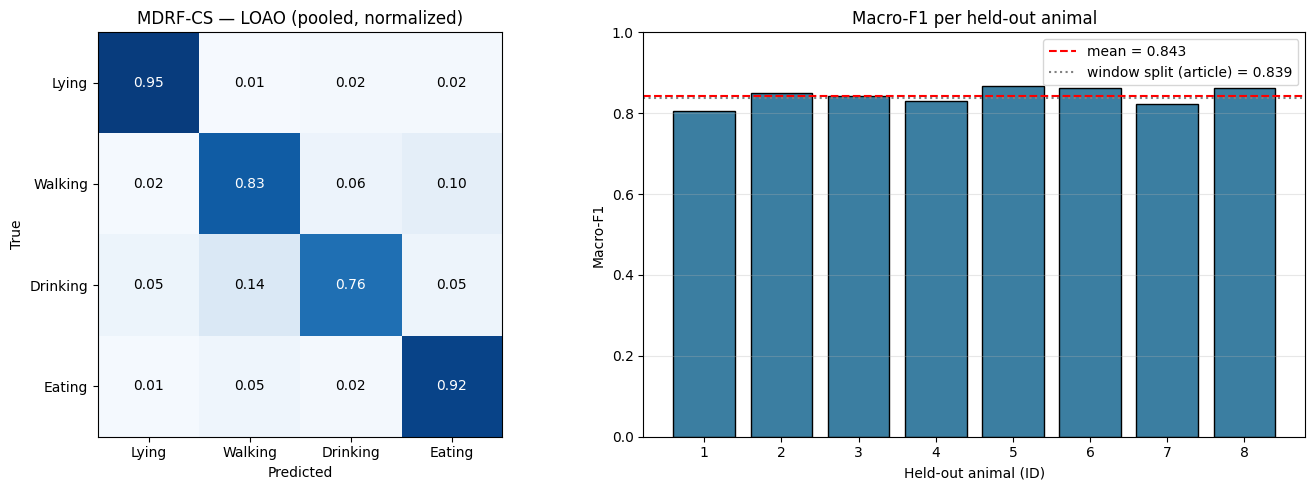


Top-10 features (importância média entre folds):
j_mean_AX      0.0750
j_min_AX       0.0525
entropy        0.0505
j_max_AX       0.0457
max_corr_xz    0.0457
rms_diff       0.0413
SD_f           0.0362
Median_f       0.0360
std            0.0336
SQ             0.0329
dtype: float64

Salvos em C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id


In [1]:
# =========================================================
# MDRF-CS — ETAPA 2: Leave-One-Animal-Out (8 folds)
# =========================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score)

BASE    = r"C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id"
CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES   = ["Lying", "Walking", "Drinking", "Eating"]
LABELS  = [0, 1, 2, 3]

orig = pd.read_csv(os.path.join(BASE, "features_originais.csv"))
aug  = pd.read_csv(os.path.join(BASE, "features_aumentadas.csv"))

META = ["janela", "janela_origem", "shift", "ID", "atividade", "label"]
FEAT = [c for c in orig.columns if c not in META]
print(f"Originais: {len(orig)} | Aumentadas: {len(aug)} | Features: {len(FEAT)}")

# ---------------------------------------------------------
# Laço LOAO
# ---------------------------------------------------------
logo = LeaveOneGroupOut()
probs_all = np.zeros((len(orig), len(CLASSES)))
importancias, metricas = [], []

for fold, (tr, te) in enumerate(logo.split(orig, orig["label"], groups=orig["ID"]), 1):
    id_teste   = orig.iloc[te]["ID"].iloc[0]
    ids_treino = set(orig.iloc[tr]["ID"])

    # treino = originais dos 7 animais + aumentadas deles
    aug_tr = aug[aug["ID"].isin(ids_treino)]
    Xtr = pd.concat([orig.iloc[tr][FEAT], aug_tr[FEAT]]).values
    ytr = np.concatenate([orig.iloc[tr]["label"].values, aug_tr["label"].values])

    # teste = originais do animal de fora, sem aumentação
    Xte = orig.iloc[te][FEAT].values
    yte = orig.iloc[te]["label"].values

    rf = RandomForestClassifier(
        n_estimators=500, max_depth=18, min_samples_split=4,
        min_samples_leaf=2, class_weight="balanced",
        random_state=42 + fold, n_jobs=-1)
    rf.fit(Xtr, ytr)

    p = np.zeros((len(Xte), len(CLASSES)))
    p[:, rf.classes_] = rf.predict_proba(Xte)
    probs_all[te] = p
    yhat = p.argmax(1)

    f1c = f1_score(yte, yhat, labels=LABELS, average=None, zero_division=0)
    sup = np.bincount(yte, minlength=4)
    metricas.append({
        "fold": fold, "ID_teste": id_teste, "n_teste": len(te),
        "accuracy": accuracy_score(yte, yhat),
        "macro_f1": f1_score(yte, yhat, labels=LABELS, average="macro", zero_division=0),
        "weighted_f1": f1_score(yte, yhat, labels=LABELS, average="weighted", zero_division=0),
        **{f"f1_{c}": f1c[i] for i, c in enumerate(CLASSES)},
        **{f"n_{c}": sup[i] for i, c in enumerate(CLASSES)},
    })
    importancias.append(rf.feature_importances_)

    print(f"Fold {fold} | ID {id_teste} | n={len(te):>4} | "
          f"acc={metricas[-1]['accuracy']:.4f} | macroF1={metricas[-1]['macro_f1']:.4f} | "
          f"F1 beb={f1c[2]:.3f}")

# ---------------------------------------------------------
# Resultados
# ---------------------------------------------------------
m = pd.DataFrame(metricas)
y_true = orig["label"].values
y_pred = probs_all.argmax(1)

print("\n=== POOLED (todas as janelas, cada uma predita sem seu animal no treino) ===")
print(classification_report(y_true, y_pred, labels=LABELS,
                            target_names=NOMES, digits=4, zero_division=0))

print("=== POR ANIMAL ===")
print(m[["ID_teste", "n_teste", "accuracy", "macro_f1", "weighted_f1"]
        + [f"f1_{c}" for c in CLASSES]].round(4).to_string(index=False))

print("\n=== MÉDIA ± DP ENTRE ANIMAIS ===")
for col in ["accuracy", "macro_f1", "weighted_f1"] + [f"f1_{c}" for c in CLASSES]:
    print(f"  {col:<12} {m[col].mean():.4f} ± {m[col].std():.4f}   "
          f"[min {m[col].min():.4f} | max {m[col].max():.4f}]")

# ---------------------------------------------------------
# Figuras
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_true, y_pred, labels=LABELS, normalize="true")
axes[0].imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        axes[0].text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                     color="white" if cm[i, j] > 0.5 else "black")
axes[0].set_xticks(range(4)); axes[0].set_xticklabels(NOMES)
axes[0].set_yticks(range(4)); axes[0].set_yticklabels(NOMES)
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")
axes[0].set_title("MDRF-CS — LOAO (pooled, normalized)")

axes[1].bar(m["ID_teste"].astype(str), m["macro_f1"], color="#3B7EA1", edgecolor="black")
axes[1].axhline(m["macro_f1"].mean(), color="red", ls="--",
                label=f"mean = {m['macro_f1'].mean():.3f}")
axes[1].axhline(0.8386, color="gray", ls=":", label="window split (article) = 0.839")
axes[1].set_xlabel("Held-out animal (ID)"); axes[1].set_ylabel("Macro-F1")
axes[1].set_ylim(0, 1); axes[1].legend(); axes[1].grid(axis="y", alpha=0.3)
axes[1].set_title("Macro-F1 per held-out animal")

plt.tight_layout()
plt.savefig(os.path.join(BASE, "mdrfcs_loao_resultados.png"), dpi=300, bbox_inches="tight")
plt.show()

# importância média entre folds
imp = pd.Series(np.mean(importancias, axis=0), index=FEAT).sort_values(ascending=False)
print("\nTop-10 features (importância média entre folds):")
print(imp.head(10).round(4))

# ---------------------------------------------------------
# Saída
# ---------------------------------------------------------
out = orig[["janela", "ID", "atividade", "label"]].copy()
for i, c in enumerate(CLASSES):
    out[f"prob_{c}"] = probs_all[:, i]
out["pred"] = y_pred

out.to_csv(os.path.join(BASE, "mdrfcs_loao_probs.csv"), index=False)
m.to_csv(os.path.join(BASE, "mdrfcs_loao_metricas_por_animal.csv"), index=False)
imp.to_csv(os.path.join(BASE, "mdrfcs_loao_importancia.csv"), header=["importance"])
print(f"\nSalvos em {BASE}")

In [2]:
# ============================================================
# MDRF-CS | LOAO | custo computacional ponta a ponta
# ============================================================
import os, time, pickle, platform
import numpy as np, pandas as pd
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from sklearn.ensemble import RandomForestClassifier


BASE  = r"C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id"
CSV   = r"C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.csv"
F_ORI = os.path.join(BASE, "features_originais.csv")
F_AUG = os.path.join(BASE, "features_aumentadas.csv")

N_REP = 200
rng   = np.random.default_rng(42)

RF_KW = dict(n_estimators=500, max_depth=18, min_samples_split=4,
             min_samples_leaf=2, max_features="sqrt",
             class_weight="balanced", bootstrap=True)

def extrair_features(g):
    ax = g["AX"].values.astype(float); ay = g["AY"].values.astype(float)
    az = g["AZ"].values.astype(float); vm = np.sqrt(ax**2 + ay**2 + az**2)
    n = len(vm)
    if n == 0: return pd.Series(dtype=float)
    peaks, _ = find_peaks(vm, height=np.mean(vm))
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals); N_fft = len(fft_vals)
    p3 = vm[70:] if n >= 100 else vm[int(0.7*n):]
    diff_vm = np.diff(vm) if n > 1 else np.array([0.0])
    hist, _ = np.histogram(vm, bins=10, density=True); hist = hist + 1e-6
    f = {"mean":np.mean(vm),"std":np.std(vm),"min":np.min(vm),"max":np.max(vm),
         "max_min_diff":np.max(vm)-np.min(vm),"median":np.median(vm),
         "peak_count":len(peaks),"skewness":skew(vm) if n>2 else 0,
         "kurtosis":kurtosis(vm) if n>3 else 0,"sma":np.sum(np.abs(vm))/n,
         "AV":np.mean(fft_vals),"SD_f":np.std(fft_vals),"MAX_f":np.max(fft_vals),
         "RG_f":np.max(fft_vals)-np.mean(fft_vals),
         "FQ":sorted_f[int(N_fft/4)] if N_fft>4 else 0,
         "SQ":sorted_f[int(N_fft/2)] if N_fft>2 else 0,
         "RMS_f":np.sqrt(np.mean(fft_vals**2)),"Median_f":np.median(fft_vals),
         "max_corr_xy":np.max(np.correlate(ax,ay,mode="full")),
         "max_corr_xz":np.max(np.correlate(ax,az,mode="full")),
         "max_corr_yz":np.max(np.correlate(ay,az,mode="full")),
         "std_fim":np.std(p3) if len(p3) else 0,
         "rms_diff":np.sqrt(np.mean(diff_vm**2)),"tempo_pico":np.argmax(vm)/n,
         "entropy":-np.sum(hist*np.log(hist)),
         "zero_crossings":np.sum(np.diff(np.sign(diff_vm))!=0)}
    for nome, v in [("AX",ax),("AY",ay),("AZ",az)]:
        f[f"j_mean_{nome}"]=np.mean(v);   f[f"j_std_{nome}"]=np.std(v)
        f[f"j_min_{nome}"]=np.min(v);     f[f"j_max_{nome}"]=np.max(v)
        f[f"j_range_{nome}"]=np.max(v)-np.min(v)
        f[f"j_mean_abs_{nome}"]=np.mean(np.abs(v))
        f[f"j_rms_{nome}"]=np.sqrt(np.mean(v**2))
    return pd.Series(f)

ori = pd.read_csv(F_ORI); aug = pd.read_csv(F_AUG)
FEATS = [c for c in ori.columns
         if c not in ["janela","janela_origem","shift","ID","atividade","label"]]
print(f"{len(ori)} janelas | {len(FEATS)} atributos")

# ---------- 1. extração a partir do sinal bruto ----------
raw = pd.read_csv(CSV)
if raw.shape[1] == 1:
    raw = pd.read_csv(CSV, sep=";", decimal=",")
grupos = [g for _, g in raw.groupby("janela")][:N_REP]
extrair_features(grupos[0])
t_ext = np.array([(lambda t0: (extrair_features(g), (time.perf_counter()-t0)*1e3)[1])
                  (time.perf_counter()) for g in grupos])
print(f"\nextração   {np.median(t_ext):.3f} ms/janela"
      f"  (IQR {np.percentile(t_ext,25):.3f}-{np.percentile(t_ext,75):.3f})")

# ---------- 2. inferência por fold ----------
linhas = []
for i, a in enumerate(np.sort(ori["ID"].unique())):
    tr_o = ori[ori.ID != a]; tr_a = aug[aug.ID != a]
    Xtr = pd.concat([tr_o[FEATS], tr_a[FEATS]]).to_numpy(float)
    ytr = np.concatenate([tr_o.label.values, tr_a.label.values])
    Xte = ori.loc[ori.ID == a, FEATS].to_numpy(float)

    rf  = RandomForestClassifier(random_state=i, n_jobs=-1, **RF_KW).fit(Xtr, ytr)
    nos = int(sum(t.tree_.node_count for t in rf.estimators_))
    mb  = len(pickle.dumps(rf)) / 1024**2

    rf.n_jobs = 1
    rf.predict(Xte[:16])
    t = []
    for _ in range(N_REP):
        k = rng.integers(len(Xte))
        t0 = time.perf_counter(); rf.predict(Xte[k:k+1])
        t.append((time.perf_counter()-t0)*1e3)
    linhas.append(dict(animal=a, ms_pred=np.median(t), nos=nos, mb=mb))
    print(f"  animal {a}: {np.median(t):6.3f} ms | {nos:,} nós | {mb:.1f} MB")

r   = pd.DataFrame(linhas)
tot = np.median(t_ext) + r.ms_pred.mean()
print("\n===== MDRF-CS — custo computacional =====")
print(f"extração              {np.median(t_ext):7.3f} ms/janela")
print(f"inferência (1 núcleo) {r.ms_pred.mean():7.3f} ± {r.ms_pred.std(ddof=1):.3f} ms/janela")
print(f"total                 {tot:7.3f} ms/janela   ({5000/tot:,.0f}x tempo real)")
print(f"nós                   {r.nos.mean():,.0f} ± {r.nos.std(ddof=1):,.0f}")
print(f"tamanho               {r.mb.mean():.2f} ± {r.mb.std(ddof=1):.2f} MB")
print("\nCPU:", platform.processor() or platform.machine(), "|", os.cpu_count(), "núcleos lógicos")
r.to_csv(os.path.join(BASE, "mdrfcs_custo_computacional.csv"), index=False)

7892 janelas | 47 atributos

extração   2.628 ms/janela  (IQR 2.539-2.930)
  animal 1: 49.915 ms | 493,716 nós | 45.4 MB
  animal 2: 49.128 ms | 506,280 nós | 46.5 MB
  animal 3: 52.018 ms | 484,532 nós | 44.5 MB
  animal 4: 65.720 ms | 483,160 nós | 44.4 MB
  animal 5: 74.728 ms | 490,098 nós | 45.0 MB
  animal 6: 70.788 ms | 490,944 nós | 45.1 MB
  animal 7: 56.201 ms | 500,850 nós | 46.0 MB
  animal 8: 66.631 ms | 491,334 nós | 45.1 MB

===== MDRF-CS — custo computacional =====
extração                2.628 ms/janela
inferência (1 núcleo)  60.641 ± 10.034 ms/janela
total                  63.269 ms/janela   (79x tempo real)
nós                   492,614 ± 7,758
tamanho               45.26 ± 0.71 MB

CPU: Intel64 Family 6 Model 151 Stepping 2, GenuineIntel | 20 núcleos lógicos


# Performance Analysis and baselines

# AD-BL-SMOTE and MLP Reference Baseline

<small>Extracts 21 axis-based features and evaluates an AD-BL-SMOTE plus MLP baseline under LOAO. Compares its predictions and per-animal Macro-F1 with MDRF-CS.</small>

In [45]:
# =========================================================
# BASELINE JIN et al. (2023) — Leave-One-Animal-Out (8 folds)
# 21 features por janela (7 estatísticas × 3 eixos)
# AD-BL-SMOTE + MLP (28, 28) ReLU / SGD, 120 épocas
# Mesmo protocolo do MDRF-CS Etapa 2, para comparação direta
# =========================================================
import os
import numpy as np
import pandas as pd
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score)

BASE = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id"
CSV_RAW = os.path.join(BASE, "dataset_treinamento_suinos.csv")

# onde procurar as probabilidades do MDRF-CS para a comparação final
MDRF_CANDIDATOS = [
    os.path.join(BASE, "mdrfcs_loao_probs.csv"),
    r"C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id\mdrfcs_loao_probs.csv",
    r"F:\experimento_split por id\mdrfcs_loao_probs.csv",
]

CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES   = ["Lying", "Walking", "Drinking", "Eating"]
LABELS  = [0, 1, 2, 3]
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
MINORITARIAS = ["andando", "bebendo"]

ADBL_K, ADBL_RATE = 5, None
MLP_HIDDEN, MLP_LR, MLP_MOM, MLP_ITER, MLP_ACT = (28, 28), 0.01, 0.9, 120, "relu"
SEED = 42

if not os.path.exists(CSV_RAW):
    raise FileNotFoundError(CSV_RAW)
print(f"Dados: {CSV_RAW}")

# =========================================================
# AD-BL-SMOTE (idêntico à versão original — não alterar)
# =========================================================
class ADBLSMOTE:
    def __init__(self, k=5, oversampling_rate=None,
                 minority_classes=None, random_state=42):
        self.k = k
        self.oversampling_rate = oversampling_rate
        self.minority_classes = minority_classes
        self.random_state = random_state

    def fit_resample(self, X, y):
        rng = np.random.RandomState(self.random_state)
        X = np.array(X, dtype=float)
        y = np.array(y)

        classes, counts = np.unique(y, return_counts=True)
        majority_count = int(counts.max())
        majority_class = classes[counts.argmax()]

        minority_classes = ([c for c in classes if c != majority_class]
                            if self.minority_classes is None
                            else list(self.minority_classes))

        X_aug_list, y_aug_list = [X.copy()], [y.copy()]

        k_eff = min(self.k, len(X) - 1)
        knn_all = NearestNeighbors(n_neighbors=k_eff + 1, n_jobs=-1)
        knn_all.fit(X)
        dist_all, idx_all = knn_all.kneighbors(X)
        dist_all, idx_all = dist_all[:, 1:], idx_all[:, 1:]

        for min_class in minority_classes:
            mask_min = (y == min_class)
            X_min = X[mask_min]
            idx_min_global = np.where(mask_min)[0]
            n = len(X_min)
            if n < 2:
                continue

            alpha = majority_count / n
            r = (alpha if self.oversampling_rate is None
                 else max(1.0, min(self.oversampling_rate, alpha)))
            S = int(n * (r - 1))
            if S <= 0:
                continue

            danger_local, weights = [], []
            for local_i, global_i in enumerate(idx_min_global):
                nb_labels = y[idx_all[global_i]]
                k2 = int(np.sum(nb_labels != min_class))
                k1 = k_eff
                if k2 == k1:
                    continue
                if k2 > k1 // 2:
                    min_nb_mask = (nb_labels == min_class)
                    d1 = dist_all[global_i][min_nb_mask].sum() or 1e-9
                    w = k1 * (d1 / max(k1 - k2, 1))
                    danger_local.append(local_i)
                    weights.append(w)

            if not danger_local:
                danger_local = list(range(n))
                weights = [1.0] * n

            weights = np.array(weights, dtype=float)
            if weights.sum() == 0:
                weights[:] = 1.0
            weights_norm = weights / weights.sum()

            n_per = np.round(weights_norm * S).astype(int)
            diff = S - n_per.sum()
            order = np.argsort(-weights_norm)
            for i in range(abs(diff)):
                idx_adj = order[i % len(order)]
                n_per[idx_adj] += (1 if diff > 0 else -1)
                n_per[idx_adj] = max(0, n_per[idx_adj])

            k_min = min(self.k, n - 1)
            knn_min = NearestNeighbors(n_neighbors=k_min + 1, n_jobs=-1)
            knn_min.fit(X_min)
            _, idx_min_nb = knn_min.kneighbors(X_min)
            idx_min_nb = idx_min_nb[:, 1:]

            X_new = []
            for pos, local_i in enumerate(danger_local):
                n_gen = n_per[pos]
                if n_gen == 0 or len(idx_min_nb[local_i]) == 0:
                    continue
                x_b = X_min[local_i]
                for _ in range(n_gen):
                    nn = rng.choice(idx_min_nb[local_i])
                    lam = rng.uniform(0, 1)
                    X_new.append(x_b + lam * (X_min[nn] - x_b))

            if X_new:
                X_aug_list.append(np.array(X_new))
                y_aug_list.append(np.full(len(X_new), min_class))

        return np.vstack(X_aug_list), np.concatenate(y_aug_list)

# =========================================================
# 1. Dados brutos e features de Jin (extraídas uma vez só)
# =========================================================
raw = pd.read_csv(CSV_RAW)
if raw.shape[1] == 1:
    raw = pd.read_csv(CSV_RAW, sep=";", decimal=",")

raw["atividade"] = raw["atividade"].astype(str).str.lower().str.strip()
raw["atividade"] = raw["atividade"].replace(
    {"dormindo": "deitado", "deitadoac": "deitado", "inativo": "deitado"})
raw = raw[raw["atividade"].isin(CLASSES)].copy()

print(f"Linhas brutas: {len(raw)} | janelas: {raw['janela'].nunique()} | "
      f"animais: {raw['ID'].nunique()}")

# 7 estatísticas × 3 eixos = 21 features, vetorizado
for e in ["AX", "AY", "AZ"]:
    raw[f"abs_{e}"] = raw[e].abs()
    raw[f"sq_{e}"] = raw[e] ** 2

g = raw.groupby("janela")
feat = pd.DataFrame(index=g.size().index)
for e in ["AX", "AY", "AZ"]:
    feat[f"mean_{e}"] = g[e].mean()
    feat[f"std_{e}"] = g[e].std(ddof=0)        # população, como np.std
    feat[f"min_{e}"] = g[e].min()
    feat[f"max_{e}"] = g[e].max()
    feat[f"range_{e}"] = feat[f"max_{e}"] - feat[f"min_{e}"]
    feat[f"mean_abs_{e}"] = g[f"abs_{e}"].mean()
    feat[f"rms_{e}"] = np.sqrt(g[f"sq_{e}"].mean())

feat = feat.reset_index()
meta = g.agg(ID=("ID", "first"), atividade=("atividade", "first")).reset_index()
df = feat.merge(meta, on="janela")
df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
df["label"] = df["atividade"].map(CLS2IDX).astype(int)

FEAT = [c for c in df.columns if c not in ("janela", "ID", "atividade", "label")]
print(f"\nFeatures de Jin: {len(FEAT)} (esperado: 21)")
print(FEAT)
print(f"Janelas com features: {len(df)}")
print("\nDistribuição por classe:")
print(df["atividade"].value_counts().reindex(CLASSES).to_string())
print("\nJanelas por animal:")
print(pd.crosstab(df["ID"], df["atividade"])
      .reindex(columns=CLASSES, fill_value=0).to_string())

# =========================================================
# 2. Laço LOAO (8 folds)
# =========================================================
logo = LeaveOneGroupOut()
probs_all = np.zeros((len(df), len(CLASSES)))
metricas = []

print("\n" + "=" * 70)
print("LOAO — JIN et al. (2023): AD-BL-SMOTE + MLP(28,28)")
print("=" * 70)

for fold, (tr, te) in enumerate(logo.split(df, df["label"], groups=df["ID"]), 1):
    id_teste = df.iloc[te]["ID"].iloc[0]

    X_tr, y_tr = df.iloc[tr][FEAT].values, df.iloc[tr]["label"].values
    X_te, y_te = df.iloc[te][FEAT].values, df.iloc[te]["label"].values

    # AD-BL-SMOTE só no treino (7 animais)
    adbl = ADBLSMOTE(k=ADBL_K, oversampling_rate=ADBL_RATE,
                     minority_classes=[CLS2IDX[c] for c in MINORITARIAS],
                     random_state=SEED + fold)
    X_tr_aug, y_tr_aug = adbl.fit_resample(X_tr, y_tr)

    # normalização ajustada só no treino
    sc = StandardScaler().fit(X_tr_aug)
    X_tr_sc, X_te_sc = sc.transform(X_tr_aug), sc.transform(X_te)

    mlp = MLPClassifier(hidden_layer_sizes=MLP_HIDDEN, activation=MLP_ACT,
                        solver="sgd", learning_rate_init=MLP_LR,
                        momentum=MLP_MOM, max_iter=MLP_ITER,
                        random_state=SEED + fold, early_stopping=False)
    mlp.fit(X_tr_sc, y_tr_aug)

    p = np.zeros((len(X_te), len(CLASSES)))
    pr = mlp.predict_proba(X_te_sc)
    for j, cls in enumerate(mlp.classes_):
        p[:, int(cls)] = pr[:, j]
    probs_all[te] = p
    yhat = p.argmax(1)

    f1c = f1_score(y_te, yhat, labels=LABELS, average=None, zero_division=0)
    sup = np.bincount(y_te, minlength=4)
    metricas.append({
        "fold": fold, "ID_teste": id_teste, "n_teste": len(te),
        "n_treino": len(y_tr), "n_treino_aug": len(y_tr_aug),
        "accuracy": accuracy_score(y_te, yhat),
        "macro_f1": f1_score(y_te, yhat, labels=LABELS, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_te, yhat, labels=LABELS, average="weighted", zero_division=0),
        **{f"f1_{c}": f1c[i] for i, c in enumerate(CLASSES)},
        **{f"n_{c}": sup[i] for i, c in enumerate(CLASSES)},
    })

    print(f"Fold {fold} | ID {id_teste} | n={len(te):>4} | "
          f"treino {len(y_tr)}->{len(y_tr_aug)} | "
          f"acc={metricas[-1]['accuracy']:.4f} | "
          f"macroF1={metricas[-1]['macro_f1']:.4f} | F1 beb={f1c[2]:.3f}")
    if fold == 1:
        print(f"         após SMOTE: "
              f"{dict(zip(*np.unique(y_tr_aug, return_counts=True)))}")

# =========================================================
# 3. Resultados
# =========================================================
m = pd.DataFrame(metricas)
y_true, y_pred = df["label"].values, probs_all.argmax(1)

print("\n=== POOLED (cada janela predita sem seu animal no treino) ===")
print(classification_report(y_true, y_pred, labels=LABELS,
                            target_names=NOMES, digits=4, zero_division=0))
print("Matriz de confusão (linhas = verdadeiro):")
print(pd.DataFrame(confusion_matrix(y_true, y_pred, labels=LABELS),
                   index=NOMES, columns=NOMES).to_string())

print("\n=== POR ANIMAL ===")
print(m[["ID_teste", "n_teste", "accuracy", "macro_f1", "weighted_f1"]
        + [f"f1_{c}" for c in CLASSES]].round(4).to_string(index=False))

print("\n=== MÉDIA ± DP ENTRE ANIMAIS ===")
for col in ["accuracy", "macro_f1", "weighted_f1"] + [f"f1_{c}" for c in CLASSES]:
    print(f"  {col:<12} {m[col].mean():.4f} ± {m[col].std():.4f}   "
          f"[min {m[col].min():.4f} | max {m[col].max():.4f}]")

# =========================================================
# 4. Comparação direta com o MDRF-CS
# =========================================================
MDRF_CSV = next((c for c in MDRF_CANDIDATOS if os.path.exists(c)), None)
if MDRF_CSV:
    from scipy.stats import wilcoxon
    print(f"\n{'='*70}")
    print(f"COMPARAÇÃO COM MDRF-CS\n{MDRF_CSV}")
    print("=" * 70)

    mdrf = pd.read_csv(MDRF_CSV)
    jin = df[["janela", "ID", "label"]].copy()
    jin["pred_jin"] = y_pred
    cmp = jin.merge(mdrf[["janela", "pred"]].rename(columns={"pred": "pred_mdrf"}),
                    on="janela", how="inner")
    print(f"Janelas em comum: {len(cmp)}")

    for nome, col in [("Jin MLP", "pred_jin"), ("MDRF-CS", "pred_mdrf")]:
        f1c = f1_score(cmp["label"], cmp[col], labels=LABELS,
                       average=None, zero_division=0)
        print(f"\n{nome:<10} acc {accuracy_score(cmp['label'], cmp[col]):.4f} | "
              f"macroF1 {f1_score(cmp['label'], cmp[col], labels=LABELS, average='macro', zero_division=0):.4f} | "
              + " ".join(f"{c} {f1c[i]:.4f}" for i, c in enumerate(CLASSES)))

    pa = pd.DataFrame([{
        "ID": i, "n": int((cmp["ID"] == i).sum()),
        **{nome: f1_score(cmp.loc[cmp.ID == i, "label"], cmp.loc[cmp.ID == i, col],
                          labels=LABELS, average="macro", zero_division=0)
           for nome, col in [("Jin", "pred_jin"), ("MDRF-CS", "pred_mdrf")]}
    } for i in sorted(cmp["ID"].unique())])
    pa["delta"] = pa["MDRF-CS"] - pa["Jin"]
    print("\n=== Macro-F1 por animal ===")
    print(pa.round(4).to_string(index=False))
    print(f"\nJin     {pa['Jin'].mean():.4f} ± {pa['Jin'].std():.4f}")
    print(f"MDRF-CS {pa['MDRF-CS'].mean():.4f} ± {pa['MDRF-CS'].std():.4f}")

    d = pa["delta"]
    nz = int((d != 0).sum())
    p = (wilcoxon(pa["MDRF-CS"], pa["Jin"], alternative="greater",
                  zero_method="wilcox").pvalue if nz else np.nan)
    print(f"\nWilcoxon unicaudal (MDRF-CS > Jin), n = {len(pa)}")
    print(f"  Δ médio {d.mean()*100:+.2f} pp | MDRF-CS vence {int((d>0).sum())}/{len(pa)} | "
          f"pares não nulos {nz} | p = {p:.4f}")

    pa.to_csv(os.path.join(BASE, "comparacao_jin_vs_mdrfcs_por_animal.csv"), index=False)
    print("\nSalvo: comparacao_jin_vs_mdrfcs_por_animal.csv")
else:
    print("\nmdrfcs_loao_probs.csv não encontrado em MDRF_CANDIDATOS — "
          "comparação pulada")

# =========================================================
# 5. Saída
# =========================================================
out = df[["janela", "ID", "atividade", "label"]].copy()
for i, c in enumerate(CLASSES):
    out[f"prob_{c}"] = probs_all[:, i]
out["pred"] = y_pred

out.to_csv(os.path.join(BASE, "jin_loao_probs.csv"), index=False)
m.to_csv(os.path.join(BASE, "jin_loao_metricas_por_animal.csv"), index=False)
print(f"\nSalvos em {BASE}:")
print("  jin_loao_probs.csv")
print("  jin_loao_metricas_por_animal.csv")

Dados: C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id\dataset_treinamento_suinos.csv
Linhas brutas: 789200 | janelas: 7892 | animais: 8

Features de Jin: 21 (esperado: 21)
['mean_AX', 'std_AX', 'min_AX', 'max_AX', 'range_AX', 'mean_abs_AX', 'rms_AX', 'mean_AY', 'std_AY', 'min_AY', 'max_AY', 'range_AY', 'mean_abs_AY', 'rms_AY', 'mean_AZ', 'std_AZ', 'min_AZ', 'max_AZ', 'range_AZ', 'mean_abs_AZ', 'rms_AZ']
Janelas com features: 7892

Distribuição por classe:
atividade
deitado    3974
andando     783
bebendo     458
comendo    2677

Janelas por animal:
atividade  deitado  andando  bebendo  comendo
ID                                           
1              481       89       44      265
2              475       84       35      271
3              425      118       67      429
4              407      107       59      412
5              565      128       55      251
6              481      115       74      329
7              621       65       57      394

C:\Users\pedro\anaconda3\envs\vision_pose_cuda\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


Fold 1 | ID 1 | n= 879 | treino 7013->12891 | acc=0.8965 | macroF1=0.7998 | F1 beb=0.619
         após SMOTE: {np.int64(0): np.int64(3493), np.int64(1): np.int64(3493), np.int64(2): np.int64(3493), np.int64(3): np.int64(2412)}


C:\Users\pedro\anaconda3\envs\vision_pose_cuda\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


Fold 2 | ID 2 | n= 865 | treino 7027->12903 | acc=0.9110 | macroF1=0.8304 | F1 beb=0.652


...

C:\Users\pedro\anaconda3\envs\vision_pose_cuda\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


Fold 6 | ID 6 | n= 999 | treino 6893->12827 | acc=0.8799 | macroF1=0.8136 | F1 beb=0.679


C:\Users\pedro\anaconda3\envs\vision_pose_cuda\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


Fold 7 | ID 7 | n=1137 | treino 6755->12342 | acc=0.8777 | macroF1=0.7502 | F1 beb=0.589
Fold 8 | ID 8 | n= 989 | treino 6903->12716 | acc=0.8898 | macroF1=0.8078 | F1 beb=0.683

=== POOLED (cada janela predita sem seu animal no treino) ===
              precision    recall  f1-score   support

       Lying     0.9767    0.9278    0.9516      3974
     Walking     0.6578    0.7880    0.7170       783
    Drinking     0.5441    0.7817    0.6416       458
      Eating     0.9345    0.8801    0.9065      2677

    accuracy                         0.8893      7892
   macro avg     0.7783    0.8444    0.8042      7892
weighted avg     0.9056    0.8893    0.8950      7892

Matriz de confusão (linhas = verdadeiro):
          Lying  Walking  Drinking  Eating
Lying      3687       51       159      77
Walking      14      617        78      74
Drinking     26       60       358      14
Eating       48      210        63    2356

=== POR ANIMAL ===
 ID_teste  n_teste  accuracy  macro_f1  weighte

C:\Users\pedro\anaconda3\envs\vision_pose_cuda\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


In [6]:
# ============================================================
# JIN et al. (2023) | LOAO | custo computacional ponta a ponta
# Célula autossuficiente — mesmo protocolo de medição do MDRF-CS
# ============================================================
import os, time, pickle, platform
import numpy as np, pandas as pd
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

BASE  = r"C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id"
CSV   = r"C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.csv"
N_REP = 200
SEED  = 42
rng   = np.random.default_rng(SEED)

CLASSES      = ["deitado", "andando", "bebendo", "comendo"]
CLS2IDX      = {c: i for i, c in enumerate(CLASSES)}
MINORITARIAS = ["andando", "bebendo"]
MLP_HIDDEN, MLP_LR, MLP_MOM, MLP_ITER = (28, 28), 0.01, 0.9, 120


class ADBLSMOTE:
    def __init__(self, k=5, oversampling_rate=None,
                 minority_classes=None, random_state=42):
        self.k = k
        self.oversampling_rate = oversampling_rate
        self.minority_classes = minority_classes
        self.random_state = random_state

    def fit_resample(self, X, y):
        rng = np.random.RandomState(self.random_state)
        X = np.array(X, dtype=float)
        y = np.array(y)

        classes, counts = np.unique(y, return_counts=True)
        majority_count = int(counts.max())
        majority_class = classes[counts.argmax()]

        minority_classes = ([c for c in classes if c != majority_class]
                            if self.minority_classes is None
                            else list(self.minority_classes))

        X_aug_list, y_aug_list = [X.copy()], [y.copy()]

        k_eff = min(self.k, len(X) - 1)
        knn_all = NearestNeighbors(n_neighbors=k_eff + 1, n_jobs=-1)
        knn_all.fit(X)
        dist_all, idx_all = knn_all.kneighbors(X)
        dist_all, idx_all = dist_all[:, 1:], idx_all[:, 1:]

        for min_class in minority_classes:
            mask_min = (y == min_class)
            X_min = X[mask_min]
            idx_min_global = np.where(mask_min)[0]
            n = len(X_min)
            if n < 2:
                continue

            alpha = majority_count / n
            r = (alpha if self.oversampling_rate is None
                 else max(1.0, min(self.oversampling_rate, alpha)))
            S = int(n * (r - 1))
            if S <= 0:
                continue

            danger_local, weights = [], []
            for local_i, global_i in enumerate(idx_min_global):
                nb_labels = y[idx_all[global_i]]
                k2 = int(np.sum(nb_labels != min_class))
                k1 = k_eff
                if k2 == k1:
                    continue
                if k2 > k1 // 2:
                    min_nb_mask = (nb_labels == min_class)
                    d1 = dist_all[global_i][min_nb_mask].sum() or 1e-9
                    w = k1 * (d1 / max(k1 - k2, 1))
                    danger_local.append(local_i)
                    weights.append(w)

            if not danger_local:
                danger_local = list(range(n))
                weights = [1.0] * n

            weights = np.array(weights, dtype=float)
            if weights.sum() == 0:
                weights[:] = 1.0
            weights_norm = weights / weights.sum()

            n_per = np.round(weights_norm * S).astype(int)
            diff = S - n_per.sum()
            order = np.argsort(-weights_norm)
            for i in range(abs(diff)):
                idx_adj = order[i % len(order)]
                n_per[idx_adj] += (1 if diff > 0 else -1)
                n_per[idx_adj] = max(0, n_per[idx_adj])

            k_min = min(self.k, n - 1)
            knn_min = NearestNeighbors(n_neighbors=k_min + 1, n_jobs=-1)
            knn_min.fit(X_min)
            _, idx_min_nb = knn_min.kneighbors(X_min)
            idx_min_nb = idx_min_nb[:, 1:]

            X_new = []
            for pos, local_i in enumerate(danger_local):
                n_gen = n_per[pos]
                if n_gen == 0 or len(idx_min_nb[local_i]) == 0:
                    continue
                x_b = X_min[local_i]
                for _ in range(n_gen):
                    nn = rng.choice(idx_min_nb[local_i])
                    lam = rng.uniform(0, 1)
                    X_new.append(x_b + lam * (X_min[nn] - x_b))

            if X_new:
                X_aug_list.append(np.array(X_new))
                y_aug_list.append(np.full(len(X_new), min_class))

        return np.vstack(X_aug_list), np.concatenate(y_aug_list)


def feats_jin(g):
    """21 atributos de Jin para UMA janela."""
    f = {}
    for e in ["AX", "AY", "AZ"]:
        v = g[e].values.astype(float)
        f[f"mean_{e}"]     = v.mean()
        f[f"std_{e}"]      = v.std()
        f[f"min_{e}"]      = v.min()
        f[f"max_{e}"]      = v.max()
        f[f"range_{e}"]    = v.max() - v.min()
        f[f"mean_abs_{e}"] = np.abs(v).mean()
        f[f"rms_{e}"]      = np.sqrt((v ** 2).mean())
    return f


# ---------- dados ----------
raw = pd.read_csv(CSV)
if raw.shape[1] == 1:
    raw = pd.read_csv(CSV, sep=";", decimal=",")
raw["atividade"] = (raw["atividade"].astype(str).str.lower().str.strip()
    .replace({"dormindo": "deitado", "deitadoac": "deitado", "inativo": "deitado"}))
raw = raw[raw["atividade"].isin(CLASSES)].copy()
print(f"{len(raw)} linhas | {raw['janela'].nunique()} janelas | {raw['ID'].nunique()} animais")

# ---------- 1. extração, janela a janela ----------
grupos = [g for _, g in raw.groupby("janela")]
feats_jin(grupos[0])                                   # aquecimento
t_ext = []
for g in grupos[:N_REP]:
    t0 = time.perf_counter()
    feats_jin(g)
    t_ext.append((time.perf_counter() - t0) * 1e3)
t_ext = np.array(t_ext)
print(f"\nextração   {np.median(t_ext):.3f} ms/janela"
      f"  (IQR {np.percentile(t_ext, 25):.3f}-{np.percentile(t_ext, 75):.3f})")

# ---------- tabela de atributos ----------
df = pd.DataFrame([dict(janela=j, **feats_jin(g)) for j, g in raw.groupby("janela")])
df = df.merge(raw.groupby("janela")
                 .agg(ID=("ID", "first"), atividade=("atividade", "first"))
                 .reset_index(), on="janela")
df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
df["label"] = df["atividade"].map(CLS2IDX).astype(int)
FEAT = [c for c in df.columns if c not in ("janela", "ID", "atividade", "label")]
print(f"{len(df)} janelas | {len(FEAT)} atributos (esperado 21)")

# ---------- 2. inferência por fold ----------
res = []
for fold, a in enumerate(np.sort(df["ID"].unique()), 1):
    tr, te = df.ID != a, df.ID == a
    Xtr, ytr = df.loc[tr, FEAT].values, df.loc[tr, "label"].values
    Xte = df.loc[te, FEAT].values

    adbl = ADBLSMOTE(k=5, oversampling_rate=None,
                     minority_classes=[CLS2IDX[c] for c in MINORITARIAS],
                     random_state=SEED + fold)
    Xa, ya = adbl.fit_resample(Xtr, ytr)
    sc  = StandardScaler().fit(Xa)
    mlp = MLPClassifier(hidden_layer_sizes=MLP_HIDDEN, activation="relu",
                        solver="sgd", learning_rate_init=MLP_LR,
                        momentum=MLP_MOM, max_iter=MLP_ITER,
                        random_state=SEED + fold,
                        early_stopping=False).fit(sc.transform(Xa), ya)

    npar = int(sum(c.size for c in mlp.coefs_) + sum(b.size for b in mlp.intercepts_))
    mb   = len(pickle.dumps((sc, mlp))) / 1024 ** 2

    mlp.predict_proba(sc.transform(Xte[:16]))          # aquecimento
    t = []
    for _ in range(N_REP):
        k = rng.integers(len(Xte))
        x = Xte[k:k + 1]
        t0 = time.perf_counter()
        mlp.predict_proba(sc.transform(x))
        t.append((time.perf_counter() - t0) * 1e3)
    res.append(dict(animal=a, ms_pred=np.median(t), params=npar, mb=mb))
    print(f"  animal {a}: {np.median(t):6.3f} ms | {npar:,} parâmetros | {mb:.3f} MB")

# ---------- 3. resumo ----------
r   = pd.DataFrame(res)
tot = np.median(t_ext) + r.ms_pred.mean()
print("\n===== JIN et al. (2023) — custo computacional =====")
print(f"extração              {np.median(t_ext):7.3f} ms/janela")
print(f"inferência (1 núcleo) {r.ms_pred.mean():7.3f} ± {r.ms_pred.std(ddof=1):.3f} ms/janela")
print(f"total                 {tot:7.3f} ms/janela   ({5000/tot:,.0f}x tempo real)")
print(f"parâmetros            {r.params.mean():,.0f}")
print(f"tamanho               {r.mb.mean():.3f} ± {r.mb.std(ddof=1):.3f} MB")
print("\nCPU:", platform.processor() or platform.machine(), "|", os.cpu_count(), "núcleos lógicos")
r.to_csv(os.path.join(BASE, "jin_custo_computacional.csv"), index=False)
print("Salvo: jin_custo_computacional.csv")

789200 linhas | 7892 janelas | 8 animais

extração   0.575 ms/janela  (IQR 0.327-0.857)
7892 janelas | 21 atributos (esperado 21)


C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


  animal 1:  0.237 ms | 1,544 parâmetros | 0.045 MB


C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


  animal 2:  0.237 ms | 1,544 parâmetros | 0.045 MB


...

C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


  animal 6:  0.309 ms | 1,544 parâmetros | 0.045 MB


C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


  animal 7:  0.234 ms | 1,544 parâmetros | 0.045 MB
  animal 8:  0.259 ms | 1,544 parâmetros | 0.045 MB

===== JIN et al. (2023) — custo computacional =====
extração                0.575 ms/janela
inferência (1 núcleo)   0.250 ± 0.025 ms/janela
total                   0.825 ms/janela   (6,061x tempo real)
parâmetros            1,544
tamanho               0.045 ± 0.000 MB

CPU: Intel64 Family 6 Model 151 Stepping 2, GenuineIntel | 20 núcleos lógicos
Salvo: jin_custo_computacional.csv


C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (120) reached and the optimization hasn't converged yet.
  warnings.warn(


# BASELINE ARABLOUEI et al. (2023)

In [1]:
# ============================================================
# BASELINE ARABLOUEI et al. (2023) — LOAO (8 folds)
# Atributos aprendidos (média + IIR passa-altas + FIR não linear) + MLP
# Mesmo protocolo dos demais modelos
# ============================================================
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import time, random
import numpy as np, pandas as pd
import torch, torch.nn as nn
from sklearn.metrics import classification_report, f1_score, accuracy_score

BASE = r"C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id"
CSV  = r"C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.csv"

CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES   = ["Lying", "Walking", "Drinking", "Eating"]
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
LABELS  = [0, 1, 2, 3]

K1 = K2 = 8          # coeficientes dos dois FIR
L_OCULTA = 7         # largura da camada oculta do MLP
EPOCAS   = 300
BATCH    = 256
LR       = 5e-4
WD       = 3e-3
VAL_FRAC = 0.15      # validação interna, só entre os 7 animais de treino
BALANCEAR = True     # ponderação de classes na perda
SEED     = 42

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("dispositivo:", dev)

def semear(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# ---------------------------------------------------------
# 1. Janelas brutas -> tensor (N, 3, L)
# ---------------------------------------------------------
raw = pd.read_csv(CSV)
if raw.shape[1] == 1:
    raw = pd.read_csv(CSV, sep=";", decimal=",")
raw["atividade"] = (raw["atividade"].astype(str).str.lower().str.strip()
    .replace({"dormindo": "deitado", "deitadoac": "deitado", "inativo": "deitado"}))
raw = raw[raw["atividade"].isin(CLASSES)].copy()

tam = raw.groupby("janela").size()
L   = int(tam.mode()[0])
print(f"comprimento modal: {L} amostras")

X_l, y_l, id_l, jan_l = [], [], [], []
for j, g in raw.groupby("janela"):
    v = g[["AX", "AY", "AZ"]].to_numpy(float).T          # (3, n)
    n = v.shape[1]
    if n < L:
        v = np.pad(v, ((0, 0), (0, L - n)))
    elif n > L:
        v = v[:, :L]
    X_l.append(v)
    y_l.append(CLS2IDX[g["atividade"].iloc[0]])
    id_l.append(g["ID"].iloc[0])
    jan_l.append(j)

X   = np.stack(X_l).astype(np.float32)                   # (N, 3, L)
y   = np.array(y_l)
ids = np.array(id_l)
jan = np.array(jan_l)
print(f"{len(X)} janelas | {len(np.unique(ids))} animais | X {X.shape}")

# ---------------------------------------------------------
# 2. Modelo
# ---------------------------------------------------------
class IIRPassaAltas(nn.Module):
    """y[n] = g*(y[n-1] + x[n] - x[n-1]), um g treinável por eixo, g em [0,1]."""
    def __init__(self, canais=3):
        super().__init__()
        self.theta = nn.Parameter(torch.zeros(canais))   # sigmoid -> g

    def forward(self, x):                                # (B, C, T)
        g = torch.sigmoid(self.theta).view(1, -1)
        y_ant = torch.zeros(x.shape[0], x.shape[1], device=x.device)
        x_ant = x[:, :, 0]
        saidas = [y_ant]
        for t in range(1, x.shape[2]):
            y_ant = g * (y_ant + x[:, :, t] - x_ant)
            x_ant = x[:, :, t]
            saidas.append(y_ant)
        return torch.stack(saidas, dim=2)

class Arablouei2023(nn.Module):
    def __init__(self, n_classes, L_oculta=L_OCULTA):
        super().__init__()
        self.iir  = IIRPassaAltas(3)
        self.fir1 = nn.Conv1d(3, 3, K1, groups=3, bias=False)
        self.fir2 = nn.Conv1d(3, 3, K2, groups=3, bias=False)
        self.mlp  = nn.Sequential(nn.Linear(9, L_oculta), nn.ReLU(),
                                  nn.Linear(L_oculta, n_classes))

    def forward(self, x):                                # (B, 3, T), já normalizado
        f_media = x.mean(dim=2)                                  # 3
        f_iir   = self.iir(x).abs().mean(dim=2)                  # 3
        f_fir   = self.fir2(torch.tanh(self.fir1(x))).abs().mean(dim=2)   # 3
        return self.mlp(torch.cat([f_media, f_iir, f_fir], dim=1))

# ---------------------------------------------------------
# 3. LOAO
# ---------------------------------------------------------
animais = np.sort(np.unique(ids))
probs = np.zeros((len(X), len(CLASSES)))
linhas = []
t_ini = time.time()

for fold, a in enumerate(animais, 1):
    semear(SEED + fold)
    te = ids == a
    tr = ~te

    idx_tr = np.where(tr)[0]
    rs = np.random.RandomState(SEED + fold); rs.shuffle(idx_tr)
    corte = int(len(idx_tr) * (1 - VAL_FRAC))
    i_fit, i_val = idx_tr[:corte], idx_tr[corte:]

    mu = X[i_fit].mean(axis=(0, 2), keepdims=True)
    sd = X[i_fit].std(axis=(0, 2), keepdims=True) + 1e-8
    norm = lambda Z: torch.tensor((Z - mu) / sd, dtype=torch.float32)

    Xf, yf = norm(X[i_fit]).to(dev), torch.tensor(y[i_fit]).to(dev)
    Xv, yv = norm(X[i_val]).to(dev), torch.tensor(y[i_val]).to(dev)
    Xt     = norm(X[te]).to(dev)

    if BALANCEAR:
        cont = np.bincount(y[i_fit], minlength=4).astype(float)
        w = torch.tensor(cont.sum() / (4 * np.maximum(cont, 1)),
                         dtype=torch.float32, device=dev)
    else:
        w = None

    modelo = Arablouei2023(len(CLASSES)).to(dev)
    if fold == 1:
        print(f"parâmetros do modelo: {sum(p.numel() for p in modelo.parameters()):,}")
    opt  = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.CrossEntropyLoss(weight=w)

    melhor, estado = -1.0, None
    for ep in range(EPOCAS):
        modelo.train()
        perm = torch.randperm(len(Xf), device=dev)
        for k in range(0, len(perm), BATCH):
            b = perm[k:k + BATCH]
            opt.zero_grad()
            perda = crit(modelo(Xf[b]), yf[b])
            perda.backward(); opt.step()

        modelo.eval()
        with torch.no_grad():
            f1v = f1_score(yv.cpu(), modelo(Xv).argmax(1).cpu(),
                           labels=LABELS, average="macro", zero_division=0)
        if f1v > melhor:
            melhor = f1v
            estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}

    modelo.load_state_dict(estado)
    modelo.eval()
    with torch.no_grad():
        p = torch.softmax(modelo(Xt), dim=1).cpu().numpy()
    probs[te] = p

    yt, yh = y[te], p.argmax(1)
    f1c = f1_score(yt, yh, labels=LABELS, average=None, zero_division=0)
    linhas.append(dict(fold=fold, ID=a, n=int(te.sum()),
                       acc=accuracy_score(yt, yh),
                       macro_f1=f1_score(yt, yh, labels=LABELS, average="macro", zero_division=0),
                       **{f"f1_{c}": f1c[i] for i, c in enumerate(CLASSES)}))
    print(f"fold {fold} | ID {a} | n={int(te.sum()):>4} | val {melhor:.4f} | "
          f"acc {linhas[-1]['acc']:.4f} | macroF1 {linhas[-1]['macro_f1']:.4f}")

# ---------------------------------------------------------
# 4. Resultados
# ---------------------------------------------------------
m = pd.DataFrame(linhas)
yp = probs.argmax(1)
print(f"\ntempo total: {(time.time()-t_ini)/60:.1f} min")
print("\n=== POOLED ===")
print(classification_report(y, yp, labels=LABELS, target_names=NOMES,
                            digits=4, zero_division=0))
print("=== MÉDIA ± DP ENTRE ANIMAIS ===")
for c in ["acc", "macro_f1"] + [f"f1_{x}" for x in CLASSES]:
    print(f"  {c:<12} {m[c].mean():.4f} ± {m[c].std(ddof=1):.4f}")

out = pd.DataFrame({"janela": jan, "ID": ids, "label": y})
for i, c in enumerate(CLASSES):
    out[f"prob_{c}"] = probs[:, i]
out["pred"] = yp
out.to_csv(os.path.join(BASE, "arablouei_loao_probs.csv"), index=False)
m.to_csv(os.path.join(BASE, "arablouei_loao_metricas_por_animal.csv"), index=False)
print("\nSalvos: arablouei_loao_probs.csv | arablouei_loao_metricas_por_animal.csv")

dispositivo: cuda
comprimento modal: 100 amostras
7892 janelas | 8 animais | X (7892, 3, 100)
parâmetros do modelo: 153
fold 1 | ID 1 | n= 879 | val 0.7868 | acc 0.8646 | macroF1 0.7495
fold 2 | ID 2 | n= 865 | val 0.7483 | acc 0.8751 | macroF1 0.7686
fold 3 | ID 3 | n=1039 | val 0.7549 | acc 0.8489 | macroF1 0.7786
fold 4 | ID 4 | n= 985 | val 0.7607 | acc 0.8386 | macroF1 0.7637
fold 5 | ID 5 | n= 999 | val 0.7656 | acc 0.8569 | macroF1 0.7748
fold 6 | ID 6 | n= 999 | val 0.7875 | acc 0.8609 | macroF1 0.7939
fold 7 | ID 7 | n=1137 | val 0.7680 | acc 0.8443 | macroF1 0.7033
fold 8 | ID 8 | n= 989 | val 0.7662 | acc 0.8504 | macroF1 0.7578

tempo total: 41.6 min

=== POOLED ===
              precision    recall  f1-score   support

       Lying     0.9638    0.8986    0.9301      3974
     Walking     0.6544    0.7714    0.7081       783
    Drinking     0.4281    0.7926    0.5559       458
      Eating     0.9123    0.8233    0.8655      2677

    accuracy                         0.85

In [2]:
# ============================================================
# ARABLOUEI et al. (2023) | custo computacional
# ============================================================
import os, time, pickle, platform
import numpy as np, pandas as pd, torch
from scipy.signal import lfilter

torch.set_num_threads(1)          # mesmo regime de 1 núcleo dos outros modelos
dev_cpu = "cpu"
N_REP = 200
rng = np.random.default_rng(42)

modelo = Arablouei2023(4).to(dev_cpu).eval()
npar = sum(p.numel() for p in modelo.parameters())
print("parâmetros por bloco:")
for nome, p in modelo.named_parameters():
    print(f"  {nome:22s} {tuple(p.shape)}  {p.numel():>4}")
print(f"  TOTAL                               {npar:>4}")
mb = len(pickle.dumps(modelo.state_dict())) / 1024**2
print(f"tamanho do state_dict: {mb*1024:.1f} KB")

# ---------- implantação em NumPy ----------
th = modelo.iir.theta.detach().numpy()
g  = 1 / (1 + np.exp(-th))                                    # sigmoid
w1 = modelo.fir1.weight.detach().numpy()[:, 0, :]             # (3, K1)
w2 = modelo.fir2.weight.detach().numpy()[:, 0, :]             # (3, K2)
A1 = modelo.mlp[0].weight.detach().numpy(); b1 = modelo.mlp[0].bias.detach().numpy()
A2 = modelo.mlp[2].weight.detach().numpy(); b2 = modelo.mlp[2].bias.detach().numpy()

def inferir_numpy(x):                                         # x: (3, T) normalizado
    f_media = x.mean(1)
    f_iir = np.empty(3)
    for c in range(3):                                        # y[n]=g*(y[n-1]+x[n]-x[n-1])
        num = g[c] * np.array([1.0, -1.0]); den = np.array([1.0, -g[c]])
        f_iir[c] = np.abs(lfilter(num, den, x[c])).mean()
    f_fir = np.empty(3)
    for c in range(3):
        h = np.convolve(x[c], w1[c][::-1], mode="valid")
        h = np.tanh(h)
        h = np.convolve(h, w2[c][::-1], mode="valid")
        f_fir[c] = np.abs(h).mean()
    f = np.concatenate([f_media, f_iir, f_fir])
    return A2 @ np.maximum(A1 @ f + b1, 0) + b2

# ---------- equivalência ----------
xs = np.random.default_rng(0).normal(size=(5, 3, 100)).astype(np.float32)
with torch.no_grad():
    ref = modelo(torch.tensor(xs)).numpy()
mine = np.stack([inferir_numpy(x.astype(np.float64)) for x in xs])
print(f"\nmaior divergência torch x numpy: {np.abs(ref - mine).max():.3e}")

# ---------- latência ----------
x1 = torch.tensor(xs[:1])
with torch.no_grad():
    for _ in range(10): modelo(x1)
    t = []
    for _ in range(N_REP):
        t0 = time.perf_counter(); modelo(x1); t.append((time.perf_counter()-t0)*1e3)
t_torch = np.array(t)

xn = xs[0].astype(np.float64)
for _ in range(10): inferir_numpy(xn)
t = []
for _ in range(N_REP):
    t0 = time.perf_counter(); inferir_numpy(xn); t.append((time.perf_counter()-t0)*1e3)
t_np = np.array(t)

print("\n===== ARABLOUEI et al. (2023) — custo computacional (1 núcleo) =====")
print(f"PyTorch (treino)   {np.median(t_torch):7.3f} ms/janela   [laço Python no IIR]")
print(f"NumPy (implantação){np.median(t_np):7.3f} ms/janela   ({5000/np.median(t_np):,.0f}x tempo real)")
print(f"parâmetros         {npar}")
print(f"tamanho            {mb*1024:.1f} KB")
print("\nCPU:", platform.processor() or platform.machine(), "|", os.cpu_count(), "núcleos lógicos")

parâmetros por bloco:
  iir.theta              (3,)     3
  fir1.weight            (3, 1, 8)    24
  fir2.weight            (3, 1, 8)    24
  mlp.0.weight           (7, 9)    63
  mlp.0.bias             (7,)     7
  mlp.2.weight           (4, 7)    28
  mlp.2.bias             (4,)     4
  TOTAL                                153
tamanho do state_dict: 2.9 KB

maior divergência torch x numpy: 9.609e-04

===== ARABLOUEI et al. (2023) — custo computacional (1 núcleo) =====
PyTorch (treino)     6.208 ms/janela   [laço Python no IIR]
NumPy (implantação)  0.203 ms/janela   (24,649x tempo real)
parâmetros         153
tamanho            2.9 KB

CPU: Intel64 Family 6 Model 151 Stepping 2, GenuineIntel | 20 núcleos lógicos


# Wang et al. 2025

In [3]:
# ============================================================
# BASELINE WANG et al. — GRU sobre o sinal bruto — LOAO (8 folds)
# Sem atributos manuais. Mesmo protocolo dos demais modelos.
# ============================================================
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import time, random
import numpy as np, pandas as pd
import torch, torch.nn as nn
from sklearn.metrics import classification_report, f1_score, accuracy_score

BASE = r"C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id"
CSV  = r"C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.csv"

CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES   = ["Lying", "Walking", "Drinking", "Eating"]
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
LABELS  = [0, 1, 2, 3]

H         = 64         # unidades ocultas (uni-GRU-1-64, recomendada no artigo)
N_CAMADAS = 1
BIDIR     = False
EPOCAS    = 200
BATCH     = 256
LR        = 1e-3
WD        = 1e-4
VAL_FRAC  = 0.15
BALANCEAR = True
SEED      = 42

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("dispositivo:", dev)

def semear(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# ---------------------------------------------------------
# 1. Janelas brutas -> (N, T, 3)
# ---------------------------------------------------------
raw = pd.read_csv(CSV)
if raw.shape[1] == 1:
    raw = pd.read_csv(CSV, sep=";", decimal=",")
raw["atividade"] = (raw["atividade"].astype(str).str.lower().str.strip()
    .replace({"dormindo": "deitado", "deitadoac": "deitado", "inativo": "deitado"}))
raw = raw[raw["atividade"].isin(CLASSES)].copy()

T = int(raw.groupby("janela").size().mode()[0])
print(f"comprimento modal: {T} amostras")

X_l, y_l, id_l, jan_l = [], [], [], []
for j, g in raw.groupby("janela"):
    v = g[["AX", "AY", "AZ"]].to_numpy(float)            # (n, 3)
    n = v.shape[0]
    if n < T:
        v = np.pad(v, ((0, T - n), (0, 0)))
    elif n > T:
        v = v[:T]
    X_l.append(v); y_l.append(CLS2IDX[g["atividade"].iloc[0]])
    id_l.append(g["ID"].iloc[0]); jan_l.append(j)

X   = np.stack(X_l).astype(np.float32)                   # (N, T, 3)
y   = np.array(y_l); ids = np.array(id_l); jan = np.array(jan_l)
print(f"{len(X)} janelas | {len(np.unique(ids))} animais | X {X.shape}")

# ---------------------------------------------------------
# 2. Modelo
# ---------------------------------------------------------
class GRUComportamento(nn.Module):
    def __init__(self, n_classes, h=H, camadas=N_CAMADAS, bidir=BIDIR):
        super().__init__()
        self.entrada = nn.Sequential(nn.Linear(3, h), nn.ReLU())
        self.rnn = nn.GRU(h, h, num_layers=camadas, batch_first=True,
                          bidirectional=bidir)
        d = h * (2 if bidir else 1)
        self.saida = nn.Sequential(nn.Linear(d, h), nn.ReLU(), nn.Linear(h, n_classes))

    def forward(self, x):                                # (B, T, 3)
        z, _ = self.rnn(self.entrada(x))
        return self.saida(z[:, -1, :])                   # último passo

# ---------------------------------------------------------
# 3. LOAO
# ---------------------------------------------------------
animais = np.sort(np.unique(ids))
probs = np.zeros((len(X), len(CLASSES)))
linhas = []
t_ini = time.time()

for fold, a in enumerate(animais, 1):
    semear(SEED + fold)
    te = ids == a
    idx_tr = np.where(~te)[0]
    rs = np.random.RandomState(SEED + fold); rs.shuffle(idx_tr)
    corte = int(len(idx_tr) * (1 - VAL_FRAC))
    i_fit, i_val = idx_tr[:corte], idx_tr[corte:]

    mu = X[i_fit].mean(axis=(0, 1), keepdims=True)
    sd = X[i_fit].std(axis=(0, 1), keepdims=True) + 1e-8
    norm = lambda Z: torch.tensor((Z - mu) / sd, dtype=torch.float32)

    Xf, yf = norm(X[i_fit]).to(dev), torch.tensor(y[i_fit]).to(dev)
    Xv, yv = norm(X[i_val]).to(dev), torch.tensor(y[i_val]).to(dev)
    Xt     = norm(X[te]).to(dev)

    if BALANCEAR:
        cont = np.bincount(y[i_fit], minlength=4).astype(float)
        w = torch.tensor(cont.sum() / (4 * np.maximum(cont, 1)),
                         dtype=torch.float32, device=dev)
    else:
        w = None

    modelo = GRUComportamento(len(CLASSES)).to(dev)
    if fold == 1:
        print(f"parâmetros do modelo: {sum(p.numel() for p in modelo.parameters()):,}")
    opt  = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.CrossEntropyLoss(weight=w)

    melhor, estado = -1.0, None
    for ep in range(EPOCAS):
        modelo.train()
        perm = torch.randperm(len(Xf), device=dev)
        for k in range(0, len(perm), BATCH):
            b = perm[k:k + BATCH]
            opt.zero_grad()
            crit(modelo(Xf[b]), yf[b]).backward()
            opt.step()

        modelo.eval()
        with torch.no_grad():
            f1v = f1_score(yv.cpu(), modelo(Xv).argmax(1).cpu(),
                           labels=LABELS, average="macro", zero_division=0)
        if f1v > melhor:
            melhor = f1v
            estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}

    modelo.load_state_dict(estado); modelo.eval()
    with torch.no_grad():
        p = torch.softmax(modelo(Xt), dim=1).cpu().numpy()
    probs[te] = p

    yt, yh = y[te], p.argmax(1)
    f1c = f1_score(yt, yh, labels=LABELS, average=None, zero_division=0)
    linhas.append(dict(fold=fold, ID=a, n=int(te.sum()),
                       acc=accuracy_score(yt, yh),
                       macro_f1=f1_score(yt, yh, labels=LABELS, average="macro", zero_division=0),
                       **{f"f1_{c}": f1c[i] for i, c in enumerate(CLASSES)}))
    print(f"fold {fold} | ID {a} | n={int(te.sum()):>4} | val {melhor:.4f} | "
          f"acc {linhas[-1]['acc']:.4f} | macroF1 {linhas[-1]['macro_f1']:.4f}")

# ---------------------------------------------------------
# 4. Resultados
# ---------------------------------------------------------
m = pd.DataFrame(linhas)
yp = probs.argmax(1)
print(f"\ntempo total: {(time.time()-t_ini)/60:.1f} min")
print("\n=== POOLED ===")
print(classification_report(y, yp, labels=LABELS, target_names=NOMES,
                            digits=4, zero_division=0))
print("=== MÉDIA ± DP ENTRE ANIMAIS ===")
for c in ["acc", "macro_f1"] + [f"f1_{x}" for x in CLASSES]:
    print(f"  {c:<12} {m[c].mean():.4f} ± {m[c].std(ddof=1):.4f}")

out = pd.DataFrame({"janela": jan, "ID": ids, "label": y})
for i, c in enumerate(CLASSES):
    out[f"prob_{c}"] = probs[:, i]
out["pred"] = yp
out.to_csv(os.path.join(BASE, "wangrnn_loao_probs.csv"), index=False)
m.to_csv(os.path.join(BASE, "wangrnn_loao_metricas_por_animal.csv"), index=False)
print("\nSalvos: wangrnn_loao_probs.csv | wangrnn_loao_metricas_por_animal.csv")

dispositivo: cuda
comprimento modal: 100 amostras
7892 janelas | 8 animais | X (7892, 100, 3)
parâmetros do modelo: 29,636
fold 1 | ID 1 | n= 879 | val 0.8340 | acc 0.9147 | macroF1 0.8210
fold 2 | ID 2 | n= 865 | val 0.8041 | acc 0.8971 | macroF1 0.7913
fold 3 | ID 3 | n=1039 | val 0.8207 | acc 0.8787 | macroF1 0.8059
fold 4 | ID 4 | n= 985 | val 0.8305 | acc 0.8995 | macroF1 0.8204
fold 5 | ID 5 | n= 999 | val 0.8326 | acc 0.9079 | macroF1 0.8379
fold 6 | ID 6 | n= 999 | val 0.8048 | acc 0.8779 | macroF1 0.8163
fold 7 | ID 7 | n=1137 | val 0.7783 | acc 0.8698 | macroF1 0.7384
fold 8 | ID 8 | n= 989 | val 0.8243 | acc 0.8918 | macroF1 0.8059

tempo total: 3.7 min

=== POOLED ===
              precision    recall  f1-score   support

       Lying     0.9657    0.9280    0.9465      3974
     Walking     0.7367    0.7931    0.7638       783
    Drinking     0.5199    0.7424    0.6115       458
      Eating     0.9259    0.8909    0.9081      2677

    accuracy                         0.

# Convtran2023

In [8]:
# ============================================================
# BASELINE ConvTran (Foumani et al., DMKD 2023) — LOAO (8 folds)
# tAPE + eRPE sobre embedding convolucional disjunto
# ============================================================
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import math, time, random
import numpy as np, pandas as pd
import torch, torch.nn as nn
from sklearn.metrics import classification_report, f1_score, accuracy_score

BASE = r"C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id"
CSV  = r"C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.csv"

CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES   = ["Lying", "Walking", "Drinking", "Eating"]
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
LABELS  = [0, 1, 2, 3]

# >>> CONFERIR no repositório: Models/model.py e main.py <<<
EMB, N_HEADS, DIM_FF, DROPOUT = 16, 8, 256, 0.01
EPOCAS, BATCH, LR, WD = 200, 128, 1e-3, 1e-4
VAL_FRAC, BALANCEAR, SEED = 0.15, True, 42

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("dispositivo:", dev)

def semear(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# ---------- dados ----------
raw = pd.read_csv(CSV)
if raw.shape[1] == 1:
    raw = pd.read_csv(CSV, sep=";", decimal=",")
raw["atividade"] = (raw["atividade"].astype(str).str.lower().str.strip()
    .replace({"dormindo":"deitado","deitadoac":"deitado","inativo":"deitado"}))
raw = raw[raw["atividade"].isin(CLASSES)].copy()
T = int(raw.groupby("janela").size().mode()[0])

X_l, y_l, id_l, jan_l = [], [], [], []
for j, g in raw.groupby("janela"):
    v = g[["AX","AY","AZ"]].to_numpy(float).T
    n = v.shape[1]
    v = np.pad(v, ((0,0),(0,T-n))) if n < T else v[:, :T]
    X_l.append(v); y_l.append(CLS2IDX[g["atividade"].iloc[0]])
    id_l.append(g["ID"].iloc[0]); jan_l.append(j)
X = np.stack(X_l).astype(np.float32)
y = np.array(y_l); ids = np.array(id_l); jan = np.array(jan_l)
print(f"{len(X)} janelas | X {X.shape}")

# ---------- tAPE ----------
class tAPE(nn.Module):
    """Codificação absoluta sinusoidal escalada por d_model/max_len."""
    def __init__(self, d_model, dropout=0.1, max_len=1024, escala=1.0):
        super().__init__()
        self.drop = nn.Dropout(dropout)
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float()
                        * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin((pos * div) * (d_model / max_len))
        pe[:, 1::2] = torch.cos((pos * div) * (d_model / max_len))
        self.register_buffer("pe", escala * pe.unsqueeze(0))

    def forward(self, x):                       # (B, L, D)
        return self.drop(x + self.pe[:, :x.size(1), :])

# ---------- eRPE ----------
class AtencaoRelativa(nn.Module):
    """Atenção multi-cabeça com viés relativo somado APÓS o softmax."""
    def __init__(self, emb, n_heads, seq_len, dropout):
        super().__init__()
        self.emb, self.h, self.L = emb, n_heads, seq_len
        self.escala = (emb // n_heads) ** -0.5
        self.qkv = nn.Linear(emb, emb * 3, bias=False)
        self.tabela = nn.Parameter(torch.zeros(2 * seq_len - 1, n_heads))
        nn.init.trunc_normal_(self.tabela, std=0.02)
        pos = torch.arange(seq_len)
        idx = (pos[:, None] - pos[None, :]) + seq_len - 1
        self.register_buffer("idx", idx.reshape(-1))
        self.norm = nn.LayerNorm(emb)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):                       # (B, L, D)
        B, L, D = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        fmt = lambda t: t.reshape(B, L, self.h, D // self.h).permute(0, 2, 1, 3)
        q, k, v = fmt(q), fmt(k), fmt(v)
        attn = (q @ k.transpose(-2, -1)) * self.escala
        attn = attn.softmax(dim=-1)
        vies = self.tabela[self.idx].reshape(L, L, self.h).permute(2, 0, 1).unsqueeze(0)
        attn = self.drop(attn + vies)
        z = (attn @ v).permute(0, 2, 1, 3).reshape(B, L, D)
        return self.norm(z)

# ---------- ConvTran ----------
class ConvTran(nn.Module):
    def __init__(self, n_classes, n_canais=3, seq_len=T,
                 emb=EMB, n_heads=N_HEADS, dim_ff=DIM_FF, dropout=DROPOUT):
        super().__init__()
        # >>> CONFERIR: embedding convolucional disjunto (temporal, depois espacial)
        self.emb_tempo = nn.Sequential(
            nn.Conv2d(1, emb * 4, kernel_size=(1, 8), padding="same", bias=False),
            nn.BatchNorm2d(emb * 4), nn.GELU())
        self.emb_canal = nn.Sequential(
            nn.Conv2d(emb * 4, emb, kernel_size=(n_canais, 1), bias=False),
            nn.BatchNorm2d(emb), nn.GELU())
        self.pos  = tAPE(emb, dropout=dropout, max_len=seq_len)
        self.attn = AtencaoRelativa(emb, n_heads, seq_len, dropout)
        self.n1   = nn.LayerNorm(emb)
        self.ff   = nn.Sequential(nn.Linear(emb, dim_ff), nn.GELU(), nn.Dropout(dropout),
                                  nn.Linear(dim_ff, emb), nn.Dropout(dropout))
        self.n2   = nn.LayerNorm(emb)
        self.fc   = nn.Linear(emb, n_classes)

    def forward(self, x):                       # (B, C, L)
        z = self.emb_canal(self.emb_tempo(x.unsqueeze(1)))   # (B, emb, 1, L)
        z = z.squeeze(2).permute(0, 2, 1)                    # (B, L, emb)
        z = self.pos(z)
        z = self.n1(z + self.attn(z))
        z = self.n2(z + self.ff(z))
        return self.fc(z.mean(dim=1))

# ---------- LOAO ----------
animais = np.sort(np.unique(ids))
probs, linhas, t_ini = np.zeros((len(X), 4)), [], time.time()

for fold, a in enumerate(animais, 1):
    semear(SEED + fold)
    te  = ids == a
    idx = np.where(~te)[0]
    np.random.RandomState(SEED + fold).shuffle(idx)
    corte = int(len(idx) * (1 - VAL_FRAC))
    i_fit, i_val = idx[:corte], idx[corte:]

    mu = X[i_fit].mean(axis=(0,2), keepdims=True)
    sd = X[i_fit].std(axis=(0,2), keepdims=True) + 1e-8
    nz = lambda Z: torch.tensor((Z - mu) / sd, dtype=torch.float32)
    Xf, yf = nz(X[i_fit]).to(dev), torch.tensor(y[i_fit]).to(dev)
    Xv, yv = nz(X[i_val]).to(dev), torch.tensor(y[i_val]).to(dev)
    Xt     = nz(X[te]).to(dev)

    w = None
    if BALANCEAR:
        c = np.bincount(y[i_fit], minlength=4).astype(float)
        w = torch.tensor(c.sum()/(4*np.maximum(c,1)), dtype=torch.float32, device=dev)

    modelo = ConvTran(4).to(dev)
    if fold == 1:
        print(f"parâmetros: {sum(p.numel() for p in modelo.parameters()):,}")
    opt  = torch.optim.AdamW(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.CrossEntropyLoss(weight=w)

    melhor, estado = -1.0, None
    for ep in range(EPOCAS):
        modelo.train()
        perm = torch.randperm(len(Xf), device=dev)
        for k in range(0, len(perm), BATCH):
            b = perm[k:k+BATCH]
            opt.zero_grad(); crit(modelo(Xf[b]), yf[b]).backward(); opt.step()
        modelo.eval()
        with torch.no_grad():
            f1v = f1_score(yv.cpu(), modelo(Xv).argmax(1).cpu(),
                           labels=LABELS, average="macro", zero_division=0)
        if f1v > melhor:
            melhor = f1v
            estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}

    modelo.load_state_dict(estado); modelo.eval()
    with torch.no_grad():
        p = torch.softmax(modelo(Xt), dim=1).cpu().numpy()
    probs[te] = p

    yt_, yh = y[te], p.argmax(1)
    f1c = f1_score(yt_, yh, labels=LABELS, average=None, zero_division=0)
    linhas.append(dict(fold=fold, ID=a, n=int(te.sum()),
                       acc=accuracy_score(yt_, yh),
                       macro_f1=f1_score(yt_, yh, labels=LABELS, average="macro", zero_division=0),
                       **{f"f1_{c}": f1c[i] for i, c in enumerate(CLASSES)}))
    print(f"fold {fold} | ID {a} | val {melhor:.4f} | "
          f"acc {linhas[-1]['acc']:.4f} | macroF1 {linhas[-1]['macro_f1']:.4f}")

m, yp = pd.DataFrame(linhas), probs.argmax(1)
print(f"\ntempo: {(time.time()-t_ini)/60:.1f} min")
print(classification_report(y, yp, labels=LABELS, target_names=NOMES,
                            digits=4, zero_division=0))
print(f"macro-F1 por animal: {m.macro_f1.mean():.4f} ± {m.macro_f1.std(ddof=1):.4f}")

out = pd.DataFrame({"janela": jan, "ID": ids, "label": y})
for i, c in enumerate(CLASSES):
    out[f"prob_{c}"] = probs[:, i]
out["pred"] = yp
out.to_csv(os.path.join(BASE, "convtran_loao_probs.csv"), index=False)
m.to_csv(os.path.join(BASE, "convtran_loao_metricas_por_animal.csv"), index=False)
print("Salvos: convtran_loao_probs.csv | convtran_loao_metricas_por_animal.csv")

dispositivo: cuda
7892 janelas | X (7892, 3, 100)
parâmetros: 14,732


C:\Users\franc\.conda\envs\pig_ai\Lib\site-packages\torch\nn\modules\conv.py:549: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\native\Convolution.cpp:1037.)
  return F.conv2d(


fold 1 | ID 1 | val 0.8792 | acc 0.9044 | macroF1 0.7853
fold 2 | ID 2 | val 0.8402 | acc 0.9445 | macroF1 0.8748
fold 3 | ID 3 | val 0.8704 | acc 0.9134 | macroF1 0.8457
fold 4 | ID 4 | val 0.8449 | acc 0.9259 | macroF1 0.8564
fold 5 | ID 5 | val 0.8408 | acc 0.9229 | macroF1 0.8597
fold 6 | ID 6 | val 0.8472 | acc 0.8949 | macroF1 0.8300
fold 7 | ID 7 | val 0.8279 | acc 0.9244 | macroF1 0.8053
fold 8 | ID 8 | val 0.8418 | acc 0.9232 | macroF1 0.8413

tempo: 14.7 min
              precision    recall  f1-score   support

       Lying     0.9796    0.9545    0.9669      3974
     Walking     0.7574    0.8212    0.7880       783
    Drinking     0.6089    0.7445    0.6699       458
      Eating     0.9483    0.9249    0.9365      2677

    accuracy                         0.9190      7892
   macro avg     0.8235    0.8613    0.8403      7892
weighted avg     0.9254    0.9190    0.9216      7892

macro-F1 por animal: 0.8373 ± 0.0296
Salvos: convtran_loao_probs.csv | convtran_loao_metrica

In [10]:
!git clone https://github.com/Navidfoumani/ConvTran

Cloning into 'ConvTran'...


In [15]:
# ============================================================
# BASELINE ConvTran (Foumani et al., DMKD 2023) — LOAO (8 folds)
# ============================================================
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import math, time, random
import numpy as np, pandas as pd
import torch, torch.nn as nn
from sklearn.metrics import classification_report, f1_score, accuracy_score

BASE = r"C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id"
CSV  = r"C:\Users\franc\OneDrive\Desktop\dataset_treinamento_suinos.csv"

CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES   = ["Lying", "Walking", "Drinking", "Eating"]
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
LABELS  = [0, 1, 2, 3]

# --- padrão dos autores: EMB=16 ---
EMB, DIM_FF, N_HEADS, DROPOUT = 64, 256, 8, 0.01
EPOCAS, BATCH, LR = 100, 16, 1e-3
VAL_FRAC, SEED = 0.20, 1234
PROGRESSO = 1

# --- uniformizado com os demais baselines (padrão dos autores entre parênteses) ---
NORMALIZAR = True        # (False)
BALANCEAR  = True        # (sem ponderação)
SELECAO    = "macro_f1"  # ("accuracy")

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("dispositivo:", dev, flush=True)

def semear(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# ---------- dados ----------
raw = pd.read_csv(CSV)
if raw.shape[1] == 1:
    raw = pd.read_csv(CSV, sep=";", decimal=",")
raw["atividade"] = (raw["atividade"].astype(str).str.lower().str.strip()
    .replace({"dormindo": "deitado", "deitadoac": "deitado", "inativo": "deitado"}))
raw = raw[raw["atividade"].isin(CLASSES)].copy()
T = int(raw.groupby("janela").size().mode()[0])

X_l, y_l, id_l, jan_l = [], [], [], []
for j, g in raw.groupby("janela"):
    v = g[["AX", "AY", "AZ"]].to_numpy(float).T
    n = v.shape[1]
    v = np.pad(v, ((0, 0), (0, T - n))) if n < T else v[:, :T]
    X_l.append(v); y_l.append(CLS2IDX[g["atividade"].iloc[0]])
    id_l.append(g["ID"].iloc[0]); jan_l.append(j)
X = np.stack(X_l).astype(np.float32)
y = np.array(y_l); ids = np.array(id_l); jan = np.array(jan_l)
print(f"{len(X)} janelas | X {X.shape}", flush=True)

# ---------- tAPE ----------
class tAPE(nn.Module):
    def __init__(self, d_model, dropout=0.1, max_len=1024, escala=1.0):
        super().__init__()
        self.drop = nn.Dropout(dropout)
        pe  = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float()
                        * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin((pos * div) * (d_model / max_len))
        pe[:, 1::2] = torch.cos((pos * div) * (d_model / max_len))
        self.register_buffer("pe", escala * pe.unsqueeze(0))

    def forward(self, x):
        return self.drop(x + self.pe[:, :x.size(1), :])

# ---------- eRPE ----------
class AtencaoRelativa(nn.Module):
    def __init__(self, emb, n_heads, seq_len, dropout):
        super().__init__()
        self.h = n_heads
        self.escala = (emb // n_heads) ** -0.5
        self.qkv = nn.Linear(emb, emb * 3, bias=False)
        self.tabela = nn.Parameter(torch.zeros(2 * seq_len - 1, n_heads))
        nn.init.trunc_normal_(self.tabela, std=0.02)
        pos = torch.arange(seq_len)
        self.register_buffer("idx", ((pos[:, None] - pos[None, :]) + seq_len - 1).reshape(-1))
        self.norm = nn.LayerNorm(emb)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        B, L, D = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        fmt = lambda t: t.reshape(B, L, self.h, D // self.h).permute(0, 2, 1, 3)
        q, k, v = fmt(q), fmt(k), fmt(v)
        attn = ((q @ k.transpose(-2, -1)) * self.escala).softmax(dim=-1)
        vies = self.tabela[self.idx].reshape(L, L, self.h).permute(2, 0, 1).unsqueeze(0)
        attn = self.drop(attn + vies)
        return self.norm((attn @ v).permute(0, 2, 1, 3).reshape(B, L, D))

# ---------- ConvTran ----------
class ConvTran(nn.Module):
    def __init__(self, n_classes, n_canais=3, seq_len=T,
                 emb=EMB, n_heads=N_HEADS, dim_ff=DIM_FF, dropout=DROPOUT):
        super().__init__()
        self.emb_tempo = nn.Sequential(
            nn.Conv2d(1, emb * 4, (1, 8), padding="same", bias=False),
            nn.BatchNorm2d(emb * 4), nn.GELU())
        self.emb_canal = nn.Sequential(
            nn.Conv2d(emb * 4, emb, (n_canais, 1), bias=False),
            nn.BatchNorm2d(emb), nn.GELU())
        self.pos  = tAPE(emb, dropout=dropout, max_len=seq_len)
        self.attn = AtencaoRelativa(emb, n_heads, seq_len, dropout)
        self.n1   = nn.LayerNorm(emb)
        self.ff   = nn.Sequential(nn.Linear(emb, dim_ff), nn.GELU(), nn.Dropout(dropout),
                                  nn.Linear(dim_ff, emb), nn.Dropout(dropout))
        self.n2   = nn.LayerNorm(emb)
        self.fc   = nn.Linear(emb, n_classes)

    def forward(self, x):
        z = self.emb_canal(self.emb_tempo(x.unsqueeze(1))).squeeze(2).permute(0, 2, 1)
        z = self.pos(z)
        z = self.n1(z + self.attn(z))
        z = self.n2(z + self.ff(z))
        return self.fc(z.mean(dim=1))

# ---------- LOAO ----------
animais = np.sort(np.unique(ids))
probs, linhas, t_ini = np.zeros((len(X), 4)), [], time.time()

for fold, a in enumerate(animais, 1):
    semear(SEED + fold)
    te  = ids == a
    idx = np.where(~te)[0]
    np.random.RandomState(SEED + fold).shuffle(idx)
    corte = int(len(idx) * (1 - VAL_FRAC))
    i_fit, i_val = idx[:corte], idx[corte:]

    if NORMALIZAR:
        mu = X[i_fit].mean(axis=(0, 2), keepdims=True)
        sd = X[i_fit].std(axis=(0, 2), keepdims=True) + 1e-8
    else:
        mu, sd = 0.0, 1.0
    nz = lambda Z: torch.tensor((Z - mu) / sd, dtype=torch.float32)

    Xf, yf = nz(X[i_fit]).to(dev), torch.tensor(y[i_fit]).to(dev)
    Xv, yv = nz(X[i_val]).to(dev), torch.tensor(y[i_val]).to(dev)
    Xt     = nz(X[te]).to(dev)

    w = None
    if BALANCEAR:
        c = np.bincount(y[i_fit], minlength=4).astype(float)
        w = torch.tensor(c.sum() / (4 * np.maximum(c, 1)), dtype=torch.float32, device=dev)

    modelo = ConvTran(4).to(dev)
    if fold == 1:
        print(f"parâmetros: {sum(p.numel() for p in modelo.parameters()):,}", flush=True)
    opt  = torch.optim.RAdam(modelo.parameters(), lr=LR, weight_decay=0)
    crit = nn.CrossEntropyLoss(weight=w)

    melhor, estado, t_fold = -1.0, None, time.time()
    for ep in range(EPOCAS):
        modelo.train()
        perm = torch.randperm(len(Xf), device=dev)
        for k in range(0, len(perm), BATCH):
            b = perm[k:k + BATCH]
            opt.zero_grad()
            crit(modelo(Xf[b]), yf[b]).backward()
            opt.step()

        modelo.eval()
        with torch.no_grad():
            pv = modelo(Xv).argmax(1).cpu()
        met = (f1_score(yv.cpu(), pv, labels=LABELS, average="macro", zero_division=0)
               if SELECAO == "macro_f1" else accuracy_score(yv.cpu(), pv))
        if met > melhor:
            melhor = met
            estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        if (ep + 1) % PROGRESSO == 0:
            dt = time.time() - t_fold
            print(f"    fold {fold} ep {ep+1:>3}/{EPOCAS} | val {met:.4f} | "
                  f"melhor {melhor:.4f} | {dt/(ep+1):.1f}s/ep | "
                  f"restam ~{dt/(ep+1)*(EPOCAS-ep-1)/60:.1f} min", flush=True)

    modelo.load_state_dict(estado); modelo.eval()
    with torch.no_grad():
        p = torch.softmax(modelo(Xt), dim=1).cpu().numpy()
    probs[te] = p

    yt_, yh = y[te], p.argmax(1)
    f1c = f1_score(yt_, yh, labels=LABELS, average=None, zero_division=0)
    linhas.append(dict(fold=fold, ID=a, n=int(te.sum()),
                       acc=accuracy_score(yt_, yh),
                       macro_f1=f1_score(yt_, yh, labels=LABELS, average="macro", zero_division=0),
                       **{f"f1_{c}": f1c[i] for i, c in enumerate(CLASSES)}))
    print(f"fold {fold} | ID {a} | val {melhor:.4f} | acc {linhas[-1]['acc']:.4f} | "
          f"macroF1 {linhas[-1]['macro_f1']:.4f} | {(time.time()-t_fold)/60:.1f} min", flush=True)

m, yp = pd.DataFrame(linhas), probs.argmax(1)
print(f"\ntempo total: {(time.time()-t_ini)/60:.1f} min")
print(classification_report(y, yp, labels=LABELS, target_names=NOMES,
                            digits=4, zero_division=0))
print("=== MÉDIA ± DP ENTRE ANIMAIS ===")
for c in ["acc", "macro_f1"] + [f"f1_{x}" for x in CLASSES]:
    print(f"  {c:<12} {m[c].mean():.4f} ± {m[c].std(ddof=1):.4f}")

out = pd.DataFrame({"janela": jan, "ID": ids, "label": y})
for i, c in enumerate(CLASSES):
    out[f"prob_{c}"] = probs[:, i]
out["pred"] = yp
out.to_csv(os.path.join(BASE, "convtran_loao_probs2.csv"), index=False)
m.to_csv(os.path.join(BASE, "convtran_loao_metricas_por_animal2.csv"), index=False)
print("Salvos: convtran_loao_probs.csv | convtran_loao_metricas_por_animal2.csv")

dispositivo: cuda
7892 janelas | X (7892, 3, 100)
parâmetros: 99,452
    fold 1 ep   1/100 | val 0.7368 | melhor 0.7368 | 5.0s/ep | restam ~8.2 min
    fold 1 ep   2/100 | val 0.7925 | melhor 0.7925 | 5.0s/ep | restam ~8.2 min
    fold 1 ep   3/100 | val 0.7879 | melhor 0.7925 | 5.1s/ep | restam ~8.3 min
    fold 1 ep   4/100 | val 0.7932 | melhor 0.7932 | 5.1s/ep | restam ~8.2 min
    fold 1 ep   5/100 | val 0.8112 | melhor 0.8112 | 5.1s/ep | restam ~8.1 min
    fold 1 ep   6/100 | val 0.8343 | melhor 0.8343 | 5.1s/ep | restam ~8.0 min
    fold 1 ep   7/100 | val 0.8315 | melhor 0.8343 | 5.1s/ep | restam ~8.0 min
    fold 1 ep   8/100 | val 0.8175 | melhor 0.8343 | 5.1s/ep | restam ~7.9 min
    fold 1 ep   9/100 | val 0.8398 | melhor 0.8398 | 5.1s/ep | restam ~7.8 min
    fold 1 ep  10/100 | val 0.8372 | melhor 0.8398 | 5.1s/ep | restam ~7.7 min
    fold 1 ep  11/100 | val 0.8477 | melhor 0.8477 | 5.1s/ep | restam ~7.6 min
    fold 1 ep  12/100 | val 0.8219 | melhor 0.8477 | 5.1s/ep |

# Comparison accelerometry models

In [5]:
# ============================================================
# Significância: MDRF-CS contra os baselines de acelerometria
# Wilcoxon pareado entre os 8 animais, correção de Holm
# ============================================================
import os
import numpy as np, pandas as pd
from scipy.stats import wilcoxon

BASE = r"C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id"

ARQUIVOS = {
    "MDRF-CS":   "mdrfcs_loao_metricas_por_animal.csv",
    "ConvTran":  "convtran_loao_metricas_por_animal.csv",
    "Wang GRU":  "wangrnn_loao_metricas_por_animal.csv",
    "Jin":       "jin_loao_metricas_por_animal.csv",
    "Arablouei": "arablouei_loao_metricas_por_animal.csv",
}
CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES   = {"deitado": "Lying", "andando": "Walking",
           "bebendo": "Drinking", "comendo": "Eating"}

# ---------- verificação de integridade ----------
print("=" * 78)
print("ARQUIVOS")
print("=" * 78)
for nome, arq in ARQUIVOS.items():
    p = os.path.join(BASE, arq)
    if not os.path.exists(p):
        print(f"  {nome:11s} AUSENTE  ({arq})")
        continue
    d = pd.read_csv(p)
    col = "n_teste" if "n_teste" in d.columns else ("n" if "n" in d.columns else None)
    tot = d[col].sum() if col else "?"
    print(f"  {nome:11s} folds {len(d)} | janelas {tot}")
print()

def carregar(nome, arq):
    p = os.path.join(BASE, arq)
    if not os.path.exists(p):
        return None
    d = pd.read_csv(p)
    col_id = "ID_teste" if "ID_teste" in d.columns else "ID"
    cols = {col_id: "animal", "macro_f1": nome}
    for c in CLASSES:
        if f"f1_{c}" in d.columns:
            cols[f"f1_{c}"] = f"{nome}|{c}"
    return d.rename(columns=cols)[list(cols.values())].sort_values("animal")

dados = {k: v for k, v in ((k, carregar(k, a)) for k, a in ARQUIVOS.items()) if v is not None}
tab = None
for k, v in dados.items():
    tab = v if tab is None else tab.merge(v, on="animal")
print(f"animais pareados: {len(tab)}\n")

REF = "MDRF-CS"
outros = [k for k in dados if k != REF]

def testar(a, b, alt="greater"):
    d = np.asarray(a, float) - np.asarray(b, float)
    vit = int((d > 0).sum())
    nz = int((d != 0).sum())
    p = wilcoxon(a, b, alternative=alt, zero_method="wilcox").pvalue if nz else np.nan
    return d.mean() * 100, vit, len(d), p

def holm(ps):
    ps = np.asarray(ps, float)
    m = len(ps)
    ordem = np.argsort(ps)
    aj = np.empty(m)
    maior = 0.0
    for i, k in enumerate(ordem):
        maior = max(maior, (m - i) * ps[k])
        aj[k] = min(maior, 1.0)
    return aj

# ---------- macro-F1 ----------
print("=" * 78)
print(f"MACRO-F1 — {REF} contra cada baseline (Wilcoxon unilateral, n = {len(tab)})")
print("=" * 78)
print(f"{REF}: {tab[REF].mean():.4f} ± {tab[REF].std(ddof=1):.4f}\n")
res = []
for o in outros:
    d, vit, n, p = testar(tab[REF].values, tab[o].values)
    res.append(dict(baseline=o, media=round(tab[o].mean(), 4),
                    dp=round(tab[o].std(ddof=1), 4), delta=round(d, 2),
                    vitorias=f"{vit}/{n}", p=round(p, 4)))
r = pd.DataFrame(res).sort_values("media", ascending=False).reset_index(drop=True)
r["p_holm"] = holm(r["p"].values).round(4)
r["sig"] = np.where(r["p_holm"] < 0.05, "ok", "")
print(r.to_string(index=False))

# ---------- por classe ----------
for c in CLASSES:
    if f"{REF}|{c}" not in tab.columns:
        continue
    print(f"\n--- {NOMES[c]} ---")
    linhas, ps = [], []
    for o in outros:
        if f"{o}|{c}" not in tab.columns:
            continue
        d, vit, n, p = testar(tab[f"{REF}|{c}"].values, tab[f"{o}|{c}"].values)
        linhas.append(dict(baseline=o, delta=round(d, 2), vitorias=f"{vit}/{n}",
                           p=round(p, 4)))
        ps.append(p)
    if linhas:
        dd = pd.DataFrame(linhas)
        dd["p_holm"] = holm(ps).round(4)
        dd["sig"] = np.where(dd.p_holm < 0.05, "ok", "")
        print(dd.to_string(index=False))

print(f"\nMenor p atingível com {len(tab)} animais (unilateral): {1/2**len(tab):.4f}")
tab.round(4).to_csv(os.path.join(BASE, "comparacao_acelerometria_por_animal.csv"), index=False)
print("\n=== MACRO-F1 POR ANIMAL ===")
print(tab[["animal"] + [REF] + outros].round(4).to_string(index=False))
print("\nSalvo: comparacao_acelerometria_por_animal.csv")

ARQUIVOS
  MDRF-CS     folds 8 | janelas 7892
  ConvTran    folds 8 | janelas 7892
  Wang GRU    folds 8 | janelas 7892
  Jin         folds 8 | janelas 7892
  Arablouei   folds 8 | janelas 7892

animais pareados: 8

MACRO-F1 — MDRF-CS contra cada baseline (Wilcoxon unilateral, n = 8)
MDRF-CS: 0.8442 ± 0.0214

 baseline  media     dp  delta vitorias      p  p_holm sig
 ConvTran 0.8373 0.0296   0.69      6/8 0.2305  0.2305    
 Wang GRU 0.8046 0.0301   3.96      7/8 0.0117  0.0234  ok
      Jin 0.8029 0.0239   4.13      8/8 0.0039  0.0156  ok
Arablouei 0.7613 0.0270   8.29      8/8 0.0039  0.0156  ok

--- Lying ---
 baseline  delta vitorias      p  p_holm sig
 ConvTran   0.01      4/8 0.5781  0.5781    
 Wang GRU   2.02      8/8 0.0039  0.0156  ok
      Jin   1.53      8/8 0.0039  0.0156  ok
Arablouei   3.71      8/8 0.0039  0.0156  ok

--- Walking ---
 baseline  delta vitorias      p  p_holm sig
 ConvTran   0.06      3/8 0.4727  0.4727    
 Wang GRU   2.32      7/8 0.0742  0.1484    
  

# Top 20 MDRF-CS Feature Importances

<small>Ranks the most influential accelerometer features and visualizes their importance, distinguishing axis-based statistics from vector-magnitude features. Fold variability is shown when available.</small>

Atributos: 46

Top-20:
    feature   media familia
  j_mean_AX 0.07636   eixos
   j_min_AX 0.05405   eixos
    entropy 0.05247      vm
max_corr_xz 0.04769   eixos
   rms_diff 0.04198      vm
   j_max_AX 0.04188   eixos
   Median_f 0.03686      vm
         SQ 0.03587      vm
         AV 0.03450      vm
       SD_f 0.03435      vm
        std 0.03223      vm
      MAX_f 0.02958      vm
   j_std_AY 0.02894   eixos
      RMS_f 0.02769      vm
 peak_count 0.02698      vm
   j_std_AX 0.02322   eixos
 j_range_AY 0.02103   eixos
   j_std_AZ 0.02052   eixos
        max 0.01996      vm
       RG_f 0.01981      vm

Soma do top-20: 0.7060 (70.6% do total)


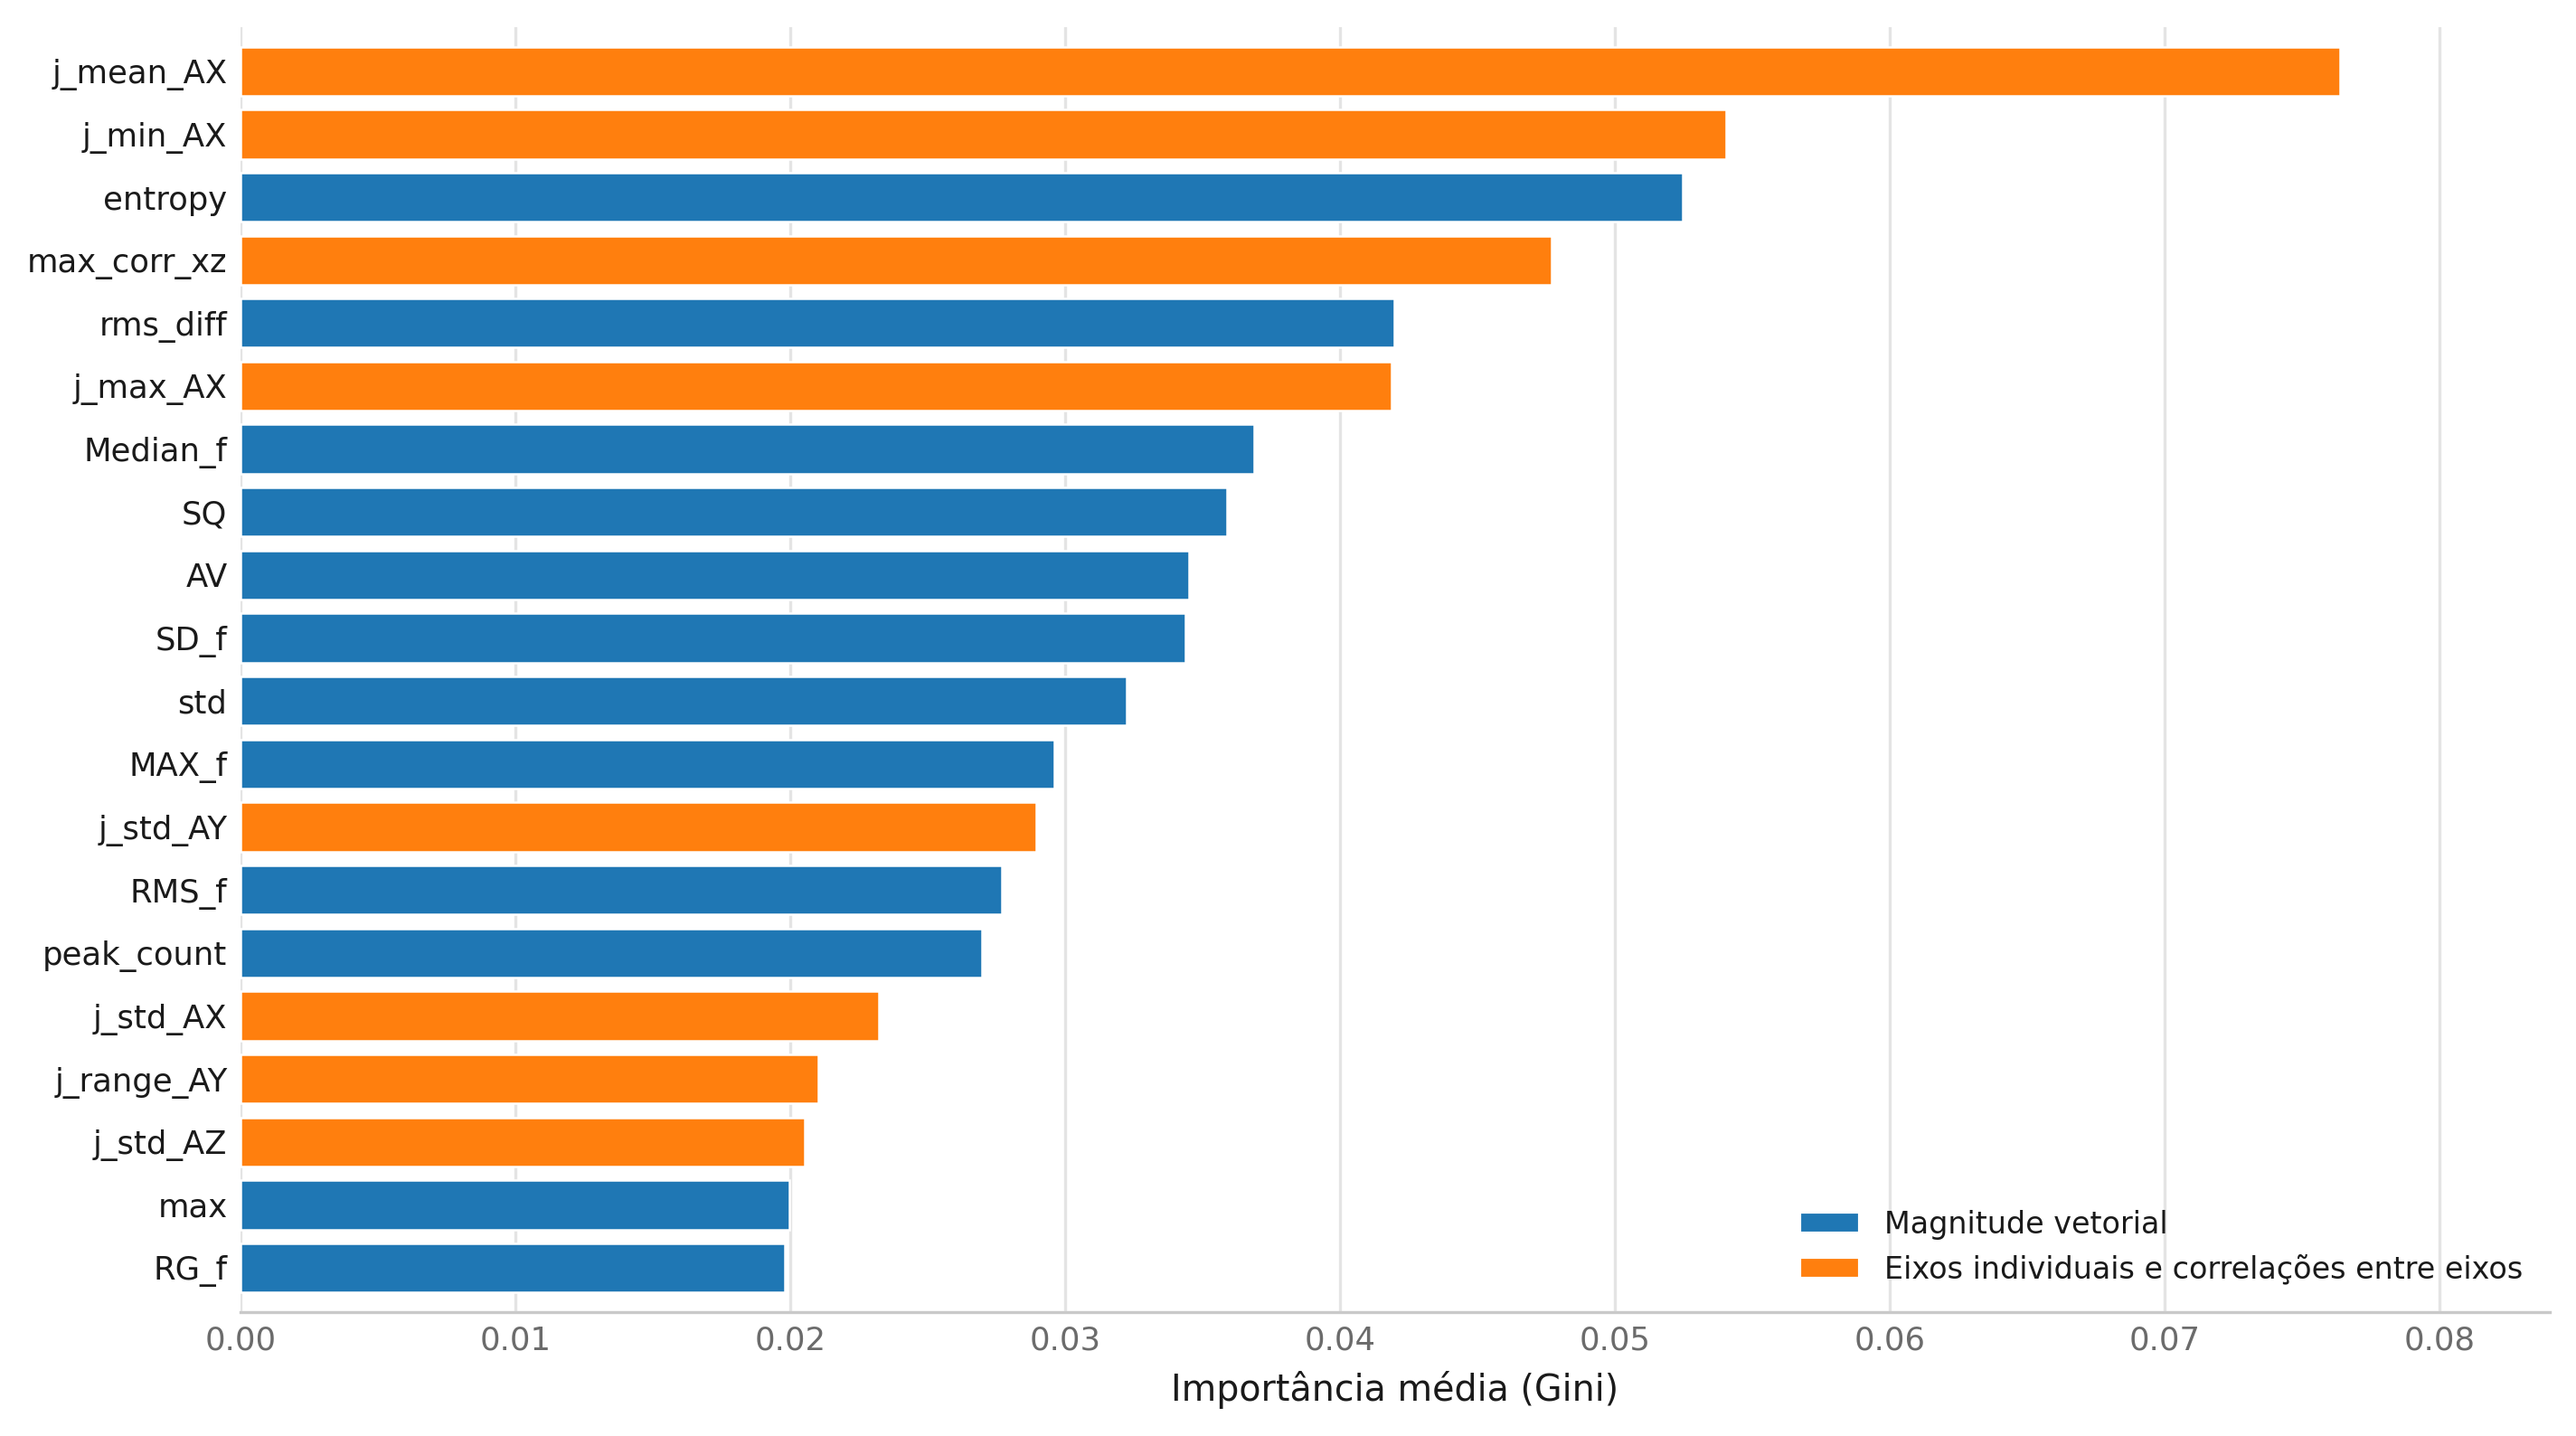


Salvos em C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id\resultados_mdrfcs_loao_46_busca_arvores:
  mdrfcs_top20_features.png
  mdrfcs_top20_features.pdf
  mdrfcs_top20_features.csv


In [3]:
# =========================================================
# Figura — Top-20 atributos do MDRF-CS
# =========================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Patch
from IPython.display import display, Image

BASE = (
    r"C:\Users\franc\OneDrive\Desktop\Doutorado"
    r"\experimento_split por id"
    r"\resultados_mdrfcs_loao_46_busca_arvores"
)

CSV_IMP = os.path.join(BASE, "mdrfcs_loao_importancia.csv")
TOP_N = 20

AZUL = "#1f77b4"
LARANJA = "#ff7f0e"
TINTA = "#1a1a1a"
MUDO = "#6b6b6b"

# ---------------------------------------------------------
# 1. Leitura das importâncias médias salvas
# ---------------------------------------------------------
d = pd.read_csv(CSV_IMP, index_col=0)

imp = pd.DataFrame({
    "feature": d.index.astype(str),
    "media": d["importance"].to_numpy(),
})

assert len(imp) == 46, (
    f"Esperados 46 atributos; encontrados {len(imp)}."
)
assert np.isfinite(imp["media"]).all(), (
    "Há importâncias inválidas."
)
assert imp["media"].sum() > 0, (
    "A soma das importâncias deve ser positiva."
)

# ---------------------------------------------------------
# 2. Classificação dos atributos
# ---------------------------------------------------------
def por_eixo(nome):
    return nome.startswith("j_") or nome.startswith("max_corr_")


imp["familia"] = np.where(
    imp["feature"].map(por_eixo),
    "eixos",
    "vm",
)

top = imp.nlargest(TOP_N, "media").reset_index(drop=True)

print(f"Atributos: {len(imp)}")
print(f"\nTop-{TOP_N}:")
print(top.round(5).to_string(index=False))

print(
    f"\nSoma do top-{TOP_N}: {top['media'].sum():.4f} "
    f"({100 * top['media'].sum() / imp['media'].sum():.1f}% do total)"
)

# ---------------------------------------------------------
# 3. Figura — sem título e sem barras de incerteza
# ---------------------------------------------------------
t = top.iloc[::-1].reset_index(drop=True)
y = np.arange(len(t))

cores = np.where(
    t["familia"] == "eixos",
    LARANJA,
    AZUL,
)

fig, ax = plt.subplots(figsize=(9.6, 5.4), dpi=200)

ax.barh(
    y,
    t["media"],
    height=0.78,
    color=cores,
    edgecolor="white",
    linewidth=0.6,
)

ax.set_yticks(y)
ax.set_yticklabels(
    t["feature"],
    fontsize=8.5,
    color=TINTA,
)
ax.set_ylim(-0.7, len(t) - 0.3)

ax.set_xlabel(
    "Importância média (Gini)",
    fontsize=9.5,
    color=TINTA,
)

ax.xaxis.grid(
    True,
    color="#e4e4e4",
    linewidth=0.8,
)
ax.set_axisbelow(True)
ax.yaxis.grid(False)

for lado in ("top", "right", "left"):
    ax.spines[lado].set_visible(False)

ax.spines["bottom"].set_color("#c9c9c9")

ax.tick_params(
    axis="x",
    colors=MUDO,
    labelsize=8.5,
    length=0,
)
ax.tick_params(axis="y", length=0)

ax.set_xlim(0, t["media"].max() * 1.10)

ax.legend(
    handles=[
        Patch(
            facecolor=AZUL,
            edgecolor="white",
            label="Magnitude vetorial",
        ),
        Patch(
            facecolor=LARANJA,
            edgecolor="white",
            label="Eixos individuais e correlações entre eixos",
        ),
    ],
    loc="lower right",
    frameon=False,
    fontsize=8,
    labelcolor=TINTA,
)

fig.tight_layout()

# ---------------------------------------------------------
# 4. Salva e exibe
# ---------------------------------------------------------
png = os.path.join(BASE, "mdrfcs_top20_features.png")
pdf = os.path.join(BASE, "mdrfcs_top20_features.pdf")
csv = os.path.join(BASE, "mdrfcs_top20_features.csv")

fig.savefig(png, dpi=300, bbox_inches="tight")
fig.savefig(pdf, bbox_inches="tight")
plt.close(fig)

top.to_csv(csv, index=False)

display(Image(filename=png))

print(f"\nSalvos em {BASE}:")
print("  mdrfcs_top20_features.png")
print("  mdrfcs_top20_features.pdf")
print("  mdrfcs_top20_features.csv")

**Nested Accelerometer Predictions for Fusion Weights**

<small>Runs an inner seven-animal LOAO loop within each outer training set. Saves out-of-fold predictions and class-specific F1 scores used to estimate accelerometer fusion weights.</small>

In [1]:
# =========================================================
# MDRF-CS — ETAPA 3: laço interno (k=7) para os pesos da fusão
# Para cada animal de teste i: LOAO nos outros 7 -> OOF -> F1 por classe
# =========================================================
import os, time
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import f1_score

BASE    = r"C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id"
CLASSES = ["deitado", "andando", "bebendo", "comendo"]
LABELS  = [0, 1, 2, 3]

orig = pd.read_csv(os.path.join(BASE, "features_originais.csv"))
aug  = pd.read_csv(os.path.join(BASE, "features_aumentadas.csv"))
META = ["janela", "janela_origem", "shift", "ID", "atividade", "label"]
FEAT = [c for c in orig.columns if c not in META]

ids = sorted(orig["ID"].unique())
f1_rows, oof_rows = [], []
t0 = time.time()

for id_teste in ids:
    # --- só os 7 animais de desenvolvimento
    dev     = orig[orig["ID"] != id_teste].reset_index(drop=True)
    aug_dev = aug[aug["ID"] != id_teste]

    oof = np.zeros((len(dev), len(CLASSES)))
    logo = LeaveOneGroupOut()

    for k, (tr, va) in enumerate(logo.split(dev, dev["label"], groups=dev["ID"]), 1):
        ids_tr = set(dev.iloc[tr]["ID"])
        a_tr   = aug_dev[aug_dev["ID"].isin(ids_tr)]

        Xtr = pd.concat([dev.iloc[tr][FEAT], a_tr[FEAT]]).values
        ytr = np.concatenate([dev.iloc[tr]["label"].values, a_tr["label"].values])

        rf = RandomForestClassifier(
            n_estimators=500, max_depth=18, min_samples_split=4,
            min_samples_leaf=2, class_weight="balanced",
            random_state=42 + 10 * id_teste + k, n_jobs=-1)
        rf.fit(Xtr, ytr)

        p = np.zeros((len(va), len(CLASSES)))
        p[:, rf.classes_] = rf.predict_proba(dev.iloc[va][FEAT].values)
        oof[va] = p

    # --- F1 por classe sobre o OOF dos 7 animais
    y_dev  = dev["label"].values
    f1c    = f1_score(y_dev, oof.argmax(1), labels=LABELS, average=None, zero_division=0)
    macro  = f1c.mean()

    f1_rows.append({"ID_teste": id_teste,
                    **{f"f1_{c}": f1c[i] for i, c in enumerate(CLASSES)},
                    "macro_f1_oof": macro})

    bloco = dev[["janela", "ID", "label"]].copy()
    bloco.insert(0, "ID_teste", id_teste)
    for i, c in enumerate(CLASSES):
        bloco[f"prob_{c}"] = oof[:, i]
    oof_rows.append(bloco)

    print(f"Teste ID {id_teste} | OOF interno nos IDs {[i for i in ids if i != id_teste]} | "
          f"F1 = " + " ".join(f"{c[:3]}={f1c[i]:.3f}" for i, c in enumerate(CLASSES)) +
          f" | macro={macro:.4f} | {time.time() - t0:.0f}s")

# ---------------------------------------------------------
# Saída
# ---------------------------------------------------------
f1_df  = pd.DataFrame(f1_rows)
oof_df = pd.concat(oof_rows, ignore_index=True)

print("\n=== F1 por classe (OOF interno) — insumo dos pesos da fusão ===")
print(f1_df.round(4).to_string(index=False))

print("\nEstabilidade entre os 8 conjuntos de pesos:")
for c in CLASSES:
    col = f1_df[f"f1_{c}"]
    print(f"  {c:<8} {col.mean():.4f} ± {col.std():.4f}   [{col.min():.4f} – {col.max():.4f}]")

f1_df.to_csv(os.path.join(BASE, "mdrfcs_inner_f1_por_classe.csv"), index=False)
oof_df.to_csv(os.path.join(BASE, "mdrfcs_inner_oof_probs.csv"), index=False)

print(f"\nSalvos em {BASE}:")
print("  mdrfcs_inner_f1_por_classe.csv   (8 linhas: F1 por classe para cada animal de teste)")
print("  mdrfcs_inner_oof_probs.csv       (8 x ~6.900 linhas: OOF interno, para auditoria)")
print(f"Tempo total: {(time.time() - t0) / 60:.1f} min")

Teste ID 1 | OOF interno nos IDs [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)] | F1 = dei=0.967 and=0.793 beb=0.713 com=0.932 | macro=0.8514 | 19s
Teste ID 2 | OOF interno nos IDs [np.int64(1), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)] | F1 = dei=0.966 and=0.783 beb=0.697 com=0.930 | macro=0.8442 | 38s
Teste ID 3 | OOF interno nos IDs [np.int64(1), np.int64(2), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)] | F1 = dei=0.966 and=0.782 beb=0.696 com=0.931 | macro=0.8436 | 55s
Teste ID 4 | OOF interno nos IDs [np.int64(1), np.int64(2), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8)] | F1 = dei=0.967 and=0.784 beb=0.692 com=0.927 | macro=0.8424 | 74s
Teste ID 5 | OOF interno nos IDs [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(6), np.int64(7), np.int64(8)] | F1 = dei=0.966 and=0.772 beb=0.706 com=0.929 | macro=0.8433 | 92s
Teste ID 6 | OOF interno nos IDs [n

**MDRF-CS Confusion Matrix on Paired Windows**

<small>Matches accelerometer predictions to the selected audio window list, reports classification metrics, and plots a row-normalized confusion matrix for the paired subset.</small>

Acel 7892 | Áudio 6285 (lmaan_loao_probs_completo_acc_det.csv) | pareadas 6285   (esperado: 6285)
              precision    recall  f1-score   support

     Deitado     0.9834    0.9496    0.9662      3176
     Andando     0.7798    0.8430    0.8102       605
     Bebendo     0.6722    0.7732    0.7192       366
     Comendo     0.9389    0.9411    0.9400      2138

    accuracy                         0.9262      6285
   macro avg     0.8436    0.8767    0.8589      6285
weighted avg     0.9305    0.9262    0.9279      6285

         Deitado  Andando  Bebendo  Comendo
Deitado     3016       28       73       59
Andando       11      510       31       53
Bebendo       17       47      283       19
Comendo       23       69       34     2012
         Deitado  Andando  Bebendo  Comendo
Deitado     0.95     0.01     0.02     0.02
Andando     0.02     0.84     0.05     0.09
Bebendo     0.05     0.13     0.77     0.05
Comendo     0.01     0.03     0.02     0.94

Salvo:
  C:\Users\pedro\On

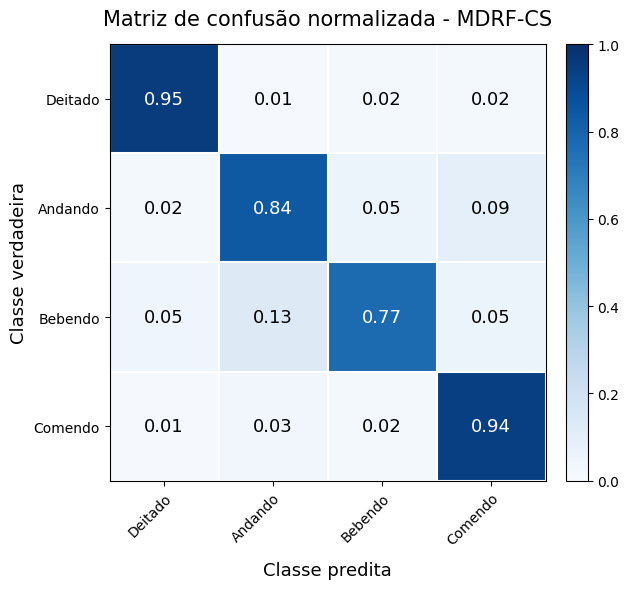

In [3]:
# ============================================================
# Matriz de confusão normalizada (0–1) — MDRF-CS, LOAO, JANELAS PAREADAS (6.285)
# Mesmo conjunto da Tabela tab:res_mdrf e da fusão (pareamento por "janela")
# ============================================================
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

BASE   = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id"
PASTA_SAIDA = BASE          # troque aqui se quiser salvar em outra pasta (ex.: a pasta figures)
os.makedirs(PASTA_SAIDA, exist_ok=True)

LABELS = [0, 1, 2, 3]
NOMES  = ["Deitado", "Andando", "Bebendo", "Comendo"]
PROB   = ["prob_deitado", "prob_andando", "prob_bebendo", "prob_comendo"]

# --- mesmo pareamento da célula de fusão -------------------------------
a  = pd.read_csv(os.path.join(BASE, "mdrfcs_loao_probs.csv"))
f_aud = sorted(glob.glob(os.path.join(BASE, "lmaan_loao_probs*.csv")), key=os.path.getmtime, reverse=True)[0]
l  = pd.read_csv(f_aud)
df = a.merge(l[["janela"]], on="janela").sort_values("janela").reset_index(drop=True)
print(f"Acel {len(a)} | Áudio {len(l)} ({os.path.basename(f_aud)}) | pareadas {len(df)}   (esperado: 6285)")

y_true = df["label"].values
y_pred = df[PROB].values.argmax(1)

# conferência com a Tabela: revocação por classe = diagonal normalizada
print(classification_report(y_true, y_pred, labels=LABELS, target_names=NOMES, digits=4, zero_division=0))

cm_n = confusion_matrix(y_true, y_pred, labels=LABELS, normalize="true")
cm_c = confusion_matrix(y_true, y_pred, labels=LABELS)
print(pd.DataFrame(cm_c, index=NOMES, columns=NOMES))
print(pd.DataFrame(cm_n.round(2), index=NOMES, columns=NOMES))

fig, ax = plt.subplots(figsize=(6.6, 6))
im = ax.imshow(cm_n, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm_n[i, j]:.2f}", ha="center", va="center", fontsize=13,
                color="white" if cm_n[i, j] > 0.5 else "black")
ax.set_xticks(range(4)); ax.set_xticklabels(NOMES, rotation=45, ha="right", rotation_mode="anchor")
ax.set_yticks(range(4)); ax.set_yticklabels(NOMES)
ax.set_xticks(np.arange(-.5, 4, 1), minor=True); ax.set_yticks(np.arange(-.5, 4, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1.5); ax.tick_params(which="minor", length=0)
ax.set_xlabel("Classe predita", fontsize=13, labelpad=10)
ax.set_ylabel("Classe verdadeira", fontsize=13)
ax.set_title("Matriz de confusão normalizada - MDRF-CS", fontsize=15, pad=14)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()

# --- salva ANTES de exibir ----------------------------------------------
f_png = os.path.join(PASTA_SAIDA, "mc_MDRF_CS4c_pt.png")
f_pdf = os.path.join(PASTA_SAIDA, "mc_MDRF_CS4c_pt.pdf")
fig.savefig(f_png, dpi=300, bbox_inches="tight")
fig.savefig(f_pdf, bbox_inches="tight")
print(f"\nSalvo:\n  {f_png}\n  {f_pdf}")
plt.show()

**MDRF-CS Optimization for TinyML**

<small>Compares the full 500-tree model with an embedded-oriented version using the first 100 trees, float32 features and thresholds, and quantized leaf probabilities under LOAO.</small>

In [33]:
"""
MDRF-CS: 500 arvores x versao otimizada para o ESP32 (LOAO, um animal fora)

Em cada fold o RF e retreinado com os hiperparametros do modelo salvo,
usando 7 animais, e avaliado no animal que ficou de fora:
  Completo  : 500 arvores, float64 (sklearn)
  Otimizado : 100 primeiras arvores, features e limiares em float32,
              folhas quantizadas em uint8 (soma 255) -- igual ao rf_model.h
"""
import os, time, warnings
import numpy as np
import pandas as pd
import joblib
from scipy.stats import skew, kurtosis, wilcoxon
from scipy.signal import find_peaks
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
warnings.filterwarnings("ignore", message="X does not have valid feature names")

# ----------------------------------------------------------------- CONFIG
BASE = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id"
# notebook: BASE = r"C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id"
CSV_PATH = os.path.join(BASE, "dataset_treinamento_suinos.csv")
MODEL_PATH = os.path.join(BASE, "melhores modelos", "Melhor MDRF-CS",
                          "RandomForest_CShift4P_CombinedFeat_4classes_sem_correndo.joblib")
N_OTIM = 100
SEED_PADRAO = 42         # usada so se o modelo salvo nao tiver random_state
CLASSES = ["deitado", "andando", "bebendo", "comendo"]
LABEL_FIX = {"dormindo": "deitado", "deitadoac": "deitado", "inativo": "deitado"}


# ------------------------------------------------------- 47 features (notebook)
def extract(ax, ay, az):
    vm = np.sqrt(ax**2 + ay**2 + az**2); n = len(vm)
    peaks, _ = find_peaks(vm, height=np.mean(vm))
    fft_vals = np.abs(np.fft.rfft(vm - np.mean(vm)))
    sorted_f = np.sort(fft_vals); N_fft = len(fft_vals)
    p3 = vm[70:] if n >= 100 else vm[int(0.7 * n):]
    diff_vm = np.diff(vm) if n > 1 else np.array([0.0])
    hist, _ = np.histogram(vm, bins=10, density=True); hist = hist + 1e-6
    f = {
        "mean": np.mean(vm), "std": np.std(vm), "min": np.min(vm), "max": np.max(vm),
        "max_min_diff": np.max(vm) - np.min(vm), "median": np.median(vm),
        "peak_count": len(peaks), "skewness": skew(vm), "kurtosis": kurtosis(vm),
        "sma": np.sum(np.abs(vm)) / n,
        "AV": np.mean(fft_vals), "SD_f": np.std(fft_vals), "MAX_f": np.max(fft_vals),
        "RG_f": np.max(fft_vals) - np.mean(fft_vals),
        "FQ": sorted_f[int(N_fft / 4)], "SQ": sorted_f[int(N_fft / 2)],
        "RMS_f": np.sqrt(np.mean(fft_vals**2)), "Median_f": np.median(fft_vals),
        "max_corr_xy": np.max(np.correlate(ax, ay, mode="full")),
        "max_corr_xz": np.max(np.correlate(ax, az, mode="full")),
        "max_corr_yz": np.max(np.correlate(ay, az, mode="full")),
        "std_fim": np.std(p3), "rms_diff": np.sqrt(np.mean(diff_vm**2)),
        "tempo_pico": np.argmax(vm) / n, "entropy": -np.sum(hist * np.log(hist)),
        "zero_crossings": np.sum(np.diff(np.sign(diff_vm)) != 0),
    }
    for name, v in [("AX", ax), ("AY", ay), ("AZ", az)]:
        f[f"j_mean_{name}"] = np.mean(v); f[f"j_std_{name}"] = np.std(v)
        f[f"j_min_{name}"] = np.min(v); f[f"j_max_{name}"] = np.max(v)
        f[f"j_range_{name}"] = np.max(v) - np.min(v)
        f[f"j_mean_abs_{name}"] = np.mean(np.abs(v))
        f[f"j_rms_{name}"] = np.sqrt(np.mean(v**2))
    return f


# ------------------------------------------------------ emulacao do firmware
class Esp32Forest:
    """Mesmo layout/aritmetica do rf_model.h + rf_infer.c."""
    def __init__(self, trees):
        self.trees = []
        for est in trees:
            t = est.tree_
            leaf = t.children_left == -1
            v = t.value[:, 0, :].astype(np.float64)
            v = v / v.sum(axis=1, keepdims=True)
            q = np.round(v * 255).astype(np.int64)
            q[np.arange(len(q)), np.argmax(v, axis=1)] += 255 - q.sum(axis=1)
            self.trees.append(dict(
                left=t.children_left.astype(np.int64), right=t.children_right.astype(np.int64),
                feat=np.where(leaf, 0, t.feature).astype(np.int64),
                th=t.threshold.astype(np.float32), leaf=leaf, q=np.clip(q, 0, 255)))

    def predict(self, X):
        X = X.astype(np.float32); idx = np.arange(len(X))
        acc = np.zeros((len(X), 4), dtype=np.int64)
        for t in self.trees:
            node = np.zeros(len(X), dtype=np.int64)
            active = ~t["leaf"][node]
            while active.any():
                a = idx[active]; nd = node[a]
                left = X[a, t["feat"][nd]] <= t["th"][nd]       # float32 <= float32
                node[a] = np.where(left, t["left"][nd], t["right"][nd])
                active = ~t["leaf"][node]
            acc += t["q"][node]
        return acc.argmax(1)


# ------------------------------------------------------------------- main
m = joblib.load(MODEL_PATH)
names = list(m.feature_names_in_)
est = clone(m)
if est.get_params().get("random_state") is None:
    est.set_params(random_state=SEED_PADRAO)
N_FULL = est.get_params()["n_estimators"]
print("Hiperparametros:", {k: v for k, v in est.get_params().items() if k in
      ("n_estimators", "max_depth", "min_samples_leaf", "min_samples_split",
       "max_features", "class_weight", "bootstrap", "random_state")})

df = pd.read_csv(CSV_PATH)
df["atividade"] = df["atividade"].astype(str).str.lower().str.strip().replace(LABEL_FIX)
df = df[df["atividade"].isin(CLASSES)]

t0 = time.time(); rows, y, ids = [], [], []
for _, g in df.groupby("janela", sort=False):
    f = extract(g["AX"].to_numpy(float), g["AY"].to_numpy(float), g["AZ"].to_numpy(float))
    rows.append([f[c] for c in names])
    y.append(CLASSES.index(g["atividade"].iloc[0])); ids.append(g["ID"].iloc[0])
X, y, ids = np.array(rows), np.array(y), np.array(ids)
print(f"{len(X)} janelas, {len(np.unique(ids))} animais ({time.time() - t0:.0f} s)\n")

LAB = [0, 1, 2, 3]
mf1 = lambda yt, yp: f1_score(yt, yp, labels=LAB, average="macro", zero_division=0)
pred_full = np.zeros(len(y), int); pred_otim = np.zeros(len(y), int); linhas = []

print(f"{'animal':>8} {'n':>6} {'acc 500':>8} {'acc otim':>9} {'F1 500':>8} {'F1 otim':>8} {'concord.':>9}")
for animal in np.unique(ids):
    te = ids == animal
    rf = clone(est).fit(X[~te], y[~te])
    pf = rf.predict(X[te])
    po = Esp32Forest(rf.estimators_[:N_OTIM]).predict(X[te])
    pred_full[te], pred_otim[te] = pf, po
    linhas.append(dict(ID=animal, n=int(te.sum()),
                       acc_500=accuracy_score(y[te], pf), acc_otim=accuracy_score(y[te], po),
                       f1_500=mf1(y[te], pf), f1_otim=mf1(y[te], po),
                       concordancia=np.mean(pf == po)))
    r = linhas[-1]
    print(f"{str(animal):>8} {r['n']:6d} {r['acc_500']:8.4f} {r['acc_otim']:9.4f} "
          f"{r['f1_500']:8.4f} {r['f1_otim']:8.4f} {r['concordancia'] * 100:8.2f}%")

pa = pd.DataFrame(linhas)
print("\nMedia ± DP entre animais:")
for c in ["acc_500", "acc_otim", "f1_500", "f1_otim"]:
    print(f"  {c:<9} {pa[c].mean():.4f} ± {pa[c].std():.4f}")
d = pa["f1_otim"] - pa["f1_500"]
p = wilcoxon(pa["f1_otim"], pa["f1_500"]).pvalue if (d != 0).any() else np.nan
print(f"  delta F1 (otim - 500): {d.mean() * 100:+.2f} pp | Wilcoxon bicaudal p = {p:.4f}")

print("\nPooled (todas as janelas preditas sem o seu animal no treino):")
print(f"  500 arvores : acc {accuracy_score(y, pred_full):.4f} | macro-F1 {mf1(y, pred_full):.4f}")
print(f"  otimizado   : acc {accuracy_score(y, pred_otim):.4f} | macro-F1 {mf1(y, pred_otim):.4f}")
print(f"  concordancia: {np.mean(pred_full == pred_otim) * 100:.2f}% "
      f"({np.sum(pred_full != pred_otim)} de {len(y)} janelas mudam de classe)")

for nome, p_ in [(f"{N_FULL} arvores", pred_full), (f"Otimizado ({N_OTIM} arv., uint8/float32)", pred_otim)]:
    print(f"\n=== {nome} ===")
    print(classification_report(y, p_, labels=LAB, target_names=CLASSES, digits=4, zero_division=0))
    print(pd.DataFrame(confusion_matrix(y, p_, labels=LAB), index=CLASSES, columns=CLASSES))

pa.to_csv(os.path.join(BASE, "mdrfcs_500_vs_otimizado_loao.csv"), index=False)
print("\nSalvo: mdrfcs_500_vs_otimizado_loao.csv")

C:\Users\pedro\anaconda3\envs\vision_pose_cuda\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.8.0 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\pedro\anaconda3\envs\vision_pose_cuda\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.8.0 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


Hiperparametros: {'bootstrap': True, 'class_weight': 'balanced', 'max_depth': 18, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 500, 'random_state': 42}
7892 janelas, 8 animais (12 s)

  animal      n  acc 500  acc otim   F1 500  F1 otim  concord.
       1    879   0.9067    0.9067   0.7934   0.7963    99.43%
       2    865   0.9353    0.9341   0.8651   0.8542    99.19%
       3   1039   0.9086    0.9105   0.8419   0.8455    99.23%
       4    985   0.9076    0.9096   0.8346   0.8366    99.49%
       5    999   0.9309    0.9259   0.8754   0.8655    99.20%
       6    999   0.9099    0.9119   0.8504   0.8499    98.70%
       7   1137   0.9323    0.9332   0.8278   0.8356    99.38%
       8    989   0.9302    0.9262   0.8663   0.8614    99.09%

Media ± DP entre animais:
  acc_500   0.9202 ± 0.0129
  acc_otim  0.9198 ± 0.0112
  f1_500    0.8444 ± 0.0264
  f1_otim   0.8431 ± 0.0217
  delta F1 (otim - 500): -0.12 pp | Wilcoxon bicaudal p = 0.7422

Po

**Paired Audio Window Verification**

<small>Checks the paired-window list against audio files and dataset metadata, identifying missing files and inconsistencies in the available windows.</small>

In [4]:
# =========================================================
# Verifica a lista de janelas pareadas contra os arquivos
# =========================================================
import os, re, glob
import pandas as pd

BASE  = r"C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id"
AUDIO = os.path.join(BASE, "audio")
LISTA = os.path.join(AUDIO, "janelas_pareadas.txt")
CSV   = os.path.join(BASE, "dataset_treinamento_suinos.csv")

# --- lista (aceita "8280" ou nomes antigos "xx-hhmmss-j8280...")
with open(LISTA, encoding="utf-8") as f:
    linhas = [l.strip() for l in f if l.strip()]

def num(s):
    m = re.search(r"(?:-j)?(\d+)(?:\.\w+)?$", s)
    return int(m.group(1)) if m else None

lista = [num(l) for l in linhas]
invalidas = [l for l, n in zip(linhas, lista) if n is None]
lista = set(n for n in lista if n is not None)

print(f"Linhas na lista:    {len(linhas)}")
print(f"Janelas distintas:  {len(lista)}   (esperado: 6285)")
if invalidas:
    print(f"Linhas não reconhecidas: {len(invalidas)} -> {invalidas[:5]}")
if len(lista) < len(linhas) - len(invalidas):
    print(f"Duplicadas na lista: {len(linhas) - len(invalidas) - len(lista)}")

# --- arquivos no disco
def indexar(ext):
    reg = {}
    for p in glob.glob(os.path.join(AUDIO, "**", f"*.{ext}"), recursive=True):
        stem = os.path.splitext(os.path.basename(p))[0]
        if stem.isdigit():
            reg[int(stem)] = os.path.basename(os.path.dirname(p))
    return reg

npy = indexar("npy")
wav = indexar("wav")
print(f"\n.npy no disco: {len(npy)}   .wav no disco: {len(wav)}")

# --- cruzamentos
print("\n=== Lista x arquivos ===")
print(f"Na lista, sem .npy:        {len(lista - set(npy))}")
print(f"Na lista, sem .wav:        {len(lista - set(wav))}")
print(f".npy fora da lista:        {len(set(npy) - lista)}")
print(f".wav fora da lista:        {len(set(wav) - lista)}")
print(f".npy sem .wav (e vice-versa): {len(set(npy) ^ set(wav))}")

for nome, s in [("sem .npy", lista - set(npy)), (".npy fora da lista", set(npy) - lista)]:
    if s:
        print(f"  exemplos {nome}: {sorted(s)[:10]}")

# --- classe da pasta: .npy x .wav
div_pasta = [j for j in set(npy) & set(wav) if npy[j] != wav[j]]
print(f"\nClasse da pasta diferente entre .npy e .wav: {len(div_pasta)}")

# --- cruzamento com a acelerometria
df = pd.read_csv(CSV)
if df.shape[1] == 1:
    df = pd.read_csv(CSV, sep=";", decimal=",")
w = df.groupby("janela").agg(atividade=("atividade", "first"), ID=("ID", "first"))
w.index = w.index.astype(int)
w["atividade"] = (w["atividade"].astype(str).str.lower().str.strip()
                  .replace({"dormindo": "deitado", "deitadoac": "deitado", "inativo": "deitado"}))

print(f"\nJanelas da lista ausentes na acelerometria: {len(lista - set(w.index))}")

MAP = {"lying": "deitado", "walking": "andando", "drinking": "bebendo", "eating": "comendo"}
comum = sorted(lista & set(w.index) & set(npy))
chk = pd.DataFrame({"janela": comum,
                    "pasta": [MAP.get(npy[j].lower(), npy[j].lower()) for j in comum],
                    "atividade": w.loc[comum, "atividade"].values,
                    "ID": w.loc[comum, "ID"].values})
div = chk[chk["pasta"] != chk["atividade"]]
print(f"Classe da pasta ≠ rótulo da acelerometria: {len(div)}")
if len(div):
    print(div.head(10).to_string(index=False))

print("\n=== Pareadas por animal x classe ===")
print(pd.crosstab(chk["ID"], chk["atividade"])[["deitado", "andando", "bebendo", "comendo"]])
print("\nTotal por classe:")
print(chk["atividade"].value_counts())

Linhas na lista:    6285
Janelas distintas:  6285   (esperado: 6285)

.npy no disco: 6285   .wav no disco: 6285

=== Lista x arquivos ===
Na lista, sem .npy:        0
Na lista, sem .wav:        0
.npy fora da lista:        0
.wav fora da lista:        0
.npy sem .wav (e vice-versa): 0

Classe da pasta diferente entre .npy e .wav: 0

Janelas da lista ausentes na acelerometria: 0
Classe da pasta ≠ rótulo da acelerometria: 0

=== Pareadas por animal x classe ===
atividade  deitado  andando  bebendo  comendo
ID                                           
1              379       65       35      215
2              398       62       26      216
3              340       98       51      334
4              325       79       47      327
5              455      107       47      201
6              373       92       62      259
7              490       50       40      314
8              416       52       58      272

Total por classe:
atividade
deitado    3176
comendo    2138
andando     605

**Log-Mel Array Integrity Checks**

<small>Inspects saved NumPy arrays for loading errors, inconsistent shapes, non-finite values, and empty data before audio-model training.</small>

In [5]:
# =========================================================
# Verifica integridade dos .npy (shape, NaN, arquivos vazios)
# =========================================================
import os, glob
import numpy as np
import pandas as pd

AUDIO = r"C:\Users\franc\OneDrive\Desktop\Doutorado\experimento_split por id\audio"

reg = []
for p in glob.glob(os.path.join(AUDIO, "**", "*.npy"), recursive=True):
    item = {"janela": int(os.path.splitext(os.path.basename(p))[0]),
            "classe": os.path.basename(os.path.dirname(p))}
    try:
        a = np.load(p)
        item.update(shape=a.shape, nan=bool(np.isnan(a).any()),
                    inf=bool(np.isinf(a).any()),
                    min=float(a.min()), max=float(a.max()),
                    constante=bool(a.min() == a.max()))
    except Exception as e:
        item["erro"] = str(e)
    reg.append(item)

r = pd.DataFrame(reg)
print(f"Arquivos: {len(r)}")
print("\nShapes:")
print(r["shape"].astype(str).value_counts())

problemas = r[(r.get("erro").notna() if "erro" in r else False)
              | r["nan"].fillna(False) | r["inf"].fillna(False)
              | r["constante"].fillna(False)
              | (r["shape"].astype(str) != "(128, 431)")]
print(f"\nCom problema: {len(problemas)}")
if len(problemas):
    print(problemas.to_string(index=False))
    print("\nPor classe:")
    print(problemas["classe"].value_counts())

Arquivos: 6285

Shapes:
shape
(128, 431)    6285
Name: count, dtype: int64

Com problema: 458
 janela   classe      shape   nan   inf  min  max  constante
   2885 drinking (128, 431) False False  0.0  0.0       True
   2888 drinking (128, 431) False False  0.0  0.0       True
   4139 drinking (128, 431) False False  0.0  0.0       True
   4315 drinking (128, 431) False False  0.0  0.0       True
   4397 drinking (128, 431) False False  0.0  0.0       True
   5125 drinking (128, 431) False False  0.0  0.0       True
   5132 drinking (128, 431) False False  0.0  0.0       True
   5402 drinking (128, 431) False False  0.0  0.0       True
    553 drinking (128, 431) False False  0.0  0.0       True
    563 drinking (128, 431) False False  0.0  0.0       True
    571 drinking (128, 431) False False  0.0  0.0       True
   5768 drinking (128, 431) False False  0.0  0.0       True
   5772 drinking (128, 431) False False  0.0  0.0       True
   5779 drinking (128, 431) False False  0.0  0.0   

**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

# Preparing audio experiment

**Log-Mel File Counts by Class**

<small>Counts saved NumPy spectrogram files in each behavior folder and displays the resulting class distribution.</small>

In [6]:
from pathlib import Path
import pandas as pd
from IPython.display import display

pasta_base = Path(
    r"C:\Users\franc\OneDrive\Desktop\Doutorado"
    r"\pig_multimodal_behavior_release_v1\zenodo_dataset_v1"
    r"\audio\logmel_512"
)

traducao = {
    "drinking": "Bebendo",
    "eating": "Comendo",
    "walking": "Andando",
    "lying": "Deitado",
}

if not pasta_base.is_dir():
    raise FileNotFoundError(f"Pasta não encontrada: {pasta_base}")

contagens = []

for pasta in sorted(pasta_base.iterdir()):
    if pasta.is_dir():
        quantidade = sum(
            1 for arquivo in pasta.rglob("*")
            if arquivo.is_file() and arquivo.suffix.lower() == ".npy"
        )

        contagens.append({
            "Pasta": pasta.name,
            "Classe": traducao.get(pasta.name.lower(), pasta.name),
            "Arquivos .npy": quantidade,
        })

tabela = pd.DataFrame(
    contagens, columns=["Pasta", "Classe", "Arquivos .npy"]
)

display(tabela)
print(f"TOTAL: {int(tabela['Arquivos .npy'].sum()):,} arquivos .npy")

,Pasta,Classe,Arquivos .npy
0,drinking,Bebendo,366
1,eating,Comendo,2138
2,lying,Deitado,3176
3,walking,Andando,605


TOTAL: 6,285 arquivos .npy


**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

**LMAAN Training with Squeeze-and-Excitation Attention**

<small>Trains the attention-based audio network under LOAO with training augmentation. Selects checkpoints using internal validation accuracy and saves held-out predictions and performance metrics.</small>

In [148]:
# =========================================================
# LMAAN — Leave-One-Animal-Out (8 folds) — Treinamento Completo
# Data Augmentation com Circular Shift (np.roll) nas amostras
# Checkpoint e scheduler pela ACURÁCIA; macro-F1 monitorado
# Versão determinística e com limpeza rigorosa de memória GPU
# =========================================================
import glob
import gc
import os
import random
import sys
import time

# --- variáveis de ambiente ANTES de importar torch ---
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"   # exigido p/ determinismo em cuBLAS
_env = os.path.dirname(sys.executable)
os.environ["PATH"] = os.pathsep.join([
    _env,
    os.path.join(_env, "Library", "mingw-w64", "bin"),
    os.path.join(_env, "Library", "usr", "bin"),
    os.path.join(_env, "Library", "bin"),
    os.path.join(_env, "Scripts"),
    os.environ["PATH"],
])

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import LeaveOneGroupOut, train_test_split
from sklearn.utils.class_weight import compute_class_weight
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset

# ---------------------------------------------------------
# 0. Reprodutibilidade
# ---------------------------------------------------------
SEED_GLOBAL = 42
DETERMINISMO_ESTRITO = False   # True -> levanta exceção se alguma op não for determinística

def set_seed(seed=SEED_GLOBAL):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=not DETERMINISMO_ESTRITO)
    except AttributeError:
        pass

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

set_seed(SEED_GLOBAL)

# ---------------------------------------------------------
# 1. Caminhos e hiperparâmetros
# ---------------------------------------------------------
BASE = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id"
LOGMEL = os.path.join(BASE, "audio", "logmel_512")
CSV = os.path.join(BASE, "dataset_treinamento_suinos.csv")
SUFIXO = "completo_acc_det"          # não sobrescreve a rodada anterior

CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES = ["Lying", "Walking", "Drinking", "Eating"]
LABELS = [0, 1, 2, 3]
PASTA2CLS = {
    "lying": "deitado",
    "walking": "andando",
    "drinking": "bebendo",
    "eating": "comendo",
}
CLASSES_AUG = [1, 2]   # andando, bebendo
SHIFTS = [1, 2, 3]     # pedaços de 25%, 50%, 75%
EPOCHS, BATCH, WIDTH = 60, 16, 431
VAL_FRAC = 0.10
NUM_WORKERS = 0        # 0 mantém o dataset no processo principal (evita deadlocks no Windows)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print(f"Device: {device} | AMP: {USE_AMP} | determinismo estrito: {DETERMINISMO_ESTRITO} | seed: {SEED_GLOBAL}")
print(f"torch {torch.__version__} | cudnn {torch.backends.cudnn.version()} | GPU {torch.cuda.get_device_name(0) if device.type == 'cuda' else '—'}")

# ---------------------------------------------------------
# 2. Manifesto de dados
# ---------------------------------------------------------
reg = []
for p in glob.glob(os.path.join(LOGMEL, "*", "*.npy")):
    pasta = os.path.basename(os.path.dirname(p)).lower()
    reg.append({
        "janela": int(os.path.splitext(os.path.basename(p))[0]),
        "atividade": PASTA2CLS[pasta],
        "path": p,
    })
man = pd.DataFrame(reg)

acc = pd.read_csv(CSV)
if acc.shape[1] == 1:
    acc = pd.read_csv(CSV, sep=";", decimal=",")
id_map = acc.groupby("janela")["ID"].first()
id_map.index = id_map.index.astype(int)

man["ID"] = man["janela"].map(id_map)
man["label"] = man["atividade"].map({c: i for i, c in enumerate(CLASSES)})
man = man.sort_values("janela").reset_index(drop=True)   # ordem independente do glob

assert man["ID"].notna().all(), "Há janelas de áudio sem ID na planilha."
print(f"\nJanelas: {len(man)} (esperado: 6285) | Animais: {man['ID'].nunique()}")
print(pd.crosstab(man["ID"], man["atividade"])[CLASSES])

# ---------------------------------------------------------
# 3. Espectrogramas em RAM
# ---------------------------------------------------------
t0 = time.time()
SPECS = np.stack([np.load(p).astype(np.float32) for p in man["path"]])
print(f"Espectrogramas carregados: {SPECS.shape} em {time.time() - t0:.1f}s")

# ---------------------------------------------------------
# 4. AttentionPigNet
# ---------------------------------------------------------
class SEBlock(nn.Module):
    def __init__(self, c, r=16):
        super().__init__()
        h = max(c // r, 1)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(c, h, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(h, c, bias=False),
            nn.Sigmoid(),
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        return x * self.fc(self.pool(x).view(b, c)).view(b, c, 1, 1)

def bloco(cin, cout, pool):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1),
        nn.BatchNorm2d(cout),
        nn.ReLU(),
        SEBlock(cout),
        pool,
    )

class AttentionPigNet(nn.Module):
    def __init__(self, n=4):
        super().__init__()
        self.layer1 = bloco(1, 64, nn.MaxPool2d(2, 2))
        self.layer2 = bloco(64, 128, nn.MaxPool2d(2, 2))
        self.layer3 = bloco(128, 256, nn.MaxPool2d(2, 2))
        self.layer4 = bloco(256, 512, nn.AdaptiveAvgPool2d((1, 1)))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, n),
        )

    def forward(self, x):
        return self.classifier(
            self.layer4(self.layer3(self.layer2(self.layer1(x))))
        )

# ---------------------------------------------------------
# 5. Dataset e augmentation (circular shift)
# ---------------------------------------------------------
def cshift(s, k):
    if k == 0:
        return s
    n = s.shape[1]
    shift_pixels = (n // 4) * k
    return np.roll(s, shift_pixels, axis=1)

LBL = man["label"].values

class DS(Dataset):
    def __init__(self, idx, shifts, noise):
        self.idx, self.shifts, self.noise = idx, shifts, noise

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        s = cshift(SPECS[self.idx[i]], self.shifts[i])
        if self.noise:
            s = s + np.random.randn(*s.shape).astype(np.float32) * 0.005
        s = (s - s.min()) / (s.max() - s.min() + 1e-8)
        s = (
            s[:, :WIDTH]
            if s.shape[1] >= WIDTH
            else np.pad(s, ((0, 0), (0, WIDTH - s.shape[1])))
        )
        return torch.from_numpy(np.ascontiguousarray(s)).unsqueeze(0), int(
            LBL[self.idx[i]]
        )

def com_aug(idx):
    ii, ss = [], []
    for i in idx:
        ii.append(i)
        ss.append(0)
        if LBL[i] in CLASSES_AUG:
            for k in SHIFTS:
                ii.append(i)
                ss.append(k)
    return np.array(ii), np.array(ss)

def prever(model, idx):
    dl = DataLoader(
        DS(idx, np.zeros(len(idx), int), False),
        batch_size=64,
        shuffle=False,
        num_workers=NUM_WORKERS,
        worker_init_fn=seed_worker,
    )
    out = []
    model.eval()
    with torch.no_grad():
        for x, _ in dl:
            x = x.to(device, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
            out.append(torch.softmax(logits.float(), 1).cpu().numpy())
    
    del dl
    if device.type == "cuda":
        torch.cuda.empty_cache()

    return np.vstack(out)

# ---------------------------------------------------------
# 6. Treinamento LOAO (8 folds)
# ---------------------------------------------------------
probs_all = np.zeros((len(man), 4))
metricas, historico = [], []
logo = LeaveOneGroupOut()
T0 = time.time()

print("\nIniciando o Treinamento Leave-One-Animal-Out (LOAO)...\n")

for fold, (tr, te) in enumerate(
    logo.split(man, man["label"], groups=man["ID"]), 1
):
    # Limpeza preventiva total de VRAM ao entrar no fold
    if device.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()

    fold_seed = SEED_GLOBAL + fold
    set_seed(fold_seed)                 # re-semeia tudo no início do fold

    g_train = torch.Generator()
    g_train.manual_seed(fold_seed)

    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    id_teste = man.at[te[0], "ID"]

    tr_fit, tr_val = train_test_split(
        tr, test_size=VAL_FRAC, stratify=LBL[tr], random_state=fold_seed
    )
    ii, ss = com_aug(tr_fit)
    dl_tr = DataLoader(
        DS(ii, ss, True),
        batch_size=BATCH,
        shuffle=True,
        pin_memory=True,
        num_workers=NUM_WORKERS,
        worker_init_fn=seed_worker,
        generator=g_train,
    )

    w = compute_class_weight("balanced", classes=np.arange(4), y=LBL[ii])
    crit = nn.CrossEntropyLoss(
        weight=torch.tensor(w, dtype=torch.float32).to(device)
    )

    model = AttentionPigNet().to(device)
    opt = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.02)
    sch = optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="max", factor=0.5, patience=5
    )

    y_val = LBL[tr_val]
    best, best_state, best_ep, best_f1 = -1, None, 0, 0.0
    tf = time.time()

    for ep in range(1, EPOCHS + 1):
        model.train()
        for x, y in dl_tr:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = crit(model(x), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()

        pv = prever(model, tr_val)
        yv = pv.argmax(1)
        accv = accuracy_score(y_val, yv)
        f1v = f1_score(y_val, yv, average="macro", zero_division=0)
        f1cv = f1_score(y_val, yv, labels=LABELS, average=None, zero_division=0)
        sch.step(accv)

        marca = ""
        if accv > best:
            best, best_ep, best_f1 = accv, ep, f1v
            best_state = {
                k: v.detach().cpu().clone() for k, v in model.state_dict().items()
            }
            marca = "  <-- melhor"

        historico.append({
            "fold": fold,
            "ID_teste": id_teste,
            "epoca": ep,
            "val_acc": accv,
            "val_macro_f1": f1v,
            **{f"val_f1_{c}": f1cv[i] for i, c in enumerate(CLASSES)},
            "lr": opt.param_groups[0]["lr"],
        })

        if ep == 1 or ep % 5 == 0 or marca:
            print(
                f"  f{fold} ep {ep:02d} | acc {accv:.4f} | macroF1 {f1v:.4f} | dei"
                f" {f1cv[0]:.2f} and {f1cv[1]:.2f} beb {f1cv[2]:.2f} com {f1cv[3]:.2f}"
                f" | lr {opt.param_groups[0]['lr']:.1e} |"
                f" {(time.time()-tf)/ep:.0f}s/ép{marca}"
            )

        # Limpeza periódica de memória da GPU durante o loop de épocas
        if device.type == "cuda":
            torch.cuda.empty_cache()

    model.load_state_dict(best_state)
    torch.save(
        best_state,
        os.path.join(BASE, f"lmaan_loao_{SUFIXO}_fold{fold}_ID{id_teste}.pth"),
    )

    p = prever(model, te)
    probs_all[te] = p
    yte, yhat = LBL[te], p.argmax(1)
    f1c = f1_score(yte, yhat, labels=LABELS, average=None, zero_division=0)

    metricas.append({
        "fold": fold,
        "ID_teste": id_teste,
        "n_teste": len(te),
        "melhor_epoca": best_ep,
        "val_acc": best,
        "val_macro_f1": best_f1,
        "accuracy": accuracy_score(yte, yhat),
        "macro_f1": f1_score(
            yte, yhat, labels=LABELS, average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            yte, yhat, labels=LABELS, average="weighted", zero_division=0
        ),
        **{f"f1_{c}": f1c[i] for i, c in enumerate(CLASSES)},
    })

    print(
        f"FOLD {fold} | ID {id_teste} | n={len(te):>4} | ép {best_ep:02d} (val"
        f" acc {best:.4f} / macroF1 {best_f1:.4f}) | TESTE"
        f" acc={metricas[-1]['accuracy']:.4f}"
        f" macroF1={metricas[-1]['macro_f1']:.4f} beb={f1c[2]:.3f} |"
        f" {(time.time()-T0)/60:.1f} min\n"
    )

    # Limpeza pesada e destruição de referências ao finalizar o Fold
    del model, opt, sch, scaler, dl_tr
    if device.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()

# ---------------------------------------------------------
# 7. Métricas globais e salvamento
# ---------------------------------------------------------
m = pd.DataFrame(metricas)
y_true, y_pred = LBL, probs_all.argmax(1)

print("=" * 60)
print("=== POOLED CONFUSION MATRIX & CLASSIFICATION REPORT ===")
print("=" * 60)
print(
    classification_report(
        y_true,
        y_pred,
        labels=LABELS,
        target_names=NOMES,
        digits=4,
        zero_division=0,
    )
)
print(pd.DataFrame(
    __import__("sklearn.metrics", fromlist=["confusion_matrix"])
    .confusion_matrix(y_true, y_pred, labels=LABELS),
    index=NOMES, columns=NOMES).to_string())

print("\n=== RESULTADOS POR ANIMAL (ID TESTE) ===")
print(m.round(4).to_string(index=False))

print("\n=== MÉDIA ± DESVIO PADRÃO ===")
for c in ["accuracy", "macro_f1", "weighted_f1"] + [
    f"f1_{c}" for c in CLASSES
]:
    print(f"  {c:<12} {m[c].mean():.4f} ± {m[c].std():.4f}")

out = man[["janela", "ID", "atividade", "label"]].copy()
for i, c in enumerate(CLASSES):
    out[f"prob_{c}"] = probs_all[:, i]
out["pred"] = y_pred

out.to_csv(os.path.join(BASE, f"lmaan_loao_probs_{SUFIXO}.csv"), index=False)
m.to_csv(
    os.path.join(BASE, f"lmaan_loao_metricas_por_animal_{SUFIXO}.csv"),
    index=False,
)
pd.DataFrame(historico).to_csv(
    os.path.join(BASE, f"lmaan_loao_historico_{SUFIXO}.csv"), index=False
)

print(f"\nArquivos salvos em {BASE} com sufixo '{SUFIXO}'")

Device: cuda | AMP: True | determinismo estrito: False | seed: 42
torch 2.5.1 | cudnn 90100 | GPU NVIDIA GeForce RTX 3070

Janelas: 6285 (esperado: 6285) | Animais: 8
atividade  deitado  andando  bebendo  comendo
ID                                           
1              379       65       35      215
2              398       62       26      216
3              340       98       51      334
4              325       79       47      327
5              455      107       47      201
6              373       92       62      259
7              490       50       40      314
8              416       52       58      272
Espectrogramas carregados: (6285, 128, 431) em 54.5s

Iniciando o Treinamento Leave-One-Animal-Out (LOAO)...

  f1 ep 01 | acc 0.7071 | macroF1 0.5539 | dei 0.81 and 0.25 beb 0.35 com 0.79 | lr 1.0e-03 | 27s/ép  <-- melhor
  f1 ep 04 | acc 0.7375 | macroF1 0.5493 | dei 0.81 and 0.35 beb 0.23 com 0.80 | lr 1.0e-03 | 26s/ép  <-- melhor
  f1 ep 05 | acc 0.7857 | macroF1 0.6

**Audio CNN Baseline Without SE Blocks**

<small>Evaluates the audio CNN without SE blocks under LOAO. This implementation also omits circular-shift augmentation, while retaining training noise and checkpoint selection by internal validation accuracy.</small>

In [3]:
# =========================================================
# ABLAÇÃO SEM ATENÇÃO 
# Idêntico ao LMAAN exceto: (a) sem blocos SE, (b) . Mesmas sementes (42+fold), mesmo split interno
# de 10% estratificado, AMP, scheduler e checkpoint pela acurácia de
# validação INTERNA (o animal de teste não entra em nenhuma decisão).
# Versão determinística e com limpeza rigorosa de memória GPU
# =========================================================
import glob
import gc
import os
import random
import sys
import time

# --- variáveis de ambiente ANTES de importar torch ---
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"   # exigido p/ determinismo em cuBLAS
_env = os.path.dirname(sys.executable)
os.environ["PATH"] = os.pathsep.join([
    _env,
    os.path.join(_env, "Library", "mingw-w64", "bin"),
    os.path.join(_env, "Library", "usr", "bin"),
    os.path.join(_env, "Library", "bin"),
    os.path.join(_env, "Scripts"),
    os.environ["PATH"],
])

import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import LeaveOneGroupOut, train_test_split
from sklearn.utils.class_weight import compute_class_weight
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset

# ---------------------------------------------------------
# 0. Reprodutibilidade
# ---------------------------------------------------------
SEED_GLOBAL = 42
DETERMINISMO_ESTRITO = False   # True -> levanta exceção se alguma op não for determinística

def set_seed(seed=SEED_GLOBAL):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=not DETERMINISMO_ESTRITO)
    except AttributeError:
        pass

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

set_seed(SEED_GLOBAL)

# ---------------------------------------------------------
# 1. Caminhos e hiperparâmetros
# ---------------------------------------------------------
BASE = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id"
LOGMEL = os.path.join(BASE, "audio", "logmel_512")
CSV = os.path.join(BASE, "dataset_treinamento_suinos.csv")
SUFIXO = "sematencao_semcs_det"      # não sobrescreve as rodadas anteriores

CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES = ["Lying", "Walking", "Drinking", "Eating"]
LABELS = [0, 1, 2, 3]
PASTA2CLS = {
    "lying": "deitado",
    "walking": "andando",
    "drinking": "bebendo",
    "eating": "comendo",
}
# SEM circular shift: CLASSES_AUG e SHIFTS removidos
RUIDO_TREINO = True                  # ruído gaussiano 0.005 (augmentation independente)
EPOCHS, BATCH, WIDTH = 60, 16, 431
VAL_FRAC = 0.10
NUM_WORKERS = 0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print("ABLAÇÃO: sem blocos SE  +  sem circular shift")
print(f"Ruído gaussiano no treino: {RUIDO_TREINO}")
print(f"Device: {device} | AMP: {USE_AMP} | determinismo estrito: {DETERMINISMO_ESTRITO} | seed: {SEED_GLOBAL}")
print(f"torch {torch.__version__} | cudnn {torch.backends.cudnn.version()} | "
      f"GPU {torch.cuda.get_device_name(0) if device.type == 'cuda' else '—'}")
print(f"Sufixo de saída: {SUFIXO}")

# ---------------------------------------------------------
# 2. Manifesto de dados
# ---------------------------------------------------------
reg = []
for p in glob.glob(os.path.join(LOGMEL, "*", "*.npy")):
    pasta = os.path.basename(os.path.dirname(p)).lower()
    reg.append({
        "janela": int(os.path.splitext(os.path.basename(p))[0]),
        "atividade": PASTA2CLS[pasta],
        "path": p,
    })
man = pd.DataFrame(reg)

acc = pd.read_csv(CSV)
if acc.shape[1] == 1:
    acc = pd.read_csv(CSV, sep=";", decimal=",")
id_map = acc.groupby("janela")["ID"].first()
id_map.index = id_map.index.astype(int)

man["ID"] = man["janela"].map(id_map)
man["label"] = man["atividade"].map({c: i for i, c in enumerate(CLASSES)})
man = man.sort_values("janela").reset_index(drop=True)   # ordem independente do glob

assert man["ID"].notna().all(), "Há janelas de áudio sem ID na planilha."
print(f"\nJanelas: {len(man)} (esperado: 6285) | Animais: {man['ID'].nunique()}")
print(pd.crosstab(man["ID"], man["atividade"])[CLASSES])

# ---------------------------------------------------------
# 3. Espectrogramas em RAM
# ---------------------------------------------------------
t0 = time.time()
SPECS = np.stack([np.load(p).astype(np.float32) for p in man["path"]])
print(f"Espectrogramas carregados: {SPECS.shape} em {time.time() - t0:.1f}s")

# ---------------------------------------------------------
# 4. Rede — sem blocos SE
# ---------------------------------------------------------
def bloco(cin, cout, pool):
    # ABLAÇÃO: sem SEBlock (mesma capacidade convolucional e mesmo classificador)
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1),
        nn.BatchNorm2d(cout),
        nn.ReLU(),
        pool,
    )

class BaselinePigNet(nn.Module):
    def __init__(self, n=4):
        super().__init__()
        self.layer1 = bloco(1, 64, nn.MaxPool2d(2, 2))
        self.layer2 = bloco(64, 128, nn.MaxPool2d(2, 2))
        self.layer3 = bloco(128, 256, nn.MaxPool2d(2, 2))
        self.layer4 = bloco(256, 512, nn.AdaptiveAvgPool2d((1, 1)))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, n),
        )

    def forward(self, x):
        return self.classifier(
            self.layer4(self.layer3(self.layer2(self.layer1(x))))
        )

# ---------------------------------------------------------
# 5. Dataset — SEM circular shift
# ---------------------------------------------------------
LBL = man["label"].values

class DS(Dataset):
    def __init__(self, idx, noise):
        self.idx, self.noise = idx, noise

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        s = SPECS[self.idx[i]]                      # sem rotação temporal
        if self.noise:
            s = s + np.random.randn(*s.shape).astype(np.float32) * 0.005
        s = (s - s.min()) / (s.max() - s.min() + 1e-8)
        s = (
            s[:, :WIDTH]
            if s.shape[1] >= WIDTH
            else np.pad(s, ((0, 0), (0, WIDTH - s.shape[1])))
        )
        return torch.from_numpy(np.ascontiguousarray(s)).unsqueeze(0), int(
            LBL[self.idx[i]]
        )

def prever(model, idx):
    dl = DataLoader(
        DS(idx, False),
        batch_size=64,
        shuffle=False,
        num_workers=NUM_WORKERS,
        worker_init_fn=seed_worker,
    )
    out = []
    model.eval()
    with torch.no_grad():
        for x, _ in dl:
            x = x.to(device, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
            out.append(torch.softmax(logits.float(), 1).cpu().numpy())

    del dl
    if device.type == "cuda":
        torch.cuda.empty_cache()

    return np.vstack(out)

# ---------------------------------------------------------
# 6. Treinamento LOAO (8 folds)
# ---------------------------------------------------------
probs_all = np.zeros((len(man), 4))
metricas, historico = [], []
logo = LeaveOneGroupOut()
T0 = time.time()

print("\nIniciando o Treinamento Leave-One-Animal-Out (LOAO)...\n")

for fold, (tr, te) in enumerate(
    logo.split(man, man["label"], groups=man["ID"]), 1
):
    if device.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()

    fold_seed = SEED_GLOBAL + fold
    set_seed(fold_seed)

    g_train = torch.Generator()
    g_train.manual_seed(fold_seed)

    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    id_teste = man.at[te[0], "ID"]

    tr_fit, tr_val = train_test_split(
        tr, test_size=VAL_FRAC, stratify=LBL[tr], random_state=fold_seed
    )

    # SEM augmentation: o conjunto de treino são as janelas originais
    dl_tr = DataLoader(
        DS(tr_fit, RUIDO_TREINO),
        batch_size=BATCH,
        shuffle=True,
        pin_memory=True,
        num_workers=NUM_WORKERS,
        worker_init_fn=seed_worker,
        generator=g_train,
    )

    w = compute_class_weight("balanced", classes=np.arange(4), y=LBL[tr_fit])
    crit = nn.CrossEntropyLoss(
        weight=torch.tensor(w, dtype=torch.float32).to(device)
    )

    model = BaselinePigNet().to(device)
    if fold == 1:
        print(f"Parâmetros: {sum(q.numel() for q in model.parameters()):,}")
        print(f"Treino do fold 1: {len(tr_fit)} janelas (sem augmentation) | "
              f"validação interna: {len(tr_val)}")
        print(f"Distribuição do treino: "
              f"{dict(zip(*np.unique(LBL[tr_fit], return_counts=True)))}")
        print(f"Pesos de classe: {w.round(4)}\n")

    opt = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.02)
    sch = optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="max", factor=0.5, patience=5
    )

    y_val = LBL[tr_val]
    best, best_state, best_ep, best_f1 = -1, None, 0, 0.0
    tf = time.time()

    for ep in range(1, EPOCHS + 1):
        model.train()
        for x, y in dl_tr:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = crit(model(x), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()

        pv = prever(model, tr_val)
        yv = pv.argmax(1)
        accv = accuracy_score(y_val, yv)
        f1v = f1_score(y_val, yv, average="macro", zero_division=0)
        f1cv = f1_score(y_val, yv, labels=LABELS, average=None, zero_division=0)
        sch.step(accv)

        marca = ""
        if accv > best:
            best, best_ep, best_f1 = accv, ep, f1v
            best_state = {
                k: v.detach().cpu().clone() for k, v in model.state_dict().items()
            }
            marca = "  <-- melhor"

        historico.append({
            "fold": fold,
            "ID_teste": id_teste,
            "epoca": ep,
            "val_acc": accv,
            "val_macro_f1": f1v,
            **{f"val_f1_{c}": f1cv[i] for i, c in enumerate(CLASSES)},
            "lr": opt.param_groups[0]["lr"],
        })

        if ep == 1 or ep % 5 == 0 or marca:
            print(
                f"  f{fold} ep {ep:02d} | acc {accv:.4f} | macroF1 {f1v:.4f} | dei"
                f" {f1cv[0]:.2f} and {f1cv[1]:.2f} beb {f1cv[2]:.2f} com {f1cv[3]:.2f}"
                f" | lr {opt.param_groups[0]['lr']:.1e} |"
                f" {(time.time()-tf)/ep:.0f}s/ép{marca}"
            )

        if device.type == "cuda":
            torch.cuda.empty_cache()

    model.load_state_dict(best_state)
    torch.save(
        best_state,
        os.path.join(BASE, f"lmaan_loao_{SUFIXO}_fold{fold}_ID{id_teste}.pth"),
    )

    p = prever(model, te)
    probs_all[te] = p
    yte, yhat = LBL[te], p.argmax(1)
    f1c = f1_score(yte, yhat, labels=LABELS, average=None, zero_division=0)

    metricas.append({
        "fold": fold,
        "ID_teste": id_teste,
        "n_teste": len(te),
        "n_treino": len(tr_fit),
        "melhor_epoca": best_ep,
        "val_acc": best,
        "val_macro_f1": best_f1,
        "accuracy": accuracy_score(yte, yhat),
        "macro_f1": f1_score(yte, yhat, labels=LABELS, average="macro", zero_division=0),
        "weighted_f1": f1_score(yte, yhat, labels=LABELS, average="weighted", zero_division=0),
        **{f"f1_{c}": f1c[i] for i, c in enumerate(CLASSES)},
    })

    print(
        f"FOLD {fold} | ID {id_teste} | n={len(te):>4} | ép {best_ep:02d} (val"
        f" acc {best:.4f} / macroF1 {best_f1:.4f}) | TESTE"
        f" acc={metricas[-1]['accuracy']:.4f}"
        f" macroF1={metricas[-1]['macro_f1']:.4f} beb={f1c[2]:.3f} |"
        f" {(time.time()-T0)/60:.1f} min\n"
    )

    del model, opt, sch, scaler, dl_tr
    if device.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()

# ---------------------------------------------------------
# 7. Métricas globais e salvamento
# ---------------------------------------------------------
m = pd.DataFrame(metricas)
y_true, y_pred = LBL, probs_all.argmax(1)

print("=" * 60)
print("=== POOLED — SEM ATENÇÃO ===")
print("=" * 60)
print(classification_report(y_true, y_pred, labels=LABELS,
                            target_names=NOMES, digits=4, zero_division=0))
print(pd.DataFrame(confusion_matrix(y_true, y_pred, labels=LABELS),
                   index=NOMES, columns=NOMES).to_string())

print("\n=== RESULTADOS POR ANIMAL (ID TESTE) ===")
print(m.round(4).to_string(index=False))

print("\n=== MÉDIA ± DESVIO PADRÃO ===")
for c in ["accuracy", "macro_f1", "weighted_f1"] + [f"f1_{c}" for c in CLASSES]:
    print(f"  {c:<12} {m[c].mean():.4f} ± {m[c].std():.4f}")

out = man[["janela", "ID", "atividade", "label"]].copy()
for i, c in enumerate(CLASSES):
    out[f"prob_{c}"] = probs_all[:, i]
out["pred"] = y_pred

out.to_csv(os.path.join(BASE, f"lmaan_loao_probs_{SUFIXO}.csv"), index=False)
m.to_csv(os.path.join(BASE, f"lmaan_loao_metricas_por_animal_{SUFIXO}.csv"), index=False)
pd.DataFrame(historico).to_csv(
    os.path.join(BASE, f"lmaan_loao_historico_{SUFIXO}.csv"), index=False)

print(f"\nArquivos salvos em {BASE} com sufixo '{SUFIXO}'")

# ---------------------------------------------------------
# 8. Comparação com as demais variantes disponíveis
# ---------------------------------------------------------
from scipy.stats import wilcoxon

VARIANTES = [
    ("LMAAN (SE + CS)",      "lmaan_loao_probs_completo_acc_det.csv"),
    ("Sem SE, com CS",       "lmaan_loao_probs_sematencao_det.csv"),
    ("Sem SE, sem CS",       None),            # a rodada atual
]

disp = {"Sem SE, sem CS": probs_all}
for nome, arq in VARIANTES:
    if arq is None:
        continue
    cam = os.path.join(BASE, arq)
    if os.path.exists(cam):
        d = pd.read_csv(cam).sort_values("janela").reset_index(drop=True)
        if (d["janela"].values == man["janela"].values).all():
            disp[nome] = d[[f"prob_{c}" for c in CLASSES]].values
            print(f"  carregado: {nome}  ({arq})")
        else:
            print(f"  IGNORADO (ordem de janelas diferente): {arq}")
    else:
        print(f"  ausente: {arq}")

if len(disp) > 1:
    print("\n" + "=" * 60)
    print("COMPARAÇÃO POOLED")
    print("=" * 60)
    linhas = []
    for nome, P in disp.items():
        h = P.argmax(1)
        f1c = f1_score(LBL, h, labels=LABELS, average=None, zero_division=0)
        linhas.append({"modelo": nome, "accuracy": accuracy_score(LBL, h),
                       "macro_f1": f1_score(LBL, h, labels=LABELS, average="macro", zero_division=0),
                       "weighted_f1": f1_score(LBL, h, labels=LABELS, average="weighted", zero_division=0),
                       **{c: f1c[i] for i, c in enumerate(CLASSES)}})
    tabela = pd.DataFrame(linhas)
    print(tabela.round(4).to_string(index=False))

    ids_ = sorted(man["ID"].unique())
    por = pd.DataFrame({"ID": ids_})
    for nome, P in disp.items():
        por[nome] = [f1_score(LBL[(man["ID"] == i).values],
                              P[(man["ID"] == i).values].argmax(1),
                              labels=LABELS, average="macro", zero_division=0)
                     for i in ids_]
    print("\n=== Macro-F1 por animal ===")
    print(por.round(4).to_string(index=False))
    print("\nMédia ± DP:")
    for nome in disp:
        print(f"  {nome:<20} {por[nome].mean():.4f} ± {por[nome].std():.4f}")

    print("\n=== Wilcoxon unicaudal (n = 8, piso p = 0.0039) ===")
    nomes = list(disp)
    for i in range(len(nomes)):
        for j in range(len(nomes)):
            if i == j:
                continue
            a, b = nomes[i], nomes[j]
            d = por[a] - por[b]
            nz = int((d != 0).sum())
            p = (wilcoxon(por[a], por[b], alternative="greater",
                          zero_method="wilcox").pvalue if nz else np.nan)
            if d.mean() >= 0:
                print(f"  {a:<20} > {b:<20} {d.mean()*100:+6.2f} pp | "
                      f"vence {int((d>0).sum())}/8 | pares {nz} | p = {p:.4f}")

    tabela.to_csv(os.path.join(BASE, f"ablacao_pooled_{SUFIXO}.csv"), index=False)
    por.to_csv(os.path.join(BASE, f"ablacao_por_animal_{SUFIXO}.csv"), index=False)
    print(f"\nSalvos: ablacao_pooled_{SUFIXO}.csv | ablacao_por_animal_{SUFIXO}.csv")

sem blocos SE
Ruído gaussiano no treino: True
Device: cuda | AMP: True | determinismo estrito: False | seed: 42
torch 2.5.1 | cudnn 90100 | GPU NVIDIA GeForce RTX 3070
Sufixo de saída: sematencao_semcs_det

Janelas: 6285 (esperado: 6285) | Animais: 8
atividade  deitado  andando  bebendo  comendo
ID                                           
1              379       65       35      215
2              398       62       26      216
3              340       98       51      334
4              325       79       47      327
5              455      107       47      201
6              373       92       62      259
7              490       50       40      314
8              416       52       58      272
Espectrogramas carregados: (6285, 128, 431) em 2.2s

Iniciando o Treinamento Leave-One-Animal-Out (LOAO)...

Parâmetros: 1,716,484
Treino do fold 1: 5031 janelas | validação interna: 560
Distribuição do treino: {np.int64(0): np.int64(2517), np.int64(1): np.int64(486), np.int64(2): np.int6

**AST Linear Classification with a Frozen Backbone**

<small>Extracts representations from a pretrained Audio Spectrogram Transformer and trains a linear classifier under LOAO. Reports pooled and per-animal performance and compares available LMAAN predictions.</small>

In [13]:
# =========================================================
# AST (Audio Spectrogram Transformer) — Leave-One-Animal-Out (8 folds)
# Gong, Chung & Glass (Interspeech 2021)
# Checkpoint MIT/ast-finetuned-audioset-10-10-0.4593
# Entrada no formato do modelo: 16 kHz, 128 bandas Mel, 25 ms / 10 ms
# Position embeddings adaptados por recorte central (implementação de referência)
# Checkpoint e scheduler pela ACURÁCIA de validação interna
# =========================================================
import glob
import gc
import os
import random
import sys
import time

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
_env = os.path.dirname(sys.executable)
os.environ["PATH"] = os.pathsep.join([
    _env,
    os.path.join(_env, "Library", "mingw-w64", "bin"),
    os.path.join(_env, "Library", "usr", "bin"),
    os.path.join(_env, "Library", "bin"),
    os.path.join(_env, "Scripts"),
    os.environ["PATH"],
])

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import LeaveOneGroupOut, train_test_split
from sklearn.utils.class_weight import compute_class_weight
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from transformers import (ASTConfig, ASTFeatureExtractor,
                          ASTForAudioClassification, ASTModel)

# ---------------------------------------------------------
# 0. Reprodutibilidade
# ---------------------------------------------------------
SEED_GLOBAL = 42
DETERMINISMO_ESTRITO = False

def set_seed(seed=SEED_GLOBAL):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=not DETERMINISMO_ESTRITO)
    except AttributeError:
        pass

def seed_worker(worker_id):
    ws = torch.initial_seed() % 2**32
    np.random.seed(ws)
    random.seed(ws)

set_seed(SEED_GLOBAL)

# ---------------------------------------------------------
# 1. Caminhos e hiperparâmetros
# ---------------------------------------------------------
BASE = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id"
LOGMEL = os.path.join(BASE, "audio", "logmel_512")      # define as 6.285 janelas e os rótulos
WAVDIR = os.path.join(BASE, "audio", "wav_5s")          # origem do áudio
CSV = os.path.join(BASE, "dataset_treinamento_suinos.csv")
CACHE = os.path.join(BASE, "ast_fbank_cache.npy")       # espectrogramas no formato do AST
EMB_CACHE = os.path.join(BASE, "ast_emb_cache.npy")     # embeddings do backbone congelado

MODO = "linear"        # "linear" (backbone congelado) | "finetune" (forma do artigo)
SUFIXO = f"ast_{MODO}_det"

CKPT = "MIT/ast-finetuned-audioset-10-10-0.4593"
SR_AST = 16000
MAX_LEN = 512          # 512 quadros de 10 ms ≈ 5,12 s, compatível com as janelas

# protocolo de treino, por modo
EPOCHS = 60 if MODO == "linear" else 15
BATCH = 32 if MODO == "linear" else 8
LR = 1e-3 if MODO == "linear" else 1e-5
PACIENCIA = 5
WD = 0.01 if MODO == "linear" else 5e-7
VAL_FRAC = 0.10
NUM_WORKERS = 0

CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES = ["Lying", "Walking", "Drinking", "Eating"]
LABELS = [0, 1, 2, 3]
PASTA2CLS = {"lying": "deitado", "walking": "andando",
             "drinking": "bebendo", "eating": "comendo"}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
AMP_TREINO = USE_AMP and MODO == "finetune"
print(f"AST — {CKPT}")
print(f"Modo: {MODO} | épocas {EPOCHS} | batch {BATCH} | lr {LR} | "
      f"wd {WD} | paciência {PACIENCIA} | sufixo '{SUFIXO}'")
print(f"Device: {device} | AMP (treino): {AMP_TREINO} | seed {SEED_GLOBAL}")
print(f"torch {torch.__version__} | "
      f"GPU {torch.cuda.get_device_name(0) if device.type=='cuda' else '—'}")

# ---------------------------------------------------------
# 2. Manifesto — as mesmas janelas e rótulos dos demais experimentos
# ---------------------------------------------------------
reg = []
for p in glob.glob(os.path.join(LOGMEL, "*", "*.npy")):
    pasta = os.path.basename(os.path.dirname(p)).lower()
    reg.append({"janela": int(os.path.splitext(os.path.basename(p))[0]),
                "atividade": PASTA2CLS[pasta]})
man = pd.DataFrame(reg)

acc = pd.read_csv(CSV)
if acc.shape[1] == 1:
    acc = pd.read_csv(CSV, sep=";", decimal=",")
id_map = acc.groupby("janela")["ID"].first()
id_map.index = id_map.index.astype(int)

man["ID"] = man["janela"].map(id_map)
man["label"] = man["atividade"].map({c: i for i, c in enumerate(CLASSES)})
man = man.sort_values("janela").reset_index(drop=True)
assert man["ID"].notna().all(), "Há janelas sem ID na planilha."

wavs = {int("".join(ch for ch in os.path.splitext(os.path.basename(p))[0]
                    if ch.isdigit())): p
        for p in glob.glob(os.path.join(WAVDIR, "**", "*.wav"), recursive=True)}
man["wav"] = man["janela"].map(wavs)
faltando = man["wav"].isna().sum()
if faltando:
    print(f"ATENÇÃO: {faltando} janelas sem .wav correspondente — serão removidas")
    print("  exemplos:", man.loc[man["wav"].isna(), "janela"].head(10).tolist())
    man = man.dropna(subset=["wav"]).reset_index(drop=True)

print(f"\nJanelas: {len(man)} | Animais: {man['ID'].nunique()}")
print(pd.crosstab(man["ID"], man["atividade"])[CLASSES])

LBL = man["label"].values

# ---------------------------------------------------------
# 3. Espectrogramas no formato do AST — calculados uma vez e cacheados
# ---------------------------------------------------------
fe = ASTFeatureExtractor.from_pretrained(CKPT, max_length=MAX_LEN)
print(f"\nFeature extractor: {fe.num_mel_bins} bandas | max_length {fe.max_length} "
      f"| sr {fe.sampling_rate} | mean {fe.mean:.4f} std {fe.std:.4f}")

MIN_AMOSTRAS = int(round(0.025 * SR_AST))   # 400 — uma janela de 25 ms

if os.path.exists(CACHE):
    FB = np.load(CACHE, mmap_mode="r")
    if FB.shape[0] != len(man):
        raise ValueError(f"cache com {FB.shape[0]} linhas, manifesto com {len(man)} — "
                         f"apague {CACHE} e rode de novo")
    print(f"Cache carregado: {FB.shape} de {os.path.basename(CACHE)}")
else:
    print(f"\nExtraindo espectrogramas de {len(man)} janelas (uma vez só)...")
    t0 = time.time()
    FB = np.zeros((len(man), MAX_LEN, fe.num_mel_bins), dtype=np.float32)
    anomalias = []

    for i, (jan, p) in enumerate(zip(man["janela"].values, man["wav"].values)):
        try:
            y, sr = sf.read(p, dtype="float32", always_2d=True)
            y = y.mean(1)
        except Exception as e:
            anomalias.append({"janela": jan, "n_amostras": 0, "sr": np.nan,
                              "motivo": f"leitura falhou: {type(e).__name__}"})
            y, sr = np.zeros(MIN_AMOSTRAS, dtype=np.float32), SR_AST

        y = np.nan_to_num(y, nan=0.0, posinf=0.0, neginf=0.0)

        if y.size and sr != SR_AST:
            y = librosa.resample(y, orig_sr=sr, target_sr=SR_AST)

        n = y.size
        if n < MIN_AMOSTRAS:
            motivo = "vazio" if n == 0 else "menor que uma janela de 25 ms"
            anomalias.append({"janela": jan, "n_amostras": n, "sr": sr, "motivo": motivo})
            y = np.pad(y.astype(np.float32), (0, MIN_AMOSTRAS - n))

        out = fe(y, sampling_rate=SR_AST, return_tensors="np")
        FB[i] = out["input_values"][0]

        if (i + 1) % 500 == 0:
            print(f"  {i+1}/{len(man)}  ({time.time()-t0:.0f}s)", end="\r")

    np.save(CACHE, FB)
    print(f"\nEspectrogramas extraídos em {time.time()-t0:.0f}s")

    an = pd.DataFrame(anomalias)
    if len(an):
        an = an.merge(man[["janela", "ID", "atividade"]], on="janela", how="left")
        an.to_csv(os.path.join(BASE, "ast_janelas_anomalas.csv"), index=False)
        print(f"\nATENÇÃO: {len(an)} janelas com áudio insuficiente (preenchidas com zeros)")
        print(an.groupby(["atividade", "motivo"]).size().to_string())
        print("  lista salva em ast_janelas_anomalas.csv")
    else:
        print("\nNenhuma janela com áudio insuficiente.")

    FB = np.load(CACHE, mmap_mode="r")

print(f"Tensor de espectrogramas: {FB.shape}")

# ---------------------------------------------------------
# 4. Backbone, adaptação posicional e matriz de treino
# ---------------------------------------------------------
CFG = ASTConfig.from_pretrained(CKPT)

def _grade(max_len, n_mel, cfg):
    """número de posições (frequência, tempo) da grade de patches"""
    f = (n_mel - cfg.patch_size) // cfg.frequency_stride + 1
    t = (max_len - cfg.patch_size) // cfg.time_stride + 1
    return f, t

F_NAT, T_NAT = _grade(CFG.max_length, CFG.num_mel_bins, CFG)
F_ALV, T_ALV = _grade(MAX_LEN, CFG.num_mel_bins, CFG)
print(f"\nGrade de patches — checkpoint: {F_NAT}x{T_NAT} ({F_NAT*T_NAT+2} posições) | "
      f"alvo: {F_ALV}x{T_ALV} ({F_ALV*T_ALV+2} posições)")

_base = ASTModel.from_pretrained(CKPT)
_PE_NAT = _base.embeddings.position_embeddings.data.clone()
del _base
gc.collect()


def _pe_adaptado():
    """recorte central / interpolação dos embeddings posicionais pré-treinados,
    seguindo a adaptação do repositório oficial do AST"""
    if (F_ALV, T_ALV) == (F_NAT, T_NAT):
        return _PE_NAT.clone()

    H = _PE_NAT.shape[-1]
    esp = _PE_NAT[:, 2:, :].reshape(1, F_NAT, T_NAT, H).permute(0, 3, 1, 2)  # (1,H,F,T)

    if T_ALV <= T_NAT:
        o = T_NAT // 2 - T_ALV // 2
        esp = esp[:, :, :, o:o + T_ALV]
    else:
        esp = nn.functional.interpolate(esp, size=(esp.shape[2], T_ALV),
                                        mode="bilinear", align_corners=False)
    if F_ALV <= F_NAT:
        o = F_NAT // 2 - F_ALV // 2
        esp = esp[:, :, o:o + F_ALV, :]
    else:
        esp = nn.functional.interpolate(esp, size=(F_ALV, esp.shape[3]),
                                        mode="bilinear", align_corners=False)

    esp = esp.permute(0, 2, 3, 1).reshape(1, F_ALV * T_ALV, H)
    return torch.cat([_PE_NAT[:, :2, :], esp], dim=1)


def _carregar(num_labels=None):
    """AST com a grade de patches ajustada a MAX_LEN e posicionais pré-treinados"""
    extra = {} if num_labels is None else {"num_labels": num_labels}
    cls = ASTModel if num_labels is None else ASTForAudioClassification
    m = cls.from_pretrained(CKPT, max_length=MAX_LEN,
                            ignore_mismatched_sizes=True, **extra)
    emb = m.embeddings if num_labels is None else m.audio_spectrogram_transformer.embeddings
    pe = _pe_adaptado()
    assert emb.position_embeddings.shape == pe.shape, \
        f"posicional {tuple(emb.position_embeddings.shape)} != adaptado {tuple(pe.shape)}"
    emb.position_embeddings.data.copy_(pe)
    return m


if MODO == "linear":
    # Backbone congelado => o embedding de cada janela é o mesmo em todos os folds.
    # Calculado uma vez, o probe linear treina sobre vetores de 768 dimensões.
    if os.path.exists(EMB_CACHE):
        X = np.load(EMB_CACHE)
        if X.shape[0] != len(man):
            raise ValueError(f"cache de embeddings com {X.shape[0]} linhas, "
                             f"manifesto com {len(man)} — apague {EMB_CACHE}")
        print(f"Embeddings carregados: {X.shape} de {os.path.basename(EMB_CACHE)}")
    else:
        print(f"\nExtraindo embeddings do backbone congelado ({len(man)} janelas)...")
        t0 = time.time()
        back = _carregar().to(device).eval()
        X = np.zeros((len(man), CFG.hidden_size), dtype=np.float32)
        with torch.no_grad():
            for i0 in range(0, len(man), 16):
                xb = torch.from_numpy(np.array(FB[i0:i0 + 16])).to(device)
                with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                    h = back(input_values=xb).pooler_output
                X[i0:i0 + 16] = h.float().cpu().numpy()
                if (i0 // 16) % 50 == 0:
                    print(f"  {i0}/{len(man)}  ({time.time()-t0:.0f}s)", end="\r")
        np.save(EMB_CACHE, X)
        print(f"\nEmbeddings extraídos em {time.time()-t0:.0f}s e salvos em "
              f"{os.path.basename(EMB_CACHE)}")
        del back
        if device.type == "cuda":
            torch.cuda.empty_cache()
        gc.collect()
else:
    X = FB

print(f"Matriz de treino: {X.shape}")


class DS(Dataset):
    def __init__(self, idx):
        self.idx = idx

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        return torch.from_numpy(np.array(X[j])), int(LBL[j])


def novo_modelo():
    if MODO == "finetune":
        m = _carregar(num_labels=4)
        return m, [q for q in m.parameters() if q.requires_grad]
    m = nn.Linear(CFG.hidden_size, 4)
    return m, list(m.parameters())


def saida(model, x):
    o = model(x)
    return o.logits if hasattr(o, "logits") else o


def prever(model, idx):
    dl = DataLoader(DS(idx), batch_size=64 if MODO == "linear" else 16,
                    shuffle=False, num_workers=NUM_WORKERS, worker_init_fn=seed_worker)
    out = []
    model.eval()
    with torch.no_grad():
        for x, _ in dl:
            x = x.to(device, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=AMP_TREINO):
                lg = saida(model, x)
            out.append(torch.softmax(lg.float(), 1).cpu().numpy())
    del dl
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return np.vstack(out)

# ---------------------------------------------------------
# 5. Treinamento LOAO (8 folds)
# ---------------------------------------------------------
probs_all = np.zeros((len(man), 4))
metricas, historico = [], []
logo = LeaveOneGroupOut()
T0 = time.time()

print("\nIniciando o Treinamento Leave-One-Animal-Out (LOAO)...\n")

for fold, (tr, te) in enumerate(logo.split(man, man["label"], groups=man["ID"]), 1):
    if device.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()

    fold_seed = SEED_GLOBAL + fold
    set_seed(fold_seed)
    g_train = torch.Generator()
    g_train.manual_seed(fold_seed)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_TREINO)
    id_teste = man.at[te[0], "ID"]

    tr_fit, tr_val = train_test_split(
        tr, test_size=VAL_FRAC, stratify=LBL[tr], random_state=fold_seed)

    dl_tr = DataLoader(DS(tr_fit), batch_size=BATCH, shuffle=True,
                       pin_memory=True, num_workers=NUM_WORKERS,
                       worker_init_fn=seed_worker, generator=g_train)

    w = compute_class_weight("balanced", classes=np.arange(4), y=LBL[tr_fit])
    crit = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32).to(device))

    model, params = novo_modelo()
    model = model.to(device)
    if fold == 1:
        tot = sum(q.numel() for q in model.parameters())
        trn = sum(q.numel() for q in params)
        print(f"Parâmetros do modelo treinado: {tot:,} | treináveis: {trn:,}")
        print(f"Treino do fold 1: {len(tr_fit)} | validação interna: {len(tr_val)}")
        print(f"Pesos de classe: {w.round(4)}\n")

    opt = optim.AdamW(params, lr=LR, weight_decay=WD)
    sch = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5,
                                               patience=PACIENCIA)

    y_val = LBL[tr_val]
    best, best_state, best_ep, best_f1 = -1, None, 0, 0.0
    tf = time.time()

    for ep in range(1, EPOCHS + 1):
        model.train()
        for x, y in dl_tr:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=AMP_TREINO):
                loss = crit(saida(model, x), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()

        pv = prever(model, tr_val)
        yv = pv.argmax(1)
        accv = accuracy_score(y_val, yv)
        f1v = f1_score(y_val, yv, average="macro", zero_division=0)
        f1cv = f1_score(y_val, yv, labels=LABELS, average=None, zero_division=0)
        sch.step(accv)

        marca = ""
        if accv > best:
            best, best_ep, best_f1 = accv, ep, f1v
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
            marca = "  <-- melhor"

        historico.append({"fold": fold, "ID_teste": id_teste, "epoca": ep,
                          "val_acc": accv, "val_macro_f1": f1v,
                          **{f"val_f1_{c}": f1cv[i] for i, c in enumerate(CLASSES)},
                          "lr": opt.param_groups[0]["lr"]})

        if ep % 5 == 0 or ep == 1 or marca:
            print(f"  f{fold} ep {ep:02d} | acc {accv:.4f} | macroF1 {f1v:.4f} | dei"
                  f" {f1cv[0]:.2f} and {f1cv[1]:.2f} beb {f1cv[2]:.2f} com {f1cv[3]:.2f}"
                  f" | lr {opt.param_groups[0]['lr']:.1e} |"
                  f" {(time.time()-tf)/ep:.1f}s/ép{marca}")

        if device.type == "cuda":
            torch.cuda.empty_cache()

    model.load_state_dict(best_state)
    torch.save(best_state,
               os.path.join(BASE, f"{SUFIXO}_fold{fold}_ID{id_teste}.pth"))

    p = prever(model, te)
    probs_all[te] = p
    yte, yhat = LBL[te], p.argmax(1)
    f1c = f1_score(yte, yhat, labels=LABELS, average=None, zero_division=0)

    metricas.append({
        "fold": fold, "ID_teste": id_teste, "n_teste": len(te),
        "n_treino": len(tr_fit), "melhor_epoca": best_ep, "epocas": EPOCHS,
        "val_acc": best, "val_macro_f1": best_f1,
        "accuracy": accuracy_score(yte, yhat),
        "macro_f1": f1_score(yte, yhat, labels=LABELS, average="macro", zero_division=0),
        "weighted_f1": f1_score(yte, yhat, labels=LABELS, average="weighted", zero_division=0),
        **{f"f1_{c}": f1c[i] for i, c in enumerate(CLASSES)},
    })

    print(f"FOLD {fold} | ID {id_teste} | n={len(te):>4} | ép {best_ep:02d}/{EPOCHS} (val"
          f" acc {best:.4f} / macroF1 {best_f1:.4f}) | TESTE"
          f" acc={metricas[-1]['accuracy']:.4f}"
          f" macroF1={metricas[-1]['macro_f1']:.4f} beb={f1c[2]:.3f} |"
          f" {(time.time()-T0)/60:.1f} min\n")

    del model, opt, sch, scaler, dl_tr, params
    if device.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()

# ---------------------------------------------------------
# 6. Métricas globais, convergência e salvamento
# ---------------------------------------------------------
m = pd.DataFrame(metricas)
y_true, y_pred = LBL, probs_all.argmax(1)

print("=" * 60)
print(f"=== POOLED — AST ({MODO}) ===")
print("=" * 60)
print(classification_report(y_true, y_pred, labels=LABELS,
                            target_names=NOMES, digits=4, zero_division=0))
print(pd.DataFrame(confusion_matrix(y_true, y_pred, labels=LABELS),
                   index=NOMES, columns=NOMES).to_string())

print("\n=== RESULTADOS POR ANIMAL (ID TESTE) ===")
print(m.round(4).to_string(index=False))

print("\n=== MÉDIA ± DESVIO PADRÃO ===")
for c in ["accuracy", "macro_f1", "weighted_f1"] + [f"f1_{c}" for c in CLASSES]:
    print(f"  {c:<12} {m[c].mean():.4f} ± {m[c].std():.4f}")

# verificação de orçamento de treino: o melhor não deve cair na última época
trunc = int((m["melhor_epoca"] == EPOCHS).sum())
print(f"\n=== CONVERGÊNCIA ===")
print(f"  melhor época: mediana {m['melhor_epoca'].median():.0f} | "
      f"máx {m['melhor_epoca'].max()} de {EPOCHS}")
if trunc:
    print(f"  ATENÇÃO: {trunc}/8 folds com melhor época = última. "
          f"Orçamento insuficiente — aumente EPOCHS e repita.")
else:
    print(f"  OK: nenhum fold truncado. {EPOCHS} épocas são suficientes "
          f"para este modelo sob este protocolo.")

out = man[["janela", "ID", "atividade", "label"]].copy()
for i, c in enumerate(CLASSES):
    out[f"prob_{c}"] = probs_all[:, i]
out["pred"] = y_pred

out.to_csv(os.path.join(BASE, f"lmaan_loao_probs_{SUFIXO}.csv"), index=False)
m.to_csv(os.path.join(BASE, f"lmaan_loao_metricas_por_animal_{SUFIXO}.csv"), index=False)
pd.DataFrame(historico).to_csv(
    os.path.join(BASE, f"lmaan_loao_historico_{SUFIXO}.csv"), index=False)

print(f"\nArquivos salvos em {BASE} com sufixo '{SUFIXO}'")

# ---------------------------------------------------------
# 7. Comparação com o LMAAN
# ---------------------------------------------------------
from scipy.stats import wilcoxon

arq = os.path.join(BASE, "lmaan_loao_probs_completo_acc_det.csv")
if os.path.exists(arq):
    ref = pd.read_csv(arq)
    cmp = (out[["janela", "ID", "label", "pred"]].rename(columns={"pred": "pred_ast"})
           .merge(ref[["janela", "pred"]].rename(columns={"pred": "pred_lmaan"}),
                  on="janela", how="inner"))
    print(f"\n{'='*60}\nAST vs LMAAN — {len(cmp)} janelas em comum\n{'='*60}")

    for nome, col in [("AST", "pred_ast"), ("LMAAN", "pred_lmaan")]:
        f1c = f1_score(cmp["label"], cmp[col], labels=LABELS, average=None, zero_division=0)
        print(f"{nome:<7} acc {accuracy_score(cmp['label'], cmp[col]):.4f} | "
              f"macroF1 {f1_score(cmp['label'], cmp[col], labels=LABELS, average='macro', zero_division=0):.4f} | "
              + " ".join(f"{c} {f1c[i]:.4f}" for i, c in enumerate(CLASSES)))

    ids_ = sorted(cmp["ID"].unique())
    pa = pd.DataFrame({"ID": ids_})
    for nome, col in [("AST", "pred_ast"), ("LMAAN", "pred_lmaan")]:
        pa[nome] = [f1_score(cmp.loc[cmp.ID == i, "label"], cmp.loc[cmp.ID == i, col],
                             labels=LABELS, average="macro", zero_division=0)
                    for i in ids_]
    pa["delta_pp"] = (pa["AST"] - pa["LMAAN"]) * 100
    print("\n=== Macro-F1 por animal ===")
    print(pa.round(4).to_string(index=False))
    print(f"\nAST   {pa['AST'].mean():.4f} ± {pa['AST'].std():.4f}")
    print(f"LMAAN {pa['LMAAN'].mean():.4f} ± {pa['LMAAN'].std():.4f}")

    d = pa["AST"] - pa["LMAAN"]
    nz = int((d != 0).sum())
    for alt, rot in [("greater", "AST > LMAAN"), ("less", "LMAAN > AST")]:
        p = (wilcoxon(pa["AST"], pa["LMAAN"], alternative=alt,
                      zero_method="wilcox").pvalue if nz else np.nan)
        print(f"  {rot:<14} p = {p:.4f}")
    print(f"  Δ médio {d.mean()*100:+.2f} pp | AST vence {int((d>0).sum())}/{len(pa)} | "
          f"pares não nulos {nz}")

    pa.to_csv(os.path.join(BASE, f"comparacao_ast_vs_lmaan_{SUFIXO}.csv"), index=False)
    print(f"\nSalvo: comparacao_ast_vs_lmaan_{SUFIXO}.csv")
else:
    print(f"\n{os.path.basename(arq)} não encontrado — comparação pulada")

AST — MIT/ast-finetuned-audioset-10-10-0.4593
Modo: linear | épocas 60 | batch 32 | lr 0.001 | wd 0.01 | paciência 5 | sufixo 'ast_linear_det'
Device: cuda | AMP (treino): False | seed 42
torch 2.5.1 | GPU NVIDIA GeForce RTX 3070

Janelas: 6285 | Animais: 8
atividade  deitado  andando  bebendo  comendo
ID                                           
1              379       65       35      215
2              398       62       26      216
3              340       98       51      334
4              325       79       47      327
5              455      107       47      201
6              373       92       62      259
7              490       50       40      314
8              416       52       58      272

Feature extractor: 128 bandas | max_length 512 | sr 16000 | mean -4.2677 std 4.5690
Cache carregado: (6285, 512, 128) de ast_fbank_cache.npy
Tensor de espectrogramas: (6285, 512, 128)

Grade de patches — checkpoint: 12x101 (1214 posições) | alvo: 12x50 (602 posições)

Extraindo em

Some weights of ASTModel were not initialized from the model checkpoint at MIT/ast-finetuned-audioset-10-10-0.4593 and are newly initialized because the shapes did not match:
- embeddings.position_embeddings: found shape torch.Size([1, 1214, 768]) in the checkpoint and torch.Size([1, 602, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  5600/6285  (28s)
Embeddings extraídos em 31s e salvos em ast_emb_cache.npy
Matriz de treino: (6285, 768)

Iniciando o Treinamento Leave-One-Animal-Out (LOAO)...

Parâmetros do modelo treinado: 3,076 | treináveis: 3,076
Treino do fold 1: 5031 | validação interna: 560
Pesos de classe: [0.4997 2.588  4.2206 0.727 ]

  f1 ep 01 | acc 0.7571 | macroF1 0.6002 | dei 0.87 and 0.31 beb 0.43 com 0.80 | lr 1.0e-03 | 0.2s/ép  <-- melhor
  f1 ep 02 | acc 0.7768 | macroF1 0.6726 | dei 0.85 and 0.43 beb 0.55 com 0.87 | lr 1.0e-03 | 0.2s/ép  <-- melhor
  f1 ep 04 | acc 0.8232 | macroF1 0.6955 | dei 0.88 and 0.43 beb 0.58 com 0.89 | lr 1.0e-03 | 0.2s/ép  <-- melhor
  f1 ep 05 | acc 0.7929 | macroF1 0.6941 | dei 0.85 and 0.48 beb 0.57 com 0.88 | lr 1.0e-03 | 0.2s/ép
  f1 ep 08 | acc 0.8321 | macroF1 0.7249 | dei 0.88 and 0.51 beb 0.61 com 0.90 | lr 1.0e-03 | 0.2s/ép  <-- melhor
  f1 ep 10 | acc 0.7929 | macroF1 0.6874 | dei 0.85 and 0.45 beb 0.55 com 0.89 | lr 1.0e-03 | 0.2s/ép
  f1 ep 15 | acc 0.7571

**AST Fine-Tuning under LOAO**

<small>Fine-tunes the pretrained AST and its four-class output layer independently in each outer fold. Uses internal validation accuracy to select checkpoints and saves predictions for model comparisons.</small>

In [17]:
# =========================================================
# AST (Audio Spectrogram Transformer) — AJUSTE FINO
# Leave-One-Animal-Out (8 folds)
# Gong, Chung & Glass (Interspeech 2021)
# Checkpoint MIT/ast-finetuned-audioset-10-10-0.4593
# Entrada no formato do modelo: 16 kHz, 128 bandas Mel, 25 ms / 10 ms
# Position embeddings adaptados por recorte central (implementação de referência)
# Checkpoint e scheduler pela ACURÁCIA de validação interna
# =========================================================
import glob
import gc
import os
import random
import sys
import time

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
_env = os.path.dirname(sys.executable)
os.environ["PATH"] = os.pathsep.join([
    _env,
    os.path.join(_env, "Library", "mingw-w64", "bin"),
    os.path.join(_env, "Library", "usr", "bin"),
    os.path.join(_env, "Library", "bin"),
    os.path.join(_env, "Scripts"),
    os.environ["PATH"],
])

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import LeaveOneGroupOut, train_test_split
from sklearn.utils.class_weight import compute_class_weight
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from transformers import (ASTConfig, ASTFeatureExtractor,
                          ASTForAudioClassification, ASTModel)

# ---------------------------------------------------------
# 0. Reprodutibilidade
# ---------------------------------------------------------
SEED_GLOBAL = 42
DETERMINISMO_ESTRITO = False

def set_seed(seed=SEED_GLOBAL):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=not DETERMINISMO_ESTRITO)
    except AttributeError:
        pass

def seed_worker(worker_id):
    ws = torch.initial_seed() % 2**32
    np.random.seed(ws)
    random.seed(ws)

set_seed(SEED_GLOBAL)

# ---------------------------------------------------------
# 1. Caminhos e hiperparâmetros
# ---------------------------------------------------------
BASE = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id"
LOGMEL = os.path.join(BASE, "audio", "logmel_512")
WAVDIR = os.path.join(BASE, "audio", "wav_5s")
CSV = os.path.join(BASE, "dataset_treinamento_suinos.csv")
CACHE = os.path.join(BASE, "ast_fbank_cache.npy")

MODO = "finetune"
SUFIXO = f"ast_{MODO}_det"

CKPT = "MIT/ast-finetuned-audioset-10-10-0.4593"
SR_AST = 16000
MAX_LEN = 512

# protocolo de treino (AST em ajuste fino)
EPOCHS = 15
BATCH_FISICO = 8       # reduza para 4 (com ACUM=2) se faltar memória
ACUM = 1               # passos de acumulação; batch efetivo = BATCH_FISICO * ACUM
LR = 1e-5
WD = 5e-7
PACIENCIA = 3
VAL_FRAC = 0.10
NUM_WORKERS = 0

GRAD_CHECKPOINT = False      # True reduz memória ~40% e custa ~30% de velocidade
SALVAR_CHECKPOINT = False    # 8 x 345 MB; as probabilidades já vão para o CSV

CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES = ["Lying", "Walking", "Drinking", "Eating"]
LABELS = [0, 1, 2, 3]
PASTA2CLS = {"lying": "deitado", "walking": "andando",
             "drinking": "bebendo", "eating": "comendo"}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print(f"AST — {CKPT}")
print(f"Modo: {MODO} | épocas {EPOCHS} | batch {BATCH_FISICO}x{ACUM}"
      f"={BATCH_FISICO*ACUM} | lr {LR} | wd {WD} | paciência {PACIENCIA}")
print(f"Grad checkpoint: {GRAD_CHECKPOINT} | salvar pesos: {SALVAR_CHECKPOINT} "
      f"| sufixo '{SUFIXO}'")
print(f"Device: {device} | AMP: {USE_AMP} | seed {SEED_GLOBAL}")
print(f"torch {torch.__version__} | "
      f"GPU {torch.cuda.get_device_name(0) if device.type=='cuda' else '—'}")

# ---------------------------------------------------------
# 2. Manifesto — as mesmas janelas e rótulos dos demais experimentos
# ---------------------------------------------------------
reg = []
for p in glob.glob(os.path.join(LOGMEL, "*", "*.npy")):
    pasta = os.path.basename(os.path.dirname(p)).lower()
    reg.append({"janela": int(os.path.splitext(os.path.basename(p))[0]),
                "atividade": PASTA2CLS[pasta]})
man = pd.DataFrame(reg)

acc = pd.read_csv(CSV)
if acc.shape[1] == 1:
    acc = pd.read_csv(CSV, sep=";", decimal=",")
id_map = acc.groupby("janela")["ID"].first()
id_map.index = id_map.index.astype(int)

man["ID"] = man["janela"].map(id_map)
man["label"] = man["atividade"].map({c: i for i, c in enumerate(CLASSES)})
man = man.sort_values("janela").reset_index(drop=True)
assert man["ID"].notna().all(), "Há janelas sem ID na planilha."

wavs = {int("".join(ch for ch in os.path.splitext(os.path.basename(p))[0]
                    if ch.isdigit())): p
        for p in glob.glob(os.path.join(WAVDIR, "**", "*.wav"), recursive=True)}
man["wav"] = man["janela"].map(wavs)
faltando = man["wav"].isna().sum()
if faltando:
    print(f"ATENÇÃO: {faltando} janelas sem .wav correspondente — serão removidas")
    man = man.dropna(subset=["wav"]).reset_index(drop=True)

print(f"\nJanelas: {len(man)} | Animais: {man['ID'].nunique()}")
print(pd.crosstab(man["ID"], man["atividade"])[CLASSES])

LBL = man["label"].values

# ---------------------------------------------------------
# 3. Espectrogramas no formato do AST — reaproveitados do cache
# ---------------------------------------------------------
fe = ASTFeatureExtractor.from_pretrained(CKPT, max_length=MAX_LEN)
print(f"\nFeature extractor: {fe.num_mel_bins} bandas | max_length {fe.max_length} "
      f"| sr {fe.sampling_rate} | mean {fe.mean:.4f} std {fe.std:.4f}")

MIN_AMOSTRAS = int(round(0.025 * SR_AST))

if os.path.exists(CACHE):
    FB = np.load(CACHE, mmap_mode="r")
    if FB.shape[0] != len(man):
        raise ValueError(f"cache com {FB.shape[0]} linhas, manifesto com {len(man)} — "
                         f"apague {CACHE} e rode de novo")
    print(f"Cache carregado: {FB.shape} de {os.path.basename(CACHE)}")
else:
    print(f"\nExtraindo espectrogramas de {len(man)} janelas (uma vez só)...")
    t0 = time.time()
    FB = np.zeros((len(man), MAX_LEN, fe.num_mel_bins), dtype=np.float32)
    anomalias = []

    for i, (jan, p) in enumerate(zip(man["janela"].values, man["wav"].values)):
        try:
            y, sr = sf.read(p, dtype="float32", always_2d=True)
            y = y.mean(1)
        except Exception as e:
            anomalias.append({"janela": jan, "n_amostras": 0, "sr": np.nan,
                              "motivo": f"leitura falhou: {type(e).__name__}"})
            y, sr = np.zeros(MIN_AMOSTRAS, dtype=np.float32), SR_AST

        y = np.nan_to_num(y, nan=0.0, posinf=0.0, neginf=0.0)
        if y.size and sr != SR_AST:
            y = librosa.resample(y, orig_sr=sr, target_sr=SR_AST)

        n = y.size
        if n < MIN_AMOSTRAS:
            motivo = "vazio" if n == 0 else "menor que uma janela de 25 ms"
            anomalias.append({"janela": jan, "n_amostras": n, "sr": sr, "motivo": motivo})
            y = np.pad(y.astype(np.float32), (0, MIN_AMOSTRAS - n))

        FB[i] = fe(y, sampling_rate=SR_AST, return_tensors="np")["input_values"][0]
        if (i + 1) % 500 == 0:
            print(f"  {i+1}/{len(man)}  ({time.time()-t0:.0f}s)", end="\r")

    np.save(CACHE, FB)
    print(f"\nEspectrogramas extraídos em {time.time()-t0:.0f}s")

    an = pd.DataFrame(anomalias)
    if len(an):
        an = an.merge(man[["janela", "ID", "atividade"]], on="janela", how="left")
        an.to_csv(os.path.join(BASE, "ast_janelas_anomalas.csv"), index=False)
        print(f"\nATENÇÃO: {len(an)} janelas com áudio insuficiente (preenchidas com zeros)")
        print(an.groupby(["atividade", "motivo"]).size().to_string())
    FB = np.load(CACHE, mmap_mode="r")

print(f"Tensor de entrada: {FB.shape}")

# ---------------------------------------------------------
# 4. Backbone, adaptação posicional e dataset
# ---------------------------------------------------------
CFG = ASTConfig.from_pretrained(CKPT)

def _grade(max_len, n_mel, cfg):
    f = (n_mel - cfg.patch_size) // cfg.frequency_stride + 1
    t = (max_len - cfg.patch_size) // cfg.time_stride + 1
    return f, t

F_NAT, T_NAT = _grade(CFG.max_length, CFG.num_mel_bins, CFG)
F_ALV, T_ALV = _grade(MAX_LEN, CFG.num_mel_bins, CFG)
print(f"\nGrade de patches — checkpoint: {F_NAT}x{T_NAT} ({F_NAT*T_NAT+2} posições) | "
      f"alvo: {F_ALV}x{T_ALV} ({F_ALV*T_ALV+2} posições)")

_base = ASTModel.from_pretrained(CKPT)
_PE_NAT = _base.embeddings.position_embeddings.data.clone()
del _base
gc.collect()


def _pe_adaptado():
    """recorte central / interpolação dos embeddings posicionais pré-treinados,
    seguindo a adaptação do repositório oficial do AST"""
    if (F_ALV, T_ALV) == (F_NAT, T_NAT):
        return _PE_NAT.clone()

    H = _PE_NAT.shape[-1]
    esp = _PE_NAT[:, 2:, :].reshape(1, F_NAT, T_NAT, H).permute(0, 3, 1, 2)

    if T_ALV <= T_NAT:
        o = T_NAT // 2 - T_ALV // 2
        esp = esp[:, :, :, o:o + T_ALV]
    else:
        esp = nn.functional.interpolate(esp, size=(esp.shape[2], T_ALV),
                                        mode="bilinear", align_corners=False)
    if F_ALV <= F_NAT:
        o = F_NAT // 2 - F_ALV // 2
        esp = esp[:, :, o:o + F_ALV, :]
    else:
        esp = nn.functional.interpolate(esp, size=(F_ALV, esp.shape[3]),
                                        mode="bilinear", align_corners=False)

    esp = esp.permute(0, 2, 3, 1).reshape(1, F_ALV * T_ALV, H)
    return torch.cat([_PE_NAT[:, :2, :], esp], dim=1)


def novo_modelo():
    m = ASTForAudioClassification.from_pretrained(
        CKPT, max_length=MAX_LEN, num_labels=4, ignore_mismatched_sizes=True)
    emb = m.audio_spectrogram_transformer.embeddings
    pe = _pe_adaptado()
    assert emb.position_embeddings.shape == pe.shape, \
        f"posicional {tuple(emb.position_embeddings.shape)} != adaptado {tuple(pe.shape)}"
    emb.position_embeddings.data.copy_(pe)
    if GRAD_CHECKPOINT:
        m.gradient_checkpointing_enable(
            gradient_checkpointing_kwargs={"use_reentrant": False})
    return m, [q for q in m.parameters() if q.requires_grad]


class DS(Dataset):
    def __init__(self, idx):
        self.idx = idx

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        return torch.from_numpy(np.array(FB[j])), int(LBL[j])


def prever(model, idx):
    dl = DataLoader(DS(idx), batch_size=16, shuffle=False,
                    num_workers=NUM_WORKERS, worker_init_fn=seed_worker)
    out = []
    model.eval()
    with torch.no_grad():
        for x, _ in dl:
            x = x.to(device, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                lg = model(x).logits
            out.append(torch.softmax(lg.float(), 1).cpu().numpy())
    del dl
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return np.vstack(out)

# custo do modelo
_m, _p = novo_modelo()
_tot = sum(q.numel() for q in _m.parameters())
_trn = sum(q.numel() for q in _p)
print(f"\n=== CUSTO DO MODELO ===")
print(f"  parâmetros totais     {_tot:,}")
print(f"  parâmetros treináveis {_trn:,} ({_trn/_tot*100:.2f}%)")
print(f"  tamanho em fp32       {_tot*4/1024**2:.1f} MB")
del _m, _p
gc.collect()

# ---------------------------------------------------------
# 5. Treinamento LOAO (8 folds)
# ---------------------------------------------------------
probs_all = np.zeros((len(man), 4))
metricas, historico = [], []
logo = LeaveOneGroupOut()
T0 = time.time()

print("\nIniciando o Treinamento Leave-One-Animal-Out (LOAO)...\n")

for fold, (tr, te) in enumerate(logo.split(man, man["label"], groups=man["ID"]), 1):
    if device.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()

    fold_seed = SEED_GLOBAL + fold
    set_seed(fold_seed)
    g_train = torch.Generator()
    g_train.manual_seed(fold_seed)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    id_teste = man.at[te[0], "ID"]

    tr_fit, tr_val = train_test_split(
        tr, test_size=VAL_FRAC, stratify=LBL[tr], random_state=fold_seed)

    dl_tr = DataLoader(DS(tr_fit), batch_size=BATCH_FISICO, shuffle=True,
                       pin_memory=True, num_workers=NUM_WORKERS,
                       worker_init_fn=seed_worker, generator=g_train,
                       drop_last=False)

    w = compute_class_weight("balanced", classes=np.arange(4), y=LBL[tr_fit])
    crit = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32).to(device))

    model, params = novo_modelo()
    model = model.to(device)
    if fold == 1:
        print(f"Treino do fold 1: {len(tr_fit)} | validação interna: {len(tr_val)}")
        print(f"Passos por época: {len(dl_tr)} | Pesos de classe: {w.round(4)}\n")

    opt = optim.AdamW(params, lr=LR, weight_decay=WD)
    sch = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5,
                                               patience=PACIENCIA)

    y_val = LBL[tr_val]
    best, best_state, best_ep, best_f1 = -1, None, 0, 0.0
    tf = time.time()

    for ep in range(1, EPOCHS + 1):
        model.train()
        opt.zero_grad(set_to_none=True)
        pendente = False

        for i, (x, y) in enumerate(dl_tr):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = crit(model(x).logits, y) / ACUM
            scaler.scale(loss).backward()
            pendente = True
            if (i + 1) % ACUM == 0:
                scaler.step(opt)
                scaler.update()
                opt.zero_grad(set_to_none=True)
                pendente = False

        if pendente:                      # resto do último grupo de acumulação
            scaler.step(opt)
            scaler.update()
            opt.zero_grad(set_to_none=True)

        pv = prever(model, tr_val)
        yv = pv.argmax(1)
        accv = accuracy_score(y_val, yv)
        f1v = f1_score(y_val, yv, average="macro", zero_division=0)
        f1cv = f1_score(y_val, yv, labels=LABELS, average=None, zero_division=0)
        sch.step(accv)

        marca = ""
        if accv > best:
            best, best_ep, best_f1 = accv, ep, f1v
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
            marca = "  <-- melhor"

        historico.append({"fold": fold, "ID_teste": id_teste, "epoca": ep,
                          "val_acc": accv, "val_macro_f1": f1v,
                          **{f"val_f1_{c}": f1cv[i] for i, c in enumerate(CLASSES)},
                          "lr": opt.param_groups[0]["lr"]})

        print(f"  f{fold} ep {ep:02d} | acc {accv:.4f} | macroF1 {f1v:.4f} | dei"
              f" {f1cv[0]:.2f} and {f1cv[1]:.2f} beb {f1cv[2]:.2f} com {f1cv[3]:.2f}"
              f" | lr {opt.param_groups[0]['lr']:.1e} |"
              f" {(time.time()-tf)/ep/60:.1f} min/ép{marca}")

        if device.type == "cuda":
            torch.cuda.empty_cache()

    model.load_state_dict(best_state)
    if SALVAR_CHECKPOINT:
        torch.save(best_state,
                   os.path.join(BASE, f"{SUFIXO}_fold{fold}_ID{id_teste}.pth"))

    p = prever(model, te)
    probs_all[te] = p
    yte, yhat = LBL[te], p.argmax(1)
    f1c = f1_score(yte, yhat, labels=LABELS, average=None, zero_division=0)

    metricas.append({
        "fold": fold, "ID_teste": id_teste, "n_teste": len(te),
        "n_treino": len(tr_fit), "melhor_epoca": best_ep, "epocas": EPOCHS,
        "val_acc": best, "val_macro_f1": best_f1,
        "accuracy": accuracy_score(yte, yhat),
        "macro_f1": f1_score(yte, yhat, labels=LABELS, average="macro", zero_division=0),
        "weighted_f1": f1_score(yte, yhat, labels=LABELS, average="weighted", zero_division=0),
        **{f"f1_{c}": f1c[i] for i, c in enumerate(CLASSES)},
    })

    decorrido = (time.time() - T0) / 60
    print(f"FOLD {fold} | ID {id_teste} | n={len(te):>4} | ép {best_ep:02d}/{EPOCHS} (val"
          f" acc {best:.4f} / macroF1 {best_f1:.4f}) | TESTE"
          f" acc={metricas[-1]['accuracy']:.4f}"
          f" macroF1={metricas[-1]['macro_f1']:.4f} beb={f1c[2]:.3f} |"
          f" {decorrido:.1f} min | restam ~{decorrido/fold*(8-fold):.0f} min\n")

    # salvamento parcial — protege contra interrupção numa execução longa
    pd.DataFrame(metricas).to_csv(
        os.path.join(BASE, f"lmaan_loao_metricas_por_animal_{SUFIXO}_parcial.csv"),
        index=False)
    np.save(os.path.join(BASE, f"ast_probs_{SUFIXO}_parcial.npy"), probs_all)

    del model, opt, sch, scaler, dl_tr, params, best_state
    if device.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()

# ---------------------------------------------------------
# 6. Métricas globais, convergência e salvamento
# ---------------------------------------------------------
m = pd.DataFrame(metricas)
y_true, y_pred = LBL, probs_all.argmax(1)

print("=" * 60)
print(f"=== POOLED — AST ({MODO}) ===")
print("=" * 60)
print(classification_report(y_true, y_pred, labels=LABELS,
                            target_names=NOMES, digits=4, zero_division=0))
print(pd.DataFrame(confusion_matrix(y_true, y_pred, labels=LABELS),
                   index=NOMES, columns=NOMES).to_string())

print("\n=== RESULTADOS POR ANIMAL (ID TESTE) ===")
print(m.round(4).to_string(index=False))

print("\n=== MÉDIA ± DESVIO PADRÃO ===")
for c in ["accuracy", "macro_f1", "weighted_f1"] + [f"f1_{c}" for c in CLASSES]:
    print(f"  {c:<12} {m[c].mean():.4f} ± {m[c].std():.4f}")

trunc = int((m["melhor_epoca"] == EPOCHS).sum())
print("\n=== CONVERGÊNCIA ===")
print(f"  melhor época: mediana {m['melhor_epoca'].median():.0f} | "
      f"máx {m['melhor_epoca'].max()} de {EPOCHS}")
if trunc:
    print(f"  ATENÇÃO: {trunc}/8 folds com melhor época = última. "
          f"Orçamento insuficiente — aumente EPOCHS e repita.")
else:
    print(f"  OK: nenhum fold truncado. {EPOCHS} épocas são suficientes "
          f"para este modelo sob este protocolo.")

out = man[["janela", "ID", "atividade", "label"]].copy()
for i, c in enumerate(CLASSES):
    out[f"prob_{c}"] = probs_all[:, i]
out["pred"] = y_pred

out.to_csv(os.path.join(BASE, f"lmaan_loao_probs_{SUFIXO}.csv"), index=False)
m.to_csv(os.path.join(BASE, f"lmaan_loao_metricas_por_animal_{SUFIXO}.csv"), index=False)
pd.DataFrame(historico).to_csv(
    os.path.join(BASE, f"lmaan_loao_historico_{SUFIXO}.csv"), index=False)

print(f"\nArquivos salvos em {BASE} com sufixo '{SUFIXO}'")
print(f"Tempo total: {(time.time()-T0)/60:.1f} min")

# ---------------------------------------------------------
# 7. Comparação: AST ajustado vs AST congelado vs LMAAN
# ---------------------------------------------------------
from scipy.stats import wilcoxon

concorrentes = {
    "AST-ft": out[["janela", "ID", "label", "pred"]].copy(),
}
for rotulo, arq in [("AST-lin", f"lmaan_loao_probs_ast_linear_det.csv"),
                    ("LMAAN", "lmaan_loao_probs_completo_acc_det.csv")]:
    p = os.path.join(BASE, arq)
    if os.path.exists(p):
        concorrentes[rotulo] = pd.read_csv(p)[["janela", "pred"]]
    else:
        print(f"\n{arq} não encontrado — '{rotulo}' fora da comparação")

cmp = concorrentes["AST-ft"].rename(columns={"pred": "pred_AST-ft"})
for rotulo, df in concorrentes.items():
    if rotulo == "AST-ft":
        continue
    cmp = cmp.merge(df.rename(columns={"pred": f"pred_{rotulo}"}),
                    on="janela", how="inner")

modelos = [k for k in concorrentes]
print(f"\n{'='*60}\nComparação — {len(cmp)} janelas em comum\n{'='*60}")
for r in modelos:
    col = f"pred_{r}"
    f1c = f1_score(cmp["label"], cmp[col], labels=LABELS, average=None, zero_division=0)
    print(f"{r:<9} acc {accuracy_score(cmp['label'], cmp[col]):.4f} | macroF1 "
          f"{f1_score(cmp['label'], cmp[col], labels=LABELS, average='macro', zero_division=0):.4f} | "
          + " ".join(f"{c} {f1c[i]:.4f}" for i, c in enumerate(CLASSES)))

ids_ = sorted(cmp["ID"].unique())
pa = pd.DataFrame({"ID": ids_})
for r in modelos:
    col = f"pred_{r}"
    pa[r] = [f1_score(cmp.loc[cmp.ID == i, "label"], cmp.loc[cmp.ID == i, col],
                      labels=LABELS, average="macro", zero_division=0) for i in ids_]

print("\n=== Macro-F1 por animal ===")
print(pa.round(4).to_string(index=False))
print()
for r in modelos:
    print(f"  {r:<9} {pa[r].mean():.4f} ± {pa[r].std():.4f}")

print("\n=== Wilcoxon pareado (8 animais, mínimo p unilateral = 0.0039) ===")
for i in range(len(modelos)):
    for j in range(i + 1, len(modelos)):
        a, b = modelos[i], modelos[j]
        d = pa[a] - pa[b]
        nz = int((d != 0).sum())
        if nz == 0:
            print(f"  {a} vs {b}: idênticos")
            continue
        pg = wilcoxon(pa[a], pa[b], alternative="greater", zero_method="wilcox").pvalue
        pl = wilcoxon(pa[a], pa[b], alternative="less", zero_method="wilcox").pvalue
        print(f"  {a} vs {b}: Δ {d.mean()*100:+.2f} pp | {a} vence "
              f"{int((d>0).sum())}/{len(pa)} | p({a}>{b})={pg:.4f} "
              f"p({b}>{a})={pl:.4f} | pares não nulos {nz}")

pa.to_csv(os.path.join(BASE, f"comparacao_audio_{SUFIXO}.csv"), index=False)
print(f"\nSalvo: comparacao_audio_{SUFIXO}.csv")

AST — MIT/ast-finetuned-audioset-10-10-0.4593
Modo: finetune | épocas 15 | batch 8x1=8 | lr 1e-05 | wd 5e-07 | paciência 3
Grad checkpoint: False | salvar pesos: False | sufixo 'ast_finetune_det'
Device: cuda | AMP: True | seed 42
torch 2.5.1 | GPU NVIDIA GeForce RTX 3070

Janelas: 6285 | Animais: 8
atividade  deitado  andando  bebendo  comendo
ID                                           
1              379       65       35      215
2              398       62       26      216
3              340       98       51      334
4              325       79       47      327
5              455      107       47      201
6              373       92       62      259
7              490       50       40      314
8              416       52       58      272

Feature extractor: 128 bandas | max_length 512 | sr 16000 | mean -4.2677 std 4.5690
Cache carregado: (6285, 512, 128) de ast_fbank_cache.npy
Tensor de entrada: (6285, 512, 128)

Grade de patches — checkpoint: 12x101 (1214 posições) | alvo

Some weights of ASTForAudioClassification were not initialized from the model checkpoint at MIT/ast-finetuned-audioset-10-10-0.4593 and are newly initialized because the shapes did not match:
- audio_spectrogram_transformer.embeddings.position_embeddings: found shape torch.Size([1, 1214, 768]) in the checkpoint and torch.Size([1, 602, 768]) in the model instantiated
- classifier.dense.bias: found shape torch.Size([527]) in the checkpoint and torch.Size([4]) in the model instantiated
- classifier.dense.weight: found shape torch.Size([527, 768]) in the checkpoint and torch.Size([4, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



=== CUSTO DO MODELO ===
  parâmetros totais     85,721,860
  parâmetros treináveis 85,721,860 (100.00%)
  tamanho em fp32       327.0 MB

Iniciando o Treinamento Leave-One-Animal-Out (LOAO)...



Some weights of ASTForAudioClassification were not initialized from the model checkpoint at MIT/ast-finetuned-audioset-10-10-0.4593 and are newly initialized because the shapes did not match:
- audio_spectrogram_transformer.embeddings.position_embeddings: found shape torch.Size([1, 1214, 768]) in the checkpoint and torch.Size([1, 602, 768]) in the model instantiated
- classifier.dense.bias: found shape torch.Size([527]) in the checkpoint and torch.Size([4]) in the model instantiated
- classifier.dense.weight: found shape torch.Size([527, 768]) in the checkpoint and torch.Size([4, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Treino do fold 1: 5031 | validação interna: 560
Passos por época: 629 | Pesos de classe: [0.4997 2.588  4.2206 0.727 ]



...

  f6 ep 01 | acc 0.8509 | macroF1 0.7266 | dei 0.91 and 0.45 beb 0.65 com 0.90 | lr 1.0e-05 | 1.6 min/ép  <-- melhor
  f6 ep 02 | acc 0.8836 | macroF1 0.7964 | dei 0.92 and 0.56 beb 0.78 com 0.93 | lr 1.0e-05 | 1.6 min/ép  <-- melhor
  f6 ep 03 | acc 0.8873 | macroF1 0.8046 | dei 0.93 and 0.53 beb 0.82 com 0.94 | lr 1.0e-05 | 1.6 min/ép  <-- melhor
  f6 ep 04 | acc 0.8891 | macroF1 0.8012 | dei 0.93 and 0.48 beb 0.86 com 0.93 | lr 1.0e-05 | 1.6 min/ép  <-- melhor
  f6 ep 05 | acc 0.8891 | macroF1 0.8019 | dei 0.94 and 0.55 beb 0.79 com 0.94 | lr 1.0e-05 | 1.6 min/ép
  f6 ep 06 | acc 0.8891 | macroF1 0.8207 | dei 0.92 and 0.58 beb 0.85 com 0.93 | lr 1.0e-05 | 1.6 min/ép
  f6 ep 07 | acc 0.8927 | macroF1 0.8020 | dei 0.93 and 0.55 beb 0.77 com 0.95 | lr 1.0e-05 | 1.6 min/ép  <-- melhor
  f6 ep 08 | acc 0.9036 | macroF1 0.8231 | dei 0.94 and 0.62 beb 0.78 com 0.95 | lr 1.0e-05 | 1.6 min/ép  <-- melhor
  f6 ep 09 | acc 0.8982 | macroF1 0.8280 | dei 0.93 and 0.57 beb 0.88 com 0.93 | lr 1.0e

Some weights of ASTForAudioClassification were not initialized from the model checkpoint at MIT/ast-finetuned-audioset-10-10-0.4593 and are newly initialized because the shapes did not match:
- audio_spectrogram_transformer.embeddings.position_embeddings: found shape torch.Size([1, 1214, 768]) in the checkpoint and torch.Size([1, 602, 768]) in the model instantiated
- classifier.dense.bias: found shape torch.Size([527]) in the checkpoint and torch.Size([4]) in the model instantiated
- classifier.dense.weight: found shape torch.Size([527, 768]) in the checkpoint and torch.Size([4, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  f7 ep 01 | acc 0.8333 | macroF1 0.7377 | dei 0.90 and 0.58 beb 0.59 com 0.88 | lr 1.0e-05 | 1.6 min/ép  <-- melhor
  f7 ep 02 | acc 0.8593 | macroF1 0.7779 | dei 0.90 and 0.63 beb 0.66 com 0.92 | lr 1.0e-05 | 1.6 min/ép  <-- melhor
  f7 ep 03 | acc 0.8944 | macroF1 0.8091 | dei 0.93 and 0.68 beb 0.68 com 0.95 | lr 1.0e-05 | 1.6 min/ép  <-- melhor
  f7 ep 04 | acc 0.9167 | macroF1 0.8409 | dei 0.95 and 0.72 beb 0.73 com 0.96 | lr 1.0e-05 | 1.6 min/ép  <-- melhor
  f7 ep 05 | acc 0.9111 | macroF1 0.8276 | dei 0.94 and 0.70 beb 0.71 com 0.96 | lr 1.0e-05 | 1.6 min/ép
  f7 ep 06 | acc 0.9056 | macroF1 0.8402 | dei 0.93 and 0.73 beb 0.74 com 0.96 | lr 1.0e-05 | 1.6 min/ép
  f7 ep 07 | acc 0.7852 | macroF1 0.6943 | dei 0.82 and 0.58 beb 0.49 com 0.89 | lr 1.0e-05 | 1.6 min/ép
  f7 ep 08 | acc 0.9093 | macroF1 0.8259 | dei 0.94 and 0.73 beb 0.68 com 0.95 | lr 5.0e-06 | 1.6 min/ép
  f7 ep 09 | acc 0.9074 | macroF1 0.8264 | dei 0.94 and 0.73 beb 0.69 com 0.95 | lr 5.0e-06 | 1.6 min/ép
  f7 ep

Some weights of ASTForAudioClassification were not initialized from the model checkpoint at MIT/ast-finetuned-audioset-10-10-0.4593 and are newly initialized because the shapes did not match:
- audio_spectrogram_transformer.embeddings.position_embeddings: found shape torch.Size([1, 1214, 768]) in the checkpoint and torch.Size([1, 602, 768]) in the model instantiated
- classifier.dense.bias: found shape torch.Size([527]) in the checkpoint and torch.Size([4]) in the model instantiated
- classifier.dense.weight: found shape torch.Size([527, 768]) in the checkpoint and torch.Size([4, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  f8 ep 01 | acc 0.8707 | macroF1 0.7384 | dei 0.91 and 0.37 beb 0.75 com 0.93 | lr 1.0e-05 | 1.6 min/ép  <-- melhor
  f8 ep 02 | acc 0.9144 | macroF1 0.8674 | dei 0.93 and 0.70 beb 0.88 com 0.96 | lr 1.0e-05 | 1.6 min/ép  <-- melhor
  f8 ep 03 | acc 0.9035 | macroF1 0.7953 | dei 0.94 and 0.51 beb 0.77 com 0.97 | lr 1.0e-05 | 1.6 min/ép
  f8 ep 04 | acc 0.9271 | macroF1 0.8717 | dei 0.94 and 0.67 beb 0.89 com 0.98 | lr 1.0e-05 | 1.6 min/ép  <-- melhor
  f8 ep 05 | acc 0.9035 | macroF1 0.8224 | dei 0.93 and 0.59 beb 0.81 com 0.97 | lr 1.0e-05 | 1.6 min/ép
  f8 ep 06 | acc 0.8980 | macroF1 0.8439 | dei 0.93 and 0.65 beb 0.86 com 0.94 | lr 1.0e-05 | 1.6 min/ép
  f8 ep 07 | acc 0.9053 | macroF1 0.8382 | dei 0.93 and 0.62 beb 0.84 com 0.96 | lr 1.0e-05 | 1.6 min/ép
  f8 ep 08 | acc 0.8871 | macroF1 0.8039 | dei 0.94 and 0.61 beb 0.74 com 0.93 | lr 5.0e-06 | 1.6 min/ép
  f8 ep 09 | acc 0.9253 | macroF1 0.8737 | dei 0.94 and 0.67 beb 0.91 com 0.98 | lr 5.0e-06 | 1.6 min/ép
  f8 ep 10 | acc 0.

**EfficientAT MN40 Fine-Tuning under LOAO**

<small>Fine-tunes the pretrained mn40_as model using 32 kHz audio and 128-band Mel inputs. Evaluates held-out animals and compares saved predictions with the available audio models.</small>

In [5]:
# =========================================================
# EfficientAT MN40 — Leave-One-Animal-Out (8 folds)
# Schmid, Koutini, Widmer (ICASSP 2023) — MobileNetV3 destilado do PaSST
# Checkpoint mn40_as (mAP AudioSet 0.484), repositório fschmid56/EfficientAT
# Entrada no formato do modelo: 32 kHz, 128 bandas Mel, 800/320, n_fft 1024
# Leitura congelada: mapa convolucional final agrupado por média + máximo
# Padronização das features ajustada dentro de cada fold de treino
# Checkpoint e scheduler pela ACURÁCIA de validação interna
# =========================================================
import glob
import gc
import os
import random
import subprocess
import sys
import time

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
_env = os.path.dirname(sys.executable)
os.environ["PATH"] = os.pathsep.join([
    _env,
    os.path.join(_env, "Library", "mingw-w64", "bin"),
    os.path.join(_env, "Library", "usr", "bin"),
    os.path.join(_env, "Library", "bin"),
    os.path.join(_env, "Scripts"),
    os.environ["PATH"],
])

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import LeaveOneGroupOut, train_test_split
from sklearn.utils.class_weight import compute_class_weight
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset

# ---------------------------------------------------------
# 0. Reprodutibilidade
# ---------------------------------------------------------
SEED_GLOBAL = 42
DETERMINISMO_ESTRITO = False

def set_seed(seed=SEED_GLOBAL):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=not DETERMINISMO_ESTRITO)
    except AttributeError:
        pass

def seed_worker(worker_id):
    ws = torch.initial_seed() % 2**32
    np.random.seed(ws)
    random.seed(ws)

set_seed(SEED_GLOBAL)

# ---------------------------------------------------------
# 1. Caminhos e hiperparâmetros
# ---------------------------------------------------------
BASE = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id"
LOGMEL = os.path.join(BASE, "audio", "logmel_512")   # define as 6.285 janelas e os rótulos
WAVDIR = os.path.join(BASE, "audio", "wav_5s")
CSV = os.path.join(BASE, "dataset_treinamento_suinos.csv")
EAT_DIR = os.path.join(BASE, "EfficientAT")          # repositório clonado aqui

MODELO = "mn40_as"       # "mn40_as" (mAP .484) | "mn40_as_ext" (.487) | "mn10_as" (.471)
MODO ="finetune"        # "linear" (backbone congelado) | "finetune"
SUFIXO = f"eat_{MODELO}_{MODO}_det"

MEL_CACHE = os.path.join(BASE, "eat_mel_cache.npy")                 # só no modo finetune
EMB_CACHE = os.path.join(BASE, f"eat_{MODELO}_emb_mm_cache.npy")    # só no modo linear

# formato de entrada exigido pelo modelo
SR_EAT = 32000
DUR = 5.0
N_AMOSTRAS = int(SR_EAT * DUR)   # 160.000 -> 500 quadros
N_MELS = 128
WIN_LENGTH = 800
HOPSIZE = 320
N_FFT = 1024

# protocolo de treino, por modo
EPOCHS = 60 if MODO == "linear" else 15
BATCH = 32 if MODO == "linear" else 8
LR = 1e-3 if MODO == "linear" else 1e-5
WD = 1e-4 if MODO == "linear" else 5e-7
PACIENCIA = 5 if MODO == "linear" else 3
VAL_FRAC = 0.10
NUM_WORKERS = 0
SALVAR_CHECKPOINT = MODO == "linear"
VERBOSE_PASSOS = False     # True imprime o progresso da primeira época de cada fold

CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES = ["Lying", "Walking", "Drinking", "Eating"]
LABELS = [0, 1, 2, 3]
PASTA2CLS = {"lying": "deitado", "walking": "andando",
             "drinking": "bebendo", "eating": "comendo"}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
AMP_TREINO = USE_AMP and MODO == "finetune"
print(f"EfficientAT — {MODELO}")
print(f"Modo: {MODO} | épocas {EPOCHS} | batch {BATCH} | lr {LR} | "
      f"wd {WD} | paciência {PACIENCIA} | sufixo '{SUFIXO}'")
print(f"Device: {device} | AMP (treino): {AMP_TREINO} | seed {SEED_GLOBAL}")
print(f"torch {torch.__version__} | "
      f"GPU {torch.cuda.get_device_name(0) if device.type=='cuda' else '—'}",
      flush=True)

# ---------------------------------------------------------
# 2. Repositório EfficientAT
# ---------------------------------------------------------
if not os.path.isdir(os.path.join(EAT_DIR, "models")):
    print(f"\nClonando EfficientAT em {EAT_DIR} ...", flush=True)
    try:
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/fschmid56/EfficientAT.git", EAT_DIR],
                       check=True)
    except Exception as e:
        raise RuntimeError(
            f"Falha ao clonar ({e}). Baixe manualmente o ZIP de "
            f"https://github.com/fschmid56/EfficientAT e extraia em {EAT_DIR}, "
            f"de modo que exista {os.path.join(EAT_DIR, 'models')}.")

if EAT_DIR not in sys.path:
    sys.path.insert(0, EAT_DIR)

# helpers/utils.py abre 'metadata/class_labels_indices.csv' por caminho relativo
# em nível de módulo, assumindo o diretório de trabalho na raiz do repositório
_cwd = os.getcwd()
try:
    os.chdir(EAT_DIR)
    from models.mn.model import get_model as get_mn       # noqa: E402
    from models.preprocess import AugmentMelSTFT          # noqa: E402
    from helpers.utils import NAME_TO_WIDTH               # noqa: E402
finally:
    os.chdir(_cwd)

print(f"Repositório carregado | width_mult = {NAME_TO_WIDTH(MODELO)}", flush=True)

# ---------------------------------------------------------
# 3. Manifesto — as mesmas janelas e rótulos dos demais experimentos
# ---------------------------------------------------------
reg = []
for p in glob.glob(os.path.join(LOGMEL, "*", "*.npy")):
    pasta = os.path.basename(os.path.dirname(p)).lower()
    reg.append({"janela": int(os.path.splitext(os.path.basename(p))[0]),
                "atividade": PASTA2CLS[pasta]})
man = pd.DataFrame(reg)

acc = pd.read_csv(CSV)
if acc.shape[1] == 1:
    acc = pd.read_csv(CSV, sep=";", decimal=",")
id_map = acc.groupby("janela")["ID"].first()
id_map.index = id_map.index.astype(int)

man["ID"] = man["janela"].map(id_map)
man["label"] = man["atividade"].map({c: i for i, c in enumerate(CLASSES)})
man = man.sort_values("janela").reset_index(drop=True)
assert man["ID"].notna().all(), "Há janelas sem ID na planilha."

wavs = {int("".join(ch for ch in os.path.splitext(os.path.basename(p))[0]
                    if ch.isdigit())): p
        for p in glob.glob(os.path.join(WAVDIR, "**", "*.wav"), recursive=True)}
man["wav"] = man["janela"].map(wavs)
faltando = man["wav"].isna().sum()
if faltando:
    print(f"ATENÇÃO: {faltando} janelas sem .wav correspondente — serão removidas")
    man = man.dropna(subset=["wav"]).reset_index(drop=True)

print(f"\nJanelas: {len(man)} | Animais: {man['ID'].nunique()}")
print(pd.crosstab(man["ID"], man["atividade"])[CLASSES], flush=True)

LBL = man["label"].values

# ---------------------------------------------------------
# 4. Modelo, banco de filtros Mel e matriz de treino
# ---------------------------------------------------------
def novo_mel():
    """AugmentMelSTFT em modo de avaliação: sem mascaramento e sem jitter de fmin/fmax"""
    m = AugmentMelSTFT(n_mels=N_MELS, sr=SR_EAT, win_length=WIN_LENGTH,
                       hopsize=HOPSIZE, n_fft=N_FFT, freqm=0, timem=0)
    m.eval()
    return m.to(device)


def novo_backbone():
    return get_mn(width_mult=NAME_TO_WIDTH(MODELO), pretrained_name=MODELO,
                  head_type="mlp", strides=[2, 2, 2, 2])


def ler_onda(p):
    """lê, converte para mono, reamostra para 32 kHz e fixa em 160.000 amostras"""
    try:
        y, sr = sf.read(p, dtype="float32", always_2d=True)
        y = y.mean(1)
    except Exception:
        y, sr = np.zeros(1, dtype=np.float32), SR_EAT
    y = np.nan_to_num(y, nan=0.0, posinf=0.0, neginf=0.0)
    if y.size and sr != SR_EAT:
        y = librosa.resample(y, orig_sr=sr, target_sr=SR_EAT)
    if y.size < N_AMOSTRAS:
        y = np.pad(y.astype(np.float32), (0, N_AMOSTRAS - y.size))
    return y[:N_AMOSTRAS].astype(np.float32)


def _pool(h):
    """h: (B, C, F, T) -> (B, 2C), média e máximo sobre frequência e tempo.
    O máximo preserva eventos transientes que a média dilui em 5 s."""
    return torch.cat([h.mean(dim=(2, 3)), h.amax(dim=(2, 3))], dim=1)


if MODO == "linear":
    # Backbone congelado => o embedding de cada janela é o mesmo em todos os folds.
    # Extração em fp32: o MN40 foi treinado em fp16 e as ativações da última
    # convolução de 3840 canais podem saturar o alcance de meia precisão.
    if os.path.exists(EMB_CACHE):
        X = np.load(EMB_CACHE)
        if X.shape[0] != len(man):
            raise ValueError(f"cache com {X.shape[0]} linhas, manifesto com {len(man)} — "
                             f"apague {EMB_CACHE}")
        print(f"\nEmbeddings carregados: {X.shape} de {os.path.basename(EMB_CACHE)}",
              flush=True)
    else:
        print(f"\nExtraindo embeddings de {len(man)} janelas (uma vez só)...", flush=True)
        t0 = time.time()
        mel = novo_mel()
        back = novo_backbone().to(device).eval()

        with torch.no_grad():
            d = torch.zeros(1, N_AMOSTRAS, device=device)
            with torch.autocast("cuda", enabled=False):
                h0 = back.features(mel(d).unsqueeze(1))
        print(f"  mapa de features: {tuple(h0.shape)}", flush=True)
        D = int(_pool(h0).shape[1])
        print(f"  dimensão do embedding (média+máximo): {D}", flush=True)

        X = np.zeros((len(man), D), dtype=np.float32)
        caminhos = man["wav"].values
        BL = 16
        with torch.no_grad():
            for i0 in range(0, len(man), BL):
                lote = np.stack([ler_onda(p) for p in caminhos[i0:i0 + BL]])
                xb = torch.from_numpy(lote).to(device)
                with torch.autocast("cuda", enabled=False):
                    hb = back.features(mel(xb).unsqueeze(1))
                X[i0:i0 + BL] = _pool(hb).float().cpu().numpy()
                if (i0 // BL) % 50 == 0:
                    print(f"  {i0}/{len(man)}  ({time.time()-t0:.0f}s)",
                          end="\r", flush=True)

        np.save(EMB_CACHE, X)
        print(f"\nEmbeddings extraídos em {time.time()-t0:.0f}s e salvos em "
              f"{os.path.basename(EMB_CACHE)}", flush=True)
        del back, mel, h0
        if device.type == "cuda":
            torch.cuda.empty_cache()
        gc.collect()
    DIM_EMB = X.shape[1]

else:
    # Ajuste fino: precisa dos espectrogramas, cacheados uma vez
    if os.path.exists(MEL_CACHE):
        X = np.load(MEL_CACHE, mmap_mode="r")
        if X.shape[0] != len(man):
            raise ValueError(f"cache com {X.shape[0]} linhas, manifesto com {len(man)} — "
                             f"apague {MEL_CACHE}")
        print(f"\nEspectrogramas carregados: {X.shape} de {os.path.basename(MEL_CACHE)}",
              flush=True)
    else:
        print(f"\nExtraindo espectrogramas de {len(man)} janelas (uma vez só)...",
              flush=True)
        t0 = time.time()
        mel = novo_mel()
        with torch.no_grad():
            d = torch.zeros(1, N_AMOSTRAS, device=device)
            T_FR = int(mel(d).shape[-1])
        print(f"  quadros por janela: {T_FR}", flush=True)

        X = np.zeros((len(man), N_MELS, T_FR), dtype=np.float32)
        caminhos = man["wav"].values
        BL = 16
        with torch.no_grad():
            for i0 in range(0, len(man), BL):
                lote = np.stack([ler_onda(p) for p in caminhos[i0:i0 + BL]])
                xb = torch.from_numpy(lote).to(device)
                X[i0:i0 + BL] = mel(xb).float().cpu().numpy()
                if (i0 // BL) % 50 == 0:
                    print(f"  {i0}/{len(man)}  ({time.time()-t0:.0f}s)",
                          end="\r", flush=True)
        np.save(MEL_CACHE, X)
        print(f"\nEspectrogramas extraídos em {time.time()-t0:.0f}s", flush=True)
        del mel
        if device.type == "cuda":
            torch.cuda.empty_cache()
        gc.collect()
        X = np.load(MEL_CACHE, mmap_mode="r")
    DIM_EMB = None

# sanidade numérica da matriz de treino
_amostra = np.asarray(X if MODO == "linear" else X[:512])
_nan, _inf = int(np.isnan(_amostra).sum()), int(np.isinf(_amostra).sum())
_zero = int((np.abs(_amostra).reshape(len(_amostra), -1).sum(1) == 0).sum())
print(f"Matriz de treino: {X.shape} | NaN {_nan} | Inf {_inf} | linhas nulas {_zero}")
print(f"  min {_amostra.min():.4f} | max {_amostra.max():.4f} | "
      f"média {_amostra.mean():.4f} | desvio {_amostra.std():.4f}", flush=True)
if _nan or _inf:
    raise ValueError(f"Matriz de treino contém {_nan} NaN e {_inf} Inf. "
                     f"Apague o cache e reextraia.")
del _amostra

NORM = None   # (mu, sd) do fold corrente; atribuído dentro do laço


class DS(Dataset):
    def __init__(self, idx):
        self.idx = idx

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        v = np.array(X[j], dtype=np.float32)
        if NORM is not None:
            v = (v - NORM[0]) / NORM[1]
        return torch.from_numpy(v), int(LBL[j])


def novo_modelo():
    if MODO == "finetune":
        m = novo_backbone()
        m.classifier[5] = nn.Linear(m.classifier[5].in_features, 4)
        return m, [q for q in m.parameters() if q.requires_grad]
    m = nn.Linear(DIM_EMB, 4)
    return m, list(m.parameters())


def saida(model, x):
    if MODO == "finetune":
        lg, _ = model(x.unsqueeze(1))      # (B, 1, 128, T)
        return lg
    return model(x)


def prever(model, idx):
    dl = DataLoader(DS(idx), batch_size=64 if MODO == "linear" else 16,
                    shuffle=False, num_workers=NUM_WORKERS, worker_init_fn=seed_worker)
    out = []
    model.eval()
    with torch.no_grad():
        for x, _ in dl:
            x = x.to(device, non_blocking=True)
            with torch.autocast("cuda", enabled=AMP_TREINO):
                lg = saida(model, x)
            out.append(torch.softmax(lg.float(), 1).cpu().numpy())
    del dl
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return np.vstack(out)


# custo do modelo
_m, _p = novo_modelo()
_tot = sum(q.numel() for q in _m.parameters())
_trn = sum(q.numel() for q in _p)
_b = novo_backbone()
_bb = sum(q.numel() for q in _b.parameters())
print("\n=== CUSTO DO MODELO ===")
print(f"  backbone {MODELO:<14} {_bb:,} ({_bb*4/1024**2:.1f} MB em fp32)")
print(f"  modelo treinado        {_tot:,} | treináveis {_trn:,} "
      f"({_trn/_tot*100:.2f}%)", flush=True)
del _m, _p, _b
gc.collect()

# ---------------------------------------------------------
# 5. Treinamento LOAO (8 folds)
# ---------------------------------------------------------
probs_all = np.zeros((len(man), 4))
metricas, historico = [], []
logo = LeaveOneGroupOut()
T0 = time.time()

print("\nIniciando o Treinamento Leave-One-Animal-Out (LOAO)...\n", flush=True)

for fold, (tr, te) in enumerate(logo.split(man, man["label"], groups=man["ID"]), 1):
    if device.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()

    fold_seed = SEED_GLOBAL + fold
    set_seed(fold_seed)
    g_train = torch.Generator()
    g_train.manual_seed(fold_seed)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_TREINO)
    id_teste = man.at[te[0], "ID"]

    tr_fit, tr_val = train_test_split(
        tr, test_size=VAL_FRAC, stratify=LBL[tr], random_state=fold_seed)

    # padronização ajustada SOMENTE no conjunto de treino do fold;
    # usar X inteiro vazaria informação do animal de teste e invalidaria o LOAO
    if MODO == "linear":
        _mu = X[tr_fit].mean(0).astype(np.float32)
        _sd = (X[tr_fit].std(0) + 1e-6).astype(np.float32)
        NORM = (_mu, _sd)
        if fold == 1:
            print(f"Padronização por fold: {len(_mu)} dimensões | "
                  f"desvio original médio {X[tr_fit].std(0).mean():.3f}", flush=True)
    else:
        NORM = None

    dl_tr = DataLoader(DS(tr_fit), batch_size=BATCH, shuffle=True,
                       pin_memory=True, num_workers=NUM_WORKERS,
                       worker_init_fn=seed_worker, generator=g_train)

    w = compute_class_weight("balanced", classes=np.arange(4), y=LBL[tr_fit])
    crit = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32).to(device))

    model, params = novo_modelo()
    model = model.to(device)
    if fold == 1:
        print(f"Treino do fold 1: {len(tr_fit)} | validação interna: {len(tr_val)}")
        print(f"Passos por época: {len(dl_tr)} | Pesos de classe: {w.round(4)}\n",
              flush=True)

    opt = optim.AdamW(params, lr=LR, weight_decay=WD)
    sch = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5,
                                               patience=PACIENCIA)

    y_val = LBL[tr_val]
    best, best_state, best_ep, best_f1 = -1, None, 0, 0.0
    tf = time.time()

    for ep in range(1, EPOCHS + 1):
        model.train()
        for i, (x, y) in enumerate(dl_tr):
            if VERBOSE_PASSOS and ep == 1 and i % 20 == 0:
                print(f"    f{fold} ep1 passo {i}/{len(dl_tr)}", flush=True)
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=AMP_TREINO):
                loss = crit(saida(model, x), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()

        pv = prever(model, tr_val)
        yv = pv.argmax(1)
        accv = accuracy_score(y_val, yv)
        f1v = f1_score(y_val, yv, average="macro", zero_division=0)
        f1cv = f1_score(y_val, yv, labels=LABELS, average=None, zero_division=0)
        sch.step(accv)

        marca = ""
        if accv > best:
            best, best_ep, best_f1 = accv, ep, f1v
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
            marca = "  <-- melhor"

        historico.append({"fold": fold, "ID_teste": id_teste, "epoca": ep,
                          "val_acc": accv, "val_macro_f1": f1v,
                          **{f"val_f1_{c}": f1cv[i] for i, c in enumerate(CLASSES)},
                          "lr": opt.param_groups[0]["lr"]})

        if ep % 5 == 0 or ep == 1 or marca:
            print(f"  f{fold} ep {ep:02d} | acc {accv:.4f} | macroF1 {f1v:.4f} | dei"
                  f" {f1cv[0]:.2f} and {f1cv[1]:.2f} beb {f1cv[2]:.2f} com {f1cv[3]:.2f}"
                  f" | lr {opt.param_groups[0]['lr']:.1e} |"
                  f" {(time.time()-tf)/ep:.1f}s/ép{marca}", flush=True)

        if device.type == "cuda":
            torch.cuda.empty_cache()

    model.load_state_dict(best_state)
    if SALVAR_CHECKPOINT:
        torch.save({"head": best_state, "mu": NORM[0], "sd": NORM[1]}
                   if NORM is not None else best_state,
                   os.path.join(BASE, f"{SUFIXO}_fold{fold}_ID{id_teste}.pth"))

    p = prever(model, te)
    probs_all[te] = p
    yte, yhat = LBL[te], p.argmax(1)
    f1c = f1_score(yte, yhat, labels=LABELS, average=None, zero_division=0)

    metricas.append({
        "fold": fold, "ID_teste": id_teste, "n_teste": len(te),
        "n_treino": len(tr_fit), "melhor_epoca": best_ep, "epocas": EPOCHS,
        "val_acc": best, "val_macro_f1": best_f1,
        "accuracy": accuracy_score(yte, yhat),
        "macro_f1": f1_score(yte, yhat, labels=LABELS, average="macro", zero_division=0),
        "weighted_f1": f1_score(yte, yhat, labels=LABELS, average="weighted", zero_division=0),
        **{f"f1_{c}": f1c[i] for i, c in enumerate(CLASSES)},
    })

    decorrido = (time.time() - T0) / 60
    print(f"FOLD {fold} | ID {id_teste} | n={len(te):>4} | ép {best_ep:02d}/{EPOCHS} (val"
          f" acc {best:.4f} / macroF1 {best_f1:.4f}) | TESTE"
          f" acc={metricas[-1]['accuracy']:.4f}"
          f" macroF1={metricas[-1]['macro_f1']:.4f} beb={f1c[2]:.3f} |"
          f" {decorrido:.1f} min | restam ~{decorrido/fold*(8-fold):.0f} min\n",
          flush=True)

    pd.DataFrame(metricas).to_csv(
        os.path.join(BASE, f"lmaan_loao_metricas_por_animal_{SUFIXO}_parcial.csv"),
        index=False)
    np.save(os.path.join(BASE, f"eat_probs_{SUFIXO}_parcial.npy"), probs_all)

    del model, opt, sch, scaler, dl_tr, params, best_state
    if device.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()

NORM = None

# ---------------------------------------------------------
# 6. Métricas globais, convergência e salvamento
# ---------------------------------------------------------
m = pd.DataFrame(metricas)
y_true, y_pred = LBL, probs_all.argmax(1)

print("=" * 60)
print(f"=== POOLED — EfficientAT {MODELO} ({MODO}) ===")
print("=" * 60)
print(classification_report(y_true, y_pred, labels=LABELS,
                            target_names=NOMES, digits=4, zero_division=0))
print(pd.DataFrame(confusion_matrix(y_true, y_pred, labels=LABELS),
                   index=NOMES, columns=NOMES).to_string())

print("\n=== RESULTADOS POR ANIMAL (ID TESTE) ===")
print(m.round(4).to_string(index=False))

print("\n=== MÉDIA ± DESVIO PADRÃO ===")
for c in ["accuracy", "macro_f1", "weighted_f1"] + [f"f1_{c}" for c in CLASSES]:
    print(f"  {c:<12} {m[c].mean():.4f} ± {m[c].std():.4f}")

trunc = int((m["melhor_epoca"] == EPOCHS).sum())
print("\n=== CONVERGÊNCIA ===")
print(f"  melhor época: mediana {m['melhor_epoca'].median():.0f} | "
      f"máx {m['melhor_epoca'].max()} de {EPOCHS}")
if trunc:
    print(f"  ATENÇÃO: {trunc}/8 folds com melhor época = última. "
          f"Orçamento insuficiente — aumente EPOCHS e repita.")
else:
    print(f"  OK: nenhum fold truncado. {EPOCHS} épocas são suficientes "
          f"para este modelo sob este protocolo.")

out = man[["janela", "ID", "atividade", "label"]].copy()
for i, c in enumerate(CLASSES):
    out[f"prob_{c}"] = probs_all[:, i]
out["pred"] = y_pred

out.to_csv(os.path.join(BASE, f"lmaan_loao_probs_{SUFIXO}.csv"), index=False)
m.to_csv(os.path.join(BASE, f"lmaan_loao_metricas_por_animal_{SUFIXO}.csv"), index=False)
pd.DataFrame(historico).to_csv(
    os.path.join(BASE, f"lmaan_loao_historico_{SUFIXO}.csv"), index=False)

print(f"\nArquivos salvos em {BASE} com sufixo '{SUFIXO}'")
print(f"Tempo total: {(time.time()-T0)/60:.1f} min")

# ---------------------------------------------------------
# 7. Comparação com todos os modelos de áudio já executados
# ---------------------------------------------------------
from scipy.stats import wilcoxon

concorrentes = {"MN40": out[["janela", "ID", "label", "pred"]].copy()}
for rotulo, arq in [
    ("AST-lin", "lmaan_loao_probs_ast_linear_det.csv"),
    ("AST-ft", "lmaan_loao_probs_ast_finetune_det.csv"),
    ("LMAAN", "lmaan_loao_probs_completo_acc_det.csv"),
]:
    p = os.path.join(BASE, arq)
    if os.path.exists(p):
        concorrentes[rotulo] = pd.read_csv(p)[["janela", "pred"]]
    else:
        print(f"\n{arq} não encontrado — '{rotulo}' fora da comparação")

cmp = concorrentes["MN40"].rename(columns={"pred": "pred_MN40"})
for rotulo, df in concorrentes.items():
    if rotulo == "MN40":
        continue
    cmp = cmp.merge(df.rename(columns={"pred": f"pred_{rotulo}"}),
                    on="janela", how="inner")

modelos = list(concorrentes)
print(f"\n{'='*60}\nComparação — {len(cmp)} janelas em comum\n{'='*60}")
for r in modelos:
    col = f"pred_{r}"
    f1c = f1_score(cmp["label"], cmp[col], labels=LABELS, average=None, zero_division=0)
    print(f"{r:<9} acc {accuracy_score(cmp['label'], cmp[col]):.4f} | macroF1 "
          f"{f1_score(cmp['label'], cmp[col], labels=LABELS, average='macro', zero_division=0):.4f} | "
          + " ".join(f"{c} {f1c[i]:.4f}" for i, c in enumerate(CLASSES)))

ids_ = sorted(cmp["ID"].unique())
pa = pd.DataFrame({"ID": ids_})
for r in modelos:
    col = f"pred_{r}"
    pa[r] = [f1_score(cmp.loc[cmp.ID == i, "label"], cmp.loc[cmp.ID == i, col],
                      labels=LABELS, average="macro", zero_division=0) for i in ids_]

print("\n=== Macro-F1 por animal ===")
print(pa.round(4).to_string(index=False))
print()
for r in modelos:
    print(f"  {r:<9} {pa[r].mean():.4f} ± {pa[r].std():.4f}")

print("\n=== Wilcoxon pareado (8 animais, mínimo p unilateral = 0.0039) ===")
for i in range(len(modelos)):
    for j in range(i + 1, len(modelos)):
        a, b = modelos[i], modelos[j]
        d = pa[a] - pa[b]
        nz = int((d != 0).sum())
        if nz == 0:
            print(f"  {a} vs {b}: idênticos")
            continue
        pg = wilcoxon(pa[a], pa[b], alternative="greater", zero_method="wilcox").pvalue
        pl = wilcoxon(pa[a], pa[b], alternative="less", zero_method="wilcox").pvalue
        print(f"  {a} vs {b}: Δ {d.mean()*100:+.2f} pp | {a} vence "
              f"{int((d>0).sum())}/{len(pa)} | p({a}>{b})={pg:.4f} "
              f"p({b}>{a})={pl:.4f} | pares não nulos {nz}")

pa.to_csv(os.path.join(BASE, f"comparacao_audio_{SUFIXO}.csv"), index=False)
print(f"\nSalvo: comparacao_audio_{SUFIXO}.csv")

EfficientAT — mn40_as
Modo: finetune | épocas 15 | batch 8 | lr 1e-05 | wd 5e-07 | paciência 3 | sufixo 'eat_mn40_as_finetune_det'
Device: cuda | AMP (treino): True | seed 42
torch 2.5.1 | GPU NVIDIA GeForce RTX 3070
Repositório carregado | width_mult = 4.0

Janelas: 6285 | Animais: 8
atividade  deitado  andando  bebendo  comendo
ID                                           
1              379       65       35      215
2              398       62       26      216
3              340       98       51      334
4              325       79       47      327
5              455      107       47      201
6              373       92       62      259
7              490       50       40      314
8              416       52       58      272

Extraindo espectrogramas de 6285 janelas (uma vez só)...
  quadros por janela: 500


C:\Users\pedro\anaconda3\envs\vision_pose_cuda\lib\site-packages\torch\functional.py:704: UserWarning: stft with return_complex=False is deprecated. In a future pytorch release, stft will return complex tensors for all inputs, and return_complex=False will raise an error.
Note: you can still call torch.view_as_real on the complex output to recover the old return format. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\native\SpectralOps.cpp:878.)
  return _VF.stft(  # type: ignore[attr-defined]
C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id\EfficientAT\models\preprocess.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
C:\Users\pedro\anaconda3\envs\vision_pose_cuda\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See ht

  0/6285  (2s)

C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id\EfficientAT\models\preprocess.py:56: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):


  5600/6285  (15s)
Espectrogramas extraídos em 21s
Matriz de treino: (6285, 128, 500) | NaN 0 | Inf 0 | linhas nulas 0
  min -1.4026 | max 1.5326 | média -1.3357 | desvio 0.1513


...

MN(
  (features): Sequential(
    (0): ConvNormActivation(
      (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): ConvNormActivation(
          (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
          (1): BatchNorm2d(64, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): ConvNormActivation(
          (0): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(64, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
        )
      )
    )
    (2): InvertedResidual(
      (block): Sequential(
        (0): ConvNormActivation(
          (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      

C:\Users\pedro\anaconda3\envs\vision_pose_cuda\lib\site-packages\torchvision\ops\misc.py:120: UserWarning: Don't use ConvNormActivation directly, please use Conv2dNormActivation and Conv3dNormActivation instead.
  warnings.warn(


MN(
  (features): Sequential(
    (0): ConvNormActivation(
      (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): ConvNormActivation(
          (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
          (1): BatchNorm2d(64, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): ConvNormActivation(
          (0): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(64, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
        )
      )
    )
    (2): InvertedResidual(
      (block): Sequential(
        (0): ConvNormActivation(
          (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      

C:\Users\pedro\anaconda3\envs\vision_pose_cuda\lib\site-packages\torchvision\ops\misc.py:120: UserWarning: Don't use ConvNormActivation directly, please use Conv2dNormActivation and Conv3dNormActivation instead.
  warnings.warn(


MN(
  (features): Sequential(
    (0): ConvNormActivation(
      (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): ConvNormActivation(
          (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
          (1): BatchNorm2d(64, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): ConvNormActivation(
          (0): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(64, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
        )
      )
    )
    (2): InvertedResidual(
      (block): Sequential(
        (0): ConvNormActivation(
          (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      

**PANNs CNN14 Fine-Tuning under LOAO**

<small>Fine-tunes CNN14 with a four-class transfer layer, internal log-Mel extraction, and SpecAugment. Uses FP32 training, monitors non-finite losses, and compares held-out predictions with other audio models.</small>

In [9]:
# =========================================================
# PANNs CNN14 — Leave-One-Animal-Out (8 folds)
# Kong, Cao, Iqbal, Wang, Wang, Plumbley (IEEE/ACM TASLP 2020)
# Checkpoint Cnn14_mAP=0.431 (Zenodo 3987831)
# Entrada no formato do modelo: forma de onda 32 kHz; o Mel é interno
# (1024/320, 64 bandas, 50-14000 Hz) via torchlibrosa
# Cabeça de transferência conforme finetune_template.py dos autores
# Treino em fp32: a STFT interna não é segura em meia precisão
# Checkpoint e scheduler pela ACURÁCIA de validação interna
#
# ATENÇÃO: não rode esta célula no mesmo kernel da célula do EfficientAT.
# Os dois repositórios usam o nome de topo 'models'. Reinicie o kernel entre elas.
# =========================================================
import glob
import gc
import importlib.util
import os
import random
import subprocess
import sys
import time
import urllib.request

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
_env = os.path.dirname(sys.executable)
os.environ["PATH"] = os.pathsep.join([
    _env,
    os.path.join(_env, "Library", "mingw-w64", "bin"),
    os.path.join(_env, "Library", "usr", "bin"),
    os.path.join(_env, "Library", "bin"),
    os.path.join(_env, "Scripts"),
    os.environ["PATH"],
])

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import LeaveOneGroupOut, train_test_split
from sklearn.utils.class_weight import compute_class_weight
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset

# ---------------------------------------------------------
# 0. Reprodutibilidade
# ---------------------------------------------------------
SEED_GLOBAL = 42
DETERMINISMO_ESTRITO = False

def set_seed(seed=SEED_GLOBAL):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=not DETERMINISMO_ESTRITO)
    except AttributeError:
        pass

def seed_worker(worker_id):
    ws = torch.initial_seed() % 2**32
    np.random.seed(ws)
    random.seed(ws)

set_seed(SEED_GLOBAL)

# ---------------------------------------------------------
# 1. Caminhos e hiperparâmetros
# ---------------------------------------------------------
BASE = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id"
LOGMEL = os.path.join(BASE, "audio", "logmel_512")   # define as 6.285 janelas e os rótulos
WAVDIR = os.path.join(BASE, "audio", "wav_5s")
CSV = os.path.join(BASE, "dataset_treinamento_suinos.csv")
PANNS_DIR = os.path.join(BASE, "audioset_tagging_cnn")   # repositório clonado aqui

# O cache de formas de onda são 6.285 arquivos pequenos, ~2 GB no total.
# Fica FORA do OneDrive de propósito: sincronizar milhares de arquivos
# derivados é desperdício, e placeholders na nuvem quebram o acesso direto.
CACHE_DIR = os.path.join(os.path.expanduser("~"), "cache_experimentos")
WAV_DIR = os.path.join(CACHE_DIR, "panns_wav32k")

MODO = "finetune"        # "finetune" (protocolo adotado) | "linear"
SUFIXO = f"panns_cnn14_{MODO}_det"

CKPT_URL = ("https://zenodo.org/record/3987831/files/"
            "Cnn14_mAP%3D0.431.pth?download=1")
CKPT_PATH = os.path.join(BASE, "Cnn14_mAP=0.431.pth")
EMB_CACHE = os.path.join(CACHE_DIR, "panns_cnn14_emb_cache.npy")

# formato de entrada exigido pelo modelo
SR_PANNS = 32000
DUR = 5.0
N_AMOSTRAS = int(SR_PANNS * DUR)   # 160.000
WINDOW_SIZE = 1024
HOP_SIZE = 320
MEL_BINS = 64
FMIN, FMAX = 50, 14000
CLASSES_AUDIOSET = 527
DIM_PANNS = 2048

SPEC_AUGMENT = True     # mascaramento espectral interno do CNN14 (desenho original)

# protocolo de treino
EPOCHS = 60 if MODO == "linear" else 15
BATCH = 32 if MODO == "linear" else 8
LR = 1e-3 if MODO == "linear" else 1e-4   # 1e-4 é a taxa de transferência dos autores
WD = 1e-4 if MODO == "linear" else 0.0
PACIENCIA = 5 if MODO == "linear" else 3
VAL_FRAC = 0.10
NUM_WORKERS = 0
SALVAR_CHECKPOINT = MODO == "linear"
VERBOSE_PASSOS = False

CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES = ["Lying", "Walking", "Drinking", "Eating"]
LABELS = [0, 1, 2, 3]
PASTA2CLS = {"lying": "deitado", "walking": "andando",
             "drinking": "bebendo", "eating": "comendo"}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
# O CNN14 calcula STFT e log-Mel dentro do forward (torchlibrosa). Em fp16 a
# magnitude ao quadrado estoura o alcance do formato, a perda vira não finita
# e o GradScaler descarta TODOS os passos, sem erro algum. Este modelo treina
# em fp32; o laço abaixo audita perdas não finitas e pesos parados.
AMP_TREINO = False

print("PANNs CNN14 — Kong et al. (TASLP 2020)")
print(f"Modo: {MODO} | épocas {EPOCHS} | batch {BATCH} | lr {LR} | wd {WD} | "
      f"paciência {PACIENCIA} | SpecAugment {SPEC_AUGMENT} | sufixo '{SUFIXO}'")
print(f"Cache: {CACHE_DIR}")
print(f"Device: {device} | AMP (treino): {AMP_TREINO} | seed {SEED_GLOBAL}")
print(f"torch {torch.__version__} | "
      f"GPU {torch.cuda.get_device_name(0) if device.type=='cuda' else '—'}",
      flush=True)

os.makedirs(WAV_DIR, exist_ok=True)

# ---------------------------------------------------------
# 2. Repositório, dependência e checkpoint
# ---------------------------------------------------------
try:
    import torchlibrosa  # noqa: F401
except ImportError:
    raise ImportError("Falta o torchlibrosa. Rode numa célula:\n"
                      "import sys; !{sys.executable} -m pip install torchlibrosa\n"
                      "e reinicie o kernel.")

if not os.path.isdir(os.path.join(PANNS_DIR, "pytorch")):
    print(f"\nClonando audioset_tagging_cnn em {PANNS_DIR} ...", flush=True)
    try:
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/qiuqiangkong/audioset_tagging_cnn.git",
                        PANNS_DIR], check=True)
    except Exception as e:
        raise RuntimeError(
            f"Falha ao clonar ({e}). Baixe o ZIP de "
            f"https://github.com/qiuqiangkong/audioset_tagging_cnn e extraia em "
            f"{PANNS_DIR}, de modo que exista {os.path.join(PANNS_DIR, 'pytorch')}.")

# Os repositórios EfficientAT e audioset_tagging_cnn usam ambos o nome de topo
# 'models'. Carregamos o do PANNs por caminho de arquivo, sob nome próprio.
_PY = os.path.join(PANNS_DIR, "pytorch")
if _PY not in sys.path:
    sys.path.insert(0, _PY)       # models.py faz 'from pytorch_utils import ...'

for _k in [k for k in list(sys.modules) if k == "models" or k.startswith("models.")]:
    del sys.modules[_k]

_spec = importlib.util.spec_from_file_location(
    "panns_models", os.path.join(_PY, "models.py"))
_pm = importlib.util.module_from_spec(_spec)
sys.modules["panns_models"] = _pm
_spec.loader.exec_module(_pm)
Cnn14, init_layer = _pm.Cnn14, _pm.init_layer
print(f"PANNs models carregado de {os.path.join(_PY, 'models.py')}", flush=True)

if not os.path.exists(CKPT_PATH):
    print(f"\nBaixando o checkpoint (~327 MB) para {os.path.basename(CKPT_PATH)} ...",
          flush=True)

    def _prog(blocos, tam_bloco, total):
        if total > 0:
            pct = min(100.0, blocos * tam_bloco * 100.0 / total)
            print(f"  {pct:5.1f}%  ({blocos*tam_bloco/1024**2:.0f} MB)",
                  end="\r", flush=True)

    tmp = CKPT_PATH + ".parcial"
    urllib.request.urlretrieve(CKPT_URL, tmp, reporthook=_prog)
    os.replace(tmp, CKPT_PATH)
    print("\n  concluído", flush=True)

print(f"Checkpoint: {os.path.basename(CKPT_PATH)} "
      f"({os.path.getsize(CKPT_PATH)/1024**2:.0f} MB)", flush=True)

# ---------------------------------------------------------
# 3. Manifesto — as mesmas janelas e rótulos dos demais experimentos
# ---------------------------------------------------------
reg = []
for p in glob.glob(os.path.join(LOGMEL, "*", "*.npy")):
    pasta = os.path.basename(os.path.dirname(p)).lower()
    reg.append({"janela": int(os.path.splitext(os.path.basename(p))[0]),
                "atividade": PASTA2CLS[pasta]})
man = pd.DataFrame(reg)

acc = pd.read_csv(CSV)
if acc.shape[1] == 1:
    acc = pd.read_csv(CSV, sep=";", decimal=",")
id_map = acc.groupby("janela")["ID"].first()
id_map.index = id_map.index.astype(int)

man["ID"] = man["janela"].map(id_map)
man["label"] = man["atividade"].map({c: i for i, c in enumerate(CLASSES)})
man = man.sort_values("janela").reset_index(drop=True)
assert man["ID"].notna().all(), "Há janelas sem ID na planilha."

wavs = {int("".join(ch for ch in os.path.splitext(os.path.basename(p))[0]
                    if ch.isdigit())): p
        for p in glob.glob(os.path.join(WAVDIR, "**", "*.wav"), recursive=True)}
man["wav"] = man["janela"].map(wavs)
faltando = man["wav"].isna().sum()
if faltando:
    print(f"ATENÇÃO: {faltando} janelas sem .wav correspondente — serão removidas")
    man = man.dropna(subset=["wav"]).reset_index(drop=True)

print(f"\nJanelas: {len(man)} | Animais: {man['ID'].nunique()}")
print(pd.crosstab(man["ID"], man["atividade"])[CLASSES], flush=True)

LBL = man["label"].values
JAN = man["janela"].values

# ---------------------------------------------------------
# 4. Modelo e cache de formas de onda
# ---------------------------------------------------------
class PannsTransfer(nn.Module):
    """Cnn14 pré-treinado + camada de transferência, conforme Transfer_Cnn14
    dos autores. Devolve logits brutos (o template original aplica log_softmax
    e NLLLoss; aqui a CrossEntropyLoss cuida disso, o que é equivalente)."""

    def __init__(self, n=4, congelar=False):
        super().__init__()
        self.base = Cnn14(sample_rate=SR_PANNS, window_size=WINDOW_SIZE,
                          hop_size=HOP_SIZE, mel_bins=MEL_BINS, fmin=FMIN,
                          fmax=FMAX, classes_num=CLASSES_AUDIOSET)
        sd = torch.load(CKPT_PATH, map_location="cpu", weights_only=False)
        self.base.load_state_dict(sd["model"])
        if not SPEC_AUGMENT:
            self.base.spec_augmenter = nn.Identity()
        if congelar:
            for q in self.base.parameters():
                q.requires_grad = False
        self.fc_transfer = nn.Linear(DIM_PANNS, n, bias=True)
        init_layer(self.fc_transfer)

    def forward(self, x):
        return self.fc_transfer(self.base(x)["embedding"])


def ler_onda(p):
    """lê, converte para mono, reamostra para 32 kHz e fixa em 160.000 amostras"""
    try:
        y, sr = sf.read(p, dtype="float32", always_2d=True)
        y = y.mean(1)
    except Exception:
        y, sr = np.zeros(1, dtype=np.float32), SR_PANNS
    y = np.nan_to_num(y, nan=0.0, posinf=0.0, neginf=0.0)
    if y.size and sr != SR_PANNS:
        y = librosa.resample(y, orig_sr=sr, target_sr=SR_PANNS)
    if y.size < N_AMOSTRAS:
        y = np.pad(y.astype(np.float32), (0, N_AMOSTRAS - y.size))
    return np.clip(y[:N_AMOSTRAS], -1.0, 1.0).astype(np.float32)


def _caminho(j):
    return os.path.join(WAV_DIR, f"{int(j)}.npy")


def ler_cache(j):
    """forma de onda normalizada de volta a float32 em [-1, 1]"""
    return np.load(_caminho(j)).astype(np.float32) / 32768.0


# cache em arquivos individuais: sem mapeamento de arquivo gigante e retomável
_faltam = [(j, p) for j, p in zip(JAN, man["wav"].values)
           if not os.path.exists(_caminho(j))]
if _faltam:
    print(f"\nReamostrando {len(_faltam)} janelas para 32 kHz "
          f"({len(JAN)-len(_faltam)} já em cache)...", flush=True)
    t0 = time.time()
    for k, (j, p) in enumerate(_faltam, 1):
        np.save(_caminho(j), (ler_onda(p) * 32767.0).astype(np.int16))
        if k % 250 == 0:
            print(f"  {k}/{len(_faltam)}  ({time.time()-t0:.0f}s)", end="\r", flush=True)
    print(f"\nFormas de onda gravadas em {time.time()-t0:.0f}s", flush=True)
else:
    print(f"\nCache de formas de onda completo: {len(JAN)} arquivos", flush=True)

_tam = sum(os.path.getsize(_caminho(j)) for j in JAN[:50]) / 50 * len(JAN)
print(f"  {WAV_DIR} | ~{_tam/1024**3:.2f} GB", flush=True)

if MODO == "linear":
    # Backbone congelado => o embedding de cada janela é o mesmo em todos os folds
    if os.path.exists(EMB_CACHE):
        X = np.load(EMB_CACHE)
        if X.shape[0] != len(man):
            raise ValueError(f"cache com {X.shape[0]} linhas, manifesto com {len(man)}")
        print(f"Embeddings carregados: {X.shape} de {os.path.basename(EMB_CACHE)}",
              flush=True)
    else:
        print(f"\nExtraindo embeddings de {len(man)} janelas (uma vez só)...", flush=True)
        t0 = time.time()
        back = PannsTransfer(congelar=True).base.to(device).eval()
        X = np.zeros((len(man), DIM_PANNS), dtype=np.float32)
        BL = 16
        with torch.no_grad():
            for i0 in range(0, len(man), BL):
                lote = np.stack([ler_cache(j) for j in JAN[i0:i0 + BL]])
                xb = torch.from_numpy(lote).to(device)
                X[i0:i0 + BL] = back(xb)["embedding"].float().cpu().numpy()
                if (i0 // BL) % 50 == 0:
                    print(f"  {i0}/{len(man)}  ({time.time()-t0:.0f}s)",
                          end="\r", flush=True)
        np.save(EMB_CACHE, X)
        print(f"\nEmbeddings extraídos em {time.time()-t0:.0f}s", flush=True)
        del back
        if device.type == "cuda":
            torch.cuda.empty_cache()
        gc.collect()
else:
    X = None

# sanidade numérica
_am = (X[:512] if MODO == "linear"
       else np.stack([ler_cache(j) for j in JAN[:256]]))
_nan, _inf = int(np.isnan(_am).sum()), int(np.isinf(_am).sum())
_zero = int((np.abs(_am).reshape(len(_am), -1).sum(1) == 0).sum())
print(f"Amostra de entrada: {_am.shape} | NaN {_nan} | Inf {_inf} | "
      f"linhas nulas {_zero}")
print(f"  min {_am.min():.4f} | max {_am.max():.4f} | média {_am.mean():.4f} | "
      f"desvio {_am.std():.4f}", flush=True)
if _nan or _inf:
    raise ValueError(f"Entrada contém {_nan} NaN e {_inf} Inf — apague o cache.")
del _am

NORM = None   # (mu, sd) do fold corrente, apenas no modo linear


class DS(Dataset):
    def __init__(self, idx):
        self.idx = idx

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        if MODO == "finetune":
            v = ler_cache(JAN[j])
        else:
            v = X[j].astype(np.float32)
            if NORM is not None:
                v = (v - NORM[0]) / NORM[1]
        return torch.from_numpy(v), int(LBL[j])


def novo_modelo():
    if MODO == "finetune":
        m = PannsTransfer(n=4, congelar=False)
        return m, [q for q in m.parameters() if q.requires_grad]
    m = nn.Linear(DIM_PANNS, 4)
    return m, list(m.parameters())


def peso_saida(model):
    """norma da camada de saída, para auditar se os pesos estão se movendo"""
    w = model.fc_transfer.weight if MODO == "finetune" else model.weight
    return w.detach().float().norm().item()


def prever(model, idx):
    dl = DataLoader(DS(idx), batch_size=64 if MODO == "linear" else 16,
                    shuffle=False, num_workers=NUM_WORKERS, worker_init_fn=seed_worker)
    out = []
    model.eval()
    with torch.no_grad():
        for x, _ in dl:
            x = x.to(device, non_blocking=True)
            with torch.autocast("cuda", enabled=AMP_TREINO):
                lg = model(x)
            out.append(torch.softmax(lg.float(), 1).cpu().numpy())
    del dl
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return np.vstack(out)


# custo do modelo
_m, _p = novo_modelo()
_tot = sum(q.numel() for q in _m.parameters())
_trn = sum(q.numel() for q in _p)
print("\n=== CUSTO DO MODELO ===")
print(f"  modelo treinado  {_tot:,} | treináveis {_trn:,} ({_trn/_tot*100:.2f}%)")
print(f"  tamanho em fp32  {_tot*4/1024**2:.1f} MB", flush=True)
del _m, _p
gc.collect()

# ---------------------------------------------------------
# 5. Treinamento LOAO (8 folds)
# ---------------------------------------------------------
probs_all = np.zeros((len(man), 4))
metricas, historico = [], []
logo = LeaveOneGroupOut()
T0 = time.time()

print("\nIniciando o Treinamento Leave-One-Animal-Out (LOAO)...\n", flush=True)

for fold, (tr, te) in enumerate(logo.split(man, man["label"], groups=man["ID"]), 1):
    if device.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()

    fold_seed = SEED_GLOBAL + fold
    set_seed(fold_seed)
    g_train = torch.Generator()
    g_train.manual_seed(fold_seed)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_TREINO)
    id_teste = man.at[te[0], "ID"]

    tr_fit, tr_val = train_test_split(
        tr, test_size=VAL_FRAC, stratify=LBL[tr], random_state=fold_seed)

    # no modo linear, padronização ajustada SOMENTE no treino do fold;
    # usar a matriz inteira vazaria informação do animal de teste
    if MODO == "linear":
        NORM = (X[tr_fit].mean(0).astype(np.float32),
                (X[tr_fit].std(0) + 1e-6).astype(np.float32))
    else:
        NORM = None

    dl_tr = DataLoader(DS(tr_fit), batch_size=BATCH, shuffle=True,
                       pin_memory=True, num_workers=NUM_WORKERS,
                       worker_init_fn=seed_worker, generator=g_train)

    w = compute_class_weight("balanced", classes=np.arange(4), y=LBL[tr_fit])
    crit = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32).to(device))

    model, params = novo_modelo()
    model = model.to(device)
    if fold == 1:
        print(f"Treino do fold 1: {len(tr_fit)} | validação interna: {len(tr_val)}")
        print(f"Passos por época: {len(dl_tr)} | Pesos de classe: {w.round(4)}\n",
              flush=True)

    opt = optim.AdamW(params, lr=LR, weight_decay=WD)
    sch = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5,
                                               patience=PACIENCIA)

    y_val = LBL[tr_val]
    best, best_state, best_ep, best_f1 = -1, None, 0, 0.0
    tf = time.time()

    for ep in range(1, EPOCHS + 1):
        model.train()
        n_ruim = 0
        _wa = peso_saida(model)

        for i, (x, y) in enumerate(dl_tr):
            if VERBOSE_PASSOS and ep == 1 and i % 20 == 0:
                print(f"    f{fold} ep1 passo {i}/{len(dl_tr)}", flush=True)
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=AMP_TREINO):
                loss = crit(model(x), y)
            if not torch.isfinite(loss):
                n_ruim += 1
                continue
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()

        _wd = peso_saida(model)
        if n_ruim or abs(_wd - _wa) < 1e-9:
            print(f"  ALERTA f{fold} ep{ep}: {n_ruim}/{len(dl_tr)} perdas não "
                  f"finitas | ||W|| {_wa:.6f} -> {_wd:.6f}", flush=True)

        pv = prever(model, tr_val)
        yv = pv.argmax(1)
        accv = accuracy_score(y_val, yv)
        f1v = f1_score(y_val, yv, average="macro", zero_division=0)
        f1cv = f1_score(y_val, yv, labels=LABELS, average=None, zero_division=0)
        sch.step(accv)

        marca = ""
        if accv > best:
            best, best_ep, best_f1 = accv, ep, f1v
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
            marca = "  <-- melhor"

        historico.append({"fold": fold, "ID_teste": id_teste, "epoca": ep,
                          "val_acc": accv, "val_macro_f1": f1v,
                          **{f"val_f1_{c}": f1cv[i] for i, c in enumerate(CLASSES)},
                          "lr": opt.param_groups[0]["lr"],
                          "perdas_nao_finitas": n_ruim, "norma_saida": _wd})

        if ep % 5 == 0 or ep == 1 or marca:
            print(f"  f{fold} ep {ep:02d} | acc {accv:.4f} | macroF1 {f1v:.4f} | dei"
                  f" {f1cv[0]:.2f} and {f1cv[1]:.2f} beb {f1cv[2]:.2f} com {f1cv[3]:.2f}"
                  f" | lr {opt.param_groups[0]['lr']:.1e} | ||W|| {_wd:.3f} |"
                  f" {(time.time()-tf)/ep/60:.2f} min/ép{marca}", flush=True)

        if device.type == "cuda":
            torch.cuda.empty_cache()

    model.load_state_dict(best_state)
    if SALVAR_CHECKPOINT:
        torch.save({"head": best_state, "mu": NORM[0], "sd": NORM[1]}
                   if NORM is not None else best_state,
                   os.path.join(BASE, f"{SUFIXO}_fold{fold}_ID{id_teste}.pth"))

    p = prever(model, te)
    probs_all[te] = p
    yte, yhat = LBL[te], p.argmax(1)
    f1c = f1_score(yte, yhat, labels=LABELS, average=None, zero_division=0)

    metricas.append({
        "fold": fold, "ID_teste": id_teste, "n_teste": len(te),
        "n_treino": len(tr_fit), "melhor_epoca": best_ep, "epocas": EPOCHS,
        "val_acc": best, "val_macro_f1": best_f1,
        "accuracy": accuracy_score(yte, yhat),
        "macro_f1": f1_score(yte, yhat, labels=LABELS, average="macro", zero_division=0),
        "weighted_f1": f1_score(yte, yhat, labels=LABELS, average="weighted", zero_division=0),
        **{f"f1_{c}": f1c[i] for i, c in enumerate(CLASSES)},
    })

    decorrido = (time.time() - T0) / 60
    print(f"FOLD {fold} | ID {id_teste} | n={len(te):>4} | ép {best_ep:02d}/{EPOCHS} (val"
          f" acc {best:.4f} / macroF1 {best_f1:.4f}) | TESTE"
          f" acc={metricas[-1]['accuracy']:.4f}"
          f" macroF1={metricas[-1]['macro_f1']:.4f} beb={f1c[2]:.3f} |"
          f" {decorrido:.1f} min | restam ~{decorrido/fold*(8-fold):.0f} min\n",
          flush=True)

    pd.DataFrame(metricas).to_csv(
        os.path.join(BASE, f"lmaan_loao_metricas_por_animal_{SUFIXO}_parcial.csv"),
        index=False)
    np.save(os.path.join(BASE, f"panns_probs_{SUFIXO}_parcial.npy"), probs_all)

    del model, opt, sch, scaler, dl_tr, params, best_state
    if device.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()

NORM = None

# ---------------------------------------------------------
# 6. Métricas globais, convergência e salvamento
# ---------------------------------------------------------
m = pd.DataFrame(metricas)
h = pd.DataFrame(historico)
y_true, y_pred = LBL, probs_all.argmax(1)

print("=" * 60)
print(f"=== POOLED — PANNs CNN14 ({MODO}) ===")
print("=" * 60)
print(classification_report(y_true, y_pred, labels=LABELS,
                            target_names=NOMES, digits=4, zero_division=0))
print(pd.DataFrame(confusion_matrix(y_true, y_pred, labels=LABELS),
                   index=NOMES, columns=NOMES).to_string())

print("\n=== RESULTADOS POR ANIMAL (ID TESTE) ===")
print(m.round(4).to_string(index=False))

print("\n=== MÉDIA ± DESVIO PADRÃO ===")
for c in ["accuracy", "macro_f1", "weighted_f1"] + [f"f1_{c}" for c in CLASSES]:
    print(f"  {c:<12} {m[c].mean():.4f} ± {m[c].std():.4f}")

print("\n=== SAÚDE DO TREINO ===")
print(f"  perdas não finitas, total: {int(h['perdas_nao_finitas'].sum())}")
_var = h.groupby("fold")["val_acc"].nunique()
_parados = int((_var == 1).sum())
if _parados:
    print(f"  ATENÇÃO: {_parados}/8 folds com acurácia de validação constante "
          f"em todas as épocas — o modelo não aprendeu nesses folds.")
else:
    print("  OK: a acurácia de validação varia entre épocas em todos os folds.")

trunc = int((m["melhor_epoca"] == EPOCHS).sum())
print("\n=== CONVERGÊNCIA ===")
print(f"  melhor época: mediana {m['melhor_epoca'].median():.0f} | "
      f"máx {m['melhor_epoca'].max()} de {EPOCHS}")
if trunc:
    print(f"  ATENÇÃO: {trunc}/8 folds com melhor época = última. "
          f"Orçamento insuficiente — aumente EPOCHS e repita.")
else:
    print(f"  OK: nenhum fold truncado. {EPOCHS} épocas são suficientes "
          f"para este modelo sob este protocolo.")

out = man[["janela", "ID", "atividade", "label"]].copy()
for i, c in enumerate(CLASSES):
    out[f"prob_{c}"] = probs_all[:, i]
out["pred"] = y_pred

out.to_csv(os.path.join(BASE, f"lmaan_loao_probs_{SUFIXO}.csv"), index=False)
m.to_csv(os.path.join(BASE, f"lmaan_loao_metricas_por_animal_{SUFIXO}.csv"), index=False)
h.to_csv(os.path.join(BASE, f"lmaan_loao_historico_{SUFIXO}.csv"), index=False)

print(f"\nArquivos salvos em {BASE} com sufixo '{SUFIXO}'")
print(f"Tempo total: {(time.time()-T0)/60:.1f} min")

# ---------------------------------------------------------
# 7. Comparação com todos os modelos de áudio já executados
# ---------------------------------------------------------
from scipy.stats import wilcoxon

concorrentes = {"CNN14": out[["janela", "ID", "label", "pred"]].copy()}
for rotulo, arq in [
    ("AST-ft", "lmaan_loao_probs_ast_finetune_det.csv"),
    ("AST-lin", "lmaan_loao_probs_ast_linear_det.csv"),
    ("MN40-ft", "lmaan_loao_probs_eat_mn40_as_finetune_det.csv"),
    ("MN40-lin", "lmaan_loao_probs_eat_mn40_as_linear_det.csv"),
    ("LMAAN", "lmaan_loao_probs_completo_acc_det.csv"),
]:
    p = os.path.join(BASE, arq)
    if os.path.exists(p):
        concorrentes[rotulo] = pd.read_csv(p)[["janela", "pred"]]
    else:
        print(f"\n{arq} não encontrado — '{rotulo}' fora da comparação")

cmp = concorrentes["CNN14"].rename(columns={"pred": "pred_CNN14"})
for rotulo, df in concorrentes.items():
    if rotulo == "CNN14":
        continue
    cmp = cmp.merge(df.rename(columns={"pred": f"pred_{rotulo}"}),
                    on="janela", how="inner")

modelos = list(concorrentes)
print(f"\n{'='*60}\nComparação — {len(cmp)} janelas em comum\n{'='*60}")
for r in modelos:
    col = f"pred_{r}"
    f1c = f1_score(cmp["label"], cmp[col], labels=LABELS, average=None, zero_division=0)
    print(f"{r:<9} acc {accuracy_score(cmp['label'], cmp[col]):.4f} | macroF1 "
          f"{f1_score(cmp['label'], cmp[col], labels=LABELS, average='macro', zero_division=0):.4f} | "
          + " ".join(f"{c} {f1c[i]:.4f}" for i, c in enumerate(CLASSES)))

ids_ = sorted(cmp["ID"].unique())
pa = pd.DataFrame({"ID": ids_})
for r in modelos:
    col = f"pred_{r}"
    pa[r] = [f1_score(cmp.loc[cmp.ID == i, "label"], cmp.loc[cmp.ID == i, col],
                      labels=LABELS, average="macro", zero_division=0) for i in ids_]

print("\n=== Macro-F1 por animal ===")
print(pa.round(4).to_string(index=False))
print()
for r in modelos:
    print(f"  {r:<9} {pa[r].mean():.4f} ± {pa[r].std():.4f}")

print("\n=== Wilcoxon pareado (8 animais, mínimo p unilateral = 0.0039) ===")
for i in range(len(modelos)):
    for j in range(i + 1, len(modelos)):
        a, b = modelos[i], modelos[j]
        d = pa[a] - pa[b]
        nz = int((d != 0).sum())
        if nz == 0:
            print(f"  {a} vs {b}: idênticos")
            continue
        pg = wilcoxon(pa[a], pa[b], alternative="greater", zero_method="wilcox").pvalue
        pl = wilcoxon(pa[a], pa[b], alternative="less", zero_method="wilcox").pvalue
        print(f"  {a} vs {b}: Δ {d.mean()*100:+.2f} pp | {a} vence "
              f"{int((d>0).sum())}/{len(pa)} | p({a}>{b})={pg:.4f} "
              f"p({b}>{a})={pl:.4f} | pares não nulos {nz}")

pa.to_csv(os.path.join(BASE, f"comparacao_audio_{SUFIXO}.csv"), index=False)
print(f"\nSalvo: comparacao_audio_{SUFIXO}.csv")

PANNs CNN14 — Kong et al. (TASLP 2020)
Modo: finetune | épocas 15 | batch 8 | lr 0.0001 | wd 0.0 | paciência 3 | SpecAugment True | sufixo 'panns_cnn14_finetune_det'
Cache: C:\Users\pedro\cache_experimentos
Device: cuda | AMP (treino): False | seed 42
torch 2.5.1 | GPU NVIDIA GeForce RTX 3070
PANNs models carregado de C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id\audioset_tagging_cnn\pytorch\models.py
Checkpoint: Cnn14_mAP=0.431.pth (312 MB)

Janelas: 6285 | Animais: 8
atividade  deitado  andando  bebendo  comendo
ID                                           
1              379       65       35      215
2              398       62       26      216
3              340       98       51      334
4              325       79       47      327
5              455      107       47      201
6              373       92       62      259
7              490       50       40      314
8              416       52       58      272

Cache de formas de onda completo

**Statistical Comparison of LMAAN and Fine-Tuned Audio Models**

<small>Checks that prediction files contain matching windows and labels, computes Macro-F1 per animal, and compares LMAAN with the fine-tuned AST, MN40, and CNN14 using bilateral Wilcoxon tests with Holm correction.</small>

In [14]:
# =========================================================
# LMAAN vs todos — Wilcoxon bilateral + correção de Holm
# Unidade de comparação: Macro-F1 por animal (LOAO)
# =========================================================
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from sklearn.metrics import f1_score

BASE = Path(
    r"C:\Users\pedro\OneDrive\Área de Trabalho"
    r"\experimentos\experimento_split por id"
)

ALFA = 0.05
LABELS = [0, 1, 2, 3]

ARQUIVOS = {
    "LMAAN": "lmaan_loao_probs_completo_acc_det.csv",
    "AST ajuste fino": "lmaan_loao_probs_ast_finetune_det.csv",
    "MN40 ajuste fino": "lmaan_loao_probs_eat_mn40_as_finetune_det.csv",
    "CNN14 ajuste fino": "lmaan_loao_probs_panns_cnn14_finetune_det.csv",
}

# 1. Leitura e verificação das mesmas janelas, animais e rótulos
dados = {}

for nome, arquivo in ARQUIVOS.items():
    caminho = BASE / arquivo
    if not caminho.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {caminho}")

    df = pd.read_csv(caminho)
    colunas = ["janela", "ID", "label", "pred"]
    faltantes = set(colunas) - set(df.columns)
    if faltantes:
        raise ValueError(f"{nome}: faltam as colunas {faltantes}")

    df = df[colunas].copy()
    if df.isna().any().any():
        raise ValueError(f"{nome}: há valores ausentes.")
    if df["janela"].duplicated().any():
        raise ValueError(f"{nome}: há janelas duplicadas.")

    for col in ["label", "pred"]:
        if not df[col].isin(LABELS).all():
            raise ValueError(f"{nome}: valores inválidos em {col}.")

    dados[nome] = df.set_index("janela").sort_index()

ref = dados["LMAAN"]

for nome, df in dados.items():
    if not df.index.equals(ref.index):
        raise ValueError(f"{nome}: o conjunto de janelas difere do LMAAN.")
    for col in ["ID", "label"]:
        if not np.array_equal(df[col].to_numpy(), ref[col].to_numpy()):
            raise ValueError(f"{nome}: {col} não corresponde ao LMAAN.")

ids = sorted(ref["ID"].unique())
if len(ids) != 8:
    raise ValueError(f"Esperados 8 animais; encontrados {len(ids)}.")

# 2. Macro-F1 por animal, calculado sem arredondamento
por_animal = pd.DataFrame(index=pd.Index(ids, name="ID"))

for nome, df in dados.items():
    por_animal[nome] = [
        f1_score(
            df.loc[df["ID"] == animal, "label"],
            df.loc[df["ID"] == animal, "pred"],
            labels=LABELS,
            average="macro",
            zero_division=0,
        )
        for animal in ids
    ]

print("=" * 80)
print(f"MACRO-F1 POR ANIMAL — {len(ref)} janelas | {len(ids)} animais")
print("=" * 80)
print(por_animal.to_string(float_format=lambda x: f"{x:.4f}"))

print("\nMÉDIA ± DESVIO PADRÃO ENTRE ANIMAIS")
for nome in por_animal.columns:
    valores = por_animal[nome]
    print(f"{nome:<20}: {valores.mean():.4f} ± {valores.std(ddof=1):.4f}")

# 3. Wilcoxon bilateral
# Com 8 animais, enumeramos todas as 2^8 permutações de sinais.
# Isso também permite tratar empates sem recorrer à aproximação normal.
from scipy.stats import PermutationMethod

resultados = []

for nome in por_animal.columns:
    if nome == "LMAAN":
        continue

    # Arredondamento apenas das diferenças para evitar falsos
    # desempates provocados pela representação de ponto flutuante.
    delta = np.round(
        por_animal["LMAAN"].to_numpy() - por_animal[nome].to_numpy(),
        decimals=12,
    )

    if np.all(delta == 0):
        estatistica, p = 0.0, 1.0
    else:
        teste = wilcoxon(
            delta,
            alternative="two-sided",
            zero_method="wilcox",
            method=PermutationMethod(n_resamples=np.inf),
        )
        estatistica, p = float(teste.statistic), float(teste.pvalue)

    resultados.append({
        "Concorrente": nome,
        "Delta_medio_pp": delta.mean() * 100,
        "Vitorias_LMAAN": int((delta > 0).sum()),
        "Empates": int((delta == 0).sum()),
        "Derrotas_LMAAN": int((delta < 0).sum()),
        "W": estatistica,
        "p_bilateral": p,
    })

res = pd.DataFrame(resultados)

# 4. Correção de Holm para a família de cinco comparações
p = res["p_bilateral"].to_numpy()
ordem = np.argsort(p)
m = len(p)

ajustados_ordenados = np.minimum(
    1.0,
    np.maximum.accumulate(p[ordem] * np.arange(m, 0, -1)),
)
ajustados = np.empty(m)
ajustados[ordem] = ajustados_ordenados
res["p_Holm"] = ajustados

res["Conclusao"] = [
    (
        "LMAAN superior"
        if significativo and ganho > 0
        else "Concorrente superior"
        if significativo and ganho < 0
        else "Sem diferenca significativa"
    )
    for significativo, ganho in zip(
        res["p_Holm"] < ALFA, res["Delta_medio_pp"]
    )
]

print("\n" + "=" * 80)
print(f"LMAAN CONTRA TODOS — WILCOXON BILATERAL + HOLM | alfa = {ALFA}")
print("Delta positivo: maior Macro-F1 médio do LMAAN.")
print("=" * 80)

print(res.to_string(
    index=False,
    formatters={
        "Delta_medio_pp": lambda x: f"{x:+.2f}",
        "W": lambda x: f"{x:.1f}",
        "p_bilateral": lambda x: f"{x:.6f}",
        "p_Holm": lambda x: f"{x:.6f}",
    },
))

# 5. Salvamento
arquivo_animais = BASE / "macro_f1_por_animal_comparacao_lmaan.csv"
arquivo_testes = BASE / "significancia_lmaan_vs_todos_holm.csv"

por_animal.to_csv(arquivo_animais, encoding="utf-8-sig")
res.to_csv(arquivo_testes, index=False, encoding="utf-8-sig")

print("\nArquivos salvos:")
print(arquivo_animais)
print(arquivo_testes)
print("\nNota: ausência de significância não demonstra equivalência.")

MACRO-F1 POR ANIMAL — 6285 janelas | 8 animais
    LMAAN  AST ajuste fino  MN40 ajuste fino  CNN14 ajuste fino
ID                                                             
1  0.8733           0.8687            0.8280             0.8277
2  0.8520           0.8818            0.7891             0.8490
3  0.8812           0.8381            0.8026             0.8354
4  0.8524           0.8306            0.8312             0.8364
5  0.8241           0.8448            0.7696             0.8211
6  0.8825           0.8605            0.8364             0.8042
7  0.8531           0.8427            0.7769             0.8213
8  0.8495           0.8494            0.7994             0.8641

MÉDIA ± DESVIO PADRÃO ENTRE ANIMAIS
LMAAN               : 0.8585 ± 0.0196
AST ajuste fino     : 0.8521 ± 0.0170
MN40 ajuste fino    : 0.8041 ± 0.0254
CNN14 ajuste fino   : 0.8324 ± 0.0184

LMAAN CONTRA TODOS — WILCOXON BILATERAL + HOLM | alfa = 0.05
Delta positivo: maior Macro-F1 médio do LMAAN.
      Concorren

**Nested LMAAN Predictions for Audio Fusion Weights**

<small>Generates inner out-of-fold audio predictions within each outer LOAO training set. These resumable inner runs provide class-specific performance estimates for fully nested fusion weights.</small>

In [19]:
# =========================================================
# LMAAN — OOF INTERNO ANINHADO (LOAO dentro de cada fold externo)
# Insumo dos pesos de áudio da fusão totalmente aninhada
# Mesma receita do LOAO externo (circular shift, AMP, checkpoint pela acurácia)
# 8 folds externos x 7 internos = 56 treinamentos; retomável (um .npz por par)
# Checkpoint e scheduler pela ACURÁCIA; macro-F1 monitorado
# Versão determinística e com limpeza rigorosa de memória GPU
# =========================================================
import glob
import gc
import os
import random
import sys
import time

# --- variáveis de ambiente ANTES de importar torch ---
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"   # exigido p/ determinismo em cuBLAS
_env = os.path.dirname(sys.executable)
os.environ["PATH"] = os.pathsep.join([
    _env,
    os.path.join(_env, "Library", "mingw-w64", "bin"),
    os.path.join(_env, "Library", "usr", "bin"),
    os.path.join(_env, "Library", "bin"),
    os.path.join(_env, "Scripts"),
    os.environ["PATH"],
])

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import LeaveOneGroupOut, train_test_split
from sklearn.utils.class_weight import compute_class_weight
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset

# ---------------------------------------------------------
# 0. Reprodutibilidade
# ---------------------------------------------------------
SEED_GLOBAL = 42
DETERMINISMO_ESTRITO = False   # True -> levanta exceção se alguma op não for determinística

def set_seed(seed=SEED_GLOBAL):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=not DETERMINISMO_ESTRITO)
    except AttributeError:
        pass

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

set_seed(SEED_GLOBAL)

# ---------------------------------------------------------
# 1. Caminhos e hiperparâmetros
# ---------------------------------------------------------
BASE = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id"
LOGMEL = os.path.join(BASE, "audio", "logmel_512")
CSV = os.path.join(BASE, "dataset_treinamento_suinos.csv")
SUFIXO = "aninhado_det"              # não sobrescreve o LOAO externo (completo_acc_det)

CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES = ["Lying", "Walking", "Drinking", "Eating"]
LABELS = [0, 1, 2, 3]
PASTA2CLS = {
    "lying": "deitado",
    "walking": "andando",
    "drinking": "bebendo",
    "eating": "comendo",
}
CLASSES_AUG = [1, 2]   # andando, bebendo
SHIFTS = [1, 2, 3]     # pedaços de 25%, 50%, 75%
EPOCHS, BATCH, WIDTH = 60, 16, 431
VAL_FRAC = 0.10
NUM_WORKERS = 0        # 0 mantém o dataset no processo principal (evita deadlocks no Windows)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print(f"Device: {device} | AMP: {USE_AMP} | determinismo estrito: {DETERMINISMO_ESTRITO} | seed: {SEED_GLOBAL}")
print(f"torch {torch.__version__} | cudnn {torch.backends.cudnn.version()} | GPU {torch.cuda.get_device_name(0) if device.type == 'cuda' else '—'}")

# ---------------------------------------------------------
# 2. Manifesto de dados
# ---------------------------------------------------------
reg = []
for p in glob.glob(os.path.join(LOGMEL, "*", "*.npy")):
    pasta = os.path.basename(os.path.dirname(p)).lower()
    reg.append({
        "janela": int(os.path.splitext(os.path.basename(p))[0]),
        "atividade": PASTA2CLS[pasta],
        "path": p,
    })
man = pd.DataFrame(reg)

acc = pd.read_csv(CSV)
if acc.shape[1] == 1:
    acc = pd.read_csv(CSV, sep=";", decimal=",")
id_map = acc.groupby("janela")["ID"].first()
id_map.index = id_map.index.astype(int)

man["ID"] = man["janela"].map(id_map)
man["label"] = man["atividade"].map({c: i for i, c in enumerate(CLASSES)})
man = man.sort_values("janela").reset_index(drop=True)   # ordem independente do glob

assert man["ID"].notna().all(), "Há janelas de áudio sem ID na planilha."
print(f"\nJanelas: {len(man)} (esperado: 6285) | Animais: {man['ID'].nunique()}")
print(pd.crosstab(man["ID"], man["atividade"])[CLASSES])

# ---------------------------------------------------------
# 3. Espectrogramas em RAM
# ---------------------------------------------------------
t0 = time.time()
SPECS = np.stack([np.load(p).astype(np.float32) for p in man["path"]])
print(f"Espectrogramas carregados: {SPECS.shape} em {time.time() - t0:.1f}s")

# ---------------------------------------------------------
# 4. AttentionPigNet
# ---------------------------------------------------------
class SEBlock(nn.Module):
    def __init__(self, c, r=16):
        super().__init__()
        h = max(c // r, 1)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(c, h, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(h, c, bias=False),
            nn.Sigmoid(),
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        return x * self.fc(self.pool(x).view(b, c)).view(b, c, 1, 1)

def bloco(cin, cout, pool):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1),
        nn.BatchNorm2d(cout),
        nn.ReLU(),
        SEBlock(cout),
        pool,
    )

class AttentionPigNet(nn.Module):
    def __init__(self, n=4):
        super().__init__()
        self.layer1 = bloco(1, 64, nn.MaxPool2d(2, 2))
        self.layer2 = bloco(64, 128, nn.MaxPool2d(2, 2))
        self.layer3 = bloco(128, 256, nn.MaxPool2d(2, 2))
        self.layer4 = bloco(256, 512, nn.AdaptiveAvgPool2d((1, 1)))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, n),
        )

    def forward(self, x):
        return self.classifier(
            self.layer4(self.layer3(self.layer2(self.layer1(x))))
        )

# ---------------------------------------------------------
# 5. Dataset e augmentation (circular shift)
# ---------------------------------------------------------
def cshift(s, k):
    if k == 0:
        return s
    n = s.shape[1]
    shift_pixels = (n // 4) * k
    return np.roll(s, shift_pixels, axis=1)

LBL = man["label"].values

class DS(Dataset):
    def __init__(self, idx, shifts, noise):
        self.idx, self.shifts, self.noise = idx, shifts, noise

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        s = cshift(SPECS[self.idx[i]], self.shifts[i])
        if self.noise:
            s = s + np.random.randn(*s.shape).astype(np.float32) * 0.005
        s = (s - s.min()) / (s.max() - s.min() + 1e-8)
        s = (
            s[:, :WIDTH]
            if s.shape[1] >= WIDTH
            else np.pad(s, ((0, 0), (0, WIDTH - s.shape[1])))
        )
        return torch.from_numpy(np.ascontiguousarray(s)).unsqueeze(0), int(
            LBL[self.idx[i]]
        )

def com_aug(idx):
    ii, ss = [], []
    for i in idx:
        ii.append(i)
        ss.append(0)
        if LBL[i] in CLASSES_AUG:
            for k in SHIFTS:
                ii.append(i)
                ss.append(k)
    return np.array(ii), np.array(ss)

def prever(model, idx):
    dl = DataLoader(
        DS(idx, np.zeros(len(idx), int), False),
        batch_size=64,
        shuffle=False,
        num_workers=NUM_WORKERS,
        worker_init_fn=seed_worker,
    )
    out = []
    model.eval()
    with torch.no_grad():
        for x, _ in dl:
            x = x.to(device, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
            out.append(torch.softmax(logits.float(), 1).cpu().numpy())
    
    del dl
    if device.type == "cuda":
        torch.cuda.empty_cache()

    return np.vstack(out)

# ---------------------------------------------------------
# 6. Treino de um par (mesma receita do LOAO externo)
# ---------------------------------------------------------
import json

CKPT = os.path.join(BASE, f"lmaan_inner_{SUFIXO}")
os.makedirs(CKPT, exist_ok=True)

def treinar_prever(tr, te, seed):
    """Treina na receita do LOAO externo e devolve (probs em te, melhor época, val_acc)."""
    if device.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()

    set_seed(seed)                       # re-semeia tudo: resultado independe da ordem/retomada
    g_train = torch.Generator()
    g_train.manual_seed(seed)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    tr_fit, tr_val = train_test_split(
        tr, test_size=VAL_FRAC, stratify=LBL[tr], random_state=seed
    )
    ii, ss = com_aug(tr_fit)
    dl_tr = DataLoader(
        DS(ii, ss, True),
        batch_size=BATCH,
        shuffle=True,
        pin_memory=True,
        num_workers=NUM_WORKERS,
        worker_init_fn=seed_worker,
        generator=g_train,
    )
    w = compute_class_weight("balanced", classes=np.arange(4), y=LBL[ii])
    crit = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32).to(device))

    model = AttentionPigNet().to(device)
    opt = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.02)
    sch = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=5)

    y_val = LBL[tr_val]
    best, best_state, best_ep = -1, None, 0
    t_ini = time.time()
    print(f"  treinando: {len(tr_fit)} janelas de treino, {len(tr_val)} de validação, seed {seed}", flush=True)

    for ep in range(1, EPOCHS + 1):
        model.train()
        for x, y in dl_tr:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = crit(model(x), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()

        accv = accuracy_score(y_val, prever(model, tr_val).argmax(1))
        sch.step(accv)
        if ep == 1 or ep % 5 == 0:
            print(f"    ep {ep:02d} | val acc {accv:.4f} | melhor {max(best, accv):.4f} | "
                  f"{(time.time() - t_ini) / ep:.0f}s/ép", flush=True)
        if accv > best:
            best, best_ep = accv, ep
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if device.type == "cuda":
            torch.cuda.empty_cache()

    model.load_state_dict(best_state)
    p = prever(model, te)

    del model, opt, sch, scaler, dl_tr
    if device.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()
    return p, best_ep, best

# ---------------------------------------------------------
# 7. Laço aninhado: para cada animal de teste externo, LOAO nos 7 restantes
#    Sementes: SEED_GLOBAL + 1000*k_externo + k_interno
#    (distintas das do LOAO externo, que usa SEED_GLOBAL + fold, 43..50)
# ---------------------------------------------------------
ID_ARR = man["ID"].values
ids = sorted(man["ID"].unique())
total = len(ids) * (len(ids) - 1)
feitos = 0
T0 = time.time()

manifesto = {"SEED_GLOBAL": SEED_GLOBAL, "regra_seed_interna": "SEED_GLOBAL + 1000*k_externo + k_interno",
             "torch": torch.__version__, "cudnn": torch.backends.cudnn.version(),
             "amp": USE_AMP, "determinismo_estrito": DETERMINISMO_ESTRITO,
             "epochs": EPOCHS, "batch": BATCH, "val_frac": VAL_FRAC, "pares": []}

for k_ext, id_teste in enumerate(ids, 1):
    dev_idx = np.where(ID_ARR != id_teste)[0]
    dev_ids = sorted(set(ID_ARR[dev_idx]))

    for k_int, id_val in enumerate(dev_ids, 1):
        arq = os.path.join(CKPT, f"ext{id_teste}_int{id_val}.npz")
        seed = SEED_GLOBAL + 1000 * k_ext + k_int
        if os.path.exists(arq):
            feitos += 1
            continue

        tr = dev_idx[ID_ARR[dev_idx] != id_val]
        te = dev_idx[ID_ARR[dev_idx] == id_val]
        assert id_teste not in set(ID_ARR[tr]) | set(ID_ARR[te]), "vazamento do animal de teste externo"
        assert id_val not in set(ID_ARR[tr]), "vazamento do animal de validação interno"

        t1 = time.time()
        p, ep, va = treinar_prever(tr, te, seed)

        tmp = os.path.join(CKPT, f"ext{id_teste}_int{id_val}_tmp.npz")
        np.savez(tmp, te=te, p=p, best_ep=ep, val_acc=va, seed=seed)
        os.replace(tmp, arq)               # gravação atômica: interrupção não deixa arquivo corrompido

        feitos += 1
        f1m = f1_score(LBL[te], p.argmax(1), labels=LABELS, average="macro", zero_division=0)
        print(f"ext ID {id_teste} | int ID {id_val} | seed {seed} | ép {ep:02d} "
              f"(val acc {va:.4f}) | macroF1 interno {f1m:.4f} | "
              f"{(time.time()-t1)/60:.1f} min | par {feitos}/{total} | "
              f"{(time.time()-T0)/60:.0f} min acumulados")

# ---------------------------------------------------------
# 8. Montagem do OOF interno (mesmo formato de mdrfcs_inner_oof_probs.csv)
# ---------------------------------------------------------
blocos, f1_rows = [], []
for k_ext, id_teste in enumerate(ids, 1):
    dev_idx = np.where(ID_ARR != id_teste)[0]
    dev_ids = sorted(set(ID_ARR[dev_idx]))
    oof = np.zeros((len(man), 4))
    cobertos = np.zeros(len(man), bool)
    for k_int, id_val in enumerate(dev_ids, 1):
        z = np.load(os.path.join(CKPT, f"ext{id_teste}_int{id_val}.npz"))
        oof[z["te"]] = z["p"]
        cobertos[z["te"]] = True
        manifesto["pares"].append({"ext": int(id_teste), "int": int(id_val),
                                   "seed": int(z["seed"]), "melhor_epoca": int(z["best_ep"]),
                                   "val_acc": float(z["val_acc"])})
    assert cobertos[dev_idx].all() and not cobertos[ID_ARR == id_teste].any()

    y_dev = LBL[dev_idx]
    f1c = f1_score(y_dev, oof[dev_idx].argmax(1), labels=LABELS, average=None, zero_division=0)
    f1_rows.append({"ID_teste": id_teste,
                    **{f"f1_{c}": f1c[i] for i, c in enumerate(CLASSES)},
                    "macro_f1_oof": f1c.mean()})

    b = man.loc[dev_idx, ["janela", "ID", "label"]].copy()
    b.insert(0, "ID_teste", id_teste)
    for i, c in enumerate(CLASSES):
        b[f"prob_{c}"] = oof[dev_idx, i]
    blocos.append(b)

f1_df = pd.DataFrame(f1_rows)
print("\n=== F1 por classe (OOF interno do áudio) — insumo dos pesos da fusão ===")
print(f1_df.round(4).to_string(index=False))
print("\nEstabilidade entre os 8 conjuntos de pesos:")
for c in CLASSES:
    col = f1_df[f"f1_{c}"]
    print(f"  {c:<8} {col.mean():.4f} ± {col.std():.4f}   [{col.min():.4f} – {col.max():.4f}]")

pd.concat(blocos, ignore_index=True).to_csv(
    os.path.join(BASE, f"lmaan_inner_oof_probs_{SUFIXO}.csv"), index=False)
f1_df.to_csv(os.path.join(BASE, f"lmaan_inner_f1_por_classe_{SUFIXO}.csv"), index=False)
with open(os.path.join(BASE, f"lmaan_inner_manifesto_{SUFIXO}.json"), "w", encoding="utf-8") as f:
    json.dump(manifesto, f, indent=2, ensure_ascii=False)

print(f"\nSalvos em {BASE}:")
print(f"  lmaan_inner_oof_probs_{SUFIXO}.csv | lmaan_inner_f1_por_classe_{SUFIXO}.csv | "
      f"lmaan_inner_manifesto_{SUFIXO}.json")
print(f"Tempo total desta execução: {(time.time() - T0) / 60:.1f} min")

Device: cuda | AMP: True | determinismo estrito: False | seed: 42
torch 2.5.1 | cudnn 90100 | GPU NVIDIA GeForce RTX 3070

Janelas: 6285 (esperado: 6285) | Animais: 8
atividade  deitado  andando  bebendo  comendo
ID                                           
1              379       65       35      215
2              398       62       26      216
3              340       98       51      334
4              325       79       47      327
5              455      107       47      201
6              373       92       62      259
7              490       50       40      314
8              416       52       58      272
Espectrogramas carregados: (6285, 128, 431) em 55.5s
  treinando: 4227 janelas de treino, 470 de validação, seed 1048
    ep 01 | val acc 0.4915 | melhor 0.4915 | 23s/ép
    ep 05 | val acc 0.7702 | melhor 0.7702 | 22s/ép
    ep 10 | val acc 0.6979 | melhor 0.7787 | 22s/ép
    ep 15 | val acc 0.4213 | melhor 0.8043 | 22s/ép
    ep 20 | val acc 0.4170 | melhor 0.8468 | 22

**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

**Fully Nested F1-Weighted Multimodal Fusion**

<small>Combines paired accelerometer and audio predictions using weights estimated from inner out-of-fold predictions for both modalities. Checks animal exclusion and compares fully nested fusion with the shortcut-weight version.</small>

In [22]:
# =========================================================
# FUSÃO LOAO TOTALMENTE ANINHADA
#   pesos do acelerômetro: OOF interno (mdrfcs_inner_oof_probs.csv)
#   pesos do áudio:        OOF interno (lmaan_inner_oof_probs_aninhado_det.csv)
# Nenhum peso usa predição de modelo treinado com o animal de teste.
# Compara com a versão "atalho" (pesos do áudio pelos outros 7 animais).
# =========================================================
import os
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score)

BASE = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id"
SUF_EXT = "completo_acc_det"     # LOAO externo do áudio
SUF_INT = "aninhado_det"         # OOF interno do áudio (célula anterior)

CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES   = ["Lying", "Walking", "Drinking", "Eating"]
LABELS  = [0, 1, 2, 3]
PC      = [f"prob_{c}" for c in CLASSES]
EPS     = 1e-8

# ---------------------------------------------------------
# 1. Carga e conjunto pareado
# ---------------------------------------------------------
a  = pd.read_csv(os.path.join(BASE, "mdrfcs_loao_probs.csv"))
l  = pd.read_csv(os.path.join(BASE, f"lmaan_loao_probs_{SUF_EXT}.csv"))
ia = pd.read_csv(os.path.join(BASE, "mdrfcs_inner_oof_probs.csv"))
il = pd.read_csv(os.path.join(BASE, f"lmaan_inner_oof_probs_{SUF_INT}.csv"))

df = (a[["janela", "ID", "label"] + PC].rename(columns={c: f"s_{c}" for c in PC})
      .merge(l[["janela"] + PC].rename(columns={c: f"a_{c}" for c in PC}), on="janela")
      .sort_values("janela").reset_index(drop=True))
print(f"Acel {len(a)} | Áudio {len(l)} | pareadas {len(df)}   (esperado: 6285)")

y, ids_arr = df["label"].values, df["ID"].values
Ps = df[[f"s_{c}" for c in PC]].values
Pa = df[[f"a_{c}" for c in PC]].values
ids = sorted(set(ids_arr))
pareadas = set(df["janela"])

ia = ia[ia["janela"].isin(pareadas)]
il = il[il["janela"].isin(pareadas)]

# ---------------------------------------------------------
# 2. Checagens de aninhamento (sem o animal de teste em nenhum OOF interno)
# ---------------------------------------------------------
for nome, d in [("acelerômetro", ia), ("áudio", il)]:
    for i in ids:
        b = d[d["ID_teste"] == i]
        assert len(b) > 0, f"{nome}: sem OOF interno para o teste {i}"
        assert not (b["ID"] == i).any(), f"{nome}: animal de teste {i} presente no OOF interno"
        assert b["ID"].nunique() == len(ids) - 1, f"{nome}: esperados 7 animais no OOF interno de {i}"
print("Checagem OK: OOF interno de cada fold exclui o animal de teste (acelerômetro e áudio).")

# ---------------------------------------------------------
# 3. Pesos e fusão
# ---------------------------------------------------------
def f1_cls(yv, P):
    return f1_score(yv, P.argmax(1), labels=LABELS, average=None, zero_division=0)

Pf_nest = np.zeros_like(Ps)    # totalmente aninhada
Pf_cut  = np.zeros_like(Ps)    # atalho (áudio pelos outros 7 animais)
pesos = []
for i in ids:
    ba, bl = ia[ia["ID_teste"] == i], il[il["ID_teste"] == i]
    f1s = f1_cls(ba["label"].values, ba[PC].values)
    f1a = f1_cls(bl["label"].values, bl[PC].values)
    Ws, Wa = f1s / (f1s + f1a + EPS), f1a / (f1s + f1a + EPS)

    fora = ids_arr != i
    f1a_cut = f1_cls(y[fora], Pa[fora])
    Ws_c, Wa_c = f1s / (f1s + f1a_cut + EPS), f1a_cut / (f1s + f1a_cut + EPS)

    m = ids_arr == i
    Pf_nest[m] = Ws * Ps[m] + Wa * Pa[m]
    Pf_cut[m]  = Ws_c * Ps[m] + Wa_c * Pa[m]
    pesos.append({"ID": i,
                  **{f"F1aud_nest_{c}": f1a[k] for k, c in enumerate(CLASSES)},
                  **{f"F1aud_atalho_{c}": f1a_cut[k] for k, c in enumerate(CLASSES)},
                  **{f"W_sen_nest_{c}": Ws[k] for k, c in enumerate(CLASSES)},
                  **{f"W_sen_atalho_{c}": Ws_c[k] for k, c in enumerate(CLASSES)}})

pw = pd.DataFrame(pesos)
print("\n=== Peso do acelerômetro por classe — aninhado ===")
print(pw[["ID"] + [f"W_sen_nest_{c}" for c in CLASSES]].round(4).to_string(index=False))
print("\nEstabilidade (aninhado):")
for c in CLASSES:
    col = pw[f"W_sen_nest_{c}"]
    print(f"  {c:<8} {col.mean():.4f} ± {col.std():.4f}   [{col.min():.4f} – {col.max():.4f}]")
dmax = max((pw[f"W_sen_nest_{c}"] - pw[f"W_sen_atalho_{c}"]).abs().max() for c in CLASSES)
print(f"\nMaior diferença de peso, aninhado vs atalho: {dmax:.4f}")

Pm = (Ps + Pa) / 2

# ---------------------------------------------------------
# 4. Resultados
# ---------------------------------------------------------
print("\n=== FUSÃO PONDERADA POR F1 — TOTALMENTE ANINHADA ===")
print(classification_report(y, Pf_nest.argmax(1), labels=LABELS, target_names=NOMES,
                            digits=4, zero_division=0))
print("Matriz de confusão (linhas = verdadeiro):")
print(pd.DataFrame(confusion_matrix(y, Pf_nest.argmax(1), labels=LABELS),
                   index=NOMES, columns=NOMES).to_string())

comp = []
for nome, P in [("MDRF-CS", Ps), ("LMAAN", Pa), ("Média simples", Pm),
                ("F1-weighted (atalho)", Pf_cut), ("F1-weighted (aninhada)", Pf_nest)]:
    f1c = f1_cls(y, P)
    comp.append({"modelo": nome, "accuracy": accuracy_score(y, P.argmax(1)),
                 "macro_f1": f1c.mean(), **{c: f1c[k] for k, c in enumerate(CLASSES)}})
print("\n=== COMPARAÇÃO POOLED ===")
print(pd.DataFrame(comp).round(4).to_string(index=False))

linhas = []
for i in ids:
    m = ids_arr == i
    linhas.append({"ID": i, "n": int(m.sum()),
                   **{k: f1_score(y[m], P[m].argmax(1), labels=LABELS, average="macro", zero_division=0)
                      for k, P in [("MDRF-CS", Ps), ("LMAAN", Pa), ("Media", Pm),
                                   ("Fusao_atalho", Pf_cut), ("Fusao_aninhada", Pf_nest)]}})
w = pd.DataFrame(linhas)
print("\n=== Macro-F1 por animal ===")
print(w.round(4).to_string(index=False))
print("\nMédia ± DP:")
for c in ["MDRF-CS", "LMAAN", "Media", "Fusao_atalho", "Fusao_aninhada"]:
    print(f"  {c:<15} {w[c].mean():.4f} ± {w[c].std():.4f}")

print("\n=== Wilcoxon pareado (n = 8, unicaudal) — fusão aninhada vs ... ===")
for alvo in ["MDRF-CS", "LMAAN", "Media"]:
    d = w["Fusao_aninhada"] - w[alvo]
    _, p = wilcoxon(w["Fusao_aninhada"], w[alvo], alternative="greater")
    print(f"  vs {alvo:<10} {d.mean()*100:+6.2f} p.p. | vence em {(d > 0).sum()}/8 | p = {p:.4f}")
d = w["Fusao_aninhada"] - w["Fusao_atalho"]
print(f"\nAninhada − atalho: {d.mean()*100:+.3f} p.p. (min {d.min()*100:+.3f} | max {d.max()*100:+.3f}) "
      f"| predições divergentes: {int((Pf_nest.argmax(1) != Pf_cut.argmax(1)).sum())} de {len(y)}")

# ---------------------------------------------------------
# 5. Saída
# ---------------------------------------------------------
out = df[["janela", "ID", "label"]].copy()
for i, c in enumerate(CLASSES):
    out[f"fus_{c}"] = Pf_nest[:, i]
out["pred_acel"], out["pred_audio"], out["pred_fusao"] = Ps.argmax(1), Pa.argmax(1), Pf_nest.argmax(1)
out.to_csv(os.path.join(BASE, "fusao_loao_aninhada_predicoes.csv"), index=False)
w.to_csv(os.path.join(BASE, "fusao_loao_aninhada_por_animal.csv"), index=False)
pw.to_csv(os.path.join(BASE, "fusao_loao_aninhada_pesos.csv"), index=False)
pd.DataFrame(comp).to_csv(os.path.join(BASE, "fusao_loao_aninhada_comparacao.csv"), index=False)
print(f"\nSalvos em {BASE}: fusao_loao_aninhada_*.csv")

Acel 7892 | Áudio 6285 | pareadas 6285   (esperado: 6285)
Checagem OK: OOF interno de cada fold exclui o animal de teste (acelerômetro e áudio).

=== Peso do acelerômetro por classe — aninhado ===
 ID  W_sen_nest_deitado  W_sen_nest_andando  W_sen_nest_bebendo  W_sen_nest_comendo
  1              0.5081              0.5543              0.4651              0.4909
  2              0.5080              0.5532              0.4560              0.4903
  3              0.5073              0.5555              0.4641              0.4907
  4              0.5085              0.5594              0.4631              0.4897
  5              0.5074              0.5606              0.4732              0.4909
  6              0.5073              0.5593              0.4644              0.4905
  7              0.5074              0.5564              0.4624              0.4899
  8              0.5083              0.5590              0.4626              0.4918

Estabilidade (aninhado):
  deitado  0.5078 ± 0

**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

**F1-Weighted Fusion with Shortcut Audio Weights**

<small>Combines the two modalities using nested accelerometer F1 estimates and audio F1 estimates from the other animals in the outer prediction table. This is the shortcut-weight configuration, rather than fully nested audio weighting.</small>

In [156]:
# =========================================================
# FUSÃO LOAO — pesos do acelerômetro via OOF interno (aninhado)
#              pesos do áudio via atalho (outros 7 animais)
# =========================================================
import os, glob, time
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

BASE = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id"
RAIZ = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos"

CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES   = ["Lying", "Walking", "Drinking", "Eating"]
LABELS  = [0, 1, 2, 3]
PC      = [f"prob_{c}" for c in CLASSES]
EPS     = 1e-8

# ---------------------------------------------------------
# 1. Localiza os arquivos
# ---------------------------------------------------------
def achar(padrao, obrig=True):
    c = sorted(glob.glob(os.path.join(RAIZ, "**", padrao), recursive=True),
               key=os.path.getmtime, reverse=True)
    if not c and obrig:
        print(f"\nNÃO ENCONTRADO: {padrao}\nCSVs mais recentes na árvore:")
        for p in sorted(glob.glob(os.path.join(RAIZ, "**", "*.csv"), recursive=True),
                        key=os.path.getmtime, reverse=True)[:20]:
            print("   ", time.strftime("%d/%m %H:%M", time.localtime(os.path.getmtime(p))),
                  os.path.relpath(p, RAIZ))
        raise FileNotFoundError(padrao)
    return c[0] if c else None

ACC_CSV   = achar("mdrfcs_loao_probs.csv")
AUD_CSV   = achar("lmaan_loao_probs*.csv")
INNER_CSV = achar("mdrfcs_inner_oof_probs.csv", obrig=False)

for r, p in [("acelerômetro", ACC_CSV), ("áudio", AUD_CSV), ("OOF interno", INNER_CSV)]:
    print(f"{r:<14} {os.path.relpath(p, RAIZ) if p else '— ausente'}")

# ---------------------------------------------------------
# 2. Conjunto pareado
# ---------------------------------------------------------
a = pd.read_csv(ACC_CSV)
l = pd.read_csv(AUD_CSV)

df = (a[["janela", "ID", "label"] + PC].rename(columns={c: f"s_{c}" for c in PC})
      .merge(l[["janela"] + PC].rename(columns={c: f"a_{c}" for c in PC}), on="janela")
      .sort_values("janela").reset_index(drop=True))
print(f"\nAcel {len(a)} | Áudio {len(l)} | pareadas {len(df)}   (esperado: 6285)")

y, ids = df["label"].values, df["ID"].values
Ps = df[[f"s_{c}" for c in PC]].values
Pa = df[[f"a_{c}" for c in PC]].values
pareadas = set(df["janela"])

# ---------------------------------------------------------
# 3. Unimodais no mesmo conjunto
# ---------------------------------------------------------
print("\n=== MDRF-CS (janelas pareadas) ===")
print(classification_report(y, Ps.argmax(1), labels=LABELS, target_names=NOMES,
                            digits=4, zero_division=0))
print("=== LMAAN ===")
print(classification_report(y, Pa.argmax(1), labels=LABELS, target_names=NOMES,
                            digits=4, zero_division=0))

# ---------------------------------------------------------
# 4. Complementaridade
# ---------------------------------------------------------
ok_s, ok_a = Ps.argmax(1) == y, Pa.argmax(1) == y
print("=== Concordância ===")
print(pd.crosstab(pd.Series(ok_s, name="acelerômetro"), pd.Series(ok_a, name="áudio")))
print(f"\nSó o áudio acerta:        {int((~ok_s & ok_a).sum())}")
print(pd.Series(y[~ok_s & ok_a]).map(dict(enumerate(CLASSES))).value_counts().to_string())
print(f"\nSó o acelerômetro acerta: {int((ok_s & ~ok_a).sum())}")
print(pd.Series(y[ok_s & ~ok_a]).map(dict(enumerate(CLASSES))).value_counts().to_string())
print(f"\nAmbos erram: {int((~ok_s & ~ok_a).sum())}   |   "
      f"teto do oráculo: {(ok_s | ok_a).mean():.4f}")

# ---------------------------------------------------------
# 5. Pesos por animal
# ---------------------------------------------------------
inner = pd.read_csv(INNER_CSV) if INNER_CSV else None
if inner is not None:
    inner = inner[inner["janela"].isin(pareadas)]
    print(f"\nOOF interno restrito às pareadas: {len(inner)} linhas "
          f"({inner['ID_teste'].nunique()} conjuntos)")

Pf, pesos = np.zeros_like(Ps), []
for i in sorted(set(ids)):
    if inner is not None:
        b = inner[inner["ID_teste"] == i]
        f1s = f1_score(b["label"].values, b[PC].values.argmax(1),
                       labels=LABELS, average=None, zero_division=0)
        origem = "aninhado"
    else:
        fora = ids != i
        f1s = f1_score(y[fora], Ps[fora].argmax(1), labels=LABELS,
                       average=None, zero_division=0)
        origem = "atalho"

    fora = ids != i
    f1a = f1_score(y[fora], Pa[fora].argmax(1), labels=LABELS,
                   average=None, zero_division=0)

    Ws, Wa = f1s / (f1s + f1a + EPS), f1a / (f1s + f1a + EPS)
    Pf[ids == i] = Ws * Ps[ids == i] + Wa * Pa[ids == i]
    pesos.append({"ID": i, "origem_sen": origem,
                  **{f"F1sen_{c}": f1s[k] for k, c in enumerate(CLASSES)},
                  **{f"F1aud_{c}": f1a[k] for k, c in enumerate(CLASSES)},
                  **{f"W_sen_{c}": Ws[k] for k, c in enumerate(CLASSES)}})

pw = pd.DataFrame(pesos)
print("\n=== Peso do acelerômetro por classe (1 − peso = áudio) ===")
print(pw[["ID", "origem_sen"] + [f"W_sen_{c}" for c in CLASSES]].round(4).to_string(index=False))
print("\nEstabilidade entre os 8 conjuntos:")
for c in CLASSES:
    col = pw[f"W_sen_{c}"]
    print(f"  {c:<8} {col.mean():.4f} ± {col.std():.4f}   [{col.min():.4f} – {col.max():.4f}]")

Pm = (Ps + Pa) / 2

# ---------------------------------------------------------
# 6. Resultados
# ---------------------------------------------------------
print("\n=== FUSÃO PONDERADA POR F1 ===")
print(classification_report(y, Pf.argmax(1), labels=LABELS, target_names=NOMES,
                            digits=4, zero_division=0))
print("Matriz de confusão (linhas = verdadeiro):")
print(pd.DataFrame(confusion_matrix(y, Pf.argmax(1), labels=LABELS),
                   index=NOMES, columns=NOMES).to_string())

comp = []
for nome, P in [("MDRF-CS", Ps), ("LMAAN", Pa), ("Média simples", Pm), ("F1-weighted", Pf)]:
    yh = P.argmax(1)
    f1c = f1_score(y, yh, labels=LABELS, average=None, zero_division=0)
    comp.append({"modelo": nome, "accuracy": accuracy_score(y, yh),
                 "macro_f1": f1_score(y, yh, labels=LABELS, average="macro", zero_division=0),
                 **{c: f1c[i] for i, c in enumerate(CLASSES)}})
print("\n=== COMPARAÇÃO POOLED ===")
print(pd.DataFrame(comp).round(4).to_string(index=False))

# ---------------------------------------------------------
# 7. Wilcoxon sobre os 8 animais
# ---------------------------------------------------------
linhas = []
for i in sorted(set(ids)):
    m = ids == i
    linhas.append({"ID": i, "n": int(m.sum()),
                   **{k: f1_score(y[m], P[m].argmax(1), labels=LABELS,
                                  average="macro", zero_division=0)
                      for k, P in [("MDRF-CS", Ps), ("LMAAN", Pa),
                                   ("Media", Pm), ("Fusao", Pf)]}})
w = pd.DataFrame(linhas)
print("\n=== Macro-F1 por animal ===")
print(w.round(4).to_string(index=False))
print("\nMédia ± DP:")
for c in ["MDRF-CS", "LMAAN", "Media", "Fusao"]:
    print(f"  {c:<10} {w[c].mean():.4f} ± {w[c].std():.4f}")

print("\n=== Wilcoxon pareado (n = 8, unicaudal) ===")
for alvo in ["MDRF-CS", "LMAAN", "Media"]:
    d = w["Fusao"] - w[alvo]
    st, p = wilcoxon(w["Fusao"], w[alvo], alternative="greater")
    print(f"  Fusão vs {alvo:<10} {d.mean()*100:+6.2f} p.p. | "
          f"vence em {(d > 0).sum()}/8 | p = {p:.4f}")

# ---------------------------------------------------------
# 8. Saída
# ---------------------------------------------------------
out = df[["janela", "ID", "label"]].copy()
out["atividade"] = out["label"].map(dict(enumerate(CLASSES)))
for i, c in enumerate(CLASSES):
    out[f"fus_{c}"] = Pf[:, i]
out["pred_acel"], out["pred_audio"], out["pred_fusao"] = \
    Ps.argmax(1), Pa.argmax(1), Pf.argmax(1)

out.to_csv(os.path.join(BASE, "fusao_loao_predicoes.csv"), index=False)
w.to_csv(os.path.join(BASE, "fusao_loao_por_animal.csv"), index=False)
pw.to_csv(os.path.join(BASE, "fusao_loao_pesos.csv"), index=False)
pd.DataFrame(comp).to_csv(os.path.join(BASE, "fusao_loao_comparacao.csv"), index=False)
print(f"\nSalvos em {BASE}")

acelerômetro   experimento_split por id\mdrfcs_loao_probs.csv
áudio          experimento_split por id\lmaan_loao_probs_completo_acc_det.csv
OOF interno    experimento_split por id\mdrfcs_inner_oof_probs.csv

Acel 7892 | Áudio 6285 | pareadas 6285   (esperado: 6285)

=== MDRF-CS (janelas pareadas) ===
              precision    recall  f1-score   support

       Lying     0.9834    0.9496    0.9662      3176
     Walking     0.7798    0.8430    0.8102       605
    Drinking     0.6722    0.7732    0.7192       366
      Eating     0.9389    0.9411    0.9400      2138

    accuracy                         0.9262      6285
   macro avg     0.8436    0.8767    0.8589      6285
weighted avg     0.9305    0.9262    0.9279      6285

=== LMAAN ===
              precision    recall  f1-score   support

       Lying     0.9333    0.9553    0.9441      3176
     Walking     0.7034    0.6545    0.6781       605
    Drinking     0.8909    0.8033    0.8448       366
      Eating     0.9771    0.978

**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

**Fusion Comparison with Unimodal Models and Simple Averaging**

<small>Evaluates the shortcut-weight fusion alongside MDRF-CS, LMAAN, and simple probability averaging. Reports performance on paired windows and animal-level comparisons.</small>

In [6]:
# =========================================================
# FUSÃO LOAO — pesos do acelerômetro via OOF interno (aninhado)
#              pesos do áudio via atalho (outros 7 animais)
# =========================================================
import os, glob, time
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

BASE = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id"
RAIZ = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos"

CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES   = ["Lying", "Walking", "Drinking", "Eating"]
LABELS  = [0, 1, 2, 3]
PC      = [f"prob_{c}" for c in CLASSES]
EPS     = 1e-8

# ---------------------------------------------------------
# 1. Localiza os arquivos
# ---------------------------------------------------------
def achar(padrao, obrig=True):
    c = sorted(glob.glob(os.path.join(RAIZ, "**", padrao), recursive=True),
               key=os.path.getmtime, reverse=True)
    if not c and obrig:
        print(f"\nNÃO ENCONTRADO: {padrao}\nCSVs mais recentes na árvore:")
        for p in sorted(glob.glob(os.path.join(RAIZ, "**", "*.csv"), recursive=True),
                        key=os.path.getmtime, reverse=True)[:20]:
            print("   ", time.strftime("%d/%m %H:%M", time.localtime(os.path.getmtime(p))),
                  os.path.relpath(p, RAIZ))
        raise FileNotFoundError(padrao)
    return c[0] if c else None

ACC_CSV   = achar("mdrfcs_loao_probs.csv")
AUD_CSV   = achar("lmaan_loao_probs*.csv")
INNER_CSV = achar("mdrfcs_inner_oof_probs.csv", obrig=False)

for r, p in [("acelerômetro", ACC_CSV), ("áudio", AUD_CSV), ("OOF interno", INNER_CSV)]:
    print(f"{r:<14} {os.path.relpath(p, RAIZ) if p else '— ausente'}")

# ---------------------------------------------------------
# 2. Conjunto pareado
# ---------------------------------------------------------
a = pd.read_csv(ACC_CSV)
l = pd.read_csv(AUD_CSV)

df = (a[["janela", "ID", "label"] + PC].rename(columns={c: f"s_{c}" for c in PC})
      .merge(l[["janela"] + PC].rename(columns={c: f"a_{c}" for c in PC}), on="janela")
      .sort_values("janela").reset_index(drop=True))
print(f"\nAcel {len(a)} | Áudio {len(l)} | pareadas {len(df)}   (esperado: 6285)")

y, ids = df["label"].values, df["ID"].values
Ps = df[[f"s_{c}" for c in PC]].values
Pa = df[[f"a_{c}" for c in PC]].values
pareadas = set(df["janela"])

# ---------------------------------------------------------
# 3. Unimodais no mesmo conjunto
# ---------------------------------------------------------
print("\n=== MDRF-CS (janelas pareadas) ===")
print(classification_report(y, Ps.argmax(1), labels=LABELS, target_names=NOMES,
                            digits=4, zero_division=0))
print("=== LMAAN ===")
print(classification_report(y, Pa.argmax(1), labels=LABELS, target_names=NOMES,
                            digits=4, zero_division=0))

# ---------------------------------------------------------
# 4. Complementaridade
# ---------------------------------------------------------
ok_s, ok_a = Ps.argmax(1) == y, Pa.argmax(1) == y
print("=== Concordância ===")
print(pd.crosstab(pd.Series(ok_s, name="acelerômetro"), pd.Series(ok_a, name="áudio")))
print(f"\nSó o áudio acerta:        {int((~ok_s & ok_a).sum())}")
print(pd.Series(y[~ok_s & ok_a]).map(dict(enumerate(CLASSES))).value_counts().to_string())
print(f"\nSó o acelerômetro acerta: {int((ok_s & ~ok_a).sum())}")
print(pd.Series(y[ok_s & ~ok_a]).map(dict(enumerate(CLASSES))).value_counts().to_string())
print(f"\nAmbos erram: {int((~ok_s & ~ok_a).sum())}   |   "
      f"teto do oráculo: {(ok_s | ok_a).mean():.4f}")

# ---------------------------------------------------------
# 5. Pesos por animal
# ---------------------------------------------------------
inner = pd.read_csv(INNER_CSV) if INNER_CSV else None
if inner is not None:
    inner = inner[inner["janela"].isin(pareadas)]
    print(f"\nOOF interno restrito às pareadas: {len(inner)} linhas "
          f"({inner['ID_teste'].nunique()} conjuntos)")

Pf, pesos = np.zeros_like(Ps), []
for i in sorted(set(ids)):
    if inner is not None:
        b = inner[inner["ID_teste"] == i]
        f1s = f1_score(b["label"].values, b[PC].values.argmax(1),
                       labels=LABELS, average=None, zero_division=0)
        origem = "aninhado"
    else:
        fora = ids != i
        f1s = f1_score(y[fora], Ps[fora].argmax(1), labels=LABELS,
                       average=None, zero_division=0)
        origem = "atalho"

    fora = ids != i
    f1a = f1_score(y[fora], Pa[fora].argmax(1), labels=LABELS,
                   average=None, zero_division=0)

    Ws, Wa = f1s / (f1s + f1a + EPS), f1a / (f1s + f1a + EPS)
    Pf[ids == i] = Ws * Ps[ids == i] + Wa * Pa[ids == i]
    pesos.append({"ID": i, "origem_sen": origem,
                  **{f"F1sen_{c}": f1s[k] for k, c in enumerate(CLASSES)},
                  **{f"F1aud_{c}": f1a[k] for k, c in enumerate(CLASSES)},
                  **{f"W_sen_{c}": Ws[k] for k, c in enumerate(CLASSES)}})

pw = pd.DataFrame(pesos)
print("\n=== Peso do acelerômetro por classe (1 − peso = áudio) ===")
print(pw[["ID", "origem_sen"] + [f"W_sen_{c}" for c in CLASSES]].round(4).to_string(index=False))
print("\nEstabilidade entre os 8 conjuntos:")
for c in CLASSES:
    col = pw[f"W_sen_{c}"]
    print(f"  {c:<8} {col.mean():.4f} ± {col.std():.4f}   [{col.min():.4f} – {col.max():.4f}]")

Pm = (Ps + Pa) / 2

# ---------------------------------------------------------
# 6. Resultados
# ---------------------------------------------------------
print("\n=== FUSÃO PONDERADA POR F1 ===")
print(classification_report(y, Pf.argmax(1), labels=LABELS, target_names=NOMES,
                            digits=4, zero_division=0))
print("Matriz de confusão (linhas = verdadeiro):")
print(pd.DataFrame(confusion_matrix(y, Pf.argmax(1), labels=LABELS),
                   index=NOMES, columns=NOMES).to_string())

comp = []
for nome, P in [("MDRF-CS", Ps), ("LMAAN", Pa), ("Média simples", Pm), ("F1-weighted", Pf)]:
    yh = P.argmax(1)
    f1c = f1_score(y, yh, labels=LABELS, average=None, zero_division=0)
    comp.append({"modelo": nome, "accuracy": accuracy_score(y, yh),
                 "macro_f1": f1_score(y, yh, labels=LABELS, average="macro", zero_division=0),
                 **{c: f1c[i] for i, c in enumerate(CLASSES)}})
print("\n=== COMPARAÇÃO POOLED ===")
print(pd.DataFrame(comp).round(4).to_string(index=False))

# ---------------------------------------------------------
# 7. Wilcoxon sobre os 8 animais
# ---------------------------------------------------------
linhas = []
for i in sorted(set(ids)):
    m = ids == i
    linhas.append({"ID": i, "n": int(m.sum()),
                   **{k: f1_score(y[m], P[m].argmax(1), labels=LABELS,
                                  average="macro", zero_division=0)
                      for k, P in [("MDRF-CS", Ps), ("LMAAN", Pa),
                                   ("Media", Pm), ("Fusao", Pf)]}})
w = pd.DataFrame(linhas)
print("\n=== Macro-F1 por animal ===")
print(w.round(4).to_string(index=False))
print("\nMédia ± DP:")
for c in ["MDRF-CS", "LMAAN", "Media", "Fusao"]:
    print(f"  {c:<10} {w[c].mean():.4f} ± {w[c].std():.4f}")

print("\n=== Wilcoxon pareado (n = 8, unicaudal) ===")
for alvo in ["MDRF-CS", "LMAAN", "Media"]:
    d = w["Fusao"] - w[alvo]
    st, p = wilcoxon(w["Fusao"], w[alvo], alternative="greater")
    print(f"  Fusão vs {alvo:<10} {d.mean()*100:+6.2f} p.p. | "
          f"vence em {(d > 0).sum()}/8 | p = {p:.4f}")

# ---------------------------------------------------------
# 8. Saída
# ---------------------------------------------------------
out = df[["janela", "ID", "label"]].copy()
out["atividade"] = out["label"].map(dict(enumerate(CLASSES)))
for i, c in enumerate(CLASSES):
    out[f"fus_{c}"] = Pf[:, i]
out["pred_acel"], out["pred_audio"], out["pred_fusao"] = \
    Ps.argmax(1), Pa.argmax(1), Pf.argmax(1)

out.to_csv(os.path.join(BASE, "fusao_loao_predicoes.csv"), index=False)
w.to_csv(os.path.join(BASE, "fusao_loao_por_animal.csv"), index=False)
pw.to_csv(os.path.join(BASE, "fusao_loao_pesos.csv"), index=False)
pd.DataFrame(comp).to_csv(os.path.join(BASE, "fusao_loao_comparacao.csv"), index=False)
print(f"\nSalvos em {BASE}")

acelerômetro   experimento_split por id\mdrfcs_loao_probs.csv
áudio          experimento_split por id\lmaan_loao_probs_completo_acc_det.csv
OOF interno    experimento_split por id\mdrfcs_inner_oof_probs.csv

Acel 7892 | Áudio 6285 | pareadas 6285   (esperado: 6285)

=== MDRF-CS (janelas pareadas) ===
              precision    recall  f1-score   support

       Lying     0.9834    0.9496    0.9662      3176
     Walking     0.7798    0.8430    0.8102       605
    Drinking     0.6722    0.7732    0.7192       366
      Eating     0.9389    0.9411    0.9400      2138

    accuracy                         0.9262      6285
   macro avg     0.8436    0.8767    0.8589      6285
weighted avg     0.9305    0.9262    0.9279      6285

=== LMAAN ===
              precision    recall  f1-score   support

       Lying     0.9333    0.9553    0.9441      3176
     Walking     0.7034    0.6545    0.6781       605
    Drinking     0.8909    0.8033    0.8448       366
      Eating     0.9771    0.978

**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

**Class-Specific Statistical Comparisons**

<small>Calculates per-class performance for unimodal models, simple averaging, and shortcut-weight fusion. Applies animal-level Wilcoxon tests and pooled McNemar comparisons.</small>

In [10]:
# =========================================================
# Significância POR CLASSE — Wilcoxon (n=8) + McNemar (pooled)
# =========================================================
import os, glob, time
import numpy as np, pandas as pd
from scipy.stats import wilcoxon, binomtest
from sklearn.metrics import f1_score

# Diretórios e convenções compartilhadas entre as duas modalidades.
# As probabilidades são mantidas na ordem canônica das quatro classes para
# permitir o pareamento direto entre acelerometria, áudio e fusão.
RAIZ = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos"
BASE = os.path.join(RAIZ, "experimento_split por id")
CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES   = ["Lying", "Walking", "Drinking", "Eating"]
LABELS, PC, EPS = [0, 1, 2, 3], [f"prob_{c}" for c in CLASSES], 1e-8

# Localiza automaticamente a versão mais recente de cada arquivo de predição.
# Isso evita depender de um nome exato quando existem execuções com sufixos.
ach = lambda pad: sorted(glob.glob(os.path.join(RAIZ, "**", pad), recursive=True),
                         key=os.path.getmtime, reverse=True)[0]
a = pd.read_csv(ach("mdrfcs_loao_probs.csv"))
l = pd.read_csv(ach("lmaan_loao_probs*.csv"))
inner = pd.read_csv(ach("mdrfcs_inner_oof_probs.csv"))

# Pareia as modalidades pela janela e preserva ID e rótulo verdadeiro.
# Somente janelas comuns às duas modalidades entram nas comparações abaixo.
df = (a[["janela", "ID", "label"] + PC].rename(columns={c: f"s_{c}" for c in PC})
      .merge(l[["janela"] + PC].rename(columns={c: f"a_{c}" for c in PC}), on="janela")
      .sort_values("janela").reset_index(drop=True))
y, ids = df["label"].values, df["ID"].values
Ps = df[[f"s_{c}" for c in PC]].values
Pa = df[[f"a_{c}" for c in PC]].values
inner = inner[inner["janela"].isin(set(df["janela"]))]

# Reconstrói a fusão ponderada por F1 separadamente para cada animal externo.
# O peso do acelerômetro usa suas predições OOF internas; o peso do áudio é
# calculado apenas nos demais animais, sem usar as janelas do animal avaliado.
Pf = np.zeros_like(Ps)
for i in sorted(set(ids)):
    b = inner[inner["ID_teste"] == i]
    f1s = f1_score(b["label"].values, b[PC].values.argmax(1),
                   labels=LABELS, average=None, zero_division=0)
    fora = ids != i
    f1a = f1_score(y[fora], Pa[fora].argmax(1), labels=LABELS,
                   average=None, zero_division=0)
    Ws = f1s / (f1s + f1a + EPS)
    Pf[ids == i] = Ws * Ps[ids == i] + (1 - Ws) * Pa[ids == i]

# Inclui a média simples como referência neutra de fusão tardia.
Pm = (Ps + Pa) / 2
MOD = {"MDRF-CS": Ps, "LMAAN": Pa, "Media": Pm, "Fusao": Pf}
YH  = {k: P.argmax(1) for k, P in MOD.items()}

# ---------- F1 por classe e por animal ----------
# Calcula F1 específico de cada classe em cada animal.
# Essa tabela é a unidade usada no Wilcoxon pareado (n = 8 animais).
reg = []
for i in sorted(set(ids)):
    m = ids == i
    r = {"ID": i}
    for k in MOD:
        f1c = f1_score(y[m], YH[k][m], labels=LABELS, average=None, zero_division=0)
        for j, c in enumerate(CLASSES):
            r[f"{k}_{c}"] = f1c[j]
        r[f"n_{k}"] = int(m.sum())
    for j, c in enumerate(CLASSES):
        r[f"sup_{c}"] = int((y[m] == j).sum())
    reg.append(r)
pa_ = pd.DataFrame(reg)

print("=== Suporte por animal e classe ===")
print(pa_[["ID"] + [f"sup_{c}" for c in CLASSES]].to_string(index=False))

for c, nm in zip(CLASSES, NOMES):
    print(f"\n=== F1 de {nm} por animal ===")
    t = pa_[["ID", f"sup_{c}"] + [f"{k}_{c}" for k in MOD]].copy()
    t.columns = ["ID", "sup"] + list(MOD)
    print(t.round(4).to_string(index=False))
    print("  média ± DP: " + "  ".join(f"{k} {t[k].mean():.4f}±{t[k].std():.4f}" for k in MOD))

# ---------- Wilcoxon por classe ----------
print("\n" + "=" * 78)
print("WILCOXON UNICAUDAL POR CLASSE (n = 8 animais)   p mínimo possível = 0.0039")
print("=" * 78)
# Teste unilateral: verifica se a fusão apresenta F1 maior que cada referência.
# Zeros são tratados pelo método de Wilcoxon e os pares não nulos são reportados.
bruto = []
for c, nm in zip(CLASSES, NOMES):
    print(f"\n{nm}")
    for alvo in ["MDRF-CS", "LMAAN", "Media"]:
        f, b = pa_[f"Fusao_{c}"], pa_[f"{alvo}_{c}"]
        d = f - b
        nz = int((d != 0).sum())
        if nz == 0:
            print(f"  vs {alvo:<10} idêntico nos 8 animais — teste inaplicável")
            continue
        p = wilcoxon(f, b, alternative="greater", zero_method="wilcox").pvalue
        print(f"  vs {alvo:<10} {d.mean()*100:+6.2f} p.p. | vence {int((d>0).sum())}/8 | "
              f"pares não nulos {nz} | p = {p:.4f}")
        bruto.append({"classe": nm, "vs": alvo, "p": p})

# ---------- Holm dentro de cada comparação ----------
# Corrige múltiplas comparações entre as quatro classes separadamente
# para cada modelo de referência usando Holm-Bonferroni.
if bruto:
    hb = pd.DataFrame(bruto)
    print("\n=== Holm–Bonferroni (4 classes por comparação) ===")
    for alvo, g in hb.groupby("vs"):
        g = g.sort_values("p").reset_index(drop=True)
        k = len(g)
        g["p_holm"] = np.minimum(np.maximum.accumulate(g["p"].values * (k - np.arange(k))), 1.0)
        print(f"\n  vs {alvo}")
        print(g[["classe", "p", "p_holm"]].round(4).to_string(index=False))

# ---------- McNemar sobre recall (pooled, complementar) ----------
print("\n" + "=" * 78)
print("McNEMAR EXATO SOBRE O RECALL DA CLASSE (pooled, janelas — não independentes)")
print("=" * 78)
# McNemar exato é apresentado apenas como análise complementar em nível de janela.
# Como janelas do mesmo animal não são independentes, a inferência principal
# continua sendo o Wilcoxon calculado em nível de animal.
for j, (c, nm) in enumerate(zip(CLASSES, NOMES)):
    m = y == j
    print(f"\n{nm}  (n = {m.sum()})")
    for alvo in ["MDRF-CS", "LMAAN", "Media"]:
        of, ob = YH["Fusao"][m] == j, YH[alvo][m] == j
        b, cc = int((of & ~ob).sum()), int((~of & ob).sum())
        if b + cc == 0:
            print(f"  vs {alvo:<10} nenhum par discordante")
            continue
        p = binomtest(b, b + cc, 0.5, alternative="greater").pvalue
        print(f"  vs {alvo:<10} fusão recupera {b}, perde {cc} | "
              f"recall {ob.mean():.4f} → {of.mean():.4f} | p = {p:.4f}")

pa_.to_csv(os.path.join(BASE, "fusao_loao_f1_por_classe_animal.csv"), index=False)
print(f"\nSalvo: fusao_loao_f1_por_classe_animal.csv")

=== Suporte por animal e classe ===
 ID  sup_deitado  sup_andando  sup_bebendo  sup_comendo
  1          379           65           35          215
  2          398           62           26          216
  3          340           98           51          334
  4          325           79           47          327
  5          455          107           47          201
  6          373           92           62          259
  7          490           50           40          314
  8          416           52           58          272

=== F1 de Lying por animal ===
 ID  sup  MDRF-CS  LMAAN  Media  Fusao
  1  379   0.9621 0.9424 0.9711 0.9763
  2  398   0.9710 0.9513 0.9752 0.9777
  3  340   0.9615 0.9398 0.9630 0.9713
  4  325   0.9545 0.9477 0.9598 0.9642
  5  455   0.9642 0.9259 0.9572 0.9624
  6  373   0.9588 0.9333 0.9681 0.9772
  7  490   0.9792 0.9645 0.9808 0.9888
  8  416   0.9718 0.9455 0.9741 0.9740
  média ± DP: MDRF-CS 0.9654±0.0080  LMAAN 0.9438±0.0117  Media 0.9686±0.0082

**Distribution of Fusion Gains Across Animals**

<small>Plots per-class F1 improvements of fusion over each unimodal model across the eight animals. The current setting uses shortcut audio weights; a separate option loads fully nested fusion predictions.</small>

Modo: provisorio | janelas pareadas = 6285 | animais = [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

=== Fusão vs MDRF-CS: ganho de F1 por animal (p.p.) ===
  Deitado  média  +0.86 | mediana  +0.96 | vence 7/8 | min  -0.18 | max  +1.84
  Andando  média  +0.97 | mediana  +1.04 | vence 4/8 | min  -9.24 | max  +9.77
  Bebendo  média +15.13 | mediana +14.98 | vence 8/8 | min  +7.60 | max +22.20
  Comendo  média  +4.53 | mediana  +4.48 | vence 8/8 | min  +3.23 | max  +5.75

=== Fusão vs LMAAN: ganho de F1 por animal (p.p.) ===
  Deitado  média  +3.02 | mediana  +3.00 | vence 8/8 | min  +1.65 | max  +4.38
  Andando  média +14.45 | mediana +14.45 | vence 8/8 | min  +8.45 | max +19.33
  Bebendo  média  +2.52 | mediana  +3.09 | vence 7/8 | min  -0.87 | max  +3.87
  Comendo  média  +0.78 | mediana  +0.72 | vence 7/8 | min  +0.00 | max  +2.27


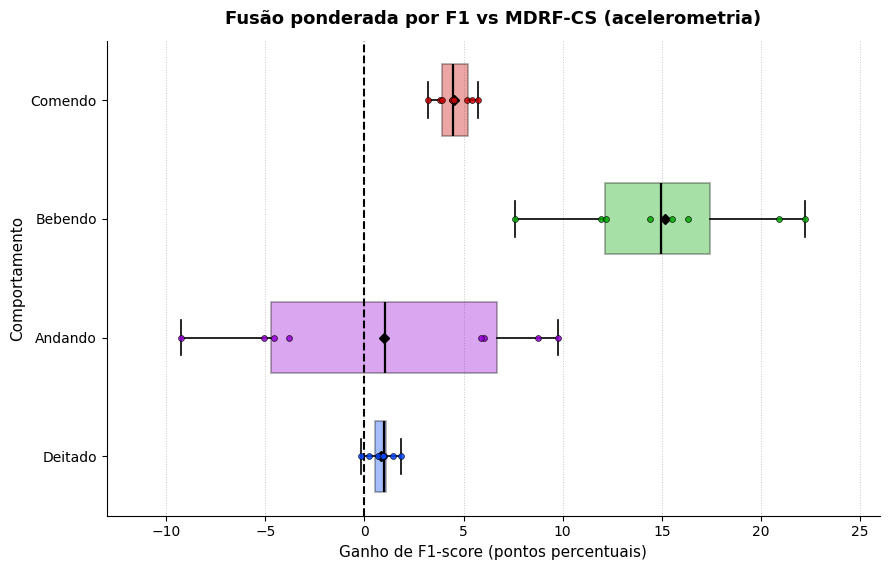

Figura salva: C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id\boxplot_f1w_vs_mdrf_pt.png (+ .pdf)


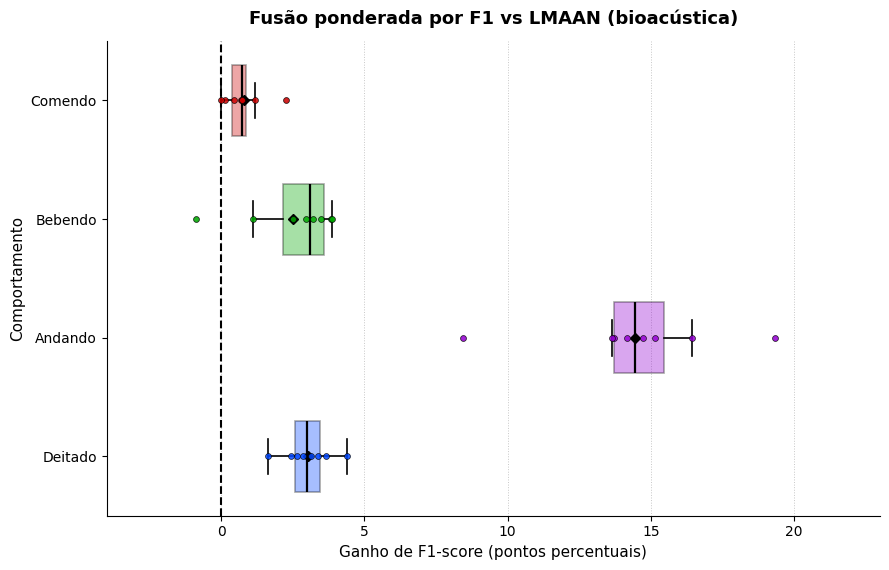

Figura salva: C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id\boxplot_f1w_vs_lmaan_pt.png (+ .pdf)


In [12]:
# ============================================================
# GANHO DA FUSÃO POR CLASSE — distribuição entre os 8 animais (LOAO)
# Mantém o estilo da Figura 14 (boxplot horizontal, mesmas cores e eixos);
# no lugar do bootstrap de janelas, cada ponto é o ganho de F1 de um animal.
# Gera: boxplot_f1w_vs_mdrf_pt  e  boxplot_f1w_vs_lmaan_pt  (.png e .pdf)
# ============================================================
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

# Configuração dos caminhos, classes e cores usadas na figura.
# A unidade estatística do gráfico é o animal, não a janela individual.
RAIZ = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos"
BASE = os.path.join(RAIZ, "experimento_split por id")

# "provisorio": reproduz a fusão da tabela atual (pesos de áudio pelo atalho)
# "aninhado"  : lê fusao_loao_aninhada_predicoes.csv (saída da célula totalmente aninhada)
MODO = "provisorio"
ARQ_LMAAN = "lmaan_loao_probs_completo_acc_det.csv"       # trocar pelo novo quando terminar

CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES_PT = ["Deitado", "Andando", "Bebendo", "Comendo"]
LABELS, PC, EPS = [0, 1, 2, 3], [f"prob_{c}" for c in CLASSES], 1e-8
COLORS = ['#0047FF', '#9400D3', '#00A800', '#CC0000']
n_classes = len(CLASSES)

# ---------------------------------------------------------
# 1. Dados pareados e predições
# ---------------------------------------------------------
a = pd.read_csv(os.path.join(BASE, "mdrfcs_loao_probs.csv"))
l = pd.read_csv(os.path.join(BASE, ARQ_LMAAN))
df = (a[["janela", "ID", "label"] + PC].rename(columns={c: f"s_{c}" for c in PC})
      .merge(l[["janela"] + PC].rename(columns={c: f"a_{c}" for c in PC}), on="janela")
      .sort_values("janela").reset_index(drop=True))
y, ids = df["label"].values, df["ID"].values
Ps = df[[f"s_{c}" for c in PC]].values
Pa = df[[f"a_{c}" for c in PC]].values
hs, ha = Ps.argmax(1), Pa.argmax(1)

# Dois modos são aceitos:
# - aninhado: usa diretamente as predições já produzidas pela fusão totalmente aninhada;
# - provisorio: reconstrói a fusão usando os pesos disponíveis na análise atual.
if MODO == "aninhado":
    fu = pd.read_csv(os.path.join(BASE, "fusao_loao_aninhada_predicoes.csv"))
    fu = df[["janela"]].merge(fu[["janela", "pred_fusao"]], on="janela", how="left")
    hf = fu["pred_fusao"].values.astype(int)
else:
    inner = pd.read_csv(os.path.join(BASE, "mdrfcs_inner_oof_probs.csv"))
    inner = inner[inner["janela"].isin(set(df["janela"]))]
    Pf = np.zeros_like(Ps)
    for i in sorted(set(ids)):
        b = inner[inner["ID_teste"] == i]
        f1s = f1_score(b["label"].values, b[PC].values.argmax(1), labels=LABELS,
                       average=None, zero_division=0)
        fora = ids != i
        f1a = f1_score(y[fora], Pa[fora].argmax(1), labels=LABELS, average=None, zero_division=0)
        Ws = f1s / (f1s + f1a + EPS)
        Pf[ids == i] = Ws * Ps[ids == i] + (1 - Ws) * Pa[ids == i]
    hf = Pf.argmax(1)

print(f"Modo: {MODO} | janelas pareadas = {len(df)} | animais = {sorted(set(ids))}")

# ---------------------------------------------------------
# 2. Ganho de F1 por classe e por animal (p.p.)
# ---------------------------------------------------------
# Converte as predições pooled em uma matriz 8 x 4:
# uma linha por animal e uma coluna por classe comportamental.
def f1_animal(h):
    out = {}
    for i in sorted(set(ids)):
        m = ids == i
        out[i] = f1_score(y[m], h[m], labels=LABELS, average=None, zero_division=0)
    return np.array([out[i] for i in sorted(out)])           # (8 animais, 4 classes)

F_s, F_a, F_f = f1_animal(hs), f1_animal(ha), f1_animal(hf)
# Ganho em pontos percentuais: F1 da fusão menos F1 do modelo unimodal,
# calculado independentemente para cada animal e classe.
ganho_mdrf  = (F_f - F_s) * 100
ganho_lmaan = (F_f - F_a) * 100

# Resume magnitude, direção e consistência do ganho entre os oito animais.
def resumo(g, nome):
    print(f"\n=== Fusão vs {nome}: ganho de F1 por animal (p.p.) ===")
    for j, c in enumerate(NOMES_PT):
        print(f"  {c:<8} média {g[:, j].mean():+6.2f} | mediana {np.median(g[:, j]):+6.2f} | "
              f"vence {(g[:, j] > 0).sum()}/8 | min {g[:, j].min():+6.2f} | max {g[:, j].max():+6.2f}")
resumo(ganho_mdrf, "MDRF-CS"); resumo(ganho_lmaan, "LMAAN")

# ---------------------------------------------------------
# 3. Gráfico (estilo da Figura 14)
# ---------------------------------------------------------
# Boxplot horizontal: cada caixa resume os oito ganhos por classe.
# Os pontos individuais permanecem visíveis para mostrar a variabilidade entre animais.
def plot_boxplot_ganho_f1_pt(gains, title, save_path, xlim):
    data_plot = [gains[:, i] for i in range(n_classes)]
    fig, ax = plt.subplots(figsize=(9, 5.8))

    bp = ax.boxplot(
        data_plot, vert=False, patch_artist=True, tick_labels=NOMES_PT,
        showmeans=True, meanline=False, widths=0.6,
        flierprops=dict(marker='o', markersize=3, alpha=0.35,
                        markerfacecolor='white', markeredgecolor='gray'),
        medianprops=dict(color='black', linewidth=1.6),
        meanprops=dict(marker='D', markerfacecolor='black', markeredgecolor='black', markersize=5),
        whiskerprops=dict(linewidth=1.2, color='black'),
        capprops=dict(linewidth=1.2, color='black'),
        boxprops=dict(linewidth=1.2, color='black'))

    for patch, color in zip(bp['boxes'], COLORS):
        patch.set_facecolor(color); patch.set_alpha(0.35)
        patch.set_edgecolor('black'); patch.set_linewidth(1.2)

    # um ponto por animal (n = 8), alinhado à linha central de cada box
    for i, d in enumerate(data_plot):
        ax.scatter(d, np.full(len(d), i + 1),
                   s=18, color=COLORS[i], edgecolor='black', linewidth=0.5,
                   zorder=3, alpha=0.85)

    ax.axvline(0, color='black', linestyle='--', linewidth=1.5)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel('Ganho de F1-score (pontos percentuais)', fontsize=11)
    ax.set_ylabel('Comportamento', fontsize=11)
    ax.tick_params(axis='both', labelsize=10)
    ax.set_xlim(xlim)
    ax.grid(axis='x', linestyle=':', linewidth=0.7, alpha=0.7)
    ax.grid(axis='y', visible=False)
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    fig.savefig(save_path, dpi=300, bbox_inches='tight')
    fig.savefig(save_path.replace(".png", ".pdf"), bbox_inches='tight')
    plt.show()
    print(f"Figura salva: {save_path} (+ .pdf)")

# Ajusta automaticamente os limites do eixo x, sempre incluindo zero
# para facilitar a interpretação visual entre ganho e perda de desempenho.
def lim(g, margem=3):
    return (np.floor(min(g.min(), 0)) - margem, np.ceil(g.max()) + margem)

plot_boxplot_ganho_f1_pt(ganho_mdrf,  'Fusão ponderada por F1 vs MDRF-CS (acelerometria)',
                         os.path.join(BASE, 'boxplot_f1w_vs_mdrf_pt.png'),  lim(ganho_mdrf))
plot_boxplot_ganho_f1_pt(ganho_lmaan, 'Fusão ponderada por F1 vs LMAAN (bioacústica)',
                         os.path.join(BASE, 'boxplot_f1w_vs_lmaan_pt.png'), lim(ganho_lmaan))

**Pooled and Per-Animal Fusion Gains by Class**

<small>Summarizes class-specific precision, recall, and F1, then compares shortcut-weight fusion with the unimodal models using pooled gains and per-animal differences.</small>

In [15]:
# =========================================================
# GANHO DA FUSÃO POR CLASSE — pooled + nível-animal
# =========================================================
import os, glob
import numpy as np, pandas as pd
from scipy.stats import wilcoxon
from sklearn.metrics import f1_score, precision_recall_fscore_support

# Define caminhos, ordem das classes e colunas de probabilidade utilizadas
# de forma idêntica nas três saídas: acelerômetro, áudio e fusão.
RAIZ = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos"
BASE = os.path.join(RAIZ, "experimento_split por id")
CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES   = ["Lying", "Walking", "Drinking", "Eating"]
LABELS, PC, EPS = [0, 1, 2, 3], [f"prob_{c}" for c in CLASSES], 1e-8

# Recupera os arquivos de predição mais recentes disponíveis na árvore de resultados.
ach = lambda p: sorted(glob.glob(os.path.join(RAIZ, "**", p), recursive=True),
                       key=os.path.getmtime, reverse=True)[0]
a, l = pd.read_csv(ach("mdrfcs_loao_probs.csv")), pd.read_csv(ach("lmaan_loao_probs*.csv"))
inner = pd.read_csv(ach("mdrfcs_inner_oof_probs.csv"))

# Pareia as duas modalidades pela identificação da janela.
# O rótulo e o ID são herdados do conjunto de acelerometria e usados em toda a análise.
df = (a[["janela", "ID", "label"] + PC].rename(columns={c: f"s_{c}" for c in PC})
      .merge(l[["janela"] + PC].rename(columns={c: f"a_{c}" for c in PC}), on="janela")
      .sort_values("janela").reset_index(drop=True))
y, ids = df["label"].values, df["ID"].values
Ps, Pa = df[[f"s_{c}" for c in PC]].values, df[[f"a_{c}" for c in PC]].values
inner = inner[inner["janela"].isin(set(df["janela"]))]

# Reconstrói as probabilidades da fusão para cada fold externo.
# Os pesos são específicos por classe e derivados do desempenho F1 disponível
# sem usar diretamente as janelas do animal externo na estimativa do acelerômetro.
Pf = np.zeros_like(Ps)
for i in sorted(set(ids)):
    b = inner[inner["ID_teste"] == i]
    f1s = f1_score(b["label"].values, b[PC].values.argmax(1), labels=LABELS,
                   average=None, zero_division=0)
    fora = ids != i
    f1a = f1_score(y[fora], Pa[fora].argmax(1), labels=LABELS, average=None, zero_division=0)
    Ws = f1s / (f1s + f1a + EPS)
    Pf[ids == i] = Ws * Ps[ids == i] + (1 - Ws) * Pa[ids == i]

hs, ha, hf = Ps.argmax(1), Pa.argmax(1), Pf.argmax(1)

# ---------- 1. Tabela pooled ----------
# Mede precisão, recall, F1 e suporte pooled em todas as 6.285 janelas pareadas.
def prf(yh):
    return precision_recall_fscore_support(y, yh, labels=LABELS, zero_division=0)

Ss, Sa, Sf = prf(hs), prf(ha), prf(hf)
tb = []
for j, nm in enumerate(NOMES):
    melhor = max(Ss[2][j], Sa[2][j])
    quem   = "acel." if Ss[2][j] >= Sa[2][j] else "áudio"
    tb.append({"classe": nm, "n": int(Sf[3][j]),
               "F1_acel": Ss[2][j], "F1_audio": Sa[2][j],
               "melhor_uni": melhor, "fonte": quem, "F1_fusao": Sf[2][j],
               "Δ_vs_melhor": (Sf[2][j] - melhor) * 100,
               "Δ_vs_acel": (Sf[2][j] - Ss[2][j]) * 100,
               "Δ_vs_audio": (Sf[2][j] - Sa[2][j]) * 100,
               "P_fusao": Sf[0][j], "R_fusao": Sf[1][j]})
tb = pd.DataFrame(tb)
print("=== F1 POR CLASSE — pooled (6.285 janelas, Δ em pontos percentuais) ===")
print(tb[["classe", "n", "F1_acel", "F1_audio", "melhor_uni", "fonte", "F1_fusao",
          "Δ_vs_melhor", "Δ_vs_acel", "Δ_vs_audio"]].round(4).to_string(index=False))
print("\nPrecisão e recall da fusão:")
print(tb[["classe", "P_fusao", "R_fusao", "F1_fusao"]].round(4).to_string(index=False))

# ---------- 2. Nível-animal ----------
# Recalcula o F1 por classe dentro de cada animal para avaliar robustez
# e permitir testes pareados com o animal como unidade experimental.
reg = []
for i in sorted(set(ids)):
    m = ids == i
    r = {"ID": i}
    for k, h in [("acel", hs), ("audio", ha), ("fus", hf)]:
        f1c = f1_score(y[m], h[m], labels=LABELS, average=None, zero_division=0)
        for j, c in enumerate(CLASSES):
            r[f"{k}_{c}"] = f1c[j]
    reg.append(r)
pa_ = pd.DataFrame(reg)

print("\n=== Nível-animal (n = 8) — média ± DP, vitórias e Wilcoxon unicaudal ===")
lin = []
for c, nm in zip(CLASSES, NOMES):
    d = {"classe": nm}
    for k in ["acel", "audio", "fus"]:
        d[k] = f"{pa_[f'{k}_{c}'].mean():.4f}±{pa_[f'{k}_{c}'].std():.4f}"
    for k, rot in [("acel", "acel"), ("audio", "áudio")]:
        dd = pa_[f"fus_{c}"] - pa_[f"{k}_{c}"]
        nz = int((dd != 0).sum())
        p = (wilcoxon(pa_[f"fus_{c}"], pa_[f"{k}_{c}"], alternative="greater",
                      zero_method="wilcox").pvalue if nz else np.nan)
        d[f"vence_{rot}"] = f"{int((dd > 0).sum())}/8"
        d[f"p_{rot}"] = p
    lin.append(d)
print(pd.DataFrame(lin).round(4).to_string(index=False))

# ---------- 3. Mecanismo do ganho ----------
print("\n=== De onde vem o ganho: janelas recuperadas e perdidas, por classe ===")
# Decompõe o ganho da fusão em janelas recuperadas e perdidas.
# Essa análise mostra se a melhoria decorre de corrigir erros de uma modalidade
# ou se a combinação também introduz novos erros.
mec = []
for j, nm in enumerate(NOMES):
    m = y == j
    okf, oks, oka = hf[m] == j, hs[m] == j, ha[m] == j
    mec.append({"classe": nm, "n": int(m.sum()),
                "recupera_de_acel": int((okf & ~oks).sum()),
                "perde_p_acel":     int((~okf & oks).sum()),
                "recupera_de_audio": int((okf & ~oka).sum()),
                "perde_p_audio":     int((~okf & oka).sum()),
                "so_audio_salvava": int((~oks & oka & okf).sum()),
                "so_acel_salvava":  int((oks & ~oka & okf).sum()),
                "ambos_erravam_e_fusao_acerta": int((~oks & ~oka & okf).sum()),
                "ambos_acertavam_e_fusao_erra": int((oks & oka & ~okf).sum())})
print(pd.DataFrame(mec).to_string(index=False))

# ---------- 4. Falsos positivos ----------
print("\n=== Precisão: para onde vão os falsos positivos da fusão ===")
# Analisa a origem dos falsos positivos de cada classe predita pela fusão,
# identificando quais classes verdadeiras são confundidas com maior frequência.
for j, nm in enumerate(NOMES):
    m = hf == j
    fp = y[m][y[m] != j]
    if len(fp):
        v = pd.Series(fp).map(dict(enumerate(NOMES))).value_counts()
        print(f"  predito {nm:<9} FP = {len(fp):>4}  ({'; '.join(f'{k} {x}' for k, x in v.items())})")

# Exporta as tabelas para reutilização direta no artigo e em análises posteriores.
tb.to_csv(os.path.join(BASE, "fusao_ganho_por_classe.csv"), index=False)
pd.DataFrame(mec).to_csv(os.path.join(BASE, "fusao_mecanismo_por_classe.csv"), index=False)
print(f"\nSalvos em {BASE}")

=== F1 POR CLASSE — pooled (6.285 janelas, Δ em pontos percentuais) ===
  classe    n  F1_acel  F1_audio  melhor_uni fonte  F1_fusao  Δ_vs_melhor  Δ_vs_acel  Δ_vs_audio
   Lying 3176   0.9662    0.9441      0.9662 acel.    0.9744       0.8157     0.8157      3.0217
 Walking  605   0.8102    0.6781      0.8102 acel.    0.8217       1.1512     1.1512     14.3596
Drinking  366   0.7192    0.8448      0.8448 áudio    0.8704       2.5595    15.1236      2.5595
  Eating 2138   0.9400    0.9778      0.9778 áudio    0.9848       0.7018     4.4849      0.7018

Precisão e recall da fusão:
  classe  P_fusao  R_fusao  F1_fusao
   Lying   0.9620   0.9871    0.9744
 Walking   0.8720   0.7769    0.8217
Drinking   0.8983   0.8443    0.8704
  Eating   0.9837   0.9860    0.9848

=== Nível-animal (n = 8) — média ± DP, vitórias e Wilcoxon unicaudal ===
  classe          acel         audio           fus vence_acel  p_acel vence_áudio  p_áudio
   Lying 0.9654±0.0080 0.9438±0.0117 0.9740±0.0083        7/8  0

**Additional Summary of Class-Specific Fusion Gains**

<small>Runs an additional class-level summary of shortcut-weight fusion, including pooled performance and animal-level comparisons with accelerometer-only and audio-only predictions.</small>

In [19]:
# =========================================================
# GANHO DA FUSÃO POR CLASSE — pooled + nível-animal
# =========================================================
import os, glob
import numpy as np, pandas as pd
from scipy.stats import wilcoxon
from sklearn.metrics import f1_score, precision_recall_fscore_support

# Define caminhos, ordem das classes e colunas de probabilidade utilizadas
# de forma idêntica nas três saídas: acelerômetro, áudio e fusão.
RAIZ = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos"
BASE = os.path.join(RAIZ, "experimento_split por id")
CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES   = ["Lying", "Walking", "Drinking", "Eating"]
LABELS, PC, EPS = [0, 1, 2, 3], [f"prob_{c}" for c in CLASSES], 1e-8

# Recupera os arquivos de predição mais recentes disponíveis na árvore de resultados.
ach = lambda p: sorted(glob.glob(os.path.join(RAIZ, "**", p), recursive=True),
                       key=os.path.getmtime, reverse=True)[0]
a, l = pd.read_csv(ach("mdrfcs_loao_probs.csv")), pd.read_csv(ach("lmaan_loao_probs*.csv"))
inner = pd.read_csv(ach("mdrfcs_inner_oof_probs.csv"))

# Pareia as duas modalidades pela identificação da janela.
# O rótulo e o ID são herdados do conjunto de acelerometria e usados em toda a análise.
df = (a[["janela", "ID", "label"] + PC].rename(columns={c: f"s_{c}" for c in PC})
      .merge(l[["janela"] + PC].rename(columns={c: f"a_{c}" for c in PC}), on="janela")
      .sort_values("janela").reset_index(drop=True))
y, ids = df["label"].values, df["ID"].values
Ps, Pa = df[[f"s_{c}" for c in PC]].values, df[[f"a_{c}" for c in PC]].values
inner = inner[inner["janela"].isin(set(df["janela"]))]

# Reconstrói as probabilidades da fusão para cada fold externo.
# Os pesos são específicos por classe e derivados do desempenho F1 disponível
# sem usar diretamente as janelas do animal externo na estimativa do acelerômetro.
Pf = np.zeros_like(Ps)
for i in sorted(set(ids)):
    b = inner[inner["ID_teste"] == i]
    f1s = f1_score(b["label"].values, b[PC].values.argmax(1), labels=LABELS,
                   average=None, zero_division=0)
    fora = ids != i
    f1a = f1_score(y[fora], Pa[fora].argmax(1), labels=LABELS, average=None, zero_division=0)
    Ws = f1s / (f1s + f1a + EPS)
    Pf[ids == i] = Ws * Ps[ids == i] + (1 - Ws) * Pa[ids == i]

hs, ha, hf = Ps.argmax(1), Pa.argmax(1), Pf.argmax(1)

# ---------- 1. Tabela pooled ----------
# Mede precisão, recall, F1 e suporte pooled em todas as 6.285 janelas pareadas.
def prf(yh):
    return precision_recall_fscore_support(y, yh, labels=LABELS, zero_division=0)

Ss, Sa, Sf = prf(hs), prf(ha), prf(hf)
tb = []
for j, nm in enumerate(NOMES):
    melhor = max(Ss[2][j], Sa[2][j])
    quem   = "acel." if Ss[2][j] >= Sa[2][j] else "áudio"
    tb.append({"classe": nm, "n": int(Sf[3][j]),
               "F1_acel": Ss[2][j], "F1_audio": Sa[2][j],
               "melhor_uni": melhor, "fonte": quem, "F1_fusao": Sf[2][j],
               "Δ_vs_melhor": (Sf[2][j] - melhor) * 100,
               "Δ_vs_acel": (Sf[2][j] - Ss[2][j]) * 100,
               "Δ_vs_audio": (Sf[2][j] - Sa[2][j]) * 100,
               "P_fusao": Sf[0][j], "R_fusao": Sf[1][j]})
tb = pd.DataFrame(tb)
print("=== F1 POR CLASSE — pooled (6.285 janelas, Δ em pontos percentuais) ===")
print(tb[["classe", "n", "F1_acel", "F1_audio", "melhor_uni", "fonte", "F1_fusao",
          "Δ_vs_melhor", "Δ_vs_acel", "Δ_vs_audio"]].round(4).to_string(index=False))
print("\nPrecisão e recall da fusão:")
print(tb[["classe", "P_fusao", "R_fusao", "F1_fusao"]].round(4).to_string(index=False))

# ---------- 2. Nível-animal ----------
# Recalcula o F1 por classe dentro de cada animal para avaliar robustez
# e permitir testes pareados com o animal como unidade experimental.
reg = []
for i in sorted(set(ids)):
    m = ids == i
    r = {"ID": i}
    for k, h in [("acel", hs), ("audio", ha), ("fus", hf)]:
        f1c = f1_score(y[m], h[m], labels=LABELS, average=None, zero_division=0)
        for j, c in enumerate(CLASSES):
            r[f"{k}_{c}"] = f1c[j]
    reg.append(r)
pa_ = pd.DataFrame(reg)

print("\n=== Nível-animal (n = 8) — média ± DP, vitórias e Wilcoxon unicaudal ===")
lin = []
for c, nm in zip(CLASSES, NOMES):
    d = {"classe": nm}
    for k in ["acel", "audio", "fus"]:
        d[k] = f"{pa_[f'{k}_{c}'].mean():.4f}±{pa_[f'{k}_{c}'].std():.4f}"
    for k, rot in [("acel", "acel"), ("audio", "áudio")]:
        dd = pa_[f"fus_{c}"] - pa_[f"{k}_{c}"]
        nz = int((dd != 0).sum())
        p = (wilcoxon(pa_[f"fus_{c}"], pa_[f"{k}_{c}"], alternative="greater",
                      zero_method="wilcox").pvalue if nz else np.nan)
        d[f"vence_{rot}"] = f"{int((dd > 0).sum())}/8"
        d[f"p_{rot}"] = p
    lin.append(d)
print(pd.DataFrame(lin).round(4).to_string(index=False))

# ---------- 3. Mecanismo do ganho ----------
print("\n=== De onde vem o ganho: janelas recuperadas e perdidas, por classe ===")
# Decompõe o ganho da fusão em janelas recuperadas e perdidas.
# Essa análise mostra se a melhoria decorre de corrigir erros de uma modalidade
# ou se a combinação também introduz novos erros.
mec = []
for j, nm in enumerate(NOMES):
    m = y == j
    okf, oks, oka = hf[m] == j, hs[m] == j, ha[m] == j
    mec.append({"classe": nm, "n": int(m.sum()),
                "recupera_de_acel": int((okf & ~oks).sum()),
                "perde_p_acel":     int((~okf & oks).sum()),
                "recupera_de_audio": int((okf & ~oka).sum()),
                "perde_p_audio":     int((~okf & oka).sum()),
                "so_audio_salvava": int((~oks & oka & okf).sum()),
                "so_acel_salvava":  int((oks & ~oka & okf).sum()),
                "ambos_erravam_e_fusao_acerta": int((~oks & ~oka & okf).sum()),
                "ambos_acertavam_e_fusao_erra": int((oks & oka & ~okf).sum())})
print(pd.DataFrame(mec).to_string(index=False))

# ---------- 4. Falsos positivos ----------
print("\n=== Precisão: para onde vão os falsos positivos da fusão ===")
# Analisa a origem dos falsos positivos de cada classe predita pela fusão,
# identificando quais classes verdadeiras são confundidas com maior frequência.
for j, nm in enumerate(NOMES):
    m = hf == j
    fp = y[m][y[m] != j]
    if len(fp):
        v = pd.Series(fp).map(dict(enumerate(NOMES))).value_counts()
        print(f"  predito {nm:<9} FP = {len(fp):>4}  ({'; '.join(f'{k} {x}' for k, x in v.items())})")

# Exporta as tabelas para reutilização direta no artigo e em análises posteriores.
tb.to_csv(os.path.join(BASE, "fusao_ganho_por_classe.csv"), index=False)
pd.DataFrame(mec).to_csv(os.path.join(BASE, "fusao_mecanismo_por_classe.csv"), index=False)
print(f"\nSalvos em {BASE}")

=== F1 POR CLASSE — pooled (6.285 janelas, Δ em pontos percentuais) ===
  classe    n  F1_acel  F1_audio  melhor_uni fonte  F1_fusao  Δ_vs_melhor  Δ_vs_acel  Δ_vs_audio
   Lying 3176   0.9662    0.9441      0.9662 acel.    0.9744       0.8157     0.8157      3.0217
 Walking  605   0.8102    0.6781      0.8102 acel.    0.8217       1.1512     1.1512     14.3596
Drinking  366   0.7192    0.8448      0.8448 áudio    0.8704       2.5595    15.1236      2.5595
  Eating 2138   0.9400    0.9778      0.9778 áudio    0.9848       0.7018     4.4849      0.7018

Precisão e recall da fusão:
  classe  P_fusao  R_fusao  F1_fusao
   Lying   0.9620   0.9871    0.9744
 Walking   0.8720   0.7769    0.8217
Drinking   0.8983   0.8443    0.8704
  Eating   0.9837   0.9860    0.9848

=== Nível-animal (n = 8) — média ± DP, vitórias e Wilcoxon unicaudal ===
  classe          acel         audio           fus vence_acel  p_acel vence_áudio  p_áudio
   Lying 0.9654±0.0080 0.9438±0.0117 0.9740±0.0083        7/8  0

**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

**Comparison of Late Fusion Strategies**

<small>Evaluates multiple combinations of paired modality predictions, including simple averaging, F1-based and confidence-based weighting, stacking, and neural meta-classifiers. Reports pooled and per-animal results under the implemented LOAO workflow.</small>

In [16]:
# =========================================================
# REPRODUÇÃO DO ARTIGO SOB LOAO — todas as estratégias de fusão
# =========================================================
import os, glob, time
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

# Configuração geral da reprodução: todas as estratégias são avaliadas
# sobre exatamente o mesmo conjunto de janelas pareadas e os mesmos folds LOAO.
BASE = r"C:\Users\pedro\OneDrive\Área de Trabalho\experimentos\experimento_split por id"
CLASSES = ["deitado", "andando", "bebendo", "comendo"]
NOMES   = ["Lying", "Walking", "Drinking", "Eating"]
LABELS  = [0, 1, 2, 3]
PC      = [f"prob_{c}" for c in CLASSES]
EPS     = 1e-8
NC      = 4

# ---------------------------------------------------------
# 1. Dados
# ---------------------------------------------------------
# Carrega probabilidades unimodais e as predições internas do MDRF-CS.
# O pareamento por 'janela' garante comparação amostra a amostra entre métodos.
a = pd.read_csv(os.path.join(BASE, "mdrfcs_loao_probs.csv"))
l = pd.read_csv(sorted(glob.glob(os.path.join(BASE, "lmaan_loao_probs*.csv")),
                       key=os.path.getmtime)[-1])
inner = pd.read_csv(os.path.join(BASE, "mdrfcs_inner_oof_probs.csv"))

df = (a[["janela", "ID", "label"] + PC].rename(columns={c: f"s_{c}" for c in PC})
      .merge(l[["janela"] + PC].rename(columns={c: f"a_{c}" for c in PC}), on="janela")
      .sort_values("janela").reset_index(drop=True))
y, ids = df["label"].values, df["ID"].values
Ps = df[[f"s_{c}" for c in PC]].values
Pa = df[[f"a_{c}" for c in PC]].values
inner = inner[inner["janela"].isin(set(df["janela"]))]
print(f"Pareadas: {len(df)} | animais: {sorted(set(ids))}")

# ---------------------------------------------------------
# 2. Margens de confiança (Kuncheva)
# ---------------------------------------------------------
# A confiança de Kuncheva é expressa como distância entre a maior probabilidade
# prevista e a confiança de acaso para quatro classes (1/4).
base_conf = 1.0 / NC
d_s = np.clip(Ps.max(1) - base_conf, 0, None)
d_a = np.clip(Pa.max(1) - base_conf, 0, None)

# ---------------------------------------------------------
# 3. Meta-features e modelos
# ---------------------------------------------------------
# Meta-features usadas pelos classificadores de segunda etapa.
# Garcia-Ceja combina decisões de classe e probabilidades médias; Buddi usa
# log-probabilidades das duas modalidades.
def meta_garcia(Pse, Pau):
    return np.hstack([Pse.argmax(1).reshape(-1, 1), Pau.argmax(1).reshape(-1, 1),
                      (Pse + Pau) / 2.0])

def meta_logprob(Pse, Pau):
    return np.hstack([np.log(np.clip(Pse, EPS, 1.0)), np.log(np.clip(Pau, EPS, 1.0))])

def mlp(seed=42):
    return Pipeline([("scaler", StandardScaler()),
                     ("mlp", MLPClassifier(hidden_layer_sizes=(16,), activation="relu",
                                           solver="adam", alpha=1e-3, learning_rate_init=1e-3,
                                           max_iter=1000, early_stopping=True,
                                           validation_fraction=0.15, n_iter_no_change=30,
                                           random_state=seed))])

def prob4(modelo, X):
    """predict_proba realocado para as 4 colunas na ordem canônica."""
    p = np.zeros((len(X), NC))
    p[:, modelo.classes_] = modelo.predict_proba(X)
    return p

# ---------------------------------------------------------
# 4. Laço por animal
# ---------------------------------------------------------
# Reserva uma matriz de probabilidades para cada estratégia de fusão.
# Cada posição será preenchida apenas pelo fold em que o respectivo animal é teste.
P = {k: np.zeros_like(Ps) for k in
     ["f1w", "dcs", "cwf_eq", "cwf_oof", "cwf_f1p", "garcia", "buddi"]}
pesos = []
t0 = time.time()

# LOAO externo: em cada iteração, um animal é mantido exclusivamente para teste
# e os sete restantes formam o conjunto de desenvolvimento dos meta-classificadores.
for i in sorted(set(ids)):
    te, tr = ids == i, ids != i

    # --- F1 por classe: acelerômetro aninhado, áudio pelo atalho
    b   = inner[inner["ID_teste"] == i]
    f1s = f1_score(b["label"].values, b[PC].values.argmax(1),
                   labels=LABELS, average=None, zero_division=0)
    f1a = f1_score(y[tr], Pa[tr].argmax(1), labels=LABELS, average=None, zero_division=0)
    Ws, Wa = f1s / (f1s + f1a + EPS), f1a / (f1s + f1a + EPS)
    pesos.append({"ID": i, **{f"W_sen_{c}": Ws[k] for k, c in enumerate(CLASSES)}})

    ps, pa, ds, da = Ps[te], Pa[te], d_s[te], d_a[te]

    # --- estáticos
    P["f1w"][te] = Ws * ps + Wa * pa

    # --- Kuncheva
    P["dcs"][te] = np.where((ds >= da)[:, None], ps, pa)

    den = ds + da + EPS
    P["cwf_eq"][te] = (ds / den)[:, None] * ps + (da / den)[:, None] * pa

    Wt_s, Wt_a = np.outer(ds, Ws), np.outer(da, Wa)
    den2 = Wt_s + Wt_a + EPS
    P["cwf_oof"][te] = (Wt_s / den2) * ps + (Wt_a / den2) * pa

    sc_s, sc_a = f1s[ps.argmax(1)] * ds, f1a[pa.argmax(1)] * da
    den3 = sc_s + sc_a + EPS
    P["cwf_f1p"][te] = (sc_s / den3)[:, None] * ps + (sc_a / den3)[:, None] * pa

    # --- meta-classificadores, treinados só nos 7 de desenvolvimento
    rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")
    rf.fit(meta_garcia(Ps[tr], Pa[tr]), y[tr])
    P["garcia"][te] = prob4(rf, meta_garcia(ps, pa))

    Xtr, Xte = meta_logprob(Ps[tr], Pa[tr]), meta_logprob(ps, pa)

    m1 = mlp(); m1.fit(Xtr, y[tr])
    P["buddi"][te] = prob4(m1, Xte)

    print(f"  animal {i} ok  ({time.time()-t0:.0f}s)")

# A média simples não requer treinamento e funciona como baseline de fusão tardia.
P["media"] = (Ps + Pa) / 2.0

# ---------------------------------------------------------
# 5. Tabela comparativa
# ---------------------------------------------------------
# Consolida modelos unimodais e todas as variantes de fusão numa única tabela
# usando Accuracy, Macro-F1, Weighted-F1 e F1 específico por classe.
METODOS = [
    ("MDRF-CS (acelerômetro)", Ps), ("LMAAN (áudio)", Pa),
    ("Média simples", P["media"]), ("F1-weighted", P["f1w"]),
    ("DCS-MAX", P["dcs"]), ("CWF-Equal", P["cwf_eq"]),
    ("CWF-OOF", P["cwf_oof"]), ("CWF-F1Pred", P["cwf_f1p"]),
    ("Garcia-Ceja stacking", P["garcia"]),
    ("Buddi log-prob", P["buddi"]),
]

comp = []
for nome, M in METODOS:
    yh = M.argmax(1)
    f1c = f1_score(y, yh, labels=LABELS, average=None, zero_division=0)
    comp.append({"modelo": nome, "accuracy": accuracy_score(y, yh),
                 "macro_f1": f1_score(y, yh, labels=LABELS, average="macro", zero_division=0),
                 "weighted_f1": f1_score(y, yh, labels=LABELS, average="weighted", zero_division=0),
                 **{c: f1c[k] for k, c in enumerate(CLASSES)}})
tab = pd.DataFrame(comp).sort_values("macro_f1", ascending=False)

print("\n" + "=" * 78)
print("TABELA COMPARATIVA SOB LOAO (pooled, todas as janelas pareadas)")
print("=" * 78)
print(tab.round(4).to_string(index=False))

print("\n=== Pesos do acelerômetro por classe ===")
print(pd.DataFrame(pesos).round(4).to_string(index=False))

print("\n=== Relatório da F1-weighted ===")
print(classification_report(y, P["f1w"].argmax(1), labels=LABELS,
                            target_names=NOMES, digits=4, zero_division=0))
print("Matriz de confusão:")
print(pd.DataFrame(confusion_matrix(y, P["f1w"].argmax(1), labels=LABELS),
                   index=NOMES, columns=NOMES).to_string())

# ---------------------------------------------------------
# 6. Por animal e testes de Wilcoxon
# ---------------------------------------------------------
# Recalcula Macro-F1 separadamente por animal para os testes estatísticos pareados.
# Assim, o tamanho amostral inferencial permanece n = 8, e não o número de janelas.
w = pd.DataFrame([{"ID": i, **{nome: f1_score(y[ids == i], M[ids == i].argmax(1),
                                              labels=LABELS, average="macro", zero_division=0)
                               for nome, M in METODOS}}
                  for i in sorted(set(ids))])
print("\n=== Macro-F1 por animal ===")
print(w.round(4).to_string(index=False))

print("\n=== Média ± DP entre animais ===")
for nome, _ in METODOS:
    print(f"  {nome:<28} {w[nome].mean():.4f} ± {w[nome].std():.4f}")

REF = "F1-weighted"
print(f"\n=== Wilcoxon: {REF} vs cada método (n = 8 animais) ===")
linhas = []
for nome, _ in METODOS:
    if nome == REF:
        continue
    d = w[REF] - w[nome]
    unimodal = nome.startswith(("MDRF", "LMAAN"))
    alt = "greater" if unimodal else "two-sided"
    try:
        _, p = wilcoxon(w[REF], w[nome], alternative=alt)
    except ValueError:
        p = float("nan")
    linhas.append({"comparação": nome, "ganho_pp": d.mean() * 100,
                   "vence": f"{(d > 0).sum()}/8", "teste": alt, "p": p})
    print(f"  vs {nome:<28} {d.mean()*100:+6.2f} p.p. | {(d>0).sum()}/8 | "
          f"{alt:<9} | p = {p:.4f}")

# ---------------------------------------------------------
# 7. Saída
# ---------------------------------------------------------
tab.to_csv(os.path.join(BASE, "loao_fusao_tabela_comparativa.csv"), index=False)
w.to_csv(os.path.join(BASE, "loao_fusao_por_animal.csv"), index=False)
pd.DataFrame(linhas).to_csv(os.path.join(BASE, "loao_fusao_wilcoxon.csv"), index=False)

pred = df[["janela", "ID", "label"]].copy()
pred["atividade"] = pred["label"].map(dict(enumerate(CLASSES)))
for nome, M in METODOS:
    pred["pred_" + nome.split()[0].lower().replace("-", "")] = M.argmax(1)
pred.to_csv(os.path.join(BASE, "loao_fusao_predicoes_todas.csv"), index=False)

print(f"\nSalvos em {BASE}:")
print("  loao_fusao_tabela_comparativa.csv | _por_animal.csv | _wilcoxon.csv | _predicoes_todas.csv")

Pareadas: 6285 | animais: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
  animal 1 ok  (1s)
  animal 2 ok  (2s)
  animal 3 ok  (3s)
  animal 4 ok  (4s)
  animal 5 ok  (4s)
  animal 6 ok  (5s)
  animal 7 ok  (6s)
  animal 8 ok  (7s)

TABELA COMPARATIVA SOB LOAO (pooled, todas as janelas pareadas)
                modelo  accuracy  macro_f1  weighted_f1  deitado  andando  bebendo  comendo
  Garcia-Ceja stacking    0.9680    0.9302       0.9680   0.9852   0.8814   0.8705   0.9836
        Buddi log-prob    0.9661    0.9258       0.9660   0.9854   0.8662   0.8698   0.9820
           F1-weighted    0.9582    0.9128       0.9572   0.9744   0.8217   0.8704   0.9848
               CWF-OOF    0.9539    0.9050       0.9525   0.9704   0.7947   0.8704   0.9846
         Média simples    0.9529    0.9028       0.9513   0.9691   0.7835   0.8729   0.9858
             CWF-Equal    0.9507    0.8985       0.9489   0.9675   0.7726   0.8692   0.9848


**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>

**Reserved Code Cell**

<small>This cell is currently empty and is retained in its original position for future analysis.</small>